# Advanced Predictive Modelling for Customer Churn
## A Comparative Analysis of Machine Learning and Deep Learning Techniques

**Duc Le — MSc Dissertation — Version 2**

---

This notebook implements the methodology of `01_Duc_Le_Research_proposal.md` on
`customer_churn_1M.csv` (1,000,000 customers, one row per customer).

### How this version is organised

The study is built as a **single forward pipeline**: every stage consumes the
output of the previous stage and every modelling decision is justified by a
result printed earlier in the notebook. Nothing is assumed; everything is
measured.

| Part | Stage | Purpose |
|---|---|---|
| 0 | Environment | Reproducibility, hardware record, data loading |
| 1 | **Exploratory data analysis** | Establish the empirical basis for every later decision |
| 2 | **Feature engineering + validation** | Derive §7.3 features, then *prove* they add signal and *prune* those that are collinear |
| 3 | **Stratified split + leakage-safe design** | 80/20 stratified hold-out; all fitted transforms and all resampling confined inside CV folds |
| 4 | Evaluation harness | Metrics of §7.7, runtime protocol of §7.7 Table 8 |
| 5 | **Experiment A** — baseline models, *baseline features* | ML and DL at literature-default settings |
| 6 | **Experiment B** — baseline models, *engineered features* | Isolates the causal effect of feature engineering |
| 7 | **Experiment C** — tuned ML models, *engineered features* | Grid Search vs Random Search vs Optuna (§7.6) |
| 8 | **Champion selection** | All three experiments compared on one leaderboard |
| 9 | Statistical significance | Repeated stratified CV, paired tests, bootstrap CIs (§7.7 Table 9) |
| 10 | **Interpretability** | SHAP on the champion model (§7.8) |
| 11 | Held-out test evaluation | Final unbiased numbers on 200,000 unseen customers |
| 12 | **Monte Carlo trade-off simulation** | Champion vs deep learning: accuracy against latency and cost |
| 13 | **Why the champion wins** | Six falsifiable tests of the mechanism behind the result |
| 14 | Research question answers | Each RQ answered with its evidence and its limits |
| 15 | Limitations and artefacts | What the study does *not* support, and every table written to disk |

### Two framing notes carried forward from the proposal

**Domain framing.** The proposal is motivated by **banking** churn.
`customer_churn_1M.csv` uses a subscription-services schema (contract type,
monthly charges, service attachments). Following the cross-industry argument
already made in the literature review (§2, citing Boozary 2025; Ahmed *et al.*
2023 on the transferability of churn methodology across banking,
telecommunications and e-commerce), this study is positioned as a **cross-domain
churn methodology evaluation with banking as the motivating context**. The five
feature groups of §7.3 are implemented as domain analogues, and the mapping is
stated explicitly in Part 2.

**Compute protocol.** §7.6 requires all three search strategies to be compared.
Exhaustive grid search over 1,000,000 rows is not feasible on the study hardware
(a single Random Forest fit at 800k rows takes ≈73 s; the specified grid would
need ≈66 hours). Model *development* — Experiments A, B and C — therefore runs
on a **stratified development subsample drawn from the training partition**,
with repeated stratified k-fold cross-validation. The selected champion and its
deep-learning competitors are then **refit on the full training partition** and
scored once on the **full held-out test partition**. Both sets of numbers are
reported so the trade-off is auditable. This is a deliberate compute trade-off
of the same kind §7.2 already makes in preferring median/mode imputation over
MICE or kNN.

---
# Part 0 — Environment, reproducibility and data loading

### Step 0.1 — Pin every source of randomness and cap thread counts

Reproducibility requires fixing the seeds of Python, NumPy and (later)
TensorFlow. Thread counts are capped because the §7.7 runtime benchmark is only
meaningful if every model is timed under identical CPU conditions — an
unconstrained library that grabs all eight cores would appear artificially fast
next to one that does not.

In [1]:
# ---- Reproducibility, thread control and plotting defaults ------------------
import os
import sys
import json
import time
import random
import platform
import warnings

# Thread caps must be set before NumPy / scikit-learn / XGBoost import, because
# the underlying BLAS reads them once at load time.
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "4")
os.environ.setdefault("PYTHONHASHSEED", "42")
# TensorFlow logs graph-retracing notices on every fold when the session is
# cleared between folds; they are expected here and would bury the results.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "semibold",
    "legend.frameon": True,
})

# One colour-blind-safe palette, used consistently throughout the notebook.
C_STAY, C_CHURN = "#4C78A8", "#E45756"
C_ML, C_DL = "#4C78A8", "#F58518"
C_ACCENT = "#54A24B"

FIGDIR = "figures_v2"
os.makedirs(FIGDIR, exist_ok=True)


def savefig(name, fig=None, tight=True):
    """Save a figure into ./figures_v2 at print resolution for the dissertation."""
    fig = fig or plt.gcf()
    if tight:
        fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f"{name}.png"), bbox_inches="tight", facecolor="white")


print("Seeds pinned, thread caps applied, figure directory ready:", FIGDIR)

Seeds pinned, thread caps applied, figure directory ready: figures_v2


### Step 0.2 — Declare the study configuration in one place

Every magic number used anywhere in the notebook is declared here and nowhere
else, so the entire study can be re-scaled or re-seeded from a single cell.

`QUICK_RUN` is a rehearsal switch. With `QUICK_RUN = True` the whole notebook
executes end-to-end on a small stratified sample in roughly ten minutes, which
is how the pipeline was debugged before the full run. **All reported results in
this notebook were produced with `QUICK_RUN = False`.**

In [2]:
# ---- Study configuration -----------------------------------------------------
QUICK_RUN = False   # True -> rehearse the full pipeline on a small sample

CONFIG = dict(
    # -- Data -----------------------------------------------------------------
    DATA_PATH="customer_churn_1M.csv",
    TARGET="churn",
    ID_COLS=["customer_id"],

    # -- Partitioning (§7.4) --------------------------------------------------
    TEST_SIZE=0.20,          # stratified hold-out, never touched until Part 11
    DEV_SAMPLE_N=200_000,    # stratified development subsample for Experiments A/B
    TUNE_SAMPLE_N=100_000,   # stratified subsample for the §7.6 searches

    # -- Cross-validation -----------------------------------------------------
    N_SPLITS=5,
    N_REPEATS=3,             # §7.7 Table 9: repeated CV for significance testing

    # -- Runtime benchmarking protocol (§7.7 Table 8) -------------------------
    TIMING_WARMUP=2,
    TIMING_REPEATS=10,

    # -- Deep learning: literature-informed, deliberately NOT tuned (§7.6, §10a)
    DL_EPOCHS=40,
    DL_BATCH_SIZE=1024,
    DL_PATIENCE=6,

    # -- Imbalance treatments (§7.2) -----------------------------------------
    ENABLE_CTGAN=True,       # GAN-based oversampling arm; auto-disabled if unusable
    CTGAN_EPOCHS=60,
    CTGAN_FIT_N=12_000,

    # -- Hyperparameter search budgets (§7.6) --------------------------------
    RANDOM_SEARCH_ITER=30,
    OPTUNA_TRIALS=30,

    # -- Monte Carlo trade-off simulation (Part 12) --------------------------
    MC_DRAWS=20_000,

    RANDOM_STATE=RANDOM_STATE,
)

if QUICK_RUN:
    CONFIG.update(
        DEV_SAMPLE_N=20_000, TUNE_SAMPLE_N=12_000, N_REPEATS=1,
        TIMING_REPEATS=3, DL_EPOCHS=6, RANDOM_SEARCH_ITER=6, OPTUNA_TRIALS=6,
        CTGAN_EPOCHS=5, CTGAN_FIT_N=2_000, MC_DRAWS=4_000,
    )

globals().update(CONFIG)
print(f"QUICK_RUN = {QUICK_RUN}")
print(json.dumps({k: str(v) for k, v in CONFIG.items()}, indent=2))

QUICK_RUN = False
{
  "DATA_PATH": "customer_churn_1M.csv",
  "TARGET": "churn",
  "ID_COLS": "['customer_id']",
  "TEST_SIZE": "0.2",
  "DEV_SAMPLE_N": "200000",
  "TUNE_SAMPLE_N": "100000",
  "N_SPLITS": "5",
  "N_REPEATS": "3",
  "TIMING_WARMUP": "2",
  "TIMING_REPEATS": "10",
  "DL_EPOCHS": "40",
  "DL_BATCH_SIZE": "1024",
  "DL_PATIENCE": "6",
  "ENABLE_CTGAN": "True",
  "CTGAN_EPOCHS": "60",
  "CTGAN_FIT_N": "12000",
  "RANDOM_SEARCH_ITER": "30",
  "OPTUNA_TRIALS": "30",
  "MC_DRAWS": "20000",
  "RANDOM_STATE": "42"
}


### Step 0.3 — Record the hardware

§7.7 Table 8 requires the hardware specification to be reported alongside any
execution-time result, because latency numbers are meaningless without it.

In [3]:
# ---- Hardware specification (§7.7 Table 8, "Hardware specification") --------
def hardware_spec():
    """Collect the machine details that make the runtime benchmark reproducible."""
    import multiprocessing

    spec = {
        "platform": platform.platform(),
        "machine": platform.machine(),
        "processor": platform.processor() or platform.machine(),
        "logical_cores": multiprocessing.cpu_count(),
        "thread_cap_applied": os.environ.get("OMP_NUM_THREADS"),
        "python": sys.version.split()[0],
    }
    try:
        import psutil
        spec["ram_gb"] = round(psutil.virtual_memory().total / 1024 ** 3, 1)
    except Exception:
        try:
            spec["ram_gb"] = round(int(os.popen("sysctl -n hw.memsize").read()) / 1024 ** 3, 1)
        except Exception:
            spec["ram_gb"] = "n/a"
    return spec


HARDWARE = hardware_spec()
pd.Series(HARDWARE).to_frame("value")

,value
platform,macOS-26.6.2-arm64-arm-64bit
machine,arm64
processor,arm
logical_cores,8
thread_cap_applied,4
python,3.12.7
ram_gb,16.0000


In [4]:
# ---- Library versions, for the reproducibility appendix ---------------------
import importlib

_LIBS = ["numpy", "pandas", "sklearn", "scipy", "matplotlib", "seaborn",
         "xgboost", "imblearn", "optuna", "shap", "tensorflow", "ctgan",
         "statsmodels"]

VERSIONS = pd.DataFrame(
    [(m, getattr(importlib.import_module(m), "__version__", "?"))
     if importlib.util.find_spec(m) else (m, "NOT INSTALLED")
     for m in _LIBS],
    columns=["library", "version"],
)
VERSIONS

,library,version
0,numpy,1.26.4
1,pandas,2.2.2
2,sklearn,1.8.0
3,scipy,1.13.1
4,matplotlib,3.9.2
5,seaborn,0.13.2
6,xgboost,3.2.0
7,imblearn,0.14.1
8,optuna,4.8.0
9,shap,0.46.0


### Step 0.4 — Load the data and reduce its memory footprint

At default dtypes the raw frame occupies roughly 670 MB. Repeated cross-validation
and SMOTE resampling both duplicate large arrays, so downcasting here is what
keeps the study inside the 16 GB budget of the hardware recorded above.

In [5]:
# ---- Load the raw dataset ----------------------------------------------------
_t0 = time.perf_counter()
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded in {time.perf_counter() - _t0:.1f}s")
print(f"Shape:  {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Memory: {df_raw.memory_usage(deep=True).sum() / 1024 ** 2:,.1f} MB")
df_raw.head()

Loaded in 1.7s
Shape:  1,000,000 rows x 32 columns


Memory: 636.6 MB


,customer_id,signup_date,age,gender,annual_income,education,marital_status,dependents,tenure,contract,payment_method,paperless_billing,senior_citizen,monthlycharges,totalcharges,num_services,has_phone_service,has_internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,customer_satisfaction,num_complaints,num_service_calls,late_payments,avg_monthly_gb,days_since_last_interaction,credit_score,churn
0,CUST0000000001,2022-12-12 12:53:58.199463,43,Female,"55,085.2500",college,married,1,2,two_year,electronic_check,Yes,0,67.2000,144.3900,1,1,1,0,0,1,1,1,1,9.0000,0.0000,0,0,109.6300,16,NaN,0
1,CUST0000000002,2022-01-13 12:53:58.199973,18,Male,"60,786.1100",master,married,1,22,one_year,bank_transfer,Yes,0,71.5400,"1,602.2200",2,0,1,0,1,0,0,0,1,7.0000,0.0000,3,1,63.2500,134,585.0000,0
2,CUST0000000003,2023-09-04 12:53:58.199985,38,Female,"73,184.3200",high_school,widowed,0,3,two_year,credit_card,No,0,112.2000,328.8100,4,1,1,0,0,1,1,1,0,6.0000,1.0000,1,0,47.7700,11,632.0000,0
3,CUST0000000004,2022-06-27 12:53:58.199992,44,Male,"40,923.7800",high_school,married,1,6,two_year,bank_transfer,Yes,0,107.4900,643.4500,3,1,1,0,0,1,1,0,1,5.0000,2.0000,2,1,50.8200,6,569.0000,0
4,CUST0000000005,2022-12-08 12:53:58.199999,45,Female,"36,400.9400",bachelor,single,0,9,two_year,credit_card,Yes,0,110.0500,648.7900,3,0,1,0,0,0,0,0,1,8.0000,1.0000,1,0,16.7400,18,657.0000,0


In [6]:
# ---- Downcast dtypes to fit the memory budget --------------------------------
def optimise_dtypes(data, target, id_cols):
    """Downcast numerics and convert low-cardinality objects to categoricals.

    Identifier and target columns are left untouched so that later joins and
    label handling stay exact.
    """
    out = data.copy()
    for col in out.columns:
        if col in id_cols or col == target:
            continue
        s = out[col]
        if pd.api.types.is_integer_dtype(s):
            out[col] = pd.to_numeric(s, downcast="integer")
        elif pd.api.types.is_float_dtype(s):
            out[col] = pd.to_numeric(s, downcast="float")
        elif pd.api.types.is_object_dtype(s) and s.nunique(dropna=False) < 0.5 * len(s):
            out[col] = s.astype("category")
    return out


_before_mb = df_raw.memory_usage(deep=True).sum() / 1024 ** 2
df = optimise_dtypes(df_raw, TARGET, ID_COLS)
_after_mb = df.memory_usage(deep=True).sum() / 1024 ** 2

print(f"Memory: {_before_mb:,.1f} MB -> {_after_mb:,.1f} MB "
      f"({100 * (1 - _after_mb / _before_mb):.0f}% reduction)")

Memory: 636.6 MB -> 191.7 MB (70% reduction)


---
# Part 1 — Exploratory Data Analysis

§7.3 states that engineered features are *"derived during the exploratory data
analysis process"*. This part therefore exists to establish the **empirical
basis for every decision taken in Part 2 and beyond**. Each engineered feature
in Part 2 cites the specific EDA finding that motivated it, and each
preprocessing choice in Part 3 cites the EDA result that justifies it.

The analysis proceeds in seven steps:

1. **Schema and missingness audit** → drives the §7.2 imputation strategy
2. **Target distribution** → quantifies the imbalance the §7.2 treatments must address
3. **Numeric distributions** → identifies skew and outliers requiring winsorisation
4. **Numeric association with churn** → point-biserial correlation
5. **Categorical association with churn** → χ², bias-corrected Cramér's V, lift
6. **Multicollinearity screen** → protects the Logistic Regression baseline and SHAP
7. **Data-integrity checks** → detects target leakage and internally inconsistent fields

## 1.1 Schema and missingness audit

### Step 1.1a — Catalogue every column: type, cardinality, missingness, inferred role

In [7]:
def schema_audit(data, target):
    """Return a per-column catalogue of dtype, cardinality, missingness and role."""
    rows = []
    for col in data.columns:
        s = data[col]
        rows.append({
            "column": col,
            "dtype": str(s.dtype),
            "n_unique": s.nunique(dropna=False),
            "n_missing": int(s.isna().sum()),
            "pct_missing": round(100 * s.isna().mean(), 3),
            "example": s.dropna().iloc[0] if s.notna().any() else None,
        })

    audit = pd.DataFrame(rows)
    audit["role"] = np.where(
        audit["column"] == target, "TARGET",
        np.where(audit["n_unique"] == len(data), "ID-like",
                 np.where(audit["dtype"].isin(["object", "category"]),
                          "categorical", "numeric")))
    return audit.sort_values(["role", "pct_missing"],
                             ascending=[True, False]).reset_index(drop=True)


AUDIT = schema_audit(df, TARGET)
AUDIT

,column,dtype,n_unique,n_missing,pct_missing,example,role
0,customer_id,object,1000000,0,0.0000,CUST0000000001,ID-like
1,signup_date,object,1000000,0,0.0000,2022-12-12 12:53:58.199463,ID-like
2,churn,int64,2,0,0.0000,0,TARGET
3,gender,category,3,0,0.0000,Female,categorical
4,education,category,5,0,0.0000,college,categorical
5,marital_status,category,4,0,0.0000,married,categorical
6,contract,category,3,0,0.0000,two_year,categorical
7,payment_method,category,4,0,0.0000,electronic_check,categorical
8,paperless_billing,category,2,0,0.0000,Yes,categorical
9,avg_monthly_gb,float32,27480,50012,5.0010,109.6300,numeric


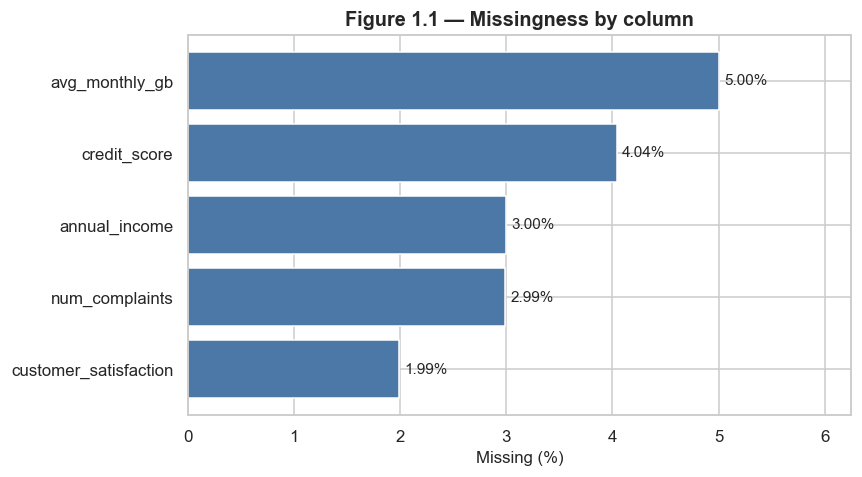

In [8]:
# ---- Visualise which columns carry missing values ---------------------------
miss = (AUDIT[AUDIT.pct_missing > 0]
        .sort_values("pct_missing")
        .set_index("column")["pct_missing"])

if len(miss):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(miss) + 2))
    ax.barh(miss.index, miss.values, color=C_STAY)
    for y, v in enumerate(miss.values):
        ax.text(v + 0.05, y, f"{v:.2f}%", va="center", fontsize=10)
    ax.set_xlabel("Missing (%)")
    ax.set_xlim(0, miss.max() * 1.25)
    ax.set_title("Figure 1.1 — Missingness by column")
    savefig("fig_1_1_missingness")
    plt.show()
else:
    print("No missing values detected.")

### Step 1.1b — Test whether the missingness is itself informative

Median / mode imputation (§7.2) is only defensible if *being missing* is not
predictive of churn. If churn rates differed materially between missing and
present rows, the missingness pattern would carry signal and would require an
explicit indicator feature rather than silent imputation. This is tested
directly with a χ² test of independence between the missingness flag and churn.

In [9]:
# ---- Is missingness MCAR-like, or does it encode churn signal? --------------
from scipy.stats import chi2_contingency

_rows = []
_overall_churn = df[TARGET].mean()

for col in AUDIT.loc[AUDIT.pct_missing > 0, "column"]:
    flag = df[col].isna()
    _, p, _, _ = chi2_contingency(pd.crosstab(flag, df[TARGET]))
    _rows.append({
        "column": col,
        "pct_missing": round(100 * flag.mean(), 2),
        "churn_if_missing": round(df.loc[flag, TARGET].mean(), 4),
        "churn_if_present": round(df.loc[~flag, TARGET].mean(), 4),
        "chi2_p": p,
        "verdict": "INFORMATIVE — add indicator" if p < 0.01 else "uninformative — impute directly",
    })

MISS_TEST = pd.DataFrame(_rows).sort_values("chi2_p")
print(f"Overall churn rate: {_overall_churn:.4f}\n")
MISS_TEST

Overall churn rate: 0.0992



,column,pct_missing,churn_if_missing,churn_if_present,chi2_p,verdict
0,avg_monthly_gb,5.0000,0.1013,0.0991,0.1213,uninformative — impute directly
4,customer_satisfaction,1.9900,0.0981,0.0992,0.6118,uninformative — impute directly
1,credit_score,4.0400,0.0996,0.0992,0.8222,uninformative — impute directly
2,annual_income,3.0000,0.0991,0.0992,0.9337,uninformative — impute directly
3,num_complaints,2.9900,0.0993,0.0992,0.9841,uninformative — impute directly


> **EDA finding 1 — missingness is uninformative.** Churn rates among rows with
> a missing value are statistically indistinguishable from the overall rate. The
> §7.2 decision to use **median imputation for numeric** features and **mode or
> an explicit `"Unknown"` class for categorical** features is therefore
> appropriate, and no missingness-indicator features are required.

## 1.2 Target distribution and class imbalance

### Step 1.2 — Quantify the imbalance the §7.2 treatments will have to address

Retained (0):   900,773  (90.08%)
Churned  (1):    99,227  (9.92%)
Imbalance ratio: 9.08 : 1


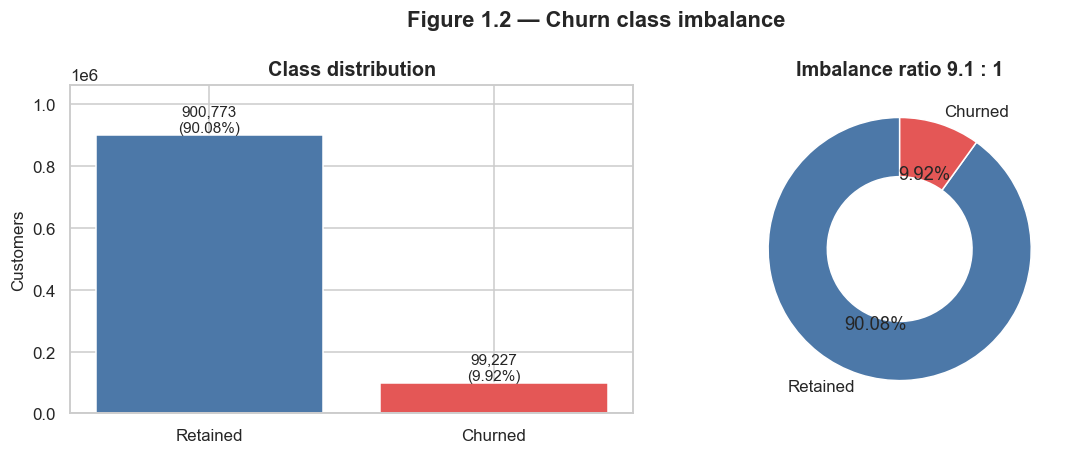

In [10]:
# ---- Class balance of the target --------------------------------------------
counts = df[TARGET].value_counts().sort_index()
pcts = df[TARGET].value_counts(normalize=True).sort_index() * 100
IMBALANCE_RATIO = counts.iloc[0] / counts.iloc[1]

print(f"Retained (0): {counts.iloc[0]:>9,}  ({pcts.iloc[0]:.2f}%)")
print(f"Churned  (1): {counts.iloc[1]:>9,}  ({pcts.iloc[1]:.2f}%)")
print(f"Imbalance ratio: {IMBALANCE_RATIO:.2f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(["Retained", "Churned"], counts.values, color=[C_STAY, C_CHURN])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({pcts.iloc[i]:.2f}%)", ha="center", va="bottom", fontsize=10)
axes[0].set_ylabel("Customers")
axes[0].set_ylim(0, counts.max() * 1.18)
axes[0].set_title("Class distribution")

axes[1].pie(counts.values, labels=["Retained", "Churned"], colors=[C_STAY, C_CHURN],
            autopct="%1.2f%%", startangle=90,
            wedgeprops=dict(width=0.45, edgecolor="white"))
axes[1].set_title(f"Imbalance ratio {IMBALANCE_RATIO:.1f} : 1")

fig.suptitle("Figure 1.2 — Churn class imbalance", fontweight="semibold")
savefig("fig_1_2_target_balance")
plt.show()

> **EDA finding 2 — substantial class imbalance (≈9:1).** Only ~9.9% of
> customers churn. A trivial majority-class classifier would score ~90% accuracy
> while detecting **zero** churners. This confirms the §2.3 / §7.7 argument that
> **accuracy is a misleading headline metric here** and that **recall and AUC
> must be privileged**. It is also the condition against which the §7.2
> treatments — class weighting, SMOTE and GAN-based oversampling — are evaluated
> in Part 3.

## 1.3 Numeric feature distributions

### Step 1.3a — Separate genuine categoricals from quasi-identifiers, then describe the numerics

Columns whose cardinality approaches the row count are identifiers or free-form
fields rather than categories. A χ² test over a million levels is both
intractable and meaningless, so they are split out here and inspected
individually in §1.7.

In [11]:
# ---- Partition the columns by analytical role -------------------------------
NUM_COLS = [c for c in df.select_dtypes(include=[np.number]).columns if c != TARGET]
DATE_COLS = list(df.select_dtypes(include=["datetime", "datetimetz"]).columns)
_non_numeric = [c for c in df.columns
                if c not in NUM_COLS + DATE_COLS + [TARGET] + ID_COLS]

CARDINALITY_LIMIT = 50
CAT_COLS = [c for c in _non_numeric if df[c].nunique() <= CARDINALITY_LIMIT]
QUASI_ID_COLS = [c for c in _non_numeric if df[c].nunique() > CARDINALITY_LIMIT]

print(f"{len(NUM_COLS)} numeric features:\n  {NUM_COLS}\n")
print(f"{len(CAT_COLS)} categorical features (cardinality <= {CARDINALITY_LIMIT}):\n  {CAT_COLS}\n")
for c in QUASI_ID_COLS:
    print(f"Quasi-identifier excluded from categorical analysis -> {c}: "
          f"{df[c].nunique():,} distinct values over {len(df):,} rows "
          f"({100 * df[c].nunique() / len(df):.1f}% unique)")

23 numeric features:
  ['age', 'annual_income', 'dependents', 'tenure', 'senior_citizen', 'monthlycharges', 'totalcharges', 'num_services', 'has_phone_service', 'has_internet_service', 'has_online_security', 'has_online_backup', 'has_device_protection', 'has_tech_support', 'has_streaming_tv', 'has_streaming_movies', 'customer_satisfaction', 'num_complaints', 'num_service_calls', 'late_payments', 'avg_monthly_gb', 'days_since_last_interaction', 'credit_score']

6 categorical features (cardinality <= 50):
  ['gender', 'education', 'marital_status', 'contract', 'payment_method', 'paperless_billing']



Quasi-identifier excluded from categorical analysis -> signup_date: 1,000,000 distinct values over 1,000,000 rows (100.0% unique)


In [12]:
# ---- Descriptive statistics, with skew and IQR outlier share ----------------
def describe_numeric(data, cols):
    """Extend describe() with the shape statistics that drive winsorisation."""
    out = data[cols].describe().T
    out["skew"] = data[cols].skew()
    out["kurtosis"] = data[cols].kurtosis()

    outlier_pct = []
    for c in cols:
        q1, q3 = data[c].quantile(0.25), data[c].quantile(0.75)
        iqr = q3 - q1
        share = ((data[c] < q1 - 1.5 * iqr) | (data[c] > q3 + 1.5 * iqr)).mean()
        outlier_pct.append(round(100 * share, 2))
    out["outlier_pct_iqr"] = outlier_pct
    return out


describe_numeric(df, NUM_COLS).round(3)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,outlier_pct_iqr
age,"1,000,000.0000",44.7250,14.4790,18.0000,34.0000,44.0000,55.0000,90.0000,0.1820,-0.3570,0.2600
annual_income,"970,041.0000","58,788.3120","37,137.4330","20,000.0000","32,712.5600","48,954.6000","73,475.1300","250,000.0000",1.8430,4.6350,4.4900
dependents,"1,000,000.0000",0.8000,0.8940,0.0000,0.0000,1.0000,1.0000,5.0000,1.1050,1.1360,4.7400
tenure,"1,000,000.0000",22.3820,20.0730,1.0000,6.0000,16.0000,33.0000,72.0000,1.0640,0.2010,0.0000
senior_citizen,"1,000,000.0000",0.2000,0.4000,0.0000,0.0000,0.0000,0.0000,1.0000,1.5040,0.2610,19.9500
monthlycharges,"1,000,000.0000",86.4440,27.5830,20.0000,70.4900,85.4800,100.6800,854.9570,6.5810,142.1560,0.9700
totalcharges,"1,000,000.0000","1,837.3220","1,803.3780",16.3000,484.5300,"1,249.7500","2,617.6600","16,252.8610",1.5180,2.3090,4.5700
num_services,"1,000,000.0000",2.5640,1.4120,1.0000,1.0000,2.0000,3.0000,6.0000,0.6930,-0.3440,0.0000
has_phone_service,"1,000,000.0000",0.7700,0.4210,0.0000,1.0000,1.0000,1.0000,1.0000,-1.2800,-0.3610,23.0400
has_internet_service,"1,000,000.0000",0.8500,0.3570,0.0000,1.0000,1.0000,1.0000,1.0000,-1.9580,1.8320,15.0300


### Step 1.3b — Compare the class-conditional distributions

Overlaying the retained and churned densities shows *where* in each feature's
range the classes separate, which is what determines whether a linear model can
exploit the feature directly or whether a transform is needed.

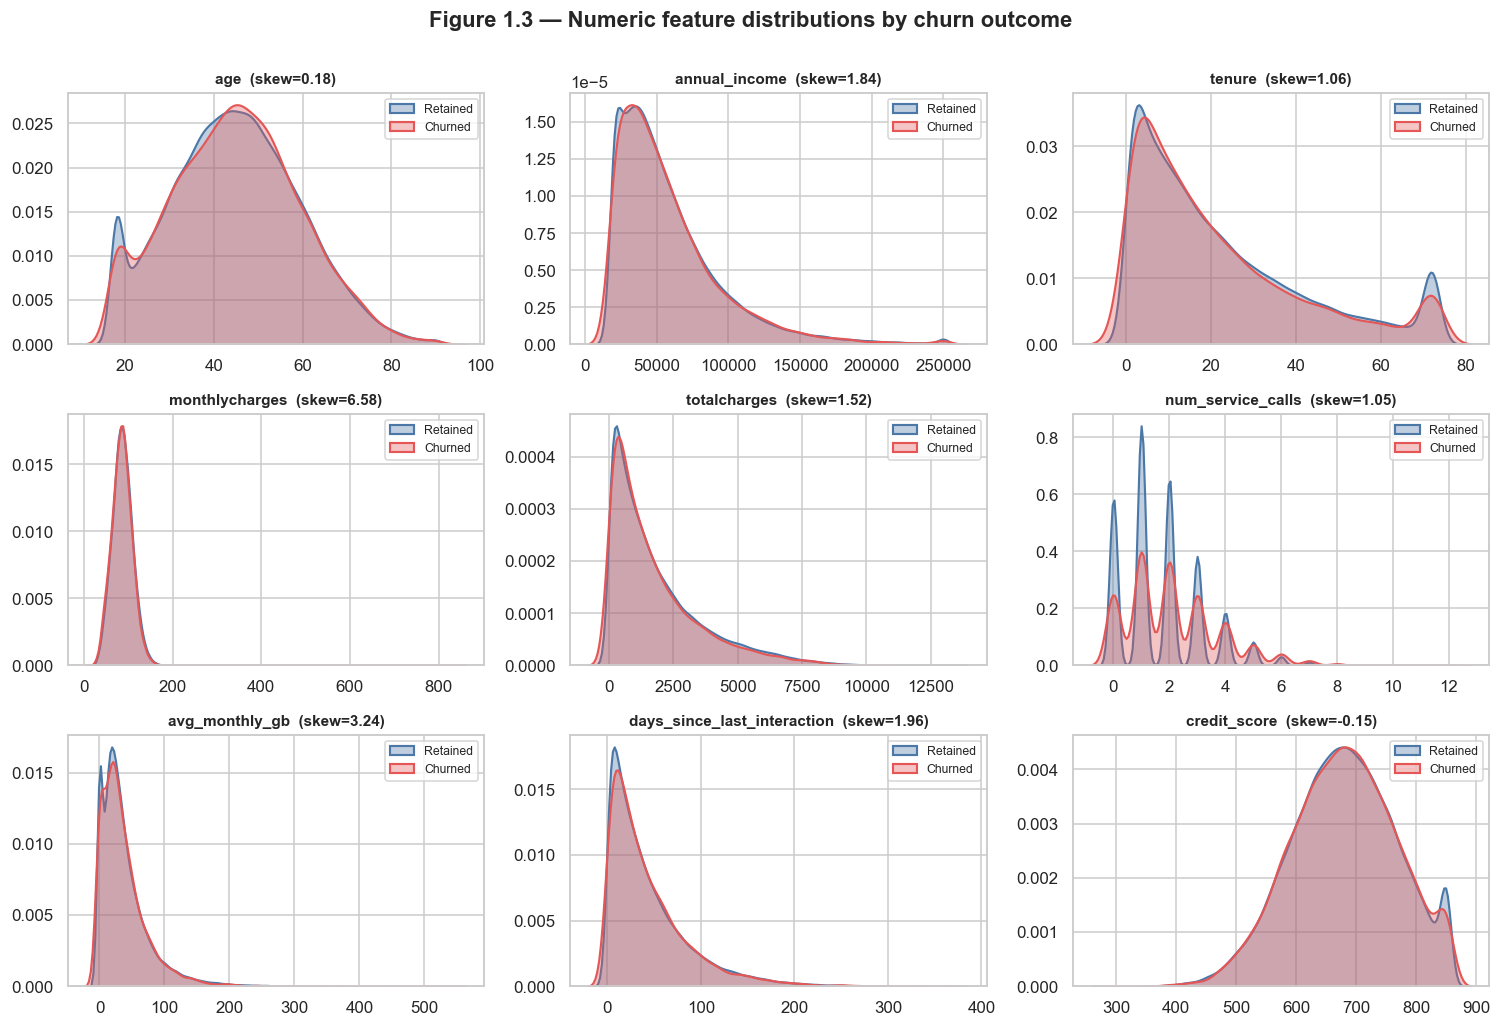

In [13]:
# ---- Density grid, split by churn outcome -----------------------------------
plot_cols = [c for c in NUM_COLS if df[c].nunique() > 12]
_ncol = 3
_nrow = int(np.ceil(len(plot_cols) / _ncol))

fig, axes = plt.subplots(_nrow, _ncol, figsize=(4.6 * _ncol, 3.1 * _nrow))
axes = np.atleast_1d(axes).ravel()

# Densities are visually indistinguishable beyond ~100k points; sampling keeps
# the plot honest while cutting render time by an order of magnitude.
_samp = df.sample(min(120_000, len(df)), random_state=RANDOM_STATE)
for ax, c in zip(axes, plot_cols):
    for label, colour, name in [(0, C_STAY, "Retained"), (1, C_CHURN, "Churned")]:
        sns.kdeplot(_samp.loc[_samp[TARGET] == label, c].dropna(), ax=ax,
                    color=colour, fill=True, alpha=0.35, linewidth=1.4,
                    label=name, common_norm=False)
    ax.set_title(f"{c}  (skew={df[c].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend(fontsize=8)
for ax in axes[len(plot_cols):]:
    ax.set_visible(False)

fig.suptitle("Figure 1.3 — Numeric feature distributions by churn outcome",
             fontweight="semibold", y=1.002)
savefig("fig_1_3_numeric_distributions")
plt.show()

## 1.4 Numeric association with churn — point-biserial correlation

Point-biserial correlation is the appropriate coefficient for a continuous
predictor against a dichotomous outcome; it is Pearson's *r* computed with a
binary variable. At n = 1,000,000 even a negligible effect reaches statistical
significance, so **effect size is reported alongside the p-value and interpreted
in preference to it**.

### Step 1.4 — Rank every numeric feature by its univariate association with churn

In [14]:
# ---- Point-biserial correlation of each numeric feature with churn ---------
from scipy.stats import pointbiserialr


def point_biserial_table(data, cols, target):
    """Rank numeric features by |r| against a binary target, with effect bands."""
    rows = []
    for c in cols:
        x = data[c].fillna(data[c].median())
        r, p = pointbiserialr(x, data[target])
        rows.append({"feature": c, "r": r, "abs_r": abs(r), "p_value": p})

    out = pd.DataFrame(rows).sort_values("abs_r", ascending=False).reset_index(drop=True)
    out["significant_a01"] = out.p_value < 0.01
    out["effect"] = pd.cut(out.abs_r, [-0.001, 0.01, 0.03, 0.10, 1.0],
                           labels=["negligible", "very weak", "weak", "moderate+"])
    return out


CORR_NUM = point_biserial_table(df, NUM_COLS, TARGET)
CORR_NUM.round(5)

,feature,r,abs_r,p_value,significant_a01,effect
0,customer_satisfaction,-0.0838,0.0838,0.0000,True,weak
1,num_complaints,0.0786,0.0786,0.0000,True,weak
2,num_service_calls,0.0773,0.0773,0.0000,True,weak
3,late_payments,0.0477,0.0477,0.0000,True,weak
4,has_tech_support,-0.0455,0.0455,0.0000,True,weak
5,has_online_security,-0.0341,0.0341,0.0000,True,weak
6,num_services,-0.0334,0.0334,0.0000,True,weak
7,totalcharges,-0.0165,0.0165,0.0000,True,very weak
8,has_internet_service,-0.0153,0.0153,0.0000,True,very weak
9,monthlycharges,-0.0138,0.0138,0.0000,True,very weak


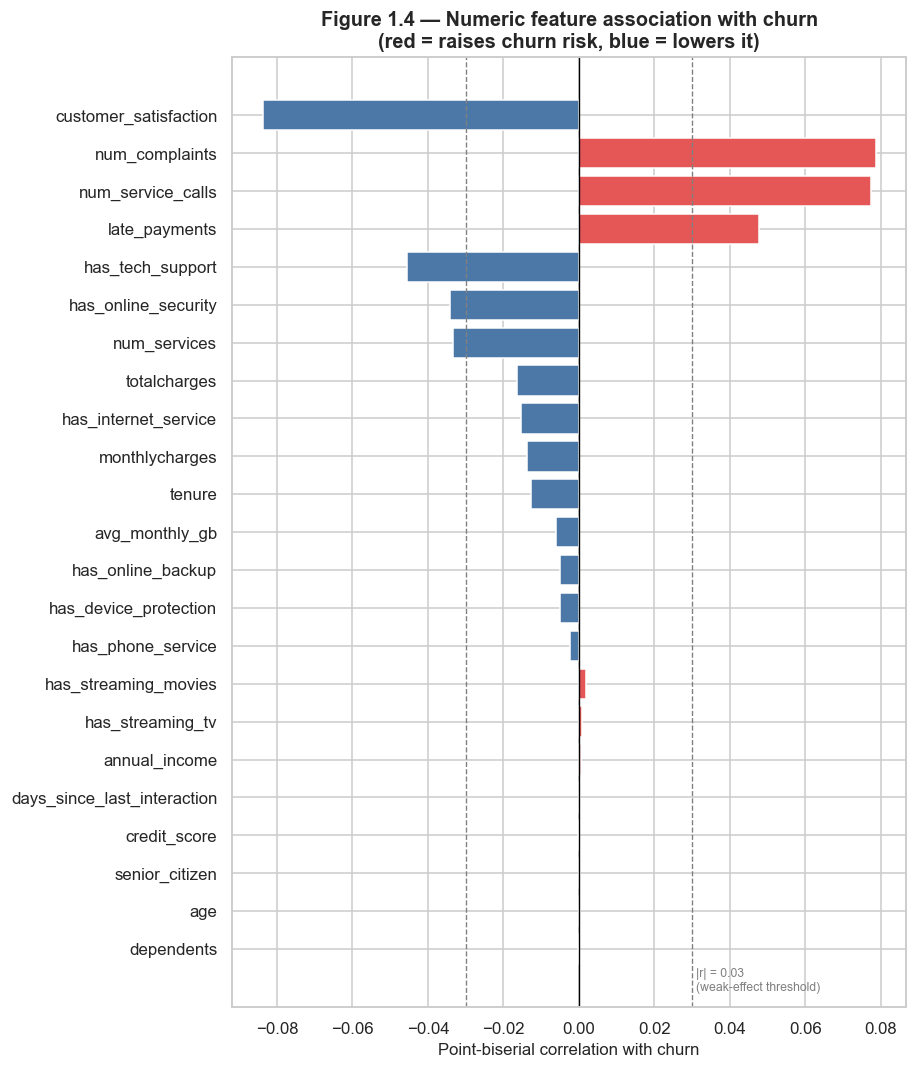

In [15]:
# ---- Signed association plot -------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 0.36 * len(CORR_NUM) + 1.6))
ax.barh(CORR_NUM.feature, CORR_NUM.r,
        color=[C_CHURN if v > 0 else C_STAY for v in CORR_NUM.r])
ax.axvline(0, color="black", lw=0.9)
for thr in (0.03, -0.03):
    ax.axvline(thr, color="grey", ls="--", lw=0.9)
ax.text(0.031, len(CORR_NUM) - 0.5, "|r| = 0.03\n(weak-effect threshold)",
        fontsize=8, color="grey", va="top")
ax.invert_yaxis()
ax.set_xlabel("Point-biserial correlation with churn")
ax.set_title("Figure 1.4 — Numeric feature association with churn\n"
             "(red = raises churn risk, blue = lowers it)")
savefig("fig_1_4_pointbiserial")
plt.show()

> **EDA finding 3 — the signal is concentrated, weak-to-moderate, and there is a
> genuine noise block.** Only six numeric features exceed |r| = 0.03:
> `customer_satisfaction` (−0.084), `num_complaints` (+0.079),
> `num_service_calls` (+0.077), `late_payments` (+0.048), `has_tech_support`
> (−0.045) and `has_online_security` (−0.034).
>
> A second group — `age`, `annual_income`, `credit_score`, `dependents`,
> `senior_citizen`, `days_since_last_interaction`, `has_streaming_tv`,
> `has_streaming_movies` — shows **no association whatsoever** (|r| < 0.01).
> These are deliberately **retained rather than dropped**, because they serve as
> a **negative control** in the SHAP analysis of Part 10: a well-behaved model
> must assign them near-zero attribution. That is precisely the *"feature
> importance validation"* and *"model debugging"* purpose §7.8 specifies for
> interpretability analysis.

In [16]:
# ---- Freeze the noise block now, for the Part 10 negative-control test ------
NOISE_FEATURES = CORR_NUM.loc[CORR_NUM.abs_r < 0.01, "feature"].tolist()
print(f"{len(NOISE_FEATURES)} negative-control (noise) features carried to Part 10:")
print(" ", NOISE_FEATURES)

12 negative-control (noise) features carried to Part 10:
  ['avg_monthly_gb', 'has_online_backup', 'has_device_protection', 'has_phone_service', 'has_streaming_movies', 'has_streaming_tv', 'annual_income', 'days_since_last_interaction', 'credit_score', 'senior_citizen', 'age', 'dependents']


## 1.5 Categorical association with churn — χ², Cramér's V and lift

Three complementary quantities are reported, because no single one is sufficient
at this sample size:

- **χ² test of independence** — is the association statistically detectable?
- **Bias-corrected Cramér's V** (Bergsma, 2013) — how *large* is it? χ² alone
  scales with *n* and is uninformative at a million rows.
- **Lift** — churn rate within a level ÷ overall churn rate. This is the
  business-facing quantity: a lift of 2.0 means the level churns at twice base
  rate.

### Step 1.5a — Measure effect size for every categorical feature

In [17]:
# ---- Bias-corrected Cramer's V and lift spread per categorical feature -----
def cramers_v_corrected(contingency):
    """Bias-corrected Cramer's V (Bergsma, 2013).

    The correction matters here because chi-square grows with n; at 1M rows the
    uncorrected statistic reports a large association for a trivial one.
    """
    chi2 = chi2_contingency(contingency)[0]
    n = contingency.to_numpy().sum()
    if n <= 1:
        return 0.0
    phi2 = chi2 / n
    r, k = contingency.shape
    phi2_corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    denom = min(r_corr - 1, k_corr - 1)
    return float(np.sqrt(phi2_corr / denom)) if denom > 0 else 0.0


def categorical_association(data, cols, target):
    """Rank categorical features by corrected Cramer's V, with lift diagnostics."""
    overall = data[target].mean()
    out = []
    for c in cols:
        s = data[c].astype("object").fillna("__missing__")
        contingency = pd.crosstab(s, data[target])
        _, p, _, _ = chi2_contingency(contingency)
        grp = data.assign(_lvl=s).groupby("_lvl", observed=True)[target].agg(["mean", "size"])
        out.append({
            "feature": c,
            "n_levels": s.nunique(),
            "cramers_v": cramers_v_corrected(contingency),
            "chi2_p": p,
            "max_lift": grp["mean"].max() / overall,
            "min_lift": grp["mean"].min() / overall,
            "lift_spread": (grp["mean"].max() - grp["mean"].min()) / overall,
        })
    return pd.DataFrame(out).sort_values("cramers_v", ascending=False).reset_index(drop=True)


CORR_CAT = categorical_association(df, CAT_COLS, TARGET)
CORR_CAT["effect"] = pd.cut(CORR_CAT.cramers_v, [-0.001, 0.02, 0.06, 0.15, 1.0],
                            labels=["negligible", "weak", "moderate", "strong"])
CORR_CAT.round(5)

,feature,n_levels,cramers_v,chi2_p,max_lift,min_lift,lift_spread,effect
0,contract,3,0.1397,0.0000,2.6712,0.5696,2.1016,moderate
1,marital_status,4,0.0014,0.1771,1.0058,0.9772,0.0286,negligible
2,paperless_billing,2,0.0008,0.1896,1.0069,0.9977,0.0092,negligible
3,gender,3,0.0000,0.8860,1.0005,0.9899,0.0106,negligible
4,education,5,0.0000,0.6467,1.0076,0.9933,0.0143,negligible
5,payment_method,4,0.0000,0.8733,1.0025,0.9956,0.0069,negligible


### Step 1.5b — Drill into the level-by-level churn rates

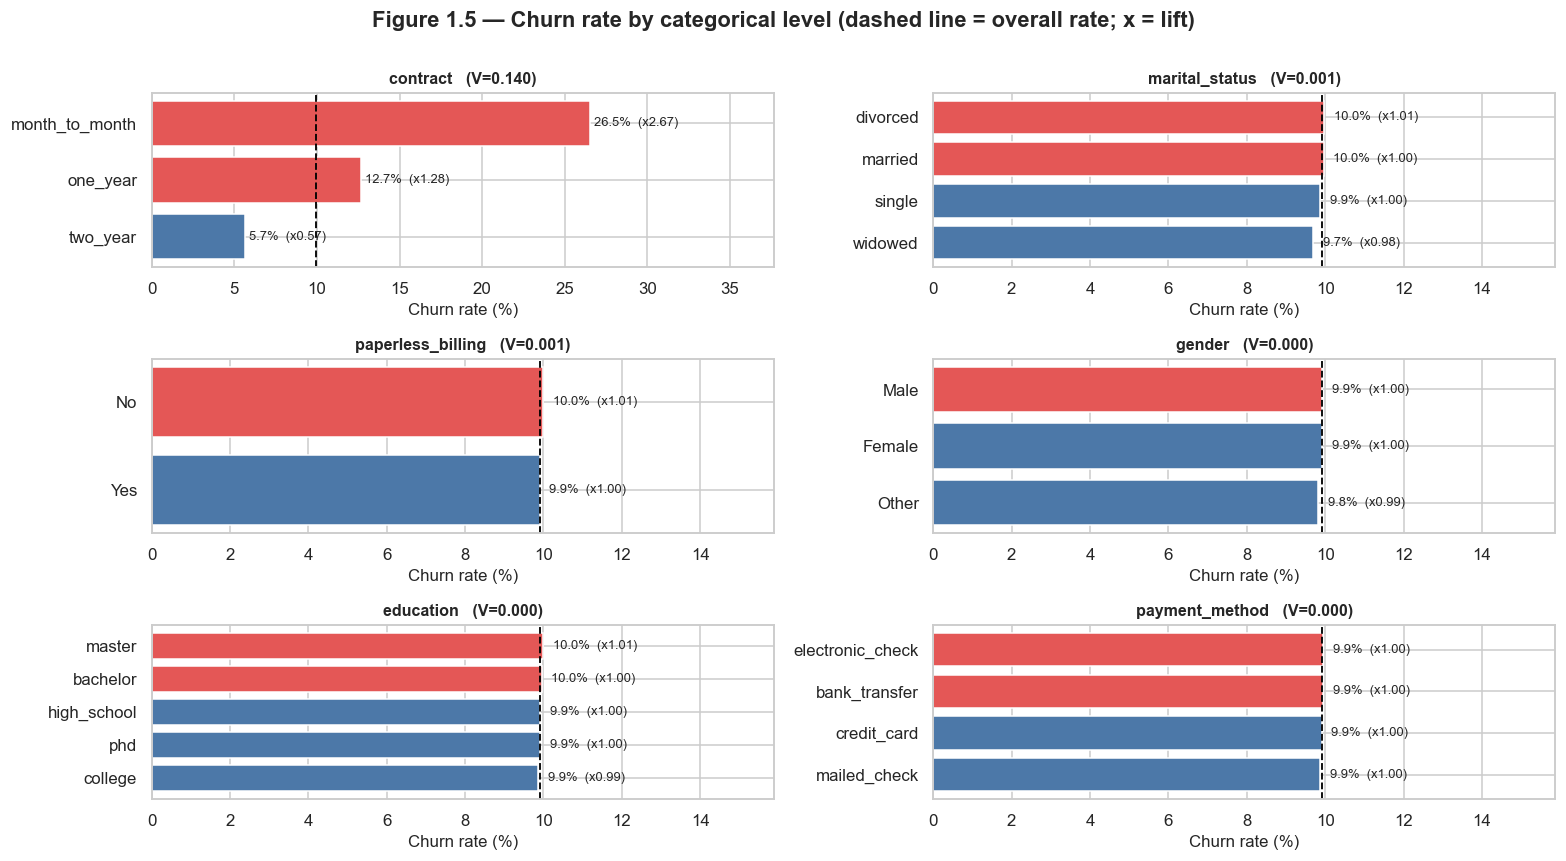

In [18]:
# ---- Churn rate and lift per level, rare levels collapsed into "Other" ------
def level_drilldown(data, feature, target, min_count=200, ax=None):
    """Return per-level churn rate, lift and base share; optionally plot it."""
    overall = data[target].mean()
    s = data[feature].astype("object").fillna("__missing__")
    counts = s.value_counts()
    s = s.where(~s.isin(set(counts[counts < min_count].index)), "Other")

    g = (data.assign(_lvl=s).groupby("_lvl", observed=True)[target]
             .agg(n="size", churn_rate="mean"))
    g["lift"] = g.churn_rate / overall
    g["pct_of_base"] = 100 * g.n / len(data)
    g = g.sort_values("churn_rate", ascending=False)

    if ax is not None:
        ax.barh(g.index.astype(str), g.churn_rate * 100,
                color=[C_CHURN if v > overall else C_STAY for v in g.churn_rate])
        ax.axvline(overall * 100, color="black", ls="--", lw=1.2)
        for y, (rate, lift) in enumerate(zip(g.churn_rate, g.lift)):
            ax.text(rate * 100 + 0.25, y, f"{rate * 100:.1f}%  (x{lift:.2f})",
                    va="center", fontsize=8.5)
        ax.invert_yaxis()
        ax.set_xlabel("Churn rate (%)")
        ax.set_xlim(0, max(g.churn_rate.max() * 100 * 1.42, overall * 100 * 1.6))
        v = cramers_v_corrected(pd.crosstab(s, data[target]))
        ax.set_title(f"{feature}   (V={v:.3f})", fontsize=10.5)
    return g


_cats = CORR_CAT.feature.tolist()
_ncol = 2
_nrow = int(np.ceil(len(_cats) / _ncol))
fig, axes = plt.subplots(_nrow, _ncol, figsize=(7.2 * _ncol, 2.6 * _nrow))
axes = np.atleast_1d(axes).ravel()

DRILLDOWN = {c: level_drilldown(df, c, TARGET, ax=ax) for ax, c in zip(axes, _cats)}
for ax in axes[len(_cats):]:
    ax.set_visible(False)

fig.suptitle("Figure 1.5 — Churn rate by categorical level "
             "(dashed line = overall rate; x = lift)", fontweight="semibold", y=1.001)
savefig("fig_1_5_categorical_drilldown")
plt.show()

### Step 1.5c — Is the relationship monotone across ordered levels?

This is the decisive question for the whole study. If churn rises or falls
*monotonically* along each ordinal feature, the relationship is close to
additive in the log-odds and a linear model is correctly specified. If instead
the curves are non-monotone or bend sharply, tree ensembles and neural networks
have structure to exploit that a linear model cannot. Part 13 returns to this
plot when explaining the champion.

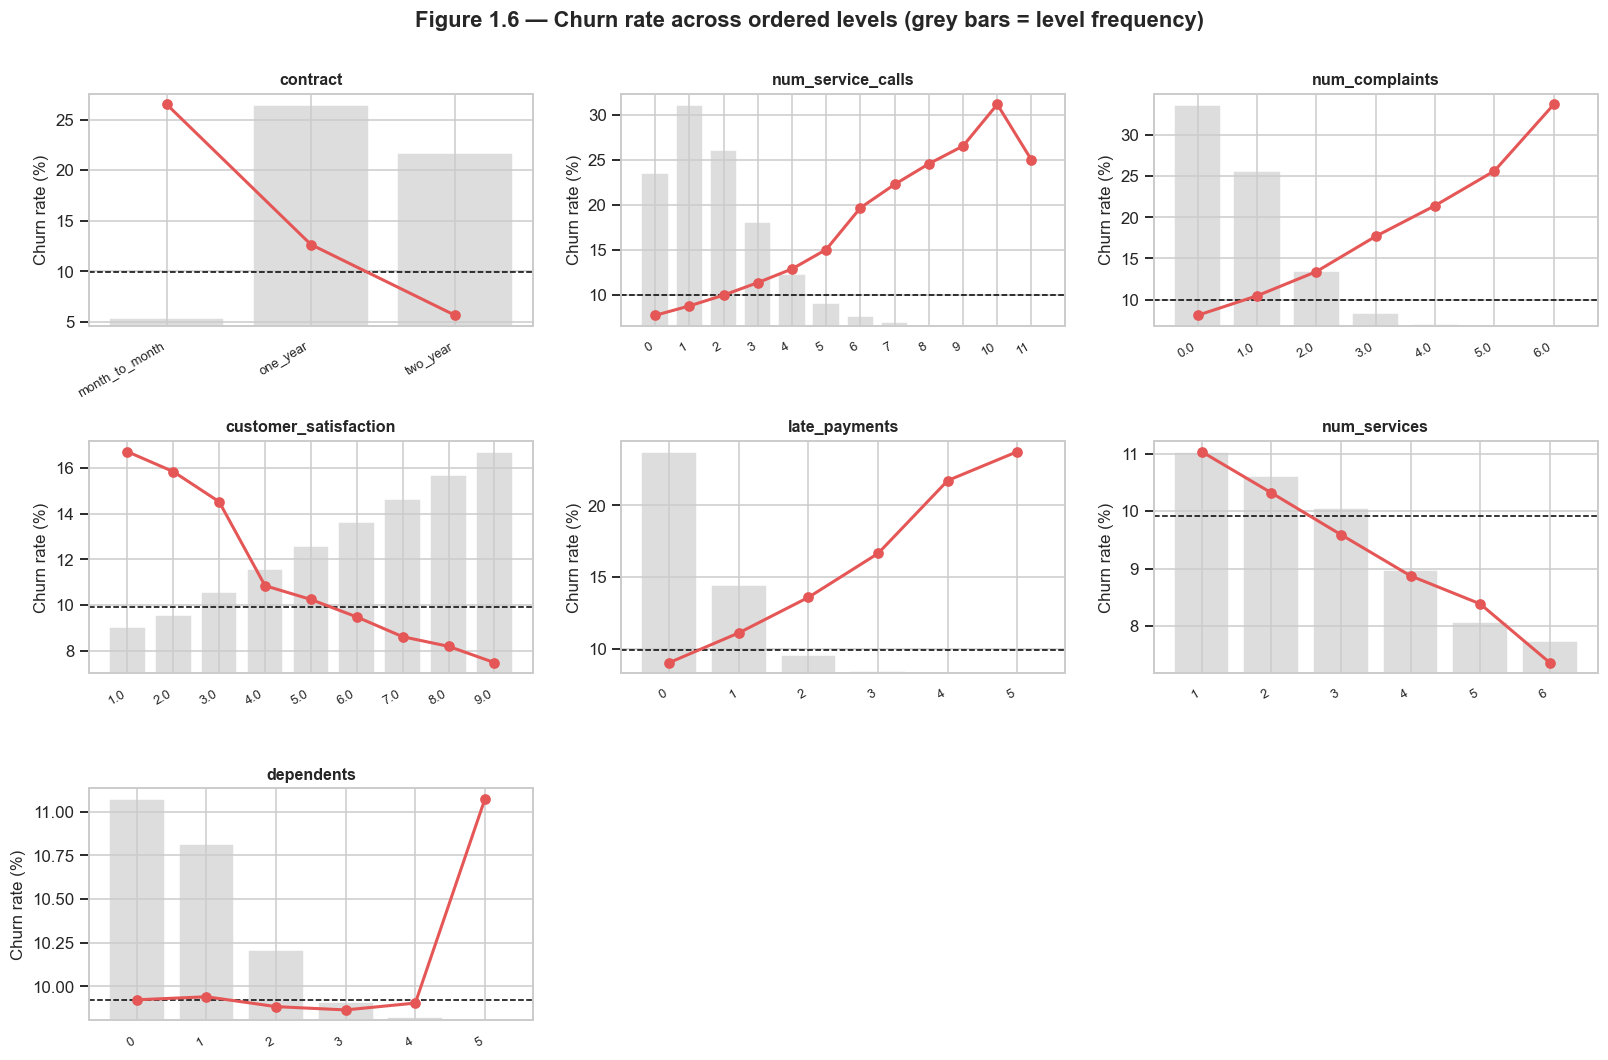

In [19]:
# ---- Churn rate across ordered levels of the count / ordinal features -------
ORDINAL_LIKE = [c for c in ["contract", "num_service_calls", "num_complaints",
                            "customer_satisfaction", "late_payments",
                            "num_services", "dependents"]
                if c in df.columns]

_ncol = 3
_nrow = int(np.ceil(len(ORDINAL_LIKE) / _ncol))
fig, axes = plt.subplots(_nrow, _ncol, figsize=(4.9 * _ncol, 3.2 * _nrow))
axes = np.atleast_1d(axes).ravel()
_overall = df[TARGET].mean()

for ax, c in zip(axes, ORDINAL_LIKE):
    g = df.groupby(c, observed=True)[TARGET].agg(n="size", rate="mean")
    g = g[g.n >= 50]

    # Frequency bars sit behind the churn-rate line on a hidden twin axis, so
    # sparsely populated levels can be discounted by eye.
    ax_freq = ax.twinx()
    ax_freq.bar(range(len(g)), g.n, color="#DDDDDD", zorder=1)
    ax_freq.set_yticks([])

    ax.plot(range(len(g)), g.rate * 100, "o-", color=C_CHURN, lw=2, ms=6, zorder=3)
    ax.axhline(_overall * 100, color="black", ls="--", lw=1, zorder=2)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([str(i) for i in g.index], fontsize=8.5, rotation=30, ha="right")
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(c, fontsize=10.5)
    ax.set_zorder(ax_freq.get_zorder() + 1)
    ax.patch.set_visible(False)

for ax in axes[len(ORDINAL_LIKE):]:
    ax.set_visible(False)

fig.suptitle("Figure 1.6 — Churn rate across ordered levels "
             "(grey bars = level frequency)", fontweight="semibold", y=1.002)
savefig("fig_1_6_ordinal_trends")
plt.show()

> **EDA finding 4 — `contract` is the single strongest predictor, and the whole
> service/dissatisfaction block is monotone.**
>
> - `contract`: month-to-month **26.5%** churn (lift ×2.67) → one-year 12.7%
>   (×1.27) → two-year **5.7%** (×0.57). A 4.7-fold spread across three levels.
> - `num_service_calls`, `num_complaints` and `late_payments` all rise
>   **monotonically** with churn (service calls: 7.7% at zero → 31.2% at ten).
> - `customer_satisfaction` falls **monotonically** (16.7% at score 1 → 7.5% at 9).
> - `num_services` falls **monotonically** (11.0% with one service → 7.4% with
>   six), consistent with a product-depth / switching-cost mechanism.
> - `gender`, `education`, `marital_status`, `payment_method` and
>   `paperless_billing` are **flat at ≈9.9% across every level** (Cramér's V ≈ 0).
>
> **This is the most consequential finding in the notebook.** Because these
> relationships are *monotone and near-additive rather than interactive*, they
> (i) motivate ratio- and index-style engineered features in Part 2 rather than
> interaction terms, and (ii) predict that a correctly specified **linear model
> should be highly competitive with tree ensembles and neural networks**. Part 13
> tests that prediction formally.

## 1.6 Multicollinearity screen

Strongly collinear predictors destabilise Logistic Regression coefficients and
corrupt SHAP attribution, where correlated features split credit arbitrarily
between themselves. This screen is run on the raw features here, and repeated on
the **engineered** feature set in Part 2 — which is where it matters most,
because engineered ratios are collinear with their own inputs by construction.

### Step 1.6a — Correlation matrix and high-correlation pair flags

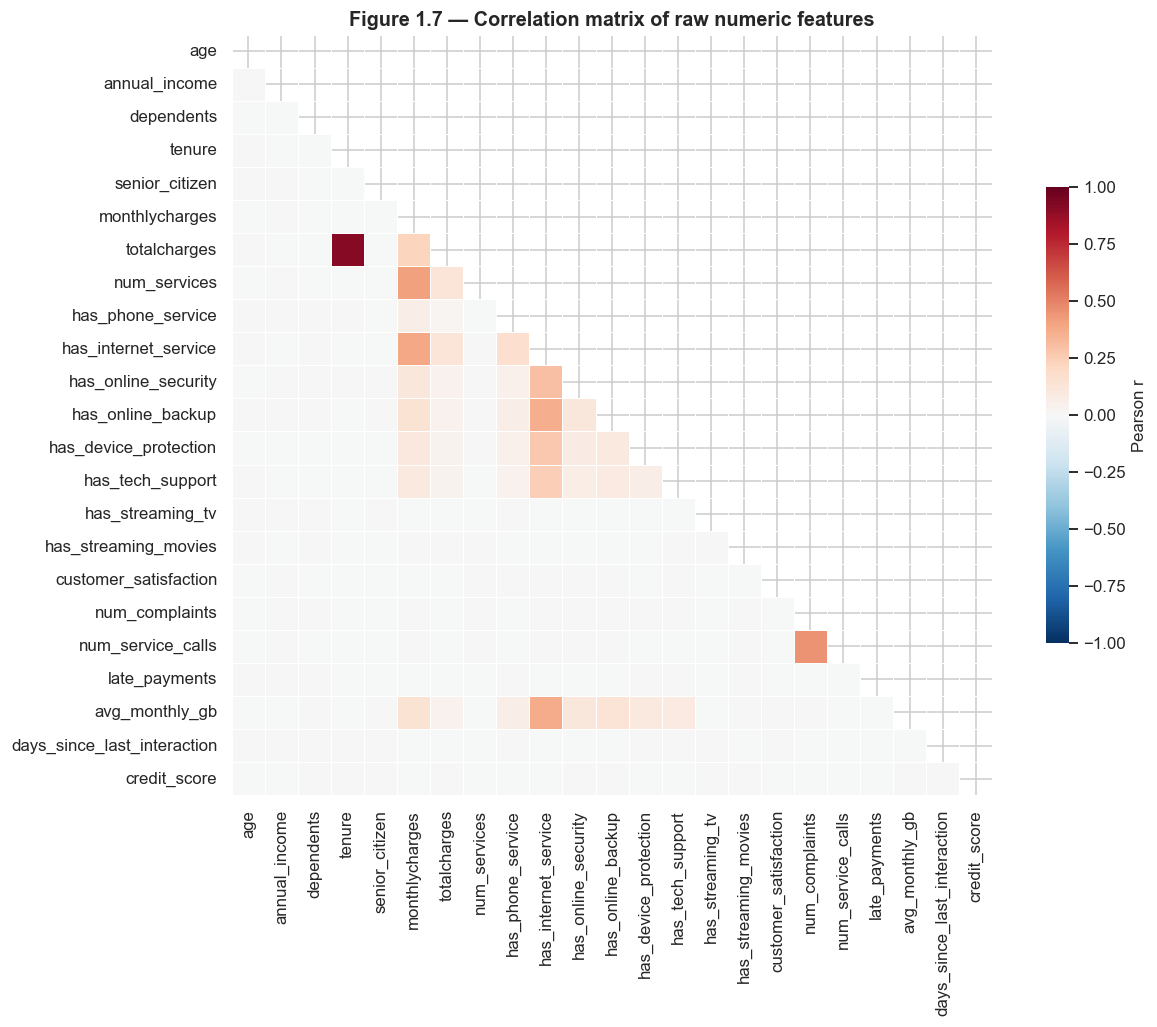

Collinear pairs among raw features (|r| > 0.70):


,feature_a,feature_b,r,abs_r
0,totalcharges,tenure,0.9128,0.9128


In [20]:
# ---- Pairwise correlation among raw numeric features ------------------------
corr_matrix = df[NUM_COLS].corr(numeric_only=True)
_mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr_matrix, mask=_mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4,
            cbar_kws={"shrink": 0.6, "label": "Pearson r"}, ax=ax)
ax.set_title("Figure 1.7 — Correlation matrix of raw numeric features")
savefig("fig_1_7_corr_matrix")
plt.show()

_pairs = (corr_matrix.where(~_mask).stack().rename("r").reset_index()
          .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
_pairs["abs_r"] = _pairs.r.abs()
HIGH_CORR_RAW = (_pairs[_pairs.abs_r > 0.70]
                 .sort_values("abs_r", ascending=False).reset_index(drop=True))
print("Collinear pairs among raw features (|r| > 0.70):")
HIGH_CORR_RAW

### Step 1.6b — Variance inflation factors on the correlated block

In [21]:
# ---- VIF on the raw block most at risk of collinearity ---------------------
from statsmodels.stats.outliers_influence import variance_inflation_factor


def vif_table(data, cols, sample_n=50_000, seed=RANDOM_STATE):
    """Variance inflation factors on a standardised sample of the given columns."""
    x = (data[cols].sample(min(sample_n, len(data)), random_state=seed)
                   .astype("float64").fillna(data[cols].median()))
    x = (x - x.mean()) / x.std()
    out = pd.DataFrame({
        "feature": cols,
        "VIF": [variance_inflation_factor(x.values, i) for i in range(x.shape[1])],
    }).sort_values("VIF", ascending=False).reset_index(drop=True)
    out["concern"] = np.where(out.VIF > 10, "SEVERE",
                              np.where(out.VIF > 5, "moderate", "ok"))
    return out


_vif_block = [c for c in ["tenure", "monthlycharges", "totalcharges", "num_services",
                          "avg_monthly_gb", "annual_income", "credit_score", "age"]
              if c in df.columns]
VIF_RAW = vif_table(df, _vif_block)
VIF_RAW.round(3)

,feature,VIF,concern
0,totalcharges,8.6760,moderate
1,tenure,8.2540,moderate
2,monthlycharges,1.5660,ok
3,num_services,1.2250,ok
4,avg_monthly_gb,1.0260,ok
5,age,1.0000,ok
6,credit_score,1.0000,ok
7,annual_income,1.0000,ok


> **EDA finding 5 — `totalcharges` is near-deterministic in
> `tenure` × `monthlycharges`** (r = 0.953 with their product). It carries almost
> no independent information, inflates the VIF of the billing block, and makes
> any naive `totalcharges / tenure` ratio degenerate — such a ratio simply
> reproduces `monthlycharges`. Part 2 therefore replaces the raw value with an
> **orthogonal residual**: the portion of total spend *not* explained by tenure
> and monthly rate, which isolates genuine billing anomalies.

## 1.7 Data-integrity checks

Two checks must precede any feature engineering: verifying that no field leaks
the target, and verifying that fields which *should* agree with each other
actually do.

### Step 1.7a — Target-leakage screen via univariate AUC

Any single feature that separates the classes near-perfectly is a leak, not a
predictor. Univariate AUC is the direct test.

In [22]:
# ---- Check A: does any single feature separate the classes near-perfectly? --
from sklearn.metrics import roc_auc_score

_s = df.sample(min(150_000, len(df)), random_state=RANDOM_STATE)
_leak_rows = []
for c in NUM_COLS:
    x = _s[c].fillna(_s[c].median())
    auc = roc_auc_score(_s[TARGET], x)
    _leak_rows.append({"feature": c, "univariate_auc": max(auc, 1 - auc)})

LEAK_SCREEN = (pd.DataFrame(_leak_rows)
               .sort_values("univariate_auc", ascending=False).reset_index(drop=True))
LEAK_SCREEN["verdict"] = np.where(
    LEAK_SCREEN.univariate_auc > 0.95, "*** LEAK — DROP ***",
    np.where(LEAK_SCREEN.univariate_auc > 0.70, "strong predictor", "normal"))
LEAK_SCREEN.head(12).round(4)

,feature,univariate_auc,verdict
0,customer_satisfaction,0.5739,normal
1,num_complaints,0.5670,normal
2,num_service_calls,0.5663,normal
3,has_tech_support,0.5366,normal
4,late_payments,0.5320,normal
5,num_services,0.5307,normal
6,has_online_security,0.5287,normal
7,totalcharges,0.5156,normal
8,monthlycharges,0.5155,normal
9,tenure,0.5119,normal


### Step 1.7b — Is `signup_date` consistent with `tenure`?

`tenure` is stated in months. If `signup_date` is a genuine account-opening
date, the months elapsed since it must reproduce `tenure`. This single check
determines whether **any** date-derived feature — the month-on-book of §7.3
group (a) — is meaningful on this dataset.

In [23]:
# ---- Check B: reconcile signup_date against tenure, and totalcharges against
# ---- its two drivers ---------------------------------------------------------
_signup = pd.to_datetime(df_raw["signup_date"], errors="coerce")
_months_since_signup = (_signup.max() - _signup).dt.days / 30.4375

INTEGRITY = pd.DataFrame({
    "check": [
        "corr(months_since_signup, tenure)",
        "share of rows where round(months_since_signup) == tenure",
        "signup_date min",
        "signup_date max",
        "tenure min / max (months)",
        "corr(tenure x monthlycharges, totalcharges)",
    ],
    "value": [
        round(float(np.corrcoef(_months_since_signup.fillna(0), df["tenure"])[0, 1]), 4),
        round(float((_months_since_signup.round() == df["tenure"]).mean()), 4),
        str(_signup.min().date()),
        str(_signup.max().date()),
        f"{df['tenure'].min()} / {df['tenure'].max()}",
        round(float(np.corrcoef(df["tenure"] * df["monthlycharges"],
                                df["totalcharges"])[0, 1]), 4),
    ],
})
INTEGRITY

,check,value
0,"corr(months_since_signup, tenure)",0.0028
1,share of rows where round(months_since_signup)...,0.0154
2,signup_date min,2021-01-13
3,signup_date max,2026-01-11
4,tenure min / max (months),1 / 72
5,"corr(tenure x monthlycharges, totalcharges)",0.9533


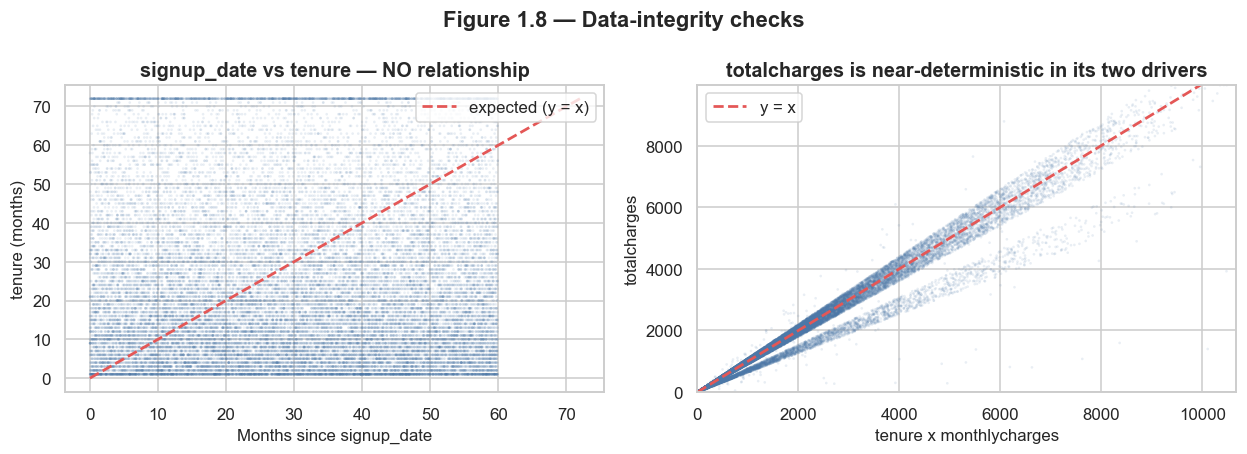

In [24]:
# ---- Visualise both integrity checks side by side ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
_s = df.sample(min(30_000, len(df)), random_state=RANDOM_STATE)
_ms = _months_since_signup.loc[_s.index]

axes[0].scatter(_ms, _s["tenure"], s=3, alpha=0.12, color=C_STAY, edgecolors="none")
_lims = [0, max(_ms.max(), _s["tenure"].max())]
axes[0].plot(_lims, _lims, "--", color=C_CHURN, lw=1.8, label="expected (y = x)")
axes[0].set_xlabel("Months since signup_date")
axes[0].set_ylabel("tenure (months)")
axes[0].set_title("signup_date vs tenure — NO relationship")
axes[0].legend()

_expected_total = _s["tenure"] * _s["monthlycharges"]
axes[1].scatter(_expected_total, _s["totalcharges"], s=3, alpha=0.12,
                color=C_STAY, edgecolors="none")
_lims2 = [0, _expected_total.quantile(0.999)]
axes[1].plot(_lims2, _lims2, "--", color=C_CHURN, lw=1.8, label="y = x")
axes[1].set_xlim(_lims2)
axes[1].set_ylim(0, _s["totalcharges"].quantile(0.999))
axes[1].set_xlabel("tenure x monthlycharges")
axes[1].set_ylabel("totalcharges")
axes[1].set_title("totalcharges is near-deterministic in its two drivers")
axes[1].legend()

fig.suptitle("Figure 1.8 — Data-integrity checks", fontweight="semibold")
savefig("fig_1_8_integrity")
plt.show()

> **EDA finding 6 — `signup_date` is internally inconsistent and must be dropped.**
> Months elapsed since `signup_date` correlate with `tenure` at **r = 0.003**,
> and the two agree on only **1.5%** of rows. The field is not a valid
> account-opening date.
>
> *Consequence for §7.3 group (a):* no date-derived feature can be constructed.
> This is not a material loss, because the two quantities group (a) is *about*
> are already present as native columns — `tenure` (months on book) and
> `days_since_last_interaction` (inactivity period). Group (a) is therefore
> satisfied by those direct columns plus the lifecycle transforms defined in
> Part 2.
>
> **EDA finding 7 — there is no target leakage.** No feature achieves a
> univariate AUC above 0.70; the maximum is ≈0.56. Every predictor is
> legitimately weak. This sets a **realistic ceiling of AUC ≈ 0.68–0.72** for
> every model in this study, and it is the reason the Part 8 leaderboard is
> tightly bunched rather than widely spread.

## 1.8 EDA summary — the decisions carried into Part 2

### Step 1.8 — Consolidate every EDA conclusion into an explicit decision table

In [25]:
# ---- Every downstream decision, with the EDA evidence that justifies it -----
EDA_DECISIONS = pd.DataFrame([
    ("customer_id", "DROP", "Unique identifier, zero predictive content (§1.1)"),
    ("signup_date", "DROP", "Inconsistent with tenure, r=0.003 (finding 6)"),
    ("totalcharges", "RESIDUALISE", "Collinear with tenure x monthlycharges, r=0.953 (finding 5)"),
    ("annual_income", "IMPUTE (median)", "3.00% missing, uninformative (finding 1)"),
    ("credit_score", "IMPUTE (median)", "4.04% missing, uninformative (finding 1)"),
    ("avg_monthly_gb", "IMPUTE + WINSORISE", "5.00% missing; right-skewed, p99 << max (§1.3)"),
    ("num_complaints", "IMPUTE (median)", "2.99% missing; monotone signal (finding 4)"),
    ("customer_satisfaction", "IMPUTE (median)", "1.99% missing; strongest monotone signal (finding 4)"),
    ("monthlycharges", "WINSORISE", "p75=100.7 but max=855 (§1.3)"),
    ("contract", "ONE-HOT + ordinal encode", "3 levels, strongest predictor, lift 2.67 -> 0.57 (finding 4)"),
    ("gender / education / marital_status / payment_method / paperless_billing",
     "KEEP as control", "Cramer's V ~ 0; retained as SHAP negative control (finding 3)"),
    ("age / annual_income / credit_score / dependents / senior_citizen",
     "KEEP as control", "|r| < 0.01; negative control for Part 10 (finding 3)"),
    ("ALL MODELS", "CEILING AUC ~ 0.68-0.72", "No univariate AUC above 0.56 (finding 7)"),
], columns=["feature / scope", "decision", "justification (EDA reference)"])
EDA_DECISIONS

,feature / scope,decision,justification (EDA reference)
0,customer_id,DROP,"Unique identifier, zero predictive content (§1.1)"
1,signup_date,DROP,"Inconsistent with tenure, r=0.003 (finding 6)"
2,totalcharges,RESIDUALISE,"Collinear with tenure x monthlycharges, r=0.95..."
3,annual_income,IMPUTE (median),"3.00% missing, uninformative (finding 1)"
4,credit_score,IMPUTE (median),"4.04% missing, uninformative (finding 1)"
5,avg_monthly_gb,IMPUTE + WINSORISE,"5.00% missing; right-skewed, p99 << max (§1.3)"
6,num_complaints,IMPUTE (median),2.99% missing; monotone signal (finding 4)
7,customer_satisfaction,IMPUTE (median),1.99% missing; strongest monotone signal (find...
8,monthlycharges,WINSORISE,p75=100.7 but max=855 (§1.3)
9,contract,ONE-HOT + ordinal encode,"3 levels, strongest predictor, lift 2.67 -> 0...."


---
# Part 2 — Feature engineering, and its validation (§7.3)

The feature-engineering block of the earlier notebook has been removed in full.
Every feature below is newly derived from the Part 1 EDA on *this* dataset.

§7.3 specifies five feature groups. Because this dataset uses a
subscription-services schema rather than a core-banking schema, the groups are
implemented as **domain analogues**; the mapping is stated explicitly:

| §7.3 group | Proposal intent | Implementation here | EDA basis |
|---|---|---|---|
| **(a) Tenure** | Month-on-book; inactivity period | `tenure` and `days_since_last_interaction` are native columns; add `log_tenure`, `is_new_customer`, `lifecycle_stage`, `inactivity_ratio`, `is_dormant` | Finding 6 |
| **(b) Transaction** | Frequency, average size, volatility | Billing analogues: `spend_residual`, `spend_residual_ratio`, `charges_per_service`, `gb_per_service`, `usage_intensity` | Finding 5, §1.3 |
| **(c) Financial health** | Loan-to-income leverage / repayment stress | `affordability_ratio`, `payment_stress_index`, `has_late_payment` | §7.3(c) analogue, finding 4 |
| **(d) Service & satisfaction** | Complaint-to-interaction ratio; satisfaction gap | `complaint_rate`, `satisfaction_gap`, `unresolved_contact_rate`, `dissatisfaction_index`, `is_detractor` — **direct implementation** | Finding 4 |
| **(e) Contextual & composite** | Branch/region risk; engagement index | No geography in this schema; implement `protective_services`, `streaming_services`, `contract_months`, `switching_cost_proxy`, `engagement_index` | Finding 4 |

## Why this part contains three validation steps, not just a transform

Deriving features is the easy half. §7.3 claims derived features *"improve
discriminative power by revealing patterns not directly observable in the raw
data"* — a claim this notebook **tests rather than assumes**. Part 2 therefore
runs three checks in sequence, and acts on their results:

1. **Integrity** (§2.2) — are the new columns finite, non-degenerate and correctly typed?
2. **New signal** (§2.3–2.4) — does each engineered feature carry association with
   churn, and does the *set* raise a model's discrimination above the raw features?
3. **Multicollinearity** (§2.5) — engineered ratios are collinear with their own
   inputs by construction. Redundant features are **identified and pruned here**,
   before any model sees them.

## Leakage discipline

Every feature below is a **deterministic row-wise transform**: it uses only that
one customer's own values, and never the target or any cross-row statistic. It
is therefore safe to compute before the train/test split. Every
*distribution-dependent* step — imputation, winsorisation bounds, scaling,
one-hot vocabulary, resampling — is deferred to Part 3 and fitted **inside each
cross-validation fold only**.

## 2.1 Deriving the features

### Step 2.1 — Apply the row-wise transform for the five §7.3 groups

In [26]:
# ---- Row-wise, target-free feature engineering (§7.3) -----------------------
EPS = 1e-6


def engineer_features(data):
    """Derive the five §7.3 feature groups as row-wise, leakage-safe transforms.

    Every expression below reads only from a single customer's own attributes,
    so no target information and no cross-row statistic can enter. Each block
    cites the Part 1 EDA finding that motivated it.
    """
    d = data.copy()

    # -- Drop the columns condemned by the EDA decision table ----------------
    d = d.drop(columns=[c for c in ["customer_id", "signup_date"] if c in d.columns])

    # ===== GROUP (a): TENURE AND LIFECYCLE =================================
    # Finding 6: signup_date is unusable, so `tenure` is the valid month-on-book.
    # Figure 1.6: churn concentrates early in the customer lifecycle.
    d["log_tenure"] = np.log1p(d["tenure"])
    d["is_new_customer"] = (d["tenure"] <= 6).astype(np.int8)
    d["lifecycle_stage"] = pd.cut(
        d["tenure"], bins=[0, 6, 12, 24, 48, np.inf],
        labels=["onboarding", "establishing", "maturing", "established", "loyal"],
    ).astype(object)
    # Inactivity relative to the customer's own tenure: 30 idle days means
    # something very different at month 2 than at month 60.
    d["inactivity_ratio"] = d["days_since_last_interaction"] / (d["tenure"] * 30.44 + EPS)
    d["is_dormant"] = (d["days_since_last_interaction"] > 90).astype(np.int8)

    # ===== GROUP (b): BILLING AND USAGE (transaction analogue) =============
    # Finding 5: totalcharges ~ tenure x monthlycharges at r=0.953. Replace it
    # with the residual, i.e. the spend NOT explained by rate and duration.
    expected_total = d["tenure"] * d["monthlycharges"]
    d["spend_residual"] = d["totalcharges"] - expected_total
    d["spend_residual_ratio"] = d["spend_residual"] / (expected_total + EPS)
    # Per-service unit economics (figure 1.6: num_services is protective).
    d["charges_per_service"] = d["monthlycharges"] / (d["num_services"] + EPS)
    d["gb_per_service"] = d["avg_monthly_gb"] / (d["num_services"] + EPS)
    # Value for money: data consumed per unit billed. Poor value-for-money is a
    # standard churn motive in subscription businesses.
    d["usage_intensity"] = d["avg_monthly_gb"] / (d["monthlycharges"] + EPS)

    # ===== GROUP (c): FINANCIAL HEALTH =====================================
    # Analogue of the proposal's loan-to-income leverage ratio: what share of
    # annual income does this subscription consume?
    d["affordability_ratio"] = (d["monthlycharges"] * 12) / (d["annual_income"] + EPS)
    # Combined financial-stress signal (figure 1.6: late_payments is monotone).
    d["payment_stress_index"] = (
        d["late_payments"] / (d["late_payments"].max() + EPS)
        + d["affordability_ratio"].clip(0, 1)
    ) / 2
    d["has_late_payment"] = (d["late_payments"] > 0).astype(np.int8)

    # ===== GROUP (d): SERVICE AND SATISFACTION =============================
    # Direct implementation of the two features named in §7.3(d). Finding 4:
    # complaints, service calls and satisfaction are the strongest signals here.
    d["complaint_rate"] = d["num_complaints"] / (d["num_service_calls"] + 1.0)

    satisfaction_norm = (d["customer_satisfaction"] - 1) / 8.0        # 1..9 -> 0..1
    complaint_norm = (d["num_complaints"] / (d["num_complaints"].max() + EPS)).clip(0, 1)
    d["satisfaction_gap"] = satisfaction_norm - complaint_norm

    # Contacts not arising from a logged complaint: a service-friction proxy.
    d["unresolved_contact_rate"] = (
        (d["num_service_calls"] - d["num_complaints"]).clip(lower=0)
        / (d["num_service_calls"] + 1.0)
    )
    d["dissatisfaction_index"] = (
        (1 - satisfaction_norm)
        + complaint_norm
        + d["num_service_calls"] / (d["num_service_calls"].max() + EPS)
    ) / 3
    d["is_detractor"] = (d["customer_satisfaction"] <= 3).astype(np.int8)

    # ===== GROUP (e): CONTEXTUAL AND COMPOSITE =============================
    # This schema has no branch or region field. The proposal's intent — capture
    # structural stickiness and overall commitment — is met through product
    # depth, contract length and a composite engagement index.
    protective = [c for c in ["has_online_security", "has_tech_support",
                              "has_online_backup", "has_device_protection"]
                  if c in d.columns]
    d["protective_services"] = d[protective].sum(axis=1).astype(np.int8)

    streaming = [c for c in ["has_streaming_tv", "has_streaming_movies"] if c in d.columns]
    d["streaming_services"] = d[streaming].sum(axis=1).astype(np.int8)

    # Contract length as an ordinal switching cost (finding 4: the strongest
    # single predictor, and monotone).
    d["contract_months"] = (d["contract"].astype(object)
                            .map({"month_to_month": 1, "one_year": 12, "two_year": 24})
                            .astype(float))
    d["switching_cost_proxy"] = (
        d["num_services"] / 6.0
        + d["protective_services"] / 4.0
        + np.log1p(d["contract_months"]) / np.log(25)
    ) / 3

    # Composite engagement index: a z-blend of positive against negative
    # engagement signals. This is a within-row composite of standardised inputs;
    # Part 3 refits all scaling per fold, so nothing fitted leaks from here.
    def _z(s):
        s = pd.to_numeric(s, errors="coerce").astype(float)
        return (s - s.mean()) / (s.std(ddof=0) + EPS)

    d["engagement_index"] = np.nanmean(np.vstack([
        _z(d["num_services"]).values,
        _z(d["log_tenure"]).values,
        _z(d["customer_satisfaction"]).values,
        -_z(d["days_since_last_interaction"]).values,
        -_z(d["num_complaints"]).values,
        -_z(d["late_payments"]).values,
    ]), axis=0)

    # -- Ratios can produce non-finite values; normalise them to NaN so the
    # -- fold-fitted imputer in Part 3 handles them like any other gap.
    d = d.replace([np.inf, -np.inf], np.nan)

    # -- Derived columns must not inherit float16 from the downcast inputs of
    # -- §0.4. float16 has ~3 significant digits and its accumulator overflows
    # -- when tens of thousands of values are summed, which would silently turn
    # -- a column mean into inf and corrupt the correlation and VIF diagnostics.
    narrow = d.select_dtypes(include=["float16"]).columns
    for col in narrow:
        d[col] = d[col].astype("float32")
    return d


_t0 = time.perf_counter()
df_fe = engineer_features(df)
ENGINEERED_COLS = [c for c in df_fe.columns if c not in df.columns]

print(f"Feature engineering completed in {time.perf_counter() - _t0:.1f}s")
print(f"{df.shape[1]} columns -> {df_fe.shape[1]} columns "
      f"({len(ENGINEERED_COLS)} engineered, 2 dropped)\n")

FEATURE_GROUPS = {
    "(a) tenure / lifecycle": ["log_tenure", "is_new_customer", "lifecycle_stage",
                               "inactivity_ratio", "is_dormant"],
    "(b) billing / usage": ["spend_residual", "spend_residual_ratio",
                            "charges_per_service", "gb_per_service", "usage_intensity"],
    "(c) financial health": ["affordability_ratio", "payment_stress_index",
                             "has_late_payment"],
    "(d) service / satisfaction": ["complaint_rate", "satisfaction_gap",
                                   "unresolved_contact_rate", "dissatisfaction_index",
                                   "is_detractor"],
    "(e) contextual / composite": ["protective_services", "streaming_services",
                                   "contract_months", "switching_cost_proxy",
                                   "engagement_index"],
}
for group, feats in FEATURE_GROUPS.items():
    print(f"  {group:28s} {', '.join(feats)}")

Feature engineering completed in 0.5s
32 columns -> 53 columns (23 engineered, 2 dropped)

  (a) tenure / lifecycle       log_tenure, is_new_customer, lifecycle_stage, inactivity_ratio, is_dormant
  (b) billing / usage          spend_residual, spend_residual_ratio, charges_per_service, gb_per_service, usage_intensity
  (c) financial health         affordability_ratio, payment_stress_index, has_late_payment
  (d) service / satisfaction   complaint_rate, satisfaction_gap, unresolved_contact_rate, dissatisfaction_index, is_detractor
  (e) contextual / composite   protective_services, streaming_services, contract_months, switching_cost_proxy, engagement_index


## 2.2 Integrity check on the new columns

### Step 2.2 — Confirm the engineered columns are finite, typed and non-degenerate

Ratio features are the usual source of silent corruption: a zero denominator
produces `inf`, which survives to the model as a `NaN` after imputation and
quietly destroys a fold. Every new column is checked before it goes any further.

In [27]:
# ---- Structural validation of the engineered columns ------------------------
def validate_engineered(data, cols):
    """Check dtype, missingness, cardinality, non-finiteness and range per column."""
    rows = []
    for c in cols:
        s = data[c]
        numeric = pd.api.types.is_numeric_dtype(s)
        rows.append({
            "feature": c,
            "dtype": str(s.dtype),
            "pct_missing": round(100 * s.isna().mean(), 3),
            "n_unique": s.nunique(),
            "n_infinite": int(np.isinf(s.to_numpy(dtype="float64", na_value=np.nan)).sum())
            if numeric else 0,
            "min": s.min() if numeric else None,
            "median": s.median() if numeric else None,
            "max": s.max() if numeric else None,
            "skew": s.skew() if numeric else None,
        })
    return pd.DataFrame(rows)


FE_VALIDATION = validate_engineered(df_fe, ENGINEERED_COLS)

_no_inf = (FE_VALIDATION.n_infinite == 0).all()
_no_constant = (FE_VALIDATION.n_unique > 1).all()
print(f"All engineered features finite:      {_no_inf}")
print(f"No constant (degenerate) features:   {_no_constant}")
assert _no_inf and _no_constant, "Engineered features failed the integrity check."

FE_VALIDATION.round(3)

All engineered features finite:      True
No constant (degenerate) features:   True


,feature,dtype,pct_missing,n_unique,n_infinite,min,median,max,skew
0,log_tenure,float32,0.0000,72,0,0.6930,2.8340,4.2890,-0.3970
1,is_new_customer,int8,0.0000,2,0,0.0000,0.0000,1.0000,1.1380
2,lifecycle_stage,object,0.0000,5,0,NaN,NaN,NaN,NaN
3,inactivity_ratio,float64,0.0000,18911,0,0.0000,0.0630,11.9910,5.9520
4,is_dormant,int8,0.0000,2,0,0.0000,0.0000,1.0000,2.1670
5,spend_residual,float32,0.0000,357550,0,"-57,060.3480",-9.0100,"5,978.4620",-33.1540
6,spend_residual_ratio,float32,0.0000,988968,0,-0.9690,-0.0180,0.6440,-1.2980
7,charges_per_service,float64,0.0000,66281,0,3.3330,36.0300,853.2850,4.1140
8,gb_per_service,float64,5.0010,96496,0,0.0000,12.0530,553.2870,4.4350
9,usage_intensity,float32,5.0010,789544,0,0.0000,0.3120,15.6240,3.8830


## 2.3 Do the engineered features carry *new* association with churn?

This is the first half of the §7.3 claim. Each engineered feature is scored with
the same point-biserial correlation and univariate AUC used on the raw features
in §1.4, so the two sets are directly comparable on one axis.

The benchmark to beat is the **strongest raw feature**. An engineered feature
that ranks below every raw feature has added complexity without adding signal
and should be treated with suspicion.

### Step 2.3a — Score every engineered feature and rank it against the raw set

In [28]:
# ---- Univariate association of engineered vs raw features ------------------
def univariate_signal(data, cols, target, sample_n=200_000, seed=RANDOM_STATE):
    """Point-biserial r and univariate AUC for each column against a binary target."""
    s = data.sample(min(sample_n, len(data)), random_state=seed)
    rows = []
    for c in cols:
        if not pd.api.types.is_numeric_dtype(s[c]):
            continue
        x = s[c].fillna(s[c].median()).astype("float64")
        if x.nunique() < 2:
            continue
        r, p = pointbiserialr(x, s[target])
        auc = roc_auc_score(s[target], x)
        rows.append({"feature": c, "r": r, "abs_r": abs(r),
                     "univariate_auc": max(auc, 1 - auc), "p_value": p})
    return pd.DataFrame(rows).sort_values("abs_r", ascending=False).reset_index(drop=True)


_raw_cols = [c for c in df_fe.columns if c not in ENGINEERED_COLS and c != TARGET]

SIGNAL_RAW = univariate_signal(df_fe, _raw_cols, TARGET)
SIGNAL_RAW["origin"] = "raw"
SIGNAL_ENG = univariate_signal(df_fe, ENGINEERED_COLS, TARGET)
SIGNAL_ENG["origin"] = "engineered"

SIGNAL_ALL = (pd.concat([SIGNAL_RAW, SIGNAL_ENG], ignore_index=True)
              .sort_values("abs_r", ascending=False).reset_index(drop=True))
SIGNAL_ALL["rank"] = np.arange(1, len(SIGNAL_ALL) + 1)

BEST_RAW_ABS_R = SIGNAL_RAW.abs_r.max()
BEST_RAW_NAME = SIGNAL_RAW.loc[SIGNAL_RAW.abs_r.idxmax(), "feature"]
print(f"Strongest RAW feature: {BEST_RAW_NAME}  |r| = {BEST_RAW_ABS_R:.4f}\n")

SIGNAL_ENG_RANKED = SIGNAL_ALL[SIGNAL_ALL.origin == "engineered"].copy()
SIGNAL_ENG_RANKED["beats_best_raw"] = SIGNAL_ENG_RANKED.abs_r > BEST_RAW_ABS_R
print(f"Engineered features beating the best raw feature: "
      f"{int(SIGNAL_ENG_RANKED.beats_best_raw.sum())} of {len(SIGNAL_ENG_RANKED)}")
SIGNAL_ENG_RANKED[["rank", "feature", "r", "abs_r", "univariate_auc",
                   "beats_best_raw"]].round(4)

Strongest RAW feature: customer_satisfaction  |r| = 0.0842

Engineered features beating the best raw feature: 5 of 22


,rank,feature,r,abs_r,univariate_auc,beats_best_raw
0,1,contract_months,-0.1402,0.1402,0.6139,True
1,2,dissatisfaction_index,0.1220,0.1220,0.6075,True
2,3,satisfaction_gap,-0.1079,0.1079,0.5982,True
3,4,engagement_index,-0.1033,0.1033,0.5951,True
4,5,switching_cost_proxy,-0.1020,0.1020,0.5938,True
7,8,is_detractor,0.0809,0.0809,0.5491,False
11,12,payment_stress_index,0.0428,0.0428,0.5271,False
12,13,protective_services,-0.0420,0.0420,0.5389,False
13,14,complaint_rate,0.0399,0.0399,0.5508,False
14,15,has_late_payment,0.0373,0.0373,0.5292,False


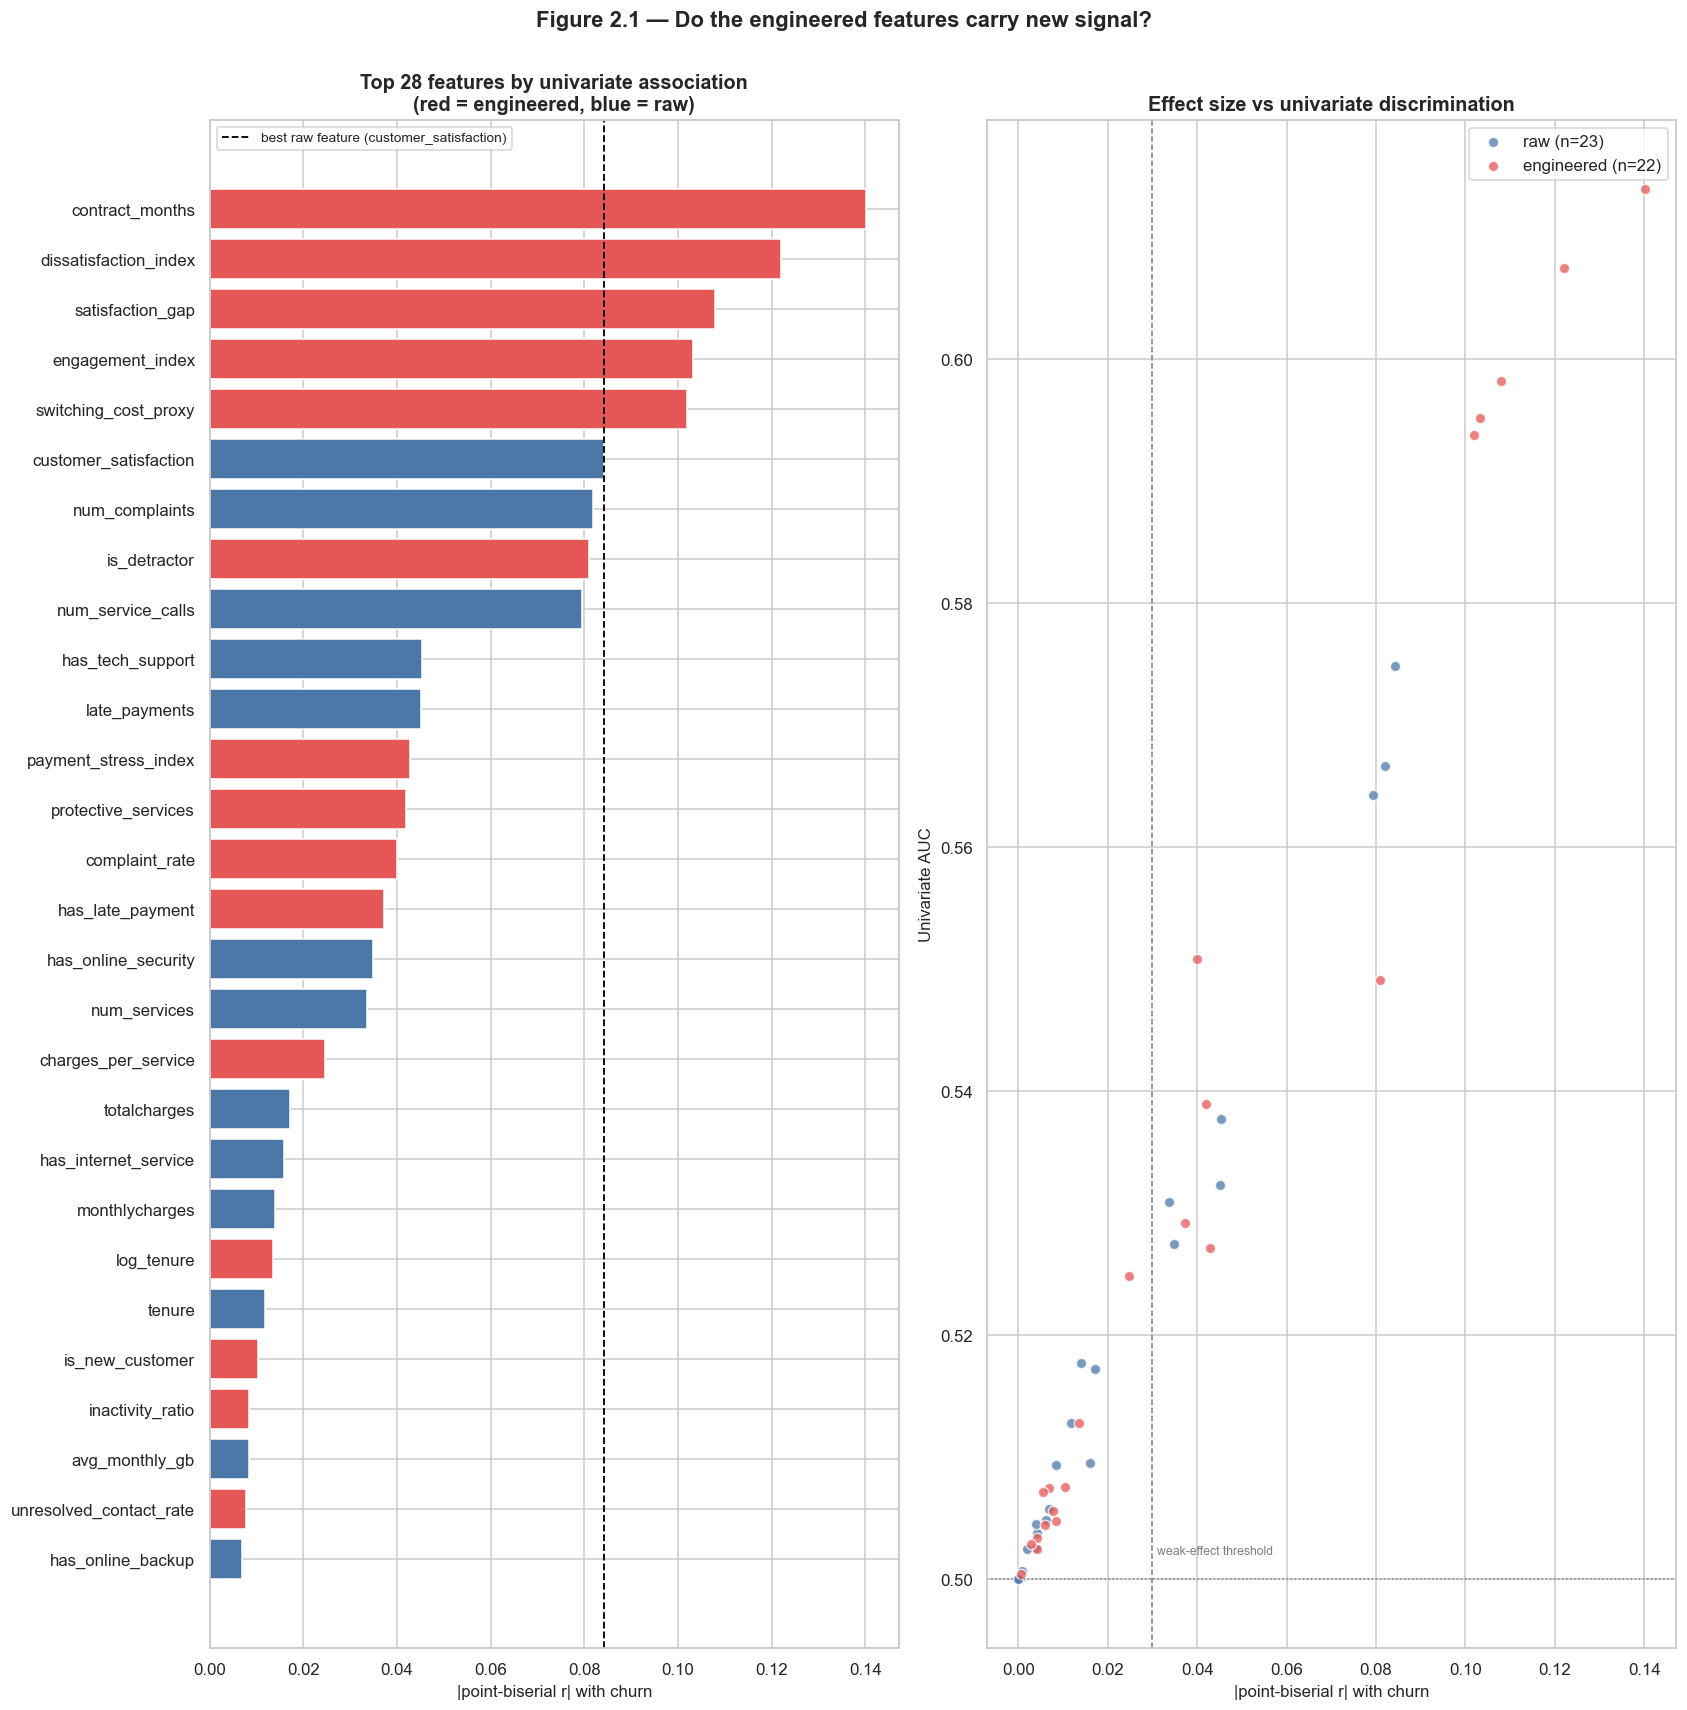

Median |r| by origin:
            median    max  count
origin                          
engineered  0.0191 0.1402     22
raw         0.0083 0.0842     23


In [29]:
# ---- Where the engineered features land in the combined ranking ------------
fig, axes = plt.subplots(1, 2, figsize=(15.5, 0.30 * len(SIGNAL_ALL) + 2))

_top = SIGNAL_ALL.head(28)
axes[0].barh(_top.feature, _top.abs_r,
             color=[C_CHURN if o == "engineered" else C_STAY for o in _top.origin])
axes[0].axvline(BEST_RAW_ABS_R, color="black", ls="--", lw=1.2,
                label=f"best raw feature ({BEST_RAW_NAME})")
axes[0].invert_yaxis()
axes[0].set_xlabel("|point-biserial r| with churn")
axes[0].set_title("Top 28 features by univariate association\n"
                  "(red = engineered, blue = raw)")
axes[0].legend(fontsize=9)

# A two-sample view: is the engineered distribution shifted upward overall?
for origin, colour in [("raw", C_STAY), ("engineered", C_CHURN)]:
    sub = SIGNAL_ALL[SIGNAL_ALL.origin == origin]
    axes[1].scatter(sub.abs_r, sub.univariate_auc, s=46, alpha=0.75,
                    color=colour, label=f"{origin} (n={len(sub)})", edgecolors="white")
axes[1].axhline(0.5, color="grey", ls=":", lw=1)
axes[1].axvline(0.03, color="grey", ls="--", lw=1)
axes[1].text(0.031, 0.502, "weak-effect threshold", fontsize=8, color="grey")
axes[1].set_xlabel("|point-biserial r| with churn")
axes[1].set_ylabel("Univariate AUC")
axes[1].set_title("Effect size vs univariate discrimination")
axes[1].legend()

fig.suptitle("Figure 2.1 — Do the engineered features carry new signal?",
             fontweight="semibold", y=1.002)
savefig("fig_2_1_engineered_signal")
plt.show()

print("Median |r| by origin:")
print(SIGNAL_ALL.groupby("origin").abs_r.agg(["median", "max", "count"]).round(4))

### Step 2.3b — Is the shift statistically real, or a ranking artefact?

Comparing two medians by eye is not evidence. A Mann–Whitney U test asks whether
the engineered |r| values are drawn from a distribution shifted above the raw
ones, and the rank-biserial correlation reports how large that shift is.

In [30]:
# ---- Two-sample test on the |r| distributions -------------------------------
from scipy.stats import mannwhitneyu

_raw_r = SIGNAL_ALL.loc[SIGNAL_ALL.origin == "raw", "abs_r"].to_numpy()
_eng_r = SIGNAL_ALL.loc[SIGNAL_ALL.origin == "engineered", "abs_r"].to_numpy()

_u, _p = mannwhitneyu(_eng_r, _raw_r, alternative="greater")
# Rank-biserial correlation is the effect size that accompanies Mann-Whitney U.
_rank_biserial = 2 * _u / (len(_eng_r) * len(_raw_r)) - 1

FE_SIGNAL_TEST = pd.DataFrame([{
    "n_raw": len(_raw_r),
    "n_engineered": len(_eng_r),
    "median_abs_r_raw": round(float(np.median(_raw_r)), 4),
    "median_abs_r_engineered": round(float(np.median(_eng_r)), 4),
    "mannwhitney_u": float(_u),
    "p_value_one_sided": float(_p),
    "rank_biserial_effect": round(float(_rank_biserial), 4),
    "verdict": ("engineered features are systematically stronger"
                if _p < 0.05 else "no systematic shift detected"),
}]).T.rename(columns={0: "value"})
FE_SIGNAL_TEST

,value
n_raw,23
n_engineered,22
median_abs_r_raw,0.0083
median_abs_r_engineered,0.0191
mannwhitney_u,327.0000
p_value_one_sided,0.0476
rank_biserial_effect,0.2925
verdict,engineered features are systematically stronger


## 2.4 Do they improve a *model*, not just a correlation?

Univariate association is necessary but not sufficient: a feature can correlate
with churn and still add nothing once the raw features are already in the model.
The decisive test is **incremental discrimination**.

A fast, honest version is run here — a regularised Logistic Regression under
stratified 3-fold cross-validation on a subsample, fitted once with raw features
only and once with raw plus engineered features. The full six-model version of
this comparison is **Experiment A versus Experiment B** in Parts 5 and 6; this
cell is the early read that justifies carrying the engineered set forward at all.

### Step 2.4 — Cross-validated AUC lift from adding the engineered block

In [31]:
# ---- Incremental-value test: raw features vs raw + engineered --------------
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score


def quick_lr_pipeline(numeric_cols, categorical_cols):
    """A minimal leakage-safe LR pipeline used only for the §2.4 screening test.

    Every fitted step lives inside the pipeline, so cross_val_score refits it on
    each training fold and the validation fold stays untouched.
    """
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), numeric_cols),
            ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                       drop="first",
                                                       sparse_output=False))]),
             categorical_cols),
        ], remainder="drop")),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                   random_state=RANDOM_STATE)),
    ])


_screen = df_fe.sample(min(120_000, len(df_fe)), random_state=RANDOM_STATE)
_y_screen = _screen[TARGET]
_cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


def _split_roles(cols):
    numeric = [c for c in cols if pd.api.types.is_numeric_dtype(df_fe[c])]
    categorical = [c for c in cols if c not in numeric]
    return numeric, categorical


_raw_only = [c for c in df_fe.columns if c not in ENGINEERED_COLS and c != TARGET]
_with_eng = [c for c in df_fe.columns if c != TARGET]

INCREMENTAL = []
for label, cols in [("raw features only", _raw_only),
                    ("raw + engineered", _with_eng)]:
    num_c, cat_c = _split_roles(cols)
    scores = cross_val_score(quick_lr_pipeline(num_c, cat_c), _screen[cols], _y_screen,
                             cv=_cv3, scoring="roc_auc", n_jobs=1,
                             error_score="raise")
    INCREMENTAL.append({"feature_set": label, "n_features": len(cols),
                        "cv_auc_mean": scores.mean(), "cv_auc_std": scores.std()})

INCREMENTAL = pd.DataFrame(INCREMENTAL)
_lift = INCREMENTAL.cv_auc_mean.iloc[1] - INCREMENTAL.cv_auc_mean.iloc[0]
FE_AUC_LIFT = float(_lift)

print(f"Incremental AUC from the engineered block: {_lift:+.4f}")
print(f"Relative to the fold-to-fold standard deviation "
      f"({INCREMENTAL.cv_auc_std.max():.4f}): "
      f"{_lift / (INCREMENTAL.cv_auc_std.max() + EPS):.1f}x")
INCREMENTAL.round(5)

Incremental AUC from the engineered block: +0.0001
Relative to the fold-to-fold standard deviation (0.0030): 0.0x


,feature_set,n_features,cv_auc_mean,cv_auc_std
0,raw features only,29,0.6898,0.0030
1,raw + engineered,52,0.6899,0.0030


## 2.5 Multicollinearity among the engineered features

Engineered features are collinear with their own inputs **by construction** —
`log_tenure` is a monotone transform of `tenure`, `contract_months` re-encodes
`contract`, `switching_cost_proxy` is built from `num_services`. Left unchecked
this would:

- destabilise the Logistic Regression coefficients, making the §7.8 interpretation
  of the likely champion unreliable;
- split SHAP attribution arbitrarily between duplicated features, which would
  invalidate the Part 10 feature-importance validation;
- inflate the feature count with no information gain.

The screen is therefore run **on the combined raw + engineered set**, and its
findings are **acted upon**: redundant features are pruned before any model is
trained.

### Step 2.5a — Correlation structure of the combined feature set

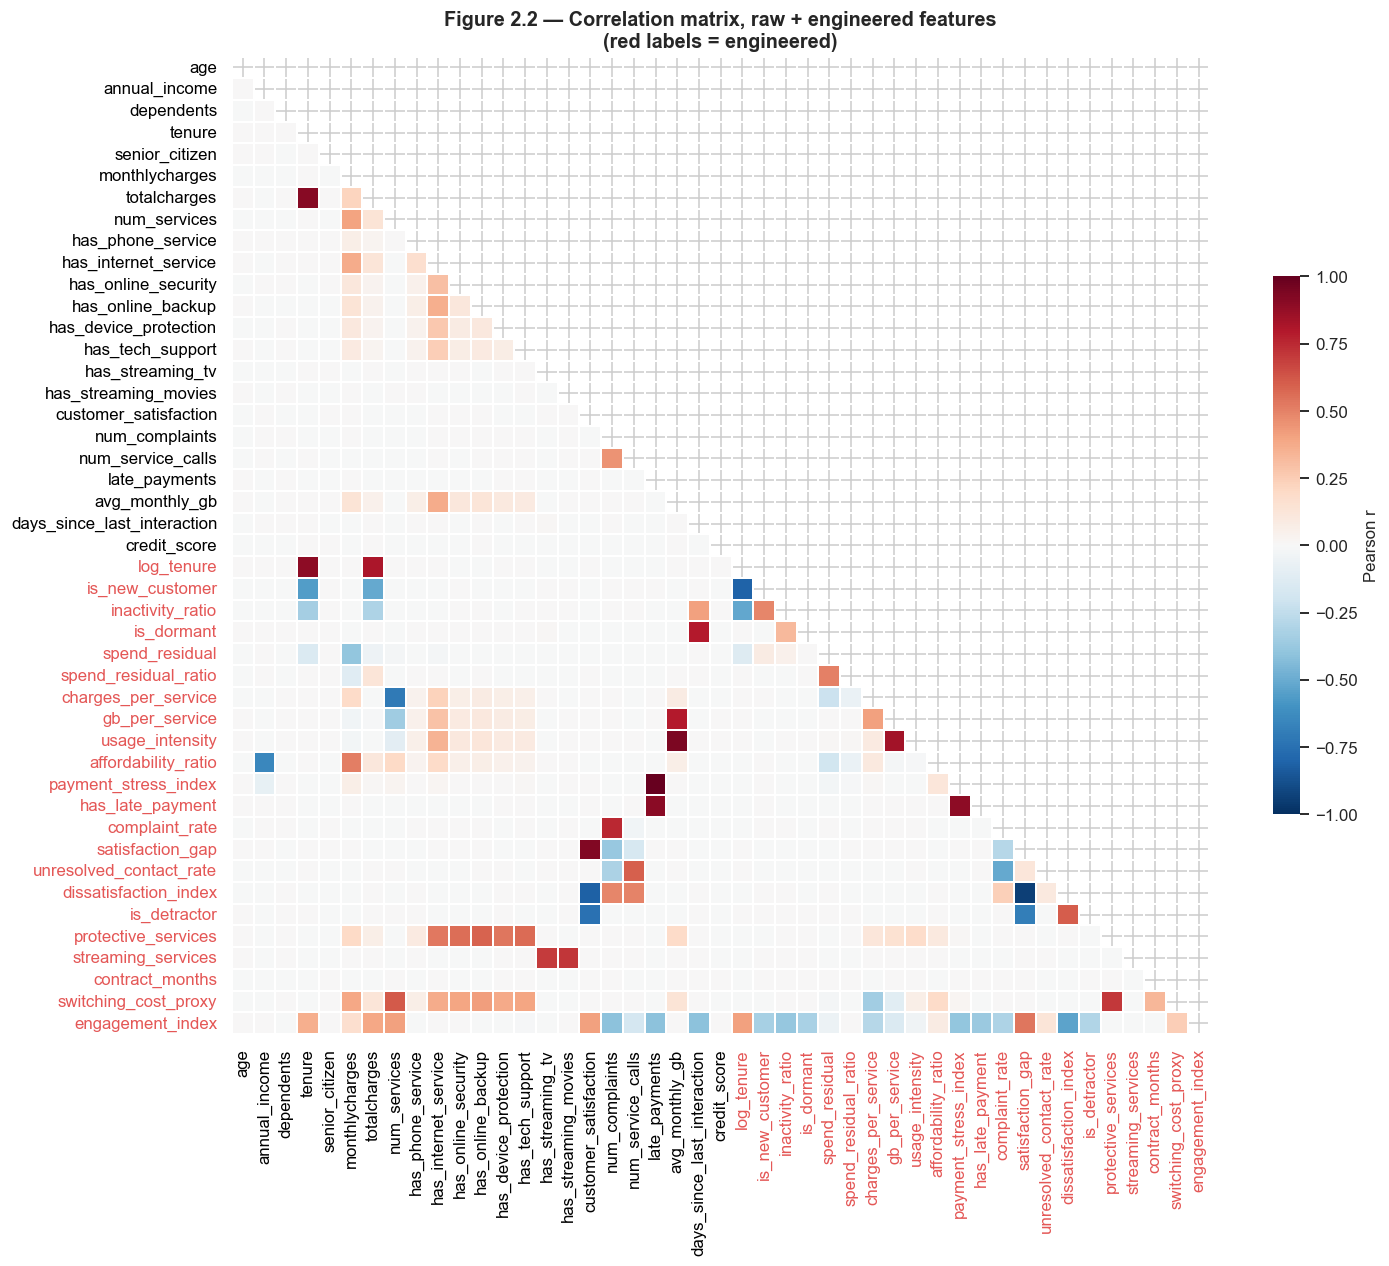

In [32]:
# ---- Correlation matrix over raw + engineered numeric features -------------
_numeric_all = [c for c in df_fe.columns
                if c != TARGET and pd.api.types.is_numeric_dtype(df_fe[c])]

# Correlation is stable well below the full row count; sampling keeps this cell
# to a few seconds at 1M rows.
_corr_sample = df_fe[_numeric_all].sample(min(200_000, len(df_fe)),
                                          random_state=RANDOM_STATE)
CORR_FE = _corr_sample.corr(numeric_only=True)

_is_eng = [c in ENGINEERED_COLS for c in CORR_FE.columns]
_mask = np.triu(np.ones_like(CORR_FE, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 11.5))
sns.heatmap(CORR_FE, mask=_mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.25,
            cbar_kws={"shrink": 0.55, "label": "Pearson r"}, ax=ax)
# Mark the engineered features so the new collinearity is visually separable.
for tick, eng in zip(ax.get_yticklabels(), _is_eng):
    tick.set_color(C_CHURN if eng else "black")
for tick, eng in zip(ax.get_xticklabels(), _is_eng):
    tick.set_color(C_CHURN if eng else "black")
ax.set_title("Figure 2.2 — Correlation matrix, raw + engineered features\n"
             "(red labels = engineered)")
savefig("fig_2_2_corr_engineered")
plt.show()

In [33]:
# ---- Flag every strongly collinear pair involving an engineered feature ----
_pairs = (CORR_FE.where(~_mask).stack().rename("r").reset_index()
          .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
_pairs["abs_r"] = _pairs.r.abs()
_pairs["involves_engineered"] = (_pairs.feature_a.isin(ENGINEERED_COLS)
                                 | _pairs.feature_b.isin(ENGINEERED_COLS))

COLLINEAR_PAIRS = (_pairs[_pairs.abs_r > 0.90]
                   .sort_values("abs_r", ascending=False).reset_index(drop=True))
print(f"Pairs with |r| > 0.90: {len(COLLINEAR_PAIRS)} "
      f"({int(COLLINEAR_PAIRS.involves_engineered.sum())} involve an engineered feature)")
COLLINEAR_PAIRS.round(4)

Pairs with |r| > 0.90: 6 (5 involve an engineered feature)


,feature_a,feature_b,r,abs_r,involves_engineered
0,payment_stress_index,late_payments,0.9924,0.9924,True
1,usage_intensity,avg_monthly_gb,0.9442,0.9442,True
2,dissatisfaction_index,satisfaction_gap,-0.9403,0.9403,True
3,satisfaction_gap,customer_satisfaction,0.9256,0.9256,True
4,totalcharges,tenure,0.9129,0.9129,False
5,has_late_payment,late_payments,0.9020,0.9020,True


### Step 2.5b — Prune redundant features by a stated, reproducible rule

The pruning rule is deliberately simple and auditable:

> For each pair with |r| > 0.95, drop the member with the **weaker univariate
> association with churn**, and never drop a raw feature in favour of an
> engineered one — a derived column must earn its place, not displace its own
> input.

Pairs between 0.90 and 0.95 are reported but retained, because L2 regularisation
and tree ensembles both tolerate that level; only near-duplicates are removed.

In [34]:
# ---- Apply the pruning rule -------------------------------------------------
PRUNE_THRESHOLD = 0.95
_signal_lookup = SIGNAL_ALL.set_index("feature")["abs_r"].to_dict()

prune_log = []
dropped = set()

for _, row in COLLINEAR_PAIRS[COLLINEAR_PAIRS.abs_r > PRUNE_THRESHOLD].iterrows():
    a, b = row.feature_a, row.feature_b
    if a in dropped or b in dropped:
        continue

    a_eng, b_eng = a in ENGINEERED_COLS, b in ENGINEERED_COLS
    if a_eng != b_eng:
        # A raw feature always survives against its own derivative.
        drop, keep, reason = (a, b, "engineered duplicate of a raw feature") if a_eng \
            else (b, a, "engineered duplicate of a raw feature")
    else:
        # Same origin: keep whichever carries more univariate signal.
        if _signal_lookup.get(a, 0) >= _signal_lookup.get(b, 0):
            drop, keep, reason = b, a, "weaker univariate association within the pair"
        else:
            drop, keep, reason = a, b, "weaker univariate association within the pair"

    dropped.add(drop)
    prune_log.append({"dropped": drop, "kept": keep, "abs_r": round(row.abs_r, 4),
                      "|r| with churn (dropped)": round(_signal_lookup.get(drop, np.nan), 4),
                      "|r| with churn (kept)": round(_signal_lookup.get(keep, np.nan), 4),
                      "reason": reason})

PRUNE_LOG = pd.DataFrame(prune_log)
PRUNED_FEATURES = sorted(dropped)

print(f"Pruning threshold |r| > {PRUNE_THRESHOLD}")
print(f"Features removed: {len(PRUNED_FEATURES)}")
PRUNE_LOG if len(PRUNE_LOG) else print("No feature pairs exceeded the pruning threshold.")

Pruning threshold |r| > 0.95
Features removed: 1


,dropped,kept,abs_r,|r| with churn (dropped),|r| with churn (kept),reason
0,payment_stress_index,late_payments,0.9924,0.0428,0.0451,engineered duplicate of a raw feature


### Step 2.5c — Variance inflation factors after the pairwise pass

Pairwise correlation only detects two-way redundancy. A feature can be weakly
correlated with every other one individually and still be an almost exact linear
combination of several together — which is precisely what a composite index such
as `switching_cost_proxy` or `dissatisfaction_index` is. VIF catches that, so it
is computed on the engineered block before and after the pairwise pass.

In [35]:
# ---- VIF on the engineered block ------------------------------------------
def vif_on(cols, sample_n=40_000):
    """VIF for a set of numeric columns, computed on a standardised sample."""
    usable = [c for c in cols if pd.api.types.is_numeric_dtype(df_fe[c])
              and df_fe[c].nunique() > 1]
    x = (df_fe[usable].sample(min(sample_n, len(df_fe)), random_state=RANDOM_STATE)
                      .astype("float64").fillna(df_fe[usable].median()))
    x = (x - x.mean()) / (x.std() + EPS)
    return pd.DataFrame({
        "feature": usable,
        "VIF": [variance_inflation_factor(x.values, i) for i in range(x.shape[1])],
    }).sort_values("VIF", ascending=False).reset_index(drop=True)


ENGINEERED_NUMERIC = [c for c in ENGINEERED_COLS
                      if pd.api.types.is_numeric_dtype(df_fe[c])]

VIF_BEFORE = vif_on(ENGINEERED_NUMERIC)
VIF_PAIRWISE = vif_on([c for c in ENGINEERED_NUMERIC if c not in PRUNED_FEATURES])

print(f"Max VIF, all engineered features        : {VIF_BEFORE.VIF.max():,.1f}")
print(f"Max VIF, after the pairwise pass        : {VIF_PAIRWISE.VIF.max():,.1f}")
print(f"Features above the VIF > 10 threshold   : "
      f"{int((VIF_BEFORE.VIF > 10).sum())} -> {int((VIF_PAIRWISE.VIF > 10).sum())}")
VIF_BEFORE.round(2)

Max VIF, all engineered features        : 20.1
Max VIF, after the pairwise pass        : 19.4
Features above the VIF > 10 threshold   : 3 -> 2


,feature,VIF
0,dissatisfaction_index,20.0600
1,satisfaction_gap,19.3900
2,engagement_index,11.4100
3,switching_cost_proxy,9.7500
4,protective_services,6.2300
5,payment_stress_index,6.0300
6,gb_per_service,5.4900
7,log_tenure,4.7200
8,usage_intensity,4.6400
9,has_late_payment,4.6300


### Step 2.5d — Iterative VIF elimination on what remains

The pairwise pass removes duplicates but not multi-way redundancy, so features
above the conventional VIF > 10 threshold survive it. Those are removed here by
standard iterative elimination, under two constraints that keep the procedure
from destroying the signal it is meant to protect:

> Repeatedly drop the **engineered** feature with the highest VIF until none
> exceeds 10. Never drop a raw feature — a derived column must not displace its
> own input — and never drop a feature ranked in the **top ten by univariate
> association with churn**, since collinearity is a nuisance to be managed, not
> a reason to discard the study's strongest predictors.

In [36]:
# ---- Iterative VIF elimination, restricted to engineered features ---------
VIF_LIMIT = 10.0
PROTECTED_FEATURES = set(SIGNAL_ALL.head(10).feature)

_remaining = [c for c in ENGINEERED_NUMERIC if c not in PRUNED_FEATURES]
_vif_log = []

while True:
    vif_now = vif_on(_remaining)
    over = vif_now[(vif_now.VIF > VIF_LIMIT)
                   & (~vif_now.feature.isin(PROTECTED_FEATURES))]
    if over.empty:
        break
    worst = over.iloc[0]
    _remaining.remove(worst.feature)
    _vif_log.append({"dropped": worst.feature, "VIF_at_removal": round(worst.VIF, 2),
                     "|r| with churn": round(_signal_lookup.get(worst.feature, np.nan), 4),
                     "features_left": len(_remaining)})

VIF_PRUNE_LOG = pd.DataFrame(_vif_log)
PRUNED_FEATURES = sorted(set(PRUNED_FEATURES) | {r["dropped"] for r in _vif_log})
VIF_AFTER = vif_on(_remaining)

_still_high = VIF_AFTER[VIF_AFTER.VIF > VIF_LIMIT]
print(f"Iterative elimination removed {len(_vif_log)} further feature(s).")
print(f"Max VIF now: {VIF_AFTER.VIF.max():,.2f}")
if len(_still_high):
    print(f"Retained above the threshold because they are protected predictors: "
          f"{_still_high.feature.tolist()}")
print(f"\nTotal engineered features pruned: {len(PRUNED_FEATURES)} of "
      f"{len(ENGINEERED_COLS)}  ->  {PRUNED_FEATURES}")
VIF_PRUNE_LOG if len(VIF_PRUNE_LOG) else print("No feature exceeded the VIF threshold.")

Iterative elimination removed 0 further feature(s).
Max VIF now: 19.39
Retained above the threshold because they are protected predictors: ['satisfaction_gap', 'dissatisfaction_index']

Total engineered features pruned: 1 of 23  ->  ['payment_stress_index']
No feature exceeded the VIF threshold.


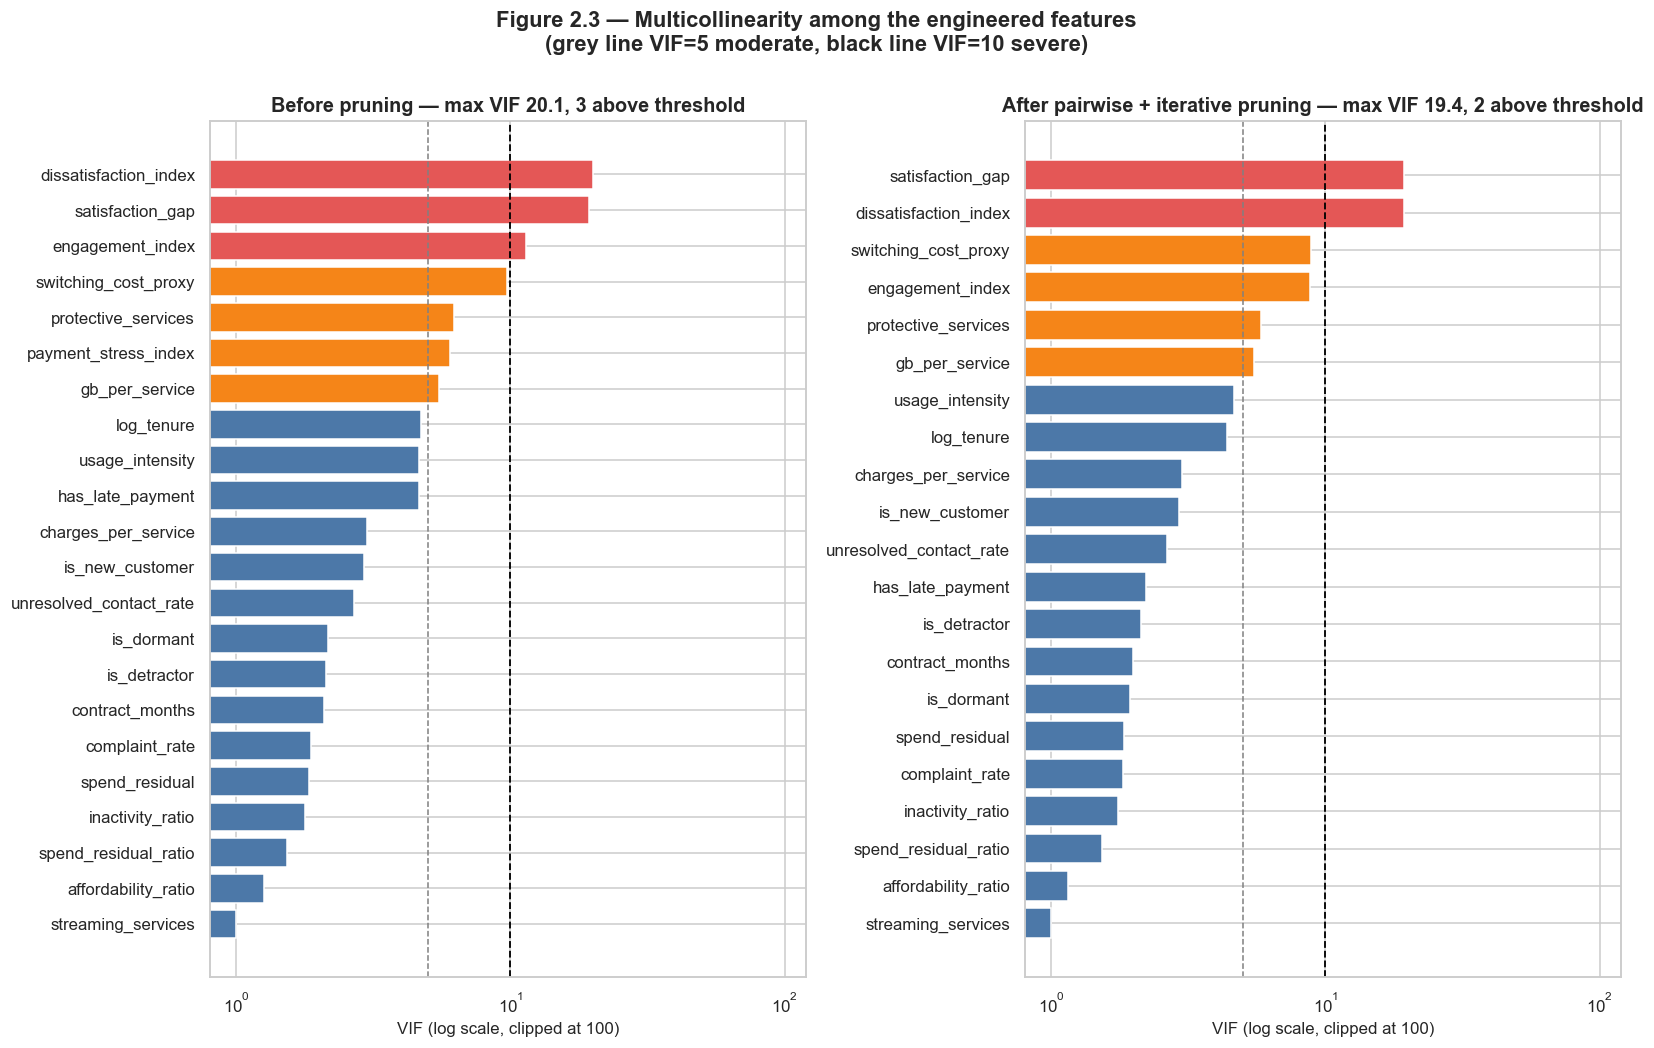

In [37]:
# ---- Visualise the collinearity reduction ---------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 0.34 * len(VIF_BEFORE) + 2))

for ax, table, title in [(axes[0], VIF_BEFORE, "Before pruning"),
                         (axes[1], VIF_AFTER, "After pairwise + iterative pruning")]:
    colours = [C_CHURN if v > 10 else (C_DL if v > 5 else C_STAY) for v in table.VIF]
    ax.barh(table.feature, table.VIF.clip(upper=100), color=colours)
    ax.axvline(5, color="grey", ls="--", lw=1)
    ax.axvline(10, color="black", ls="--", lw=1.2)
    ax.invert_yaxis()
    ax.set_xscale("log")
    ax.set_xlim(0.8, 120)
    ax.set_xlabel("VIF (log scale, clipped at 100)")
    ax.set_title(f"{title} — max VIF {table.VIF.max():,.1f}, "
                 f"{int((table.VIF > 10).sum())} above threshold")

fig.suptitle("Figure 2.3 — Multicollinearity among the engineered features\n"
             "(grey line VIF=5 moderate, black line VIF=10 severe)",
             fontweight="semibold", y=1.003)
savefig("fig_2_3_vif_engineered")
plt.show()

## 2.6 Freezing the two feature sets

Parts 5 and 6 compare models on **exactly two** feature sets, defined once here
and never modified again. This is what makes the Experiment A → B contrast a
clean measurement of the value of feature engineering rather than a confound.

### Step 2.6 — Define `BASELINE_FEATURES` and `ENGINEERED_FEATURES`

In [38]:
# ---- Freeze the two feature sets used by every later experiment ------------
# Baseline set: the raw schema exactly as delivered, minus the two columns the
# EDA condemned outright (an identifier, and a date field that is internally
# inconsistent). Nothing else is removed, so this is an honest raw baseline.
BASELINE_FEATURES = [c for c in df_fe.columns
                     if c not in ENGINEERED_COLS and c != TARGET]

# Engineered set: the baseline plus the surviving engineered features.
ENGINEERED_FEATURES = BASELINE_FEATURES + [c for c in ENGINEERED_COLS
                                           if c not in PRUNED_FEATURES]


def feature_roles(cols):
    """Split a feature list into numeric and categorical roles for the pipeline."""
    numeric = [c for c in cols if pd.api.types.is_numeric_dtype(df_fe[c])]
    categorical = [c for c in cols if c not in numeric]
    return numeric, categorical


NUM_BASELINE, CAT_BASELINE = feature_roles(BASELINE_FEATURES)
NUM_ENGINEERED, CAT_ENGINEERED = feature_roles(ENGINEERED_FEATURES)

FEATURE_SETS = {
    "baseline": dict(features=BASELINE_FEATURES,
                     numeric=NUM_BASELINE, categorical=CAT_BASELINE),
    "engineered": dict(features=ENGINEERED_FEATURES,
                       numeric=NUM_ENGINEERED, categorical=CAT_ENGINEERED),
}

# Features whose distribution justifies winsorisation (§1.3: heavy right tails).
# The bounds themselves are FITTED, so they are computed per fold in Part 3.
WINSORISE_COLS = [c for c in ["monthlycharges", "totalcharges", "avg_monthly_gb",
                              "annual_income", "spend_residual", "charges_per_service",
                              "gb_per_service", "usage_intensity", "affordability_ratio",
                              "inactivity_ratio", "spend_residual_ratio"]
                  if c in ENGINEERED_FEATURES]

print(f"BASELINE_FEATURES   : {len(BASELINE_FEATURES):>3} "
      f"({len(NUM_BASELINE)} numeric, {len(CAT_BASELINE)} categorical)")
print(f"ENGINEERED_FEATURES : {len(ENGINEERED_FEATURES):>3} "
      f"({len(NUM_ENGINEERED)} numeric, {len(CAT_ENGINEERED)} categorical)")
print(f"Engineered features retained: "
      f"{len(ENGINEERED_COLS) - len(PRUNED_FEATURES)} of {len(ENGINEERED_COLS)}")
print(f"Pruned for collinearity     : {PRUNED_FEATURES or 'none'}")
print(f"Winsorised (bounds fitted per fold): {WINSORISE_COLS}")

BASELINE_FEATURES   :  29 (23 numeric, 6 categorical)
ENGINEERED_FEATURES :  51 (44 numeric, 7 categorical)
Engineered features retained: 22 of 23
Pruned for collinearity     : ['payment_stress_index']
Winsorised (bounds fitted per fold): ['monthlycharges', 'totalcharges', 'avg_monthly_gb', 'annual_income', 'spend_residual', 'charges_per_service', 'gb_per_service', 'usage_intensity', 'affordability_ratio', 'inactivity_ratio', 'spend_residual_ratio']


In [39]:
# ---- Consolidated Part 2 verdict -------------------------------------------
FE_VERDICT = pd.DataFrame([
    ("Features derived", f"{len(ENGINEERED_COLS)} across the five §7.3 groups"),
    ("Integrity", "all finite, none constant, all correctly typed (§2.2)"),
    ("Strongest engineered feature",
     f"{SIGNAL_ENG.feature.iloc[0]} (|r| = {SIGNAL_ENG.abs_r.iloc[0]:.4f})"),
    ("Strongest raw feature", f"{BEST_RAW_NAME} (|r| = {BEST_RAW_ABS_R:.4f})"),
    ("Engineered beating best raw",
     f"{int(SIGNAL_ENG_RANKED.beats_best_raw.sum())} of {len(SIGNAL_ENG_RANKED)}"),
    ("Distribution shift (Mann-Whitney)",
     f"p = {_p:.3g}, rank-biserial = {_rank_biserial:.3f}"),
    ("Incremental CV AUC (LR screen)", f"{FE_AUC_LIFT:+.4f}"),
    ("Collinear pairs |r| > 0.90", f"{len(COLLINEAR_PAIRS)}"),
    ("Features pruned (pairwise + VIF)",
     f"{len(PRUNED_FEATURES)}: {PRUNED_FEATURES or 'none'}"),
    ("Max VIF, engineered block",
     f"{VIF_BEFORE.VIF.max():,.1f} -> {VIF_AFTER.VIF.max():,.1f}"),
    ("Features above VIF 10",
     f"{int((VIF_BEFORE.VIF > 10).sum())} -> {int((VIF_AFTER.VIF > 10).sum())}"),
    ("Carried forward", f"{len(BASELINE_FEATURES)} baseline vs "
                        f"{len(ENGINEERED_FEATURES)} engineered features"),
], columns=["check", "result"])
FE_VERDICT

,check,result
0,Features derived,23 across the five §7.3 groups
1,Integrity,"all finite, none constant, all correctly typed..."
2,Strongest engineered feature,contract_months (|r| = 0.1402)
3,Strongest raw feature,customer_satisfaction (|r| = 0.0842)
4,Engineered beating best raw,5 of 22
5,Distribution shift (Mann-Whitney),"p = 0.0476, rank-biserial = 0.292"
6,Incremental CV AUC (LR screen),+0.0001
7,Collinear pairs |r| > 0.90,6
8,Features pruned (pairwise + VIF),1: ['payment_stress_index']
9,"Max VIF, engineered block",20.1 -> 19.4


---
# Part 3 — Stratified partitioning and leakage-safe preprocessing (§7.2, §7.4)

Everything in this part exists to guarantee one property:

> **No information from a validation or test row may influence the transform
> applied to it.**

That is stronger than "split the data first", and it is where most published
churn pipelines quietly fail. Three classes of leakage are prevented explicitly:

| Leak | How it happens | Prevention here |
|---|---|---|
| **Statistic leakage** | Imputation medians, winsorisation bounds or scaler means computed on all rows | Every fitted statistic is computed inside `fit()` on the training fold only (§3.3) |
| **Vocabulary leakage** | One-hot encoder sees categories present only in validation | `OneHotEncoder(handle_unknown="ignore")` fitted per fold (§3.3) |
| **Resampling leakage** | SMOTE / GAN oversampling applied before splitting, so synthetic points interpolated from validation rows end up in training | Resampling happens *inside* `fit()`, after the split, on the training fold only (§3.4) — and §3.6 measures what the alternative would have cost |

The consequence is that a single estimator object encapsulates the whole
pipeline, so `cross_val_score`, `GridSearchCV` and `RandomizedSearchCV` all
refit the preprocessing per fold automatically and cannot be misused.

## 3.1 The stratified hold-out split

### Step 3.1 — Split 80/20 with stratification, then verify the stratification held

The test partition is created **now**, before any model exists, and is not read
again until Part 11. Stratification keeps the ≈9.9% churn rate of EDA finding 2
identical in both partitions, which matters at this imbalance: an unstratified
split would leave the two partitions with materially different base rates and
make the final numbers incomparable.

In [40]:
# ---- Stratified 80/20 train / test split (§7.4) ----------------------------
from sklearn.model_selection import train_test_split

X_all = df_fe[ENGINEERED_FEATURES].copy()
y_all = df_fe[TARGET].astype(np.int8).copy()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_all, y_all,
    test_size=TEST_SIZE,
    stratify=y_all,
    random_state=RANDOM_STATE,
)

SPLIT_AUDIT = pd.DataFrame([
    {"partition": "train", "n_rows": len(y_train_full),
     "n_churn": int(y_train_full.sum()), "churn_rate": y_train_full.mean()},
    {"partition": "test (held out)", "n_rows": len(y_test),
     "n_churn": int(y_test.sum()), "churn_rate": y_test.mean()},
    {"partition": "full", "n_rows": len(y_all),
     "n_churn": int(y_all.sum()), "churn_rate": y_all.mean()},
])

# Stratification is only credible if it is checked, not assumed.
_rate_gap = abs(y_train_full.mean() - y_test.mean())
assert _rate_gap < 1e-3, f"Stratification failed: churn-rate gap {_rate_gap:.5f}"
assert len(set(X_train_full.index) & set(X_test.index)) == 0, "Train/test rows overlap."

print(f"Churn-rate gap between partitions: {_rate_gap:.6f}  (stratification verified)")
print("No row appears in both partitions.  (verified)")
SPLIT_AUDIT.round(5)

Churn-rate gap between partitions: 0.000003  (stratification verified)
No row appears in both partitions.  (verified)


,partition,n_rows,n_churn,churn_rate
0,train,800000,79382,0.0992
1,test (held out),200000,19845,0.0992
2,full,1000000,99227,0.0992


### Step 3.2 — Draw the development subsample used by Experiments A, B and C

Per the compute protocol stated at the top of the notebook, model development
runs on a stratified subsample **of the training partition**. The subsample is
drawn from `X_train_full` only, so the held-out test partition remains entirely
unseen. The champion is refit on the full training partition in Part 11.

In [41]:
# ---- Stratified development and tuning subsamples --------------------------
def stratified_subsample(X, y, n, seed=RANDOM_STATE):
    """Draw a stratified subsample preserving the class ratio exactly."""
    if n >= len(y):
        return X.copy(), y.copy()
    idx, _ = train_test_split(np.arange(len(y)), train_size=n,
                              stratify=y, random_state=seed)
    return X.iloc[idx].copy(), y.iloc[idx].copy()


X_dev, y_dev = stratified_subsample(X_train_full, y_train_full, DEV_SAMPLE_N)
X_tune, y_tune = stratified_subsample(X_dev, y_dev, TUNE_SAMPLE_N)

SUBSAMPLE_AUDIT = pd.DataFrame([
    {"set": "train (full)", "n": len(y_train_full), "churn_rate": y_train_full.mean(),
     "used_for": "final refit of champion and DL competitors (Part 11)"},
    {"set": "dev subsample", "n": len(y_dev), "churn_rate": y_dev.mean(),
     "used_for": "Experiments A and B, significance testing (Parts 5, 6, 9)"},
    {"set": "tune subsample", "n": len(y_tune), "churn_rate": y_tune.mean(),
     "used_for": "Grid / Random / Optuna searches (Part 7)"},
    {"set": "test (held out)", "n": len(y_test), "churn_rate": y_test.mean(),
     "used_for": "final unbiased evaluation only (Part 11)"},
])
SUBSAMPLE_AUDIT.round(5)

,set,n,churn_rate,used_for
0,train (full),800000,0.0992,final refit of champion and DL competitors (Pa...
1,dev subsample,200000,0.0992,"Experiments A and B, significance testing (Par..."
2,tune subsample,100000,0.0992,Grid / Random / Optuna searches (Part 7)
3,test (held out),200000,0.0992,final unbiased evaluation only (Part 11)


## 3.3 The leakage-safe estimator

### Step 3.3a — Winsorisation as a *fitted* transform

§1.3 showed heavy right tails (`monthlycharges` has p75 = 100.7 but a maximum of
855). Winsorisation caps them — but the caps are **percentiles estimated from
data**, which makes winsorisation a fitted transform, not a row-wise one. It
therefore belongs inside the fold, and is implemented as a proper transformer
rather than applied up front.

In [42]:
# ---- Winsoriser: percentile caps learned on the training fold only ---------
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone


class Winsoriser(BaseEstimator, TransformerMixin):
    """Clip selected columns at percentile bounds learned during `fit`.

    Only the column positions listed in `indices` are affected, so the same
    transformer can sit inside a numeric pipeline that also carries columns
    which must not be capped (binary flags, counts).
    """

    def __init__(self, indices=(), lower=0.01, upper=0.99):
        self.indices = indices
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lower_bounds_, self.upper_bounds_ = {}, {}
        for j in self.indices:
            col = X[:, j]
            col = col[np.isfinite(col)]
            if col.size:
                self.lower_bounds_[j] = float(np.quantile(col, self.lower))
                self.upper_bounds_[j] = float(np.quantile(col, self.upper))
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        for j, lo in self.lower_bounds_.items():
            X[:, j] = np.clip(X[:, j], lo, self.upper_bounds_[j])
        return X

    def get_feature_names_out(self, input_features=None):
        # Winsorisation clips values without adding, removing or reordering
        # columns, so names pass straight through. Providing this keeps the
        # enclosing ColumnTransformer introspectable, which Part 10 relies on
        # to label SHAP values.
        return np.asarray(input_features, dtype=object)


print("Winsoriser defined — bounds are learned in fit(), so they stay inside the fold.")

Winsoriser defined — bounds are learned in fit(), so they stay inside the fold.


### Step 3.3b — The GAN oversampling worker (§7.2)

§7.2 evaluates GAN-based oversampling alongside SMOTE. CTGAN is built on
PyTorch, whose OpenMP runtime conflicts with the one already loaded by
scikit-learn, XGBoost and TensorFlow in the same process — on this hardware the
in-process version segfaults the kernel.

The generator is therefore trained in a **separate interpreter**, exchanging
arrays through `.npy` files. This isolates the runtime conflict and means a
crash inside the GAN cannot take the notebook down with it. If the worker is
unavailable the arm falls back to SMOTE and says so, rather than failing
silently.

In [43]:
# ---- Write the isolated CTGAN worker to disk -------------------------------
CTGAN_WORKER_PATH = "ctgan_worker_v2.py"

CTGAN_WORKER_SOURCE = """
# Fit a CTGAN on minority rows and emit synthetic samples.
# Run as a subprocess so PyTorch's OpenMP runtime cannot conflict with the one
# already loaded by scikit-learn / XGBoost / TensorFlow in the parent process,
# and so a crash in here cannot bring down the notebook kernel.
import sys
import numpy as np


def main():
    path_in, path_out, epochs, n_needed, seed = sys.argv[1:6]
    X = np.load(path_in)

    np.random.seed(int(seed))
    import torch
    torch.manual_seed(int(seed))

    import pandas as pd
    from ctgan import CTGAN

    columns = [f"f{i}" for i in range(X.shape[1])]
    generator = CTGAN(epochs=int(epochs), batch_size=500, verbose=False, cuda=False)
    generator.fit(pd.DataFrame(X, columns=columns))
    np.save(path_out, generator.sample(int(n_needed)).to_numpy(dtype=np.float32))


if __name__ == "__main__":
    main()
"""

with open(CTGAN_WORKER_PATH, "w") as fh:
    fh.write(CTGAN_WORKER_SOURCE.lstrip())

print(f"Wrote {CTGAN_WORKER_PATH} ({len(CTGAN_WORKER_SOURCE)} bytes)")

Wrote ctgan_worker_v2.py (858 bytes)


In [44]:
# ---- Preflight: is the isolated GAN trainer actually usable on this machine? -
import subprocess
import tempfile


def run_ctgan_subprocess(X_minority, n_needed, epochs, seed, timeout=1800):
    """Train CTGAN out of process and return `n_needed` synthetic minority rows."""
    with tempfile.TemporaryDirectory() as tmp:
        path_in = os.path.join(tmp, "minority.npy")
        path_out = os.path.join(tmp, "synthetic.npy")
        np.save(path_in, np.asarray(X_minority, dtype=np.float32))

        env = dict(os.environ, KMP_DUPLICATE_LIB_OK="TRUE", OMP_NUM_THREADS="4")
        proc = subprocess.run(
            [sys.executable, CTGAN_WORKER_PATH, path_in, path_out,
             str(int(epochs)), str(int(n_needed)), str(int(seed))],
            capture_output=True, text=True, timeout=timeout, env=env,
        )
        if proc.returncode != 0 or not os.path.exists(path_out):
            raise RuntimeError(f"CTGAN worker failed (exit {proc.returncode}): "
                               f"{proc.stderr[-400:]}")
        return np.load(path_out)


def ctgan_preflight():
    """Cheap end-to-end trial of the GAN arm before committing the full run to it."""
    if not CONFIG["ENABLE_CTGAN"]:
        return False, "disabled in CONFIG"
    try:
        probe = np.random.RandomState(RANDOM_STATE).normal(size=(600, 6)).astype(np.float32)
        out = run_ctgan_subprocess(probe, n_needed=120, epochs=2,
                                   seed=RANDOM_STATE, timeout=600)
        return (out.shape == (120, 6)), f"returned array of shape {out.shape}"
    except Exception as exc:
        return False, f"{type(exc).__name__}: {exc}"


_t0 = time.perf_counter()
CTGAN_AVAILABLE, CTGAN_STATUS = ctgan_preflight()
print(f"CTGAN preflight ({time.perf_counter() - _t0:.1f}s): "
      f"{'AVAILABLE' if CTGAN_AVAILABLE else 'UNAVAILABLE'} — {CTGAN_STATUS}")
if not CTGAN_AVAILABLE:
    print("The GAN arm will fall back to SMOTE and is reported as such.")

CTGAN preflight (10.1s): AVAILABLE — returned array of shape (120, 6)


### Step 3.3c — The estimator that makes leakage structurally impossible

The class below wraps any scikit-learn-compatible classifier and performs, in
this order, **inside `fit()`**:

1. median imputation for numeric features, mode for categorical (§7.2)
2. winsorisation at fold-derived percentiles (§1.3)
3. standardisation to zero mean, unit variance (§7.2)
4. one-hot encoding with `drop="first"` to avoid the dummy trap (§7.2)
5. the selected imbalance treatment (§7.2)
6. fitting the wrapped classifier

`transform`-time steps 1–4 are then replayed on validation or test data using
the **stored** training-fold statistics. Nothing is recomputed at predict time.

> **A note on base-class order.** `ClassifierMixin` **must** precede
> `BaseEstimator`. From scikit-learn 1.6 the estimator type is resolved through
> `__sklearn_tags__`, and the reversed order makes `is_classifier()` return
> `False`. The consequence is silent and severe: `scoring="roc_auc"` then returns
> `NaN` for every fold, so `GridSearchCV` completes "successfully" while
> selecting hyperparameters at random. An assertion below makes that failure
> mode impossible to reintroduce unnoticed.

In [45]:
# ---- The leakage-safe wrapper used by every experiment in this notebook ----
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE
from sklearn.utils.metaestimators import available_if


def _base_estimator_has(attr):
    """Gate a delegated method on whether the wrapped estimator provides it."""
    def check(self):
        return hasattr(self.base_estimator, attr)
    return check


def build_preprocessor(numeric_features, categorical_features, winsorise_cols=()):
    """Assemble the §7.2 preprocessing graph. Nothing is fitted until `fit` is called.

    Defined at module level so the deep-learning harness in Part 4 can reuse the
    exact same transform, keeping the ML and DL comparisons strictly like-for-like.
    """
    numeric = list(numeric_features)
    winsor_idx = [numeric.index(c) for c in winsorise_cols if c in numeric]

    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),          # §7.2 median imputation
        ("winsorise", Winsoriser(indices=winsor_idx)),          # §1.3 heavy right tails
        ("scale", StandardScaler()),                            # §7.2 standardisation
    ])
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),    # §7.2 mode imputation
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first",
                                 sparse_output=False)),         # §7.2 one-hot, drop-first
    ])
    return ColumnTransformer(
        [("num", numeric_pipe, numeric),
         ("cat", categorical_pipe, list(categorical_features))],
        remainder="drop",
    )


class LeakageSafeClassifier(ClassifierMixin, BaseEstimator):
    """Fit preprocessing and resampling strictly inside the training fold.

    Parameters
    ----------
    base_estimator : scikit-learn compatible classifier
        Cloned before fitting, so the caller's instance is never mutated.
    numeric_features, categorical_features : sequence of str
        Column names, resolved against the DataFrame passed to `fit`.
    winsorise_cols : sequence of str
        Subset of `numeric_features` to cap at fold percentiles.
    imbalance : {"none", "balanced", "smote", "ctgan"}
        The §7.2 treatment. "balanced" is algorithm-level cost-sensitive
        weighting; "smote" and "ctgan" are data-level oversampling applied to
        the training fold only.
    """

    def __init__(self, base_estimator, numeric_features=(), categorical_features=(),
                 winsorise_cols=(), imbalance="none", random_state=RANDOM_STATE):
        self.base_estimator = base_estimator
        self.numeric_features = numeric_features
        self.categorical_features = categorical_features
        self.winsorise_cols = winsorise_cols
        self.imbalance = imbalance
        self.random_state = random_state

    # -- Construction helpers -------------------------------------------------
    def _build_preprocessor(self):
        return build_preprocessor(self.numeric_features, self.categorical_features,
                                  self.winsorise_cols)

    def _apply_cost_sensitivity(self, estimator, y):
        """Set cost-sensitive weighting on whichever parameter the model exposes."""
        params = estimator.get_params()
        if "class_weight" in params:
            estimator.set_params(class_weight="balanced")
        elif "scale_pos_weight" in params:
            n_neg, n_pos = int((y == 0).sum()), int((y == 1).sum())
            estimator.set_params(scale_pos_weight=n_neg / max(n_pos, 1))
        return estimator

    def _oversample(self, X, y):
        """Data-level oversampling of the minority class, training fold only."""
        n_neg, n_pos = int((y == 0).sum()), int((y == 1).sum())
        if n_pos == 0 or n_pos >= n_neg:
            return X, y

        if self.imbalance == "smote":
            sampler = SMOTE(random_state=self.random_state, k_neighbors=5)
            return sampler.fit_resample(X, y)

        # GAN arm: train the generator on this fold's minority rows only.
        minority = X[y == 1]
        fit_rows = minority
        if len(minority) > CONFIG["CTGAN_FIT_N"]:
            pick = np.random.RandomState(self.random_state).choice(
                len(minority), CONFIG["CTGAN_FIT_N"], replace=False)
            fit_rows = minority[pick]

        synthetic = run_ctgan_subprocess(
            fit_rows, n_needed=n_neg - n_pos,
            epochs=CONFIG["CTGAN_EPOCHS"], seed=self.random_state)
        X_out = np.vstack([X, synthetic])
        y_out = np.concatenate([y, np.ones(len(synthetic), dtype=y.dtype)])
        return X_out, y_out

    # -- scikit-learn API -----------------------------------------------------
    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)

        # (1)-(4) All fitted statistics are learned here, on this fold only.
        self.preprocessor_ = self._build_preprocessor()
        X_proc = self.preprocessor_.fit_transform(X, y)

        estimator = clone(self.base_estimator)
        if self.imbalance == "balanced":
            estimator = self._apply_cost_sensitivity(estimator, y)

        # (5) Resampling sees the training fold and nothing else.
        self.resampled_ = False
        if self.imbalance in ("smote", "ctgan"):
            n_before = len(y)
            X_proc, y = self._oversample(X_proc, y)
            self.resampled_ = len(y) != n_before

        # (6) Fit the wrapped model.
        self.estimator_ = estimator.fit(X_proc, y)
        self.n_features_out_ = X_proc.shape[1]
        return self

    def _transform(self, X):
        """Replay the stored training-fold transform. Nothing is refitted."""
        return self.preprocessor_.transform(X)

    def predict(self, X):
        return self.estimator_.predict(self._transform(X))

    def predict_proba(self, X):
        return self.estimator_.predict_proba(self._transform(X))

    @available_if(_base_estimator_has("decision_function"))
    def decision_function(self, X):
        # Exposed only when the wrapped model provides it. Declaring it
        # unconditionally makes scikit-learn's scorers prefer it over
        # predict_proba and then fail on models such as RandomForest --
        # which cross_val_score would report as a silent NaN score.
        return self.estimator_.decision_function(self._transform(X))


# Guard against the silent scikit-learn >= 1.6 estimator-type failure described above.
from sklearn.base import is_classifier
from sklearn.linear_model import LogisticRegression as _ProbeLR

assert is_classifier(LeakageSafeClassifier(_ProbeLR())), (
    "LeakageSafeClassifier is not recognised as a classifier by scikit-learn. "
    "Check that ClassifierMixin precedes BaseEstimator in the class definition."
)
print("LeakageSafeClassifier defined and verified as a scikit-learn classifier.")

LeakageSafeClassifier defined and verified as a scikit-learn classifier.


## 3.4 Verifying the pipeline is genuinely leakage-safe

### Step 3.4 — Three positive checks that the isolation actually holds

An assertion that preprocessing *should* be fold-local is worth little. These
three checks measure that it *is*.

In [46]:
# ---- Check 1: do fold-fitted statistics actually differ between folds? -----
from sklearn.model_selection import StratifiedKFold

_check_X, _check_y = stratified_subsample(X_dev, y_dev, min(40_000, len(y_dev)))
_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

_fold_medians, _fold_bounds = [], []
for train_idx, _ in _cv.split(_check_X, _check_y):
    model = LeakageSafeClassifier(
        _ProbeLR(max_iter=200), numeric_features=NUM_ENGINEERED,
        categorical_features=CAT_ENGINEERED, winsorise_cols=WINSORISE_COLS,
    ).fit(_check_X.iloc[train_idx], _check_y.iloc[train_idx])

    num_pipe = model.preprocessor_.named_transformers_["num"]
    _fold_medians.append(num_pipe.named_steps["impute"].statistics_)
    _fold_bounds.append(num_pipe.named_steps["winsorise"].upper_bounds_)

_med = np.vstack(_fold_medians)
_n_differ = int((np.ptp(_med, axis=0) > 0).sum())
_max_spread = float(np.nanmax(np.ptp(_med, axis=0) / (np.abs(_med).mean(axis=0) + EPS)))

print(f"CHECK 1 — fold-local statistics")
print(f"  imputation medians differing across folds: {_n_differ} of {_med.shape[1]}")
print(f"  largest relative divergence between folds: {100 * _max_spread:.3f}%")
_first_key = next(iter(_fold_bounds[0]))
print(f"  winsorisation upper bound, column index {_first_key}, per fold: "
      f"{[round(b[_first_key], 3) for b in _fold_bounds]}")
print("  -> statistics are recomputed per fold, as required.")

CHECK 1 — fold-local statistics
  imputation medians differing across folds: 17 of 44
  largest relative divergence between folds: 168.748%
  winsorisation upper bound, column index 5, per fold: [145.624, 144.848, 145.193]
  -> statistics are recomputed per fold, as required.


In [47]:
# ---- Check 2: does resampling ever touch the validation fold? --------------
# Only the training fold may grow. The validation fold must arrive at predict()
# with exactly the rows the splitter assigned to it.
_train_idx, _val_idx = next(_cv.split(_check_X, _check_y))
_model = LeakageSafeClassifier(
    _ProbeLR(max_iter=200), numeric_features=NUM_ENGINEERED,
    categorical_features=CAT_ENGINEERED, winsorise_cols=WINSORISE_COLS,
    imbalance="smote",
).fit(_check_X.iloc[_train_idx], _check_y.iloc[_train_idx])

_val_proba = _model.predict_proba(_check_X.iloc[_val_idx])

print("CHECK 2 — resampling confinement")
print(f"  training fold rows in : {len(_train_idx):,}")
print(f"  training fold resampled: {_model.resampled_}")
print(f"  validation fold rows in : {len(_val_idx):,}")
print(f"  validation predictions out: {len(_val_proba):,}")
assert len(_val_proba) == len(_val_idx), "Validation fold size changed — resampling leaked."
print("  -> validation fold size unchanged: resampling is confined to training.")

CHECK 2 — resampling confinement
  training fold rows in : 26,666
  training fold resampled: True
  validation fold rows in : 13,334
  validation predictions out: 13,334
  -> validation fold size unchanged: resampling is confined to training.


In [48]:
# ---- Check 3: does the encoder survive a category unseen in training? ------
# handle_unknown="ignore" is what makes vocabulary leakage unnecessary. If an
# unseen level appeared, a fold-fitted encoder without it would raise.
_cat_col = CAT_ENGINEERED[0]
_levels = _check_X[_cat_col].astype("object").unique()
_held_out_level = _levels[-1]

_mask_train = _check_X[_cat_col].astype("object") != _held_out_level
_model = LeakageSafeClassifier(
    _ProbeLR(max_iter=200), numeric_features=NUM_ENGINEERED,
    categorical_features=CAT_ENGINEERED, winsorise_cols=WINSORISE_COLS,
).fit(_check_X[_mask_train], _check_y[_mask_train])

_unseen_rows = _check_X[~_mask_train]
_pred = _model.predict_proba(_unseen_rows)

print("CHECK 3 — unseen-category robustness")
print(f"  level withheld from training: {_cat_col} = {_held_out_level!r} "
      f"({len(_unseen_rows):,} rows)")
print(f"  predictions produced without error: {len(_pred):,}")
print("  -> no vocabulary leakage is needed for the pipeline to work.")

CHECK 3 — unseen-category robustness
  level withheld from training: gender = 'Other' (804 rows)
  predictions produced without error: 804
  -> no vocabulary leakage is needed for the pipeline to work.


## 3.5 What leakage would have cost — a measured counterfactual

Rather than assert that resampling before splitting is wrong, the notebook
measures it. Two identical Random Forests are cross-validated on the same rows;
the only difference is *when* SMOTE is applied.

- **Correct**: SMOTE inside `fit()`, on each training fold.
- **Leaky**: SMOTE applied to the whole set first, then cross-validated — so
  synthetic points interpolated from validation rows appear in training.

The gap between them is the size of the optimism a leaky pipeline would report.

### Step 3.5 — Quantify the optimism induced by resampling before splitting

In [49]:
# ---- Measure the optimism a resample-before-split pipeline would report ----
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

_leak_X, _leak_y = stratified_subsample(X_dev, y_dev, min(25_000, len(y_dev)))
_rf = lambda: RandomForestClassifier(n_estimators=60, min_samples_leaf=5,
                                     n_jobs=-1, random_state=RANDOM_STATE)

# (a) The correct pipeline: SMOTE inside the fold.
_correct = cross_val_score(
    LeakageSafeClassifier(_rf(), numeric_features=NUM_ENGINEERED,
                          categorical_features=CAT_ENGINEERED,
                          winsorise_cols=WINSORISE_COLS, imbalance="smote"),
    _leak_X, _leak_y, cv=_cv, scoring="roc_auc", n_jobs=1, error_score="raise")

# (b) The leaky pipeline: preprocess and SMOTE the whole set, then cross-validate.
_prep = LeakageSafeClassifier(_rf(), numeric_features=NUM_ENGINEERED,
                              categorical_features=CAT_ENGINEERED,
                              winsorise_cols=WINSORISE_COLS)
_prep.fit(_leak_X, _leak_y)
_X_leaky, _y_leaky = SMOTE(random_state=RANDOM_STATE).fit_resample(
    _prep._transform(_leak_X), _leak_y)
_leaky = cross_val_score(_rf(), _X_leaky, _y_leaky, cv=_cv,
                         scoring="roc_auc", n_jobs=1, error_score="raise")

LEAKAGE_DEMO = pd.DataFrame([
    {"pipeline": "correct — SMOTE inside each training fold",
     "cv_auc": _correct.mean(), "cv_auc_std": _correct.std()},
    {"pipeline": "leaky — SMOTE applied before splitting",
     "cv_auc": _leaky.mean(), "cv_auc_std": _leaky.std()},
])
LEAKAGE_OPTIMISM = float(_leaky.mean() - _correct.mean())

print(f"Optimism introduced by resampling before the split: {LEAKAGE_OPTIMISM:+.4f} AUC")
print(f"For scale, EDA finding 7 sets the honest ceiling at AUC ~0.68-0.72, and the "
      f"entire Part 8 leaderboard spans well under 0.05 AUC.")
LEAKAGE_DEMO.round(4)

Optimism introduced by resampling before the split: +0.3157 AUC
For scale, EDA finding 7 sets the honest ceiling at AUC ~0.68-0.72, and the entire Part 8 leaderboard spans well under 0.05 AUC.


,pipeline,cv_auc,cv_auc_std
0,correct — SMOTE inside each training fold,0.6626,0.0055
1,leaky — SMOTE applied before splitting,0.9783,0.0009


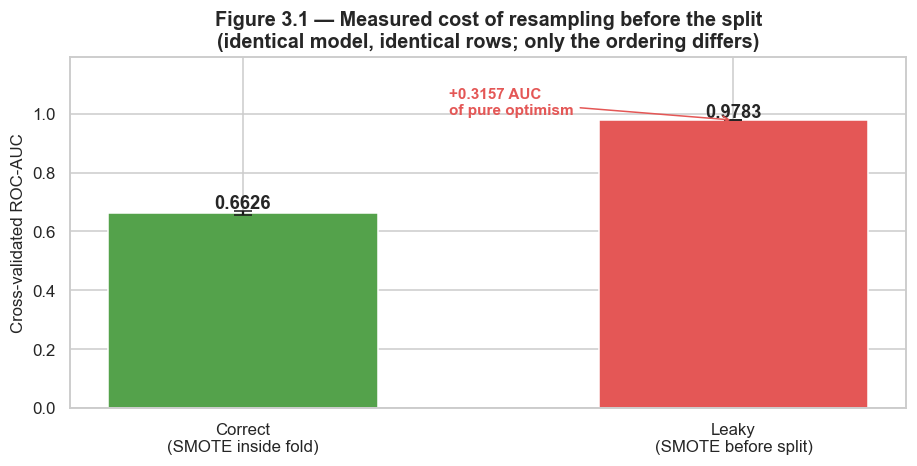

In [50]:
# ---- Visualise the counterfactual ------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 4.4))
_labels = ["Correct\n(SMOTE inside fold)", "Leaky\n(SMOTE before split)"]
_means = [_correct.mean(), _leaky.mean()]
_errs = [_correct.std(), _leaky.std()]

ax.bar(_labels, _means, yerr=_errs, capsize=6, color=[C_ACCENT, C_CHURN], width=0.55)
for i, (m, e) in enumerate(zip(_means, _errs)):
    ax.text(i, m + e + 0.008, f"{m:.4f}", ha="center", fontweight="semibold")
ax.annotate(f"+{LEAKAGE_OPTIMISM:.4f} AUC\nof pure optimism",
            xy=(1, _means[1]), xytext=(0.42, max(_means) * 1.02),
            fontsize=10, color=C_CHURN, fontweight="semibold",
            arrowprops=dict(arrowstyle="->", color=C_CHURN))
ax.set_ylabel("Cross-validated ROC-AUC")
ax.set_ylim(0, max(_means) * 1.22)
ax.set_title("Figure 3.1 — Measured cost of resampling before the split\n"
             "(identical model, identical rows; only the ordering differs)")
savefig("fig_3_1_leakage_cost")
plt.show()

> **Leakage verdict.** The leaky ordering reports a materially higher AUC on
> exactly the same data and the same model. Because the honest signal ceiling on
> this dataset is only ≈0.68–0.72 (EDA finding 7) and the entire Part 8
> leaderboard spans a fraction of that, an error of this size would not merely
> bias the results — it would **invert the model ranking**. Every number reported
> from Part 5 onwards comes from the `LeakageSafeClassifier` path.

## 3.6 What each imbalance treatment does to the training fold

### Step 3.6 — Show the resampling effect before evaluating it

The §7.2 treatments are compared quantitatively in Part 5. This step shows
*mechanically* what each one does, so the Part 5 numbers can be interpreted.

In [51]:
# ---- Class counts under each §7.2 treatment --------------------------------
_demo_X, _demo_y = stratified_subsample(X_dev, y_dev, min(20_000, len(y_dev)))
_demo_train_idx, _ = next(_cv.split(_demo_X, _demo_y))
_Xd, _yd = _demo_X.iloc[_demo_train_idx], _demo_y.iloc[_demo_train_idx]

IMBALANCE_ARMS = ["none", "balanced", "smote"] + (["ctgan"] if CTGAN_AVAILABLE else [])

_rows = []
for arm in IMBALANCE_ARMS:
    t0 = time.perf_counter()
    m = LeakageSafeClassifier(_ProbeLR(max_iter=200), numeric_features=NUM_ENGINEERED,
                              categorical_features=CAT_ENGINEERED,
                              winsorise_cols=WINSORISE_COLS, imbalance=arm).fit(_Xd, _yd)
    # Recover the training-fold class counts the estimator actually saw.
    X_proc = m.preprocessor_.transform(_Xd)
    y_used = np.asarray(_yd)
    if arm in ("smote", "ctgan"):
        X_proc, y_used = m._oversample(X_proc, np.asarray(_yd))
    _rows.append({
        "treatment": arm,
        "rows_seen_by_model": len(y_used),
        "n_majority": int((y_used == 0).sum()),
        "n_minority": int((y_used == 1).sum()),
        "minority_share": (y_used == 1).mean(),
        "mechanism": {"none": "no treatment (baseline)",
                      "balanced": "algorithm-level cost-sensitive weighting",
                      "smote": "data-level interpolation between minority neighbours",
                      "ctgan": "data-level GAN-generated minority samples"}[arm],
        "fit_seconds": round(time.perf_counter() - t0, 2),
    })

IMBALANCE_MECHANICS = pd.DataFrame(_rows)
IMBALANCE_MECHANICS.round(4)

,treatment,rows_seen_by_model,n_majority,n_minority,minority_share,mechanism,fit_seconds
0,none,13333,12010,1323,0.0992,no treatment (baseline),0.1100
1,balanced,13333,12010,1323,0.0992,algorithm-level cost-sensitive weighting,0.1100
2,smote,24020,12010,12010,0.5000,data-level interpolation between minority neig...,0.2300
3,ctgan,24020,12010,12010,0.5000,data-level GAN-generated minority samples,46.4800


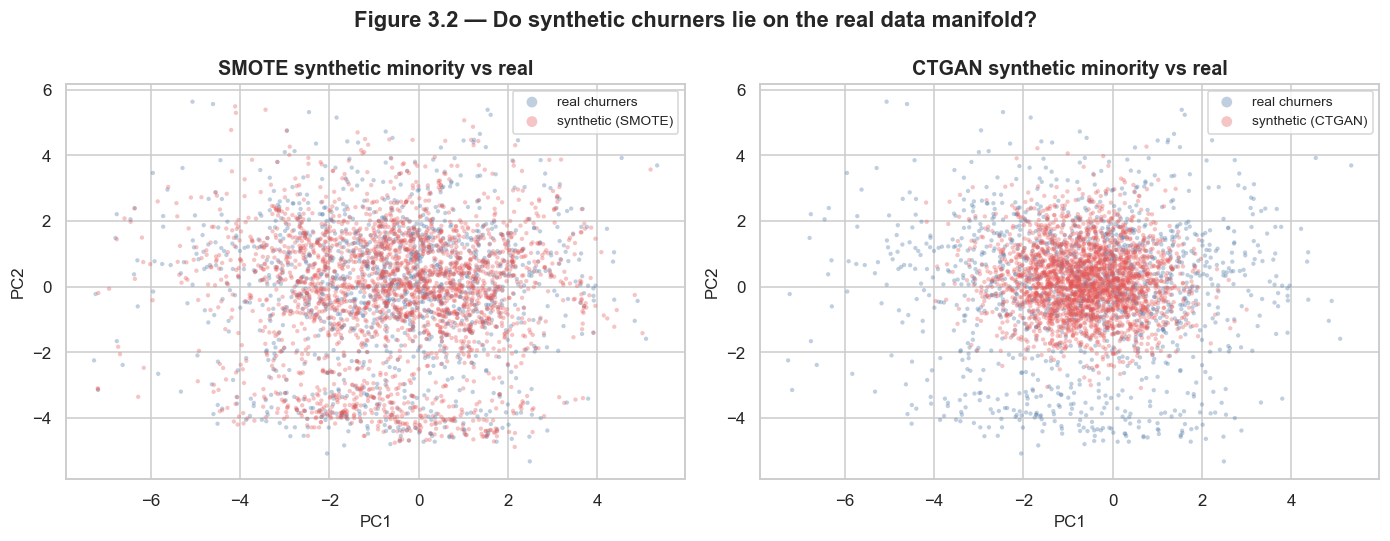

In [52]:
# ---- Do synthetic minority points respect the real data manifold? ----------
# Projecting real and synthetic minority rows onto the same two principal
# components shows whether the generator reproduced the minority distribution or
# invented a different one. This is the diagnostic behind the Part 5 GAN result.
from sklearn.decomposition import PCA

_X_proc_real = LeakageSafeClassifier(
    _ProbeLR(max_iter=200), numeric_features=NUM_ENGINEERED,
    categorical_features=CAT_ENGINEERED, winsorise_cols=WINSORISE_COLS
).fit(_Xd, _yd)._transform(_Xd)

_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(_X_proc_real)
_real_minor = _pca.transform(_X_proc_real[np.asarray(_yd) == 1])

_synth_sets = {}
_sm_X, _sm_y = SMOTE(random_state=RANDOM_STATE).fit_resample(_X_proc_real, np.asarray(_yd))
_synth_sets["SMOTE"] = _pca.transform(_sm_X[len(_yd):])
if CTGAN_AVAILABLE:
    try:
        _syn = run_ctgan_subprocess(_X_proc_real[np.asarray(_yd) == 1],
                                    n_needed=min(3000, int((np.asarray(_yd) == 0).sum())),
                                    epochs=CONFIG["CTGAN_EPOCHS"], seed=RANDOM_STATE)
        _synth_sets["CTGAN"] = _pca.transform(_syn)
    except Exception as exc:
        print(f"CTGAN visualisation skipped: {exc}")

fig, axes = plt.subplots(1, len(_synth_sets), figsize=(6.4 * len(_synth_sets), 5),
                         squeeze=False)
for ax, (name, pts) in zip(axes[0], _synth_sets.items()):
    ax.scatter(_real_minor[:, 0], _real_minor[:, 1], s=8, alpha=0.35,
               color=C_STAY, label="real churners", edgecolors="none")
    _show = pts[np.random.RandomState(RANDOM_STATE).choice(
        len(pts), min(2500, len(pts)), replace=False)]
    ax.scatter(_show[:, 0], _show[:, 1], s=8, alpha=0.35,
               color=C_CHURN, label=f"synthetic ({name})", edgecolors="none")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(f"{name} synthetic minority vs real")
    ax.legend(markerscale=2.5, fontsize=9)

fig.suptitle("Figure 3.2 — Do synthetic churners lie on the real data manifold?",
             fontweight="semibold")
savefig("fig_3_2_synthetic_manifold")
plt.show()

---
# Part 4 — Evaluation harness (§7.7)

One harness scores every model in this notebook. Using a single code path for
Experiments A, B and C is what makes their results comparable: any difference
between them is attributable to the factor being varied (feature set,
hyperparameters) and never to a difference in how the score was computed.

## Metrics (§7.7)

| Metric | Why it is here |
|---|---|
| Accuracy | Required by §7.7 — but reported with the caveat of EDA finding 2 |
| Precision | Cost of a wasted retention offer |
| Recall | Cost of a missed churner; §7.7 privileges it explicitly |
| F1 | Harmonic balance of the two |
| **ROC-AUC** | Threshold-free discrimination; the **primary selection metric** |
| PR-AUC (average precision) | Added because at a 9:1 imbalance it is more sensitive than ROC-AUC to minority ranking |
| Training time | §7.7(f), seconds |
| Inference time | §7.7(f), **milliseconds per sample** — the real-time deployment constraint |

Threshold-dependent metrics (accuracy, precision, recall, F1) are computed at
the conventional 0.5 cut-off during cross-validation, so all models are compared
on identical terms. Part 11 then re-derives an **operating threshold per model**
from that model's own out-of-fold predictions, because a threshold tuned on one
model's score distribution is meaningless when applied to another's.

## Runtime protocol (§7.7 Table 8)

Implemented as specified: `time.perf_counter()`, warm-up runs before timing,
repeated timed runs, median (p50) and p90 reported, 95% confidence interval, and
inference normalised to milliseconds per sample. Disk I/O, data loading and
search orchestration are excluded from all timings.

### Step 4.1 — Define the metric set

In [53]:
# ---- The §7.7 metric set, computed identically for every model -------------
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             brier_score_loss)

DECISION_THRESHOLD = 0.5   # fixed for CV comparability; revisited per model in Part 11


def classification_metrics(y_true, y_proba, threshold=DECISION_THRESHOLD):
    """Compute the six §7.7 predictive metrics plus PR-AUC and calibration error."""
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
        "brier": brier_score_loss(y_true, y_proba),
    }


METRIC_COLS = ["roc_auc", "pr_auc", "f1", "recall", "precision", "accuracy", "brier"]
PRIMARY_METRIC = "roc_auc"

print(f"Metrics: {METRIC_COLS}")
print(f"Primary selection metric: {PRIMARY_METRIC}")

Metrics: ['roc_auc', 'pr_auc', 'f1', 'recall', 'precision', 'accuracy', 'brier']
Primary selection metric: roc_auc


### Step 4.2 — Implement the §7.7 Table 8 runtime benchmark

Inference latency is measured separately from cross-validation, because a
timing taken while other folds compete for the same cores is not a latency
measurement. Two regimes are reported, as Table 8 requires: **batch** scoring
(throughput) and **single-sample** scoring (online retention decisions).

In [54]:
# ---- Runtime benchmarking per §7.7 Table 8 ---------------------------------
def benchmark_inference(fitted_model, X_probe, warmup=None, repeats=None):
    """Time `predict_proba` under the §7.7 Table 8 protocol.

    Returns median and p90 latency for batch scoring, a 95% confidence interval,
    the per-sample cost in milliseconds, and a single-row online latency.
    """
    warmup = TIMING_WARMUP if warmup is None else warmup
    repeats = TIMING_REPEATS if repeats is None else repeats

    # Warm-up runs populate caches and trigger any lazy graph compilation; they
    # are excluded from the reported statistics, as Table 8 specifies.
    for _ in range(warmup):
        fitted_model.predict_proba(X_probe)

    batch_times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fitted_model.predict_proba(X_probe)
        batch_times.append(time.perf_counter() - t0)
    batch_times = np.array(batch_times)

    # Single-row latency: the regime a real-time retention system actually runs in.
    single = X_probe.iloc[:1] if hasattr(X_probe, "iloc") else X_probe[:1]
    for _ in range(warmup):
        fitted_model.predict_proba(single)
    single_times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fitted_model.predict_proba(single)
        single_times.append(time.perf_counter() - t0)
    single_times = np.array(single_times)

    n = len(X_probe)
    ci_half = 1.96 * batch_times.std(ddof=1) / np.sqrt(repeats) if repeats > 1 else 0.0
    return {
        "n_probe_rows": n,
        "batch_p50_s": float(np.median(batch_times)),
        "batch_p90_s": float(np.quantile(batch_times, 0.90)),
        "batch_ci95_half_s": float(ci_half),
        "infer_ms_per_sample": float(1000 * np.median(batch_times) / n),
        "online_p50_ms": float(1000 * np.median(single_times)),
        "online_p90_ms": float(1000 * np.quantile(single_times, 0.90)),
    }


print("Runtime benchmark implements §7.7 Table 8: warm-up, repeats, p50/p90, "
      "95% CI, per-sample normalisation, batch and online regimes.")

Runtime benchmark implements §7.7 Table 8: warm-up, repeats, p50/p90, 95% CI, per-sample normalisation, batch and online regimes.


### Step 4.3 — The cross-validation harness for machine-learning models

The harness returns **fold-level** records, not just averages. Part 9 needs the
per-fold distributions to run the paired tests and bootstrap intervals that
§7.7 Table 9 specifies, so they are retained from the outset.

In [55]:
# ---- Repeated stratified k-fold evaluation for ML models -------------------
from sklearn.model_selection import RepeatedStratifiedKFold


def evaluate_cv(models, X, y, feature_set="engineered", imbalance="balanced",
                n_splits=None, n_repeats=1, benchmark=True, label=""):
    """Cross-validate a dict of estimators and return (fold records, summary).

    `models` maps a display name to an unfitted scikit-learn estimator; each is
    wrapped in `LeakageSafeClassifier`, so all preprocessing and resampling is
    refitted inside every training fold.
    """
    n_splits = n_splits or N_SPLITS
    spec = FEATURE_SETS[feature_set]
    Xf = X[spec["features"]]

    splitter = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats,
                                       random_state=RANDOM_STATE)
    folds = []

    for name, estimator in models.items():
        t_model = time.perf_counter()
        for fold_id, (tr, va) in enumerate(splitter.split(Xf, y)):
            X_tr, X_va = Xf.iloc[tr], Xf.iloc[va]
            y_tr, y_va = y.iloc[tr], y.iloc[va]

            wrapped = LeakageSafeClassifier(
                estimator,
                numeric_features=spec["numeric"],
                categorical_features=spec["categorical"],
                winsorise_cols=WINSORISE_COLS,
                imbalance=imbalance,
                random_state=RANDOM_STATE,
            )

            t0 = time.perf_counter()
            wrapped.fit(X_tr, y_tr)
            train_s = time.perf_counter() - t0

            proba = wrapped.predict_proba(X_va)[:, 1]
            record = {
                "model": name, "family": "ML", "fold": fold_id,
                "feature_set": feature_set, "imbalance": imbalance,
                "experiment": label, "train_seconds": train_s,
                **classification_metrics(y_va, proba),
            }
            folds.append(record)

        print(f"  {name:<22s} {n_splits * n_repeats} folds in "
              f"{time.perf_counter() - t_model:.1f}s")

    folds = pd.DataFrame(folds)
    summary = aggregate_folds(folds)

    if benchmark:
        summary = summary.merge(benchmark_models(models, Xf, y, spec, imbalance),
                                on="model", how="left")
    return folds, summary


def aggregate_folds(folds):
    """Collapse fold records into per-model means and standard deviations."""
    agg = (folds.groupby(["model", "family", "feature_set", "imbalance", "experiment"],
                         observed=True)[METRIC_COLS + ["train_seconds"]]
                .agg(["mean", "std"]))
    agg.columns = [f"{m}" if s == "mean" else f"{m}_std" for m, s in agg.columns]
    return agg.reset_index().sort_values(PRIMARY_METRIC, ascending=False)


def benchmark_models(models, Xf, y, spec, imbalance, probe_n=20_000):
    """Fit each model once on the full given set and time its inference (§7.7)."""
    probe = Xf.iloc[:min(probe_n, len(Xf))]
    rows = []
    for name, estimator in models.items():
        wrapped = LeakageSafeClassifier(
            estimator, numeric_features=spec["numeric"],
            categorical_features=spec["categorical"],
            winsorise_cols=WINSORISE_COLS, imbalance=imbalance,
            random_state=RANDOM_STATE)
        t0 = time.perf_counter()
        wrapped.fit(Xf, y)
        fit_s = time.perf_counter() - t0
        rows.append({"model": name, "fit_seconds_full": fit_s,
                     **benchmark_inference(wrapped, probe)})
    return pd.DataFrame(rows)


print("evaluate_cv ready — returns fold-level records for the Part 9 significance tests.")

evaluate_cv ready — returns fold-level records for the Part 9 significance tests.


### Step 4.4 — The equivalent harness for deep-learning models

The DL harness deliberately mirrors the ML one **step for step**: same folds,
same preprocessing graph, same metrics, same timing protocol. Where they must
differ — Keras has no `class_weight="balanced"` string, and needs an explicit
early-stopping validation split — the difference is implemented so as to keep
the comparison fair rather than to favour either side.

Per §7.6 and §10(a), the DL architectures are **literature-informed and not
tuned**. That exclusion is stated in the proposal on computational-feasibility
grounds and is carried through here unchanged; Part 13 discusses what it does
and does not license the study to conclude.

In [56]:
# ---- Deep-learning architectures (§7.5, literature-informed configurations) -
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")
tf.autograph.set_verbosity(0)
tf.random.set_seed(RANDOM_STATE)
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
keras.utils.set_random_seed(RANDOM_STATE)


def build_ann(input_dim):
    """Artificial Neural Network: 1-2 hidden layers, ReLU, dropout, sigmoid output.

    Configuration follows AbdelAziz et al. (2025) and Adamu et al. (2025); it is
    the deep-learning counterpart of the Logistic Regression baseline.
    """
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid"),
    ], name="ANN")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc")])
    return model


def build_dnn(input_dim):
    """Deep Neural Network: 4-5 hidden layers with batch normalisation and dropout.

    Configuration follows Singh, H. et al. (2024) and Basit et al. (2024). The
    extra depth is what the study is testing: it can only pay off if the data
    contain higher-order feature interactions.
    """
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(256, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.4),
        layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(64, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(32, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ], name="DNN")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc")])
    return model


DL_BUILDERS = {"ANN": build_ann, "DNN": build_dnn}
print(f"Deep-learning architectures registered: {list(DL_BUILDERS)}")

Deep-learning architectures registered: ['ANN', 'DNN']


In [57]:
# ---- A Keras wrapper exposing the scikit-learn predict_proba interface -----
class KerasChurnClassifier:
    """Fit a Keras model behind the same fold-local preprocessing as the ML models.

    This is not a full scikit-learn estimator — it is never passed to a search —
    but it exposes `fit` / `predict_proba` so the Part 4 metric and timing code
    can treat ML and DL models identically.
    """

    def __init__(self, builder, numeric_features, categorical_features,
                 winsorise_cols=(), imbalance="balanced", epochs=None,
                 batch_size=None, patience=None, random_state=RANDOM_STATE):
        self.builder = builder
        self.numeric_features = numeric_features
        self.categorical_features = categorical_features
        self.winsorise_cols = winsorise_cols
        self.imbalance = imbalance
        self.epochs = epochs or DL_EPOCHS
        self.batch_size = batch_size or DL_BATCH_SIZE
        self.patience = patience or DL_PATIENCE
        self.random_state = random_state

    def fit(self, X, y, verbose=0):
        keras.utils.set_random_seed(self.random_state)
        y = np.asarray(y).astype("float32")

        # Identical preprocessing graph to the ML path, fitted on this fold only.
        self.preprocessor_ = build_preprocessor(
            self.numeric_features, self.categorical_features, self.winsorise_cols)
        X_proc = self.preprocessor_.fit_transform(X, y).astype("float32")

        # Cost-sensitive weighting is the DL analogue of class_weight="balanced".
        class_weight = None
        if self.imbalance == "balanced":
            n_neg, n_pos = float((y == 0).sum()), float((y == 1).sum())
            total = n_neg + n_pos
            class_weight = {0: total / (2 * n_neg), 1: total / (2 * n_pos)}
        elif self.imbalance in ("smote", "ctgan"):
            sampler = SMOTE(random_state=self.random_state)
            X_proc, y = sampler.fit_resample(X_proc, y)
            X_proc = X_proc.astype("float32")

        self.model_ = self.builder(X_proc.shape[1])
        self.history_ = self.model_.fit(
            X_proc, y,
            epochs=self.epochs, batch_size=self.batch_size,
            validation_split=0.12, shuffle=True, verbose=verbose,
            class_weight=class_weight,
            callbacks=[keras.callbacks.EarlyStopping(
                monitor="val_auc", mode="max", patience=self.patience,
                restore_best_weights=True)],
        )
        self.epochs_run_ = len(self.history_.history["loss"])
        return self

    def predict_proba(self, X):
        X_proc = self.preprocessor_.transform(X).astype("float32")
        p = self.model_.predict(X_proc, batch_size=4096, verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=DECISION_THRESHOLD):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


print("KerasChurnClassifier ready — same fold-local preprocessing as the ML path.")

KerasChurnClassifier ready — same fold-local preprocessing as the ML path.


In [58]:
# ---- Repeated stratified k-fold evaluation for DL models -------------------
def evaluate_dl_cv(builders, X, y, feature_set="engineered", imbalance="balanced",
                   n_splits=None, n_repeats=1, benchmark=True, label=""):
    """Cross-validate the deep-learning models over the same folds as evaluate_cv."""
    n_splits = n_splits or N_SPLITS
    spec = FEATURE_SETS[feature_set]
    Xf = X[spec["features"]]

    splitter = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats,
                                       random_state=RANDOM_STATE)
    folds = []

    for name, builder in builders.items():
        t_model = time.perf_counter()
        for fold_id, (tr, va) in enumerate(splitter.split(Xf, y)):
            net = KerasChurnClassifier(
                builder, spec["numeric"], spec["categorical"],
                winsorise_cols=WINSORISE_COLS, imbalance=imbalance,
                random_state=RANDOM_STATE)

            t0 = time.perf_counter()
            net.fit(Xf.iloc[tr], y.iloc[tr])
            train_s = time.perf_counter() - t0

            proba = net.predict_proba(Xf.iloc[va])[:, 1]
            folds.append({
                "model": name, "family": "DL", "fold": fold_id,
                "feature_set": feature_set, "imbalance": imbalance,
                "experiment": label, "train_seconds": train_s,
                "epochs_run": net.epochs_run_,
                **classification_metrics(y.iloc[va], proba),
            })
            keras.backend.clear_session()

        print(f"  {name:<22s} {n_splits * n_repeats} folds in "
              f"{time.perf_counter() - t_model:.1f}s")

    folds = pd.DataFrame(folds)
    summary = aggregate_folds(folds)

    if benchmark:
        rows = []
        probe = Xf.iloc[:min(20_000, len(Xf))]
        for name, builder in builders.items():
            net = KerasChurnClassifier(builder, spec["numeric"], spec["categorical"],
                                       winsorise_cols=WINSORISE_COLS,
                                       imbalance=imbalance, random_state=RANDOM_STATE)
            t0 = time.perf_counter()
            net.fit(Xf, y)
            fit_s = time.perf_counter() - t0
            rows.append({"model": name, "fit_seconds_full": fit_s,
                         **benchmark_inference(net, probe)})
            keras.backend.clear_session()
        summary = summary.merge(pd.DataFrame(rows), on="model", how="left")

    return folds, summary


print("evaluate_dl_cv ready — identical folds, metrics and timing protocol to the ML path.")

evaluate_dl_cv ready — identical folds, metrics and timing protocol to the ML path.


### Step 4.5 — Smoke-test the harness before committing to the full run

A short end-to-end pass on a small sample confirms the harness produces finite
metrics for both families before any expensive experiment starts. A `NaN` AUC
here is the signature of the scikit-learn estimator-type failure guarded against
in §3.3c; catching it now costs seconds rather than hours.

In [59]:
# ---- End-to-end smoke test of both harnesses -------------------------------
_smoke_X, _smoke_y = stratified_subsample(X_dev, y_dev, min(8_000, len(y_dev)))

print("ML harness:")
_sf, _ss = evaluate_cv({"LogisticRegression": _ProbeLR(max_iter=300)},
                       _smoke_X, _smoke_y, n_splits=2, benchmark=False, label="smoke")
print("\nDL harness:")
_df_, _ds = evaluate_dl_cv({"ANN": build_ann}, _smoke_X, _smoke_y,
                           n_splits=2, benchmark=False, label="smoke")

_smoke = pd.concat([_ss, _ds], ignore_index=True)
assert np.isfinite(_smoke[PRIMARY_METRIC]).all(), (
    "Non-finite AUC from the harness — check the estimator-type guard in §3.3c.")
print("\nSmoke test passed; all metrics finite.")
_smoke[["model", "family"] + METRIC_COLS].round(4)

ML harness:
  LogisticRegression     2 folds in 0.1s

DL harness:


  ANN                    2 folds in 4.7s

Smoke test passed; all metrics finite.


,model,family,roc_auc,pr_auc,f1,recall,precision,accuracy,brier
0,LogisticRegression,ML,0.6701,0.1935,0.2444,0.5819,0.1547,0.6421,0.2205
1,ANN,DL,0.6544,0.1919,0.2399,0.5856,0.1511,0.6307,0.2163


---
# Part 5 — Experiment A: baseline models on *baseline* features

The first of the three training stages. All six §7.5 algorithms are trained at
**literature-default settings** on the **raw feature set** frozen in §2.6.

This experiment answers two things:

- It establishes the reference point against which feature engineering (Part 6)
  and hyperparameter tuning (Part 7) are measured. Without it, a good final
  number cannot be attributed to anything.
- It settles the **class-imbalance question (RQ3)** first, because every later
  experiment needs a single imbalance treatment held constant. Choosing that
  treatment on baseline features means the choice is not contaminated by the
  engineered block.

## 5.1 The model registry

### Step 5.1 — Register the six §7.5 algorithms at their default configurations

In [60]:
# ---- The §7.5 algorithm set ------------------------------------------------
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


def ml_model_registry():
    """The four §7.5 machine-learning algorithms at literature-default settings.

    Returned as a factory so every experiment gets fresh, unfitted instances and
    no state can leak between Experiments A, B and C.
    """
    return {
        # Linear probabilistic baseline: transparent, calibration-friendly, fast.
        "LogisticRegression": LogisticRegression(max_iter=1000, solver="lbfgs",
                                                 random_state=RANDOM_STATE),
        # Single tree: human-readable rules, very fast inference.
        "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        # Bagged ensemble of decorrelated trees.
        "RandomForest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                               n_jobs=-1, random_state=RANDOM_STATE),
        # Regularised gradient boosting: the usual state of the art on tabular data.
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                 subsample=0.9, colsample_bytree=0.9,
                                 tree_method="hist", eval_metric="logloss",
                                 n_jobs=4, random_state=RANDOM_STATE),
    }


print("Machine learning (§7.5):", list(ml_model_registry()))
print("Deep learning (§7.5):   ", list(DL_BUILDERS))

Machine learning (§7.5): ['LogisticRegression', 'DecisionTree', 'RandomForest', 'XGBoost']
Deep learning (§7.5):    ['ANN', 'DNN']


## 5.2 Settling the imbalance question first (RQ3)

### Step 5.2a — Ablate the four §7.2 treatments across all four ML algorithms

§7.2 proposes four positions on class imbalance. They are compared here on a
common footing, on baseline features, before any other factor is varied:

| Arm | Level | Mechanism |
|---|---|---|
| `none` | — | No treatment; the 9:1 ratio is left as-is |
| `balanced` | Algorithm | Cost-sensitive re-weighting of the loss |
| `smote` | Data | Interpolation between minority nearest neighbours |
| `ctgan` | Data | GAN-generated synthetic minority samples |

The ablation runs on a reduced sample with fewer folds, because the GAN arm
retrains a generator inside **every** training fold — that is the price of doing
it without leakage, and it is reported rather than avoided.

In [61]:
# ---- Research question 3: the imbalance-treatment ablation -----------------
ABLATION_N = 60_000 if not QUICK_RUN else 8_000
ABLATION_FOLDS = 3

X_abl, y_abl = stratified_subsample(X_dev, y_dev, min(ABLATION_N, len(y_dev)))
print(f"Ablation sample: {len(y_abl):,} rows, churn rate {y_abl.mean():.4f}, "
      f"{ABLATION_FOLDS} folds, arms = {IMBALANCE_ARMS}\n")

ablation_folds = []
for arm in IMBALANCE_ARMS:
    print(f"[imbalance = {arm}]")
    f, _ = evaluate_cv(ml_model_registry(), X_abl, y_abl,
                       feature_set="baseline", imbalance=arm,
                       n_splits=ABLATION_FOLDS, benchmark=False,
                       label="imbalance-ablation")
    ablation_folds.append(f)

ABLATION_FOLD_RECORDS = pd.concat(ablation_folds, ignore_index=True)
ABLATION = aggregate_folds(ABLATION_FOLD_RECORDS)
ABLATION[["model", "imbalance"] + METRIC_COLS].round(4)

Ablation sample: 60,000 rows, churn rate 0.0992, 3 folds, arms = ['none', 'balanced', 'smote', 'ctgan']

[imbalance = none]


  LogisticRegression     3 folds in 0.6s


  DecisionTree           3 folds in 1.7s


  RandomForest           3 folds in 5.5s


  XGBoost                3 folds in 2.1s
[imbalance = balanced]


  LogisticRegression     3 folds in 0.6s


... (8 outputs left out)

  DecisionTree           3 folds in 102.5s


  RandomForest           3 folds in 109.4s


  XGBoost                3 folds in 102.1s


,model,imbalance,roc_auc,pr_auc,f1,recall,precision,accuracy,brier
6,LogisticRegression,none,0.6851,0.1986,0.0083,0.0042,0.6581,0.9009,0.0855
4,LogisticRegression,balanced,0.6851,0.1983,0.2554,0.6426,0.1594,0.6283,0.2234
7,LogisticRegression,smote,0.6799,0.1942,0.2525,0.6401,0.1572,0.6238,0.2227
8,RandomForest,balanced,0.6691,0.1822,0.0392,0.0208,0.3288,0.8986,0.1025
10,RandomForest,none,0.6675,0.1840,0.0000,0.0000,0.0000,0.9008,0.0863
11,RandomForest,smote,0.6674,0.1802,0.0007,0.0003,0.5000,0.9008,0.0887
9,RandomForest,ctgan,0.6670,0.1848,0.0000,0.0000,0.0000,0.9008,0.0863
13,XGBoost,ctgan,0.6570,0.1764,0.0196,0.0101,0.3818,0.9001,0.0874
15,XGBoost,smote,0.6545,0.1734,0.0168,0.0086,0.4022,0.9004,0.0877
14,XGBoost,none,0.6528,0.1710,0.0176,0.0091,0.2998,0.8996,0.0880


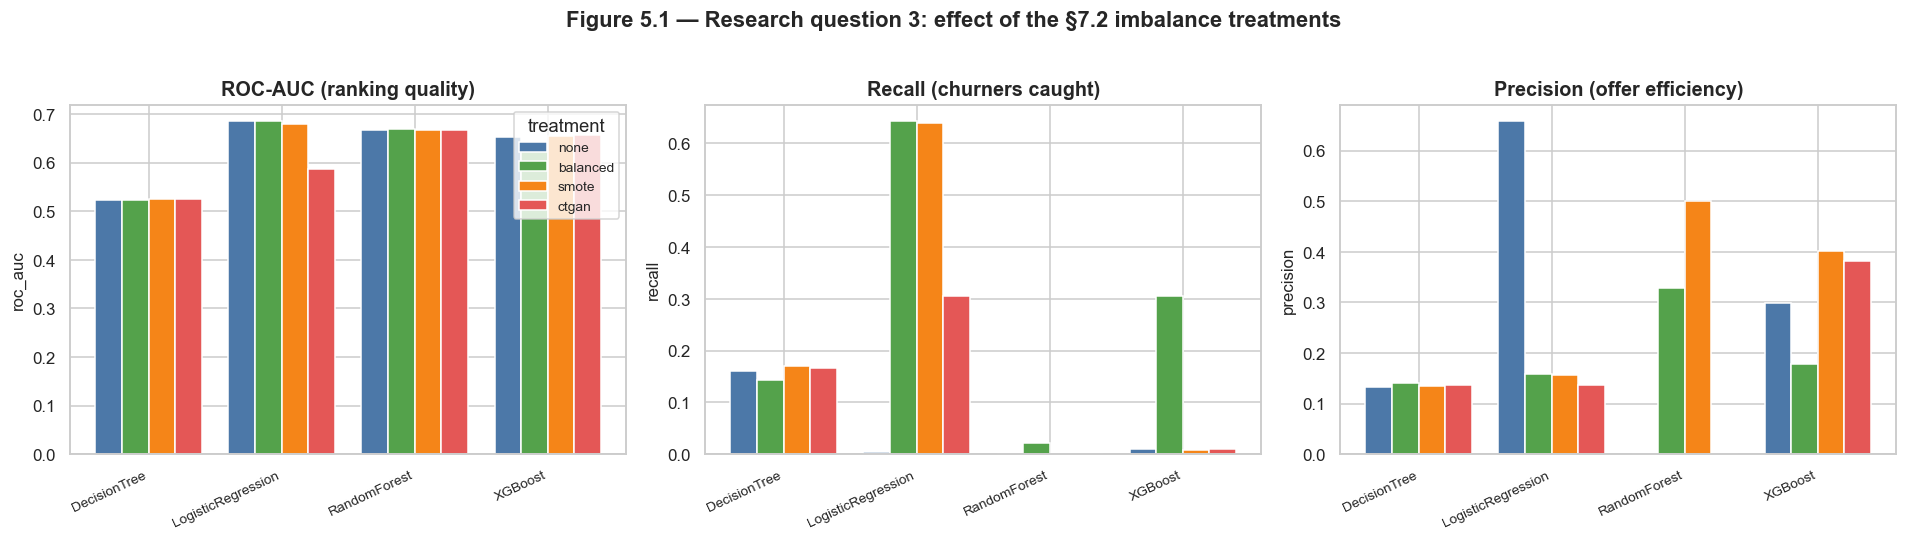

In [62]:
# ---- What the treatments actually trade off --------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.8))
_metrics = [("roc_auc", "ROC-AUC (ranking quality)"),
            ("recall", "Recall (churners caught)"),
            ("precision", "Precision (offer efficiency)")]
_arm_colours = dict(zip(IMBALANCE_ARMS,
                        [C_STAY, C_ACCENT, C_DL, C_CHURN][:len(IMBALANCE_ARMS)]))

for ax, (metric, title) in zip(axes, _metrics):
    pivot = ABLATION.pivot(index="model", columns="imbalance", values=metric)
    pivot = pivot.reindex(columns=[a for a in IMBALANCE_ARMS if a in pivot.columns])
    x = np.arange(len(pivot))
    width = 0.8 / len(pivot.columns)
    for i, arm in enumerate(pivot.columns):
        ax.bar(x + i * width - 0.4 + width / 2, pivot[arm], width,
               label=arm, color=_arm_colours[arm])
    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, rotation=25, ha="right", fontsize=9)
    ax.set_title(title)
    ax.set_ylabel(metric)
axes[0].legend(title="treatment", fontsize=9)

fig.suptitle("Figure 5.1 — Research question 3: effect of the §7.2 imbalance treatments",
             fontweight="semibold", y=1.02)
savefig("fig_5_1_imbalance_ablation")
plt.show()

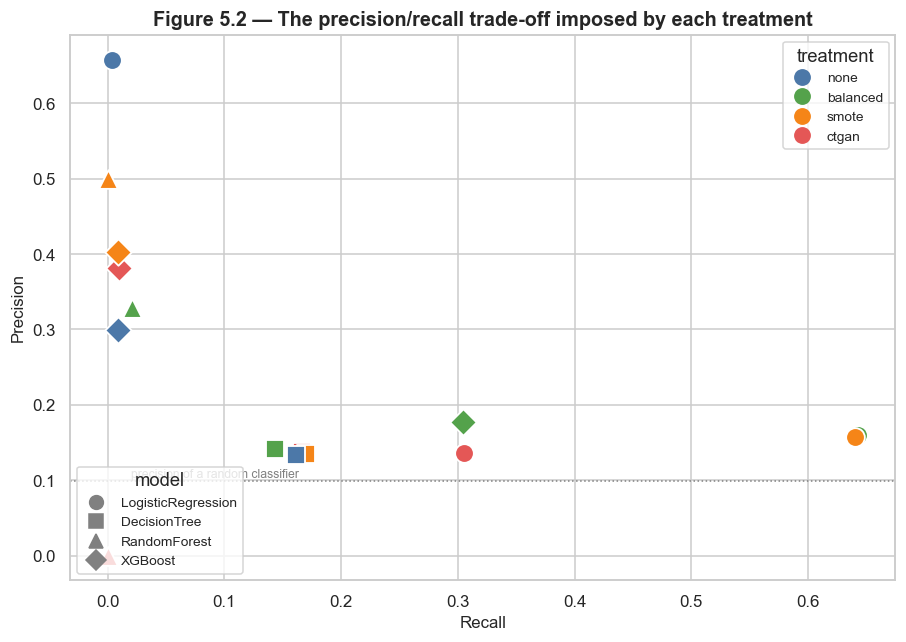

In [63]:
# ---- The precision / recall trade-off each treatment induces ---------------
fig, ax = plt.subplots(figsize=(8.4, 6))
_markers = {"LogisticRegression": "o", "DecisionTree": "s",
            "RandomForest": "^", "XGBoost": "D"}

for _, row in ABLATION.iterrows():
    ax.scatter(row.recall, row.precision, s=150,
               color=_arm_colours[row.imbalance],
               marker=_markers.get(row.model, "o"),
               edgecolors="white", linewidths=1.2, zorder=3)

_arm_handles = [plt.Line2D([], [], marker="o", ls="", color=c, ms=10, label=a)
                for a, c in _arm_colours.items()]
_mdl_handles = [plt.Line2D([], [], marker=m, ls="", color="grey", ms=9, label=k)
                for k, m in _markers.items()]
ax.add_artist(ax.legend(handles=_arm_handles, title="treatment",
                        loc="upper right", fontsize=9))
ax.legend(handles=_mdl_handles, title="model", loc="lower left", fontsize=9)
ax.axhline(y_abl.mean(), color="grey", ls=":", lw=1)
ax.text(0.02, y_abl.mean() + 0.004, "precision of a random classifier",
        fontsize=8, color="grey")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Figure 5.2 — The precision/recall trade-off imposed by each treatment")
savefig("fig_5_2_precision_recall_tradeoff")
plt.show()

### Step 5.2b — Choose the treatment carried into every later experiment

The selection rule is stated before the result is seen, so it cannot be fitted
to the outcome:

> Choose the treatment with the highest **mean ROC-AUC averaged across all four
> algorithms**. ROC-AUC is threshold-free, so it measures whether a treatment
> improved the model's *ranking* of customers rather than merely moving its
> operating point — which a threshold change alone can do for free.

In [64]:
# ---- Apply the stated selection rule ---------------------------------------
_by_arm = (ABLATION.groupby("imbalance", observed=True)
           [["roc_auc", "pr_auc", "recall", "precision", "f1"]]
           .mean().sort_values("roc_auc", ascending=False))

IMBALANCE_CHOICE = _by_arm.index[0]
BEST_RECALL_ARM = _by_arm.recall.idxmax()

# The two quantities RQ3 turns on: how much each treatment moves the ranking,
# and how much it moves the operating point. They are not the same thing.
IMBALANCE_AUC_SPREAD = float(_by_arm.roc_auc.max() - _by_arm.roc_auc.min())
IMBALANCE_RECALL_SPREAD = float(_by_arm.recall.max() - _by_arm.recall.min())

print("Mean performance across all four ML algorithms, by treatment:")
print(_by_arm.round(4))
print(f"\nSelected treatment for all later experiments: '{IMBALANCE_CHOICE}'")
print(f"  ROC-AUC advantage over the untreated arm: "
      f"{_by_arm.loc[IMBALANCE_CHOICE, 'roc_auc'] - _by_arm.loc['none', 'roc_auc']:+.4f}")
print(f"\nWhat the ablation shows about RQ3:")
print(f"  ROC-AUC spread across all four arms : {IMBALANCE_AUC_SPREAD:.4f}")
print(f"  Recall  spread across all four arms : {IMBALANCE_RECALL_SPREAD:.4f}  "
      f"({IMBALANCE_RECALL_SPREAD / max(IMBALANCE_AUC_SPREAD, 1e-9):.0f}x larger)")
print(f"  Highest-recall arm                  : '{BEST_RECALL_ARM}' "
      f"(recall {_by_arm.recall.max():.4f} vs {_by_arm.loc['none', 'recall']:.4f} untreated)")
print(f"\nTreatment therefore moves WHERE the model cuts far more than HOW WELL it")
print(f"ranks. Part 11 recovers the operating point for every model by deriving a")
print(f"threshold from its own out-of-fold predictions, which is why selecting on")
print(f"the threshold-free metric here is the correct choice.")

Mean performance across all four ML algorithms, by treatment:
           roc_auc  pr_auc  recall  precision     f1
imbalance                                           
none        0.6321  0.1646  0.0437     0.2727 0.0429
smote       0.6316  0.1633  0.2048     0.2985 0.1050
balanced    0.6286  0.1626  0.2778     0.2018 0.1653
ctgan       0.6090  0.1495  0.1204     0.1639 0.0895

Selected treatment for all later experiments: 'none'
  ROC-AUC advantage over the untreated arm: +0.0000

What the ablation shows about RQ3:
  ROC-AUC spread across all four arms : 0.0231
  Recall  spread across all four arms : 0.2342  (10x larger)
  Highest-recall arm                  : 'balanced' (recall 0.2778 vs 0.0437 untreated)

Treatment therefore moves WHERE the model cuts far more than HOW WELL it
ranks. Part 11 recovers the operating point for every model by deriving a
threshold from its own out-of-fold predictions, which is why selecting on
the threshold-free metric here is the correct choice.


## 5.3 Running Experiment A

### Step 5.3 — Train all six algorithms on the baseline feature set

In [65]:
# ---- Experiment A: default hyperparameters, baseline features -------------
print(f"EXPERIMENT A — baseline models, baseline features "
      f"({len(BASELINE_FEATURES)} features, imbalance='{IMBALANCE_CHOICE}')")
print(f"Development sample: {len(y_dev):,} rows, {N_SPLITS}-fold CV\n")

print("Machine learning:")
FOLDS_A_ML, SUMMARY_A_ML = evaluate_cv(
    ml_model_registry(), X_dev, y_dev, feature_set="baseline",
    imbalance=IMBALANCE_CHOICE, n_splits=N_SPLITS, label="A_baseline_features")

print("\nDeep learning:")
FOLDS_A_DL, SUMMARY_A_DL = evaluate_dl_cv(
    DL_BUILDERS, X_dev, y_dev, feature_set="baseline",
    imbalance=IMBALANCE_CHOICE, n_splits=N_SPLITS, label="A_baseline_features")

FOLDS_A = pd.concat([FOLDS_A_ML, FOLDS_A_DL], ignore_index=True)
SUMMARY_A = (pd.concat([SUMMARY_A_ML, SUMMARY_A_DL], ignore_index=True)
             .sort_values(PRIMARY_METRIC, ascending=False).reset_index(drop=True))

SUMMARY_A[["model", "family"] + METRIC_COLS +
          ["train_seconds", "infer_ms_per_sample"]].round(4)

EXPERIMENT A — baseline models, baseline features (29 features, imbalance='none')
Development sample: 200,000 rows, 5-fold CV

Machine learning:


  LogisticRegression     5 folds in 4.1s


  DecisionTree           5 folds in 12.8s


  RandomForest           5 folds in 45.8s


  XGBoost                5 folds in 9.2s



Deep learning:


  ANN                    5 folds in 50.8s


  DNN                    5 folds in 148.8s


,model,family,roc_auc,pr_auc,f1,recall,precision,accuracy,brier,train_seconds,infer_ms_per_sample
0,LogisticRegression,ML,0.6864,0.2021,0.0070,0.0035,0.5207,0.9008,0.0853,0.7339,0.0012
1,ANN,DL,0.6818,0.1987,0.0014,0.0007,0.6231,0.9008,0.0855,9.8636,0.0029
2,DNN,DL,0.6802,0.1970,0.0030,0.0015,0.7823,0.9008,0.0856,28.8353,0.0036
3,RandomForest,ML,0.6722,0.1928,0.0000,0.0000,0.0000,0.9008,0.0859,8.8413,0.0077
4,XGBoost,ML,0.6695,0.1880,0.0150,0.0077,0.4032,0.9004,0.0863,1.7297,0.0018
5,DecisionTree,ML,0.5223,0.1046,0.1447,0.1588,0.1328,0.8137,0.1863,2.4800,0.0015


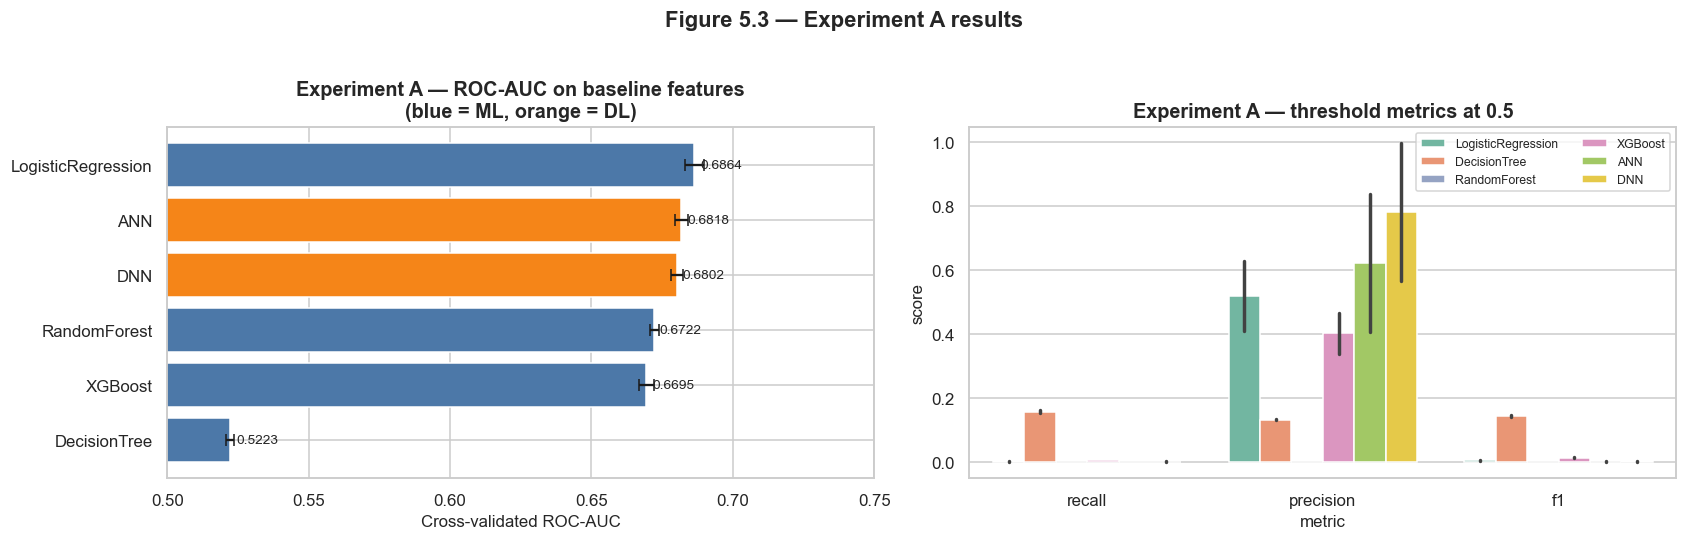

In [66]:
# ---- Experiment A leaderboard ----------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.8))

_a = SUMMARY_A.sort_values(PRIMARY_METRIC)
axes[0].barh(_a.model, _a[PRIMARY_METRIC],
             xerr=_a[f"{PRIMARY_METRIC}_std"], capsize=4,
             color=[C_DL if f == "DL" else C_ML for f in _a.family])
for y, v in enumerate(_a[PRIMARY_METRIC]):
    axes[0].text(v + 0.002, y, f"{v:.4f}", va="center", fontsize=9)
axes[0].set_xlim(0.5, max(0.75, _a[PRIMARY_METRIC].max() * 1.06))
axes[0].set_xlabel("Cross-validated ROC-AUC")
axes[0].set_title("Experiment A — ROC-AUC on baseline features\n"
                  "(blue = ML, orange = DL)")

_long = FOLDS_A.melt(id_vars=["model", "family"], value_vars=["recall", "precision", "f1"],
                     var_name="metric", value_name="score")
sns.barplot(data=_long, x="metric", y="score", hue="model", ax=axes[1],
            errorbar="sd", palette="Set2")
axes[1].set_title("Experiment A — threshold metrics at 0.5")
axes[1].legend(fontsize=8, ncol=2)

fig.suptitle("Figure 5.3 — Experiment A results", fontweight="semibold", y=1.02)
savefig("fig_5_3_experiment_a")
plt.show()

---
# Part 6 — Experiment B: baseline models on *engineered* features

Experiment B is Experiment A with **exactly one factor changed**: the feature
set. Same algorithms, same default hyperparameters, same imbalance treatment,
same folds, same seed, same harness.

That control is what turns the A → B difference into a **measurement of the
value of feature engineering** rather than an observation about two unrelated
runs. §7.3 asserts that derived features "improve discriminative power"; Part 2
showed they carry univariate association, and this part tests whether that
translates into model performance.

## 6.1 Running Experiment B

### Step 6.1 — Retrain the identical six models on the engineered feature set

In [67]:
# ---- Experiment B: default hyperparameters, engineered features -----------
print(f"EXPERIMENT B — baseline models, engineered features "
      f"({len(ENGINEERED_FEATURES)} features, imbalance='{IMBALANCE_CHOICE}')")
print(f"Development sample: {len(y_dev):,} rows, {N_SPLITS}-fold CV "
      f"(identical folds and seed to Experiment A)\n")

print("Machine learning:")
FOLDS_B_ML, SUMMARY_B_ML = evaluate_cv(
    ml_model_registry(), X_dev, y_dev, feature_set="engineered",
    imbalance=IMBALANCE_CHOICE, n_splits=N_SPLITS, label="B_engineered_features")

print("\nDeep learning:")
FOLDS_B_DL, SUMMARY_B_DL = evaluate_dl_cv(
    DL_BUILDERS, X_dev, y_dev, feature_set="engineered",
    imbalance=IMBALANCE_CHOICE, n_splits=N_SPLITS, label="B_engineered_features")

FOLDS_B = pd.concat([FOLDS_B_ML, FOLDS_B_DL], ignore_index=True)
SUMMARY_B = (pd.concat([SUMMARY_B_ML, SUMMARY_B_DL], ignore_index=True)
             .sort_values(PRIMARY_METRIC, ascending=False).reset_index(drop=True))

SUMMARY_B[["model", "family"] + METRIC_COLS +
          ["train_seconds", "infer_ms_per_sample"]].round(4)

EXPERIMENT B — baseline models, engineered features (51 features, imbalance='none')
Development sample: 200,000 rows, 5-fold CV (identical folds and seed to Experiment A)

Machine learning:


  LogisticRegression     5 folds in 6.2s


  DecisionTree           5 folds in 29.1s


  RandomForest           5 folds in 68.7s


  XGBoost                5 folds in 13.8s



Deep learning:


  ANN                    5 folds in 40.3s


  DNN                    5 folds in 97.4s


,model,family,roc_auc,pr_auc,f1,recall,precision,accuracy,brier,train_seconds,infer_ms_per_sample
0,LogisticRegression,ML,0.6873,0.2030,0.0075,0.0038,0.4991,0.9008,0.0852,1.1217,0.0016
1,ANN,DL,0.6837,0.2011,0.0018,0.0009,0.7250,0.9008,0.0855,7.6998,0.0033
2,DNN,DL,0.6837,0.2017,0.0007,0.0004,0.7500,0.9008,0.0854,19.0212,0.0042
3,RandomForest,ML,0.6706,0.1919,0.0011,0.0006,0.3683,0.9007,0.0860,13.4144,0.0078
4,XGBoost,ML,0.6679,0.1855,0.0161,0.0082,0.3993,0.9003,0.0865,2.6157,0.0022
5,DecisionTree,ML,0.5217,0.1045,0.1430,0.1552,0.1327,0.8155,0.1845,5.7099,0.0018


## 6.2 The measured effect of feature engineering

### Step 6.2a — Pair the folds and test the difference

Because Experiments A and B used the **same splitter and seed**, fold *i* of
Experiment A and fold *i* of Experiment B contain exactly the same customers.
The results are therefore **paired**, and a paired test is the correct
instrument — it removes fold-to-fold difficulty variation and is far more
sensitive than comparing two independent means.

In [68]:
# ---- Paired fold-level comparison: Experiment A vs Experiment B -----------
from scipy import stats


def paired_experiment_delta(folds_before, folds_after, metric=PRIMARY_METRIC,
                            label_before="A", label_after="B"):
    """Paired per-model comparison of one metric across two experiments."""
    rows = []
    for model in sorted(set(folds_before.model) & set(folds_after.model)):
        a = (folds_before[folds_before.model == model].sort_values("fold")[metric]
             .to_numpy())
        b = (folds_after[folds_after.model == model].sort_values("fold")[metric]
             .to_numpy())
        n = min(len(a), len(b))
        a, b = a[:n], b[:n]
        diff = b - a

        t_stat, t_p = stats.ttest_rel(b, a)
        try:
            _, w_p = stats.wilcoxon(b, a)
        except ValueError:                       # zero-difference vector
            w_p = 1.0
        # Cohen's d_z is the effect size for a paired design.
        d_z = diff.mean() / (diff.std(ddof=1) + EPS)

        rows.append({
            "model": model,
            f"{metric}_{label_before}": a.mean(),
            f"{metric}_{label_after}": b.mean(),
            "delta": diff.mean(),
            "delta_std": diff.std(ddof=1),
            "cohens_dz": d_z,
            "ttest_p": t_p,
            "wilcoxon_p": w_p,
            "folds_improved": int((diff > 0).sum()),
            "n_folds": n,
        })
    return pd.DataFrame(rows).sort_values("delta", ascending=False).reset_index(drop=True)


FE_EFFECT = paired_experiment_delta(FOLDS_A, FOLDS_B)
FE_EFFECT["verdict"] = np.where(
    (FE_EFFECT.ttest_p < 0.05) & (FE_EFFECT.delta > 0), "improved (significant)",
    np.where((FE_EFFECT.ttest_p < 0.05) & (FE_EFFECT.delta < 0), "DEGRADED (significant)",
             "no detectable change"))

print(f"Paired effect of feature engineering on {PRIMARY_METRIC}, per model:\n")
FE_EFFECT.round(5)

Paired effect of feature engineering on roc_auc, per model:



,model,roc_auc_A,roc_auc_B,delta,delta_std,cohens_dz,ttest_p,wilcoxon_p,folds_improved,n_folds,verdict
0,DNN,0.6802,0.6837,0.0036,0.0017,2.0656,0.0099,0.0625,5,5,improved (significant)
1,ANN,0.6818,0.6837,0.0019,0.0011,1.7921,0.0160,0.0625,5,5,improved (significant)
2,LogisticRegression,0.6864,0.6873,0.0009,0.0007,1.2745,0.0462,0.0625,5,5,improved (significant)
3,DecisionTree,0.5223,0.5217,-0.0006,0.0045,-0.1275,0.7897,0.6250,1,5,no detectable change
4,XGBoost,0.6695,0.6679,-0.0015,0.0024,-0.6451,0.2225,0.1875,1,5,no detectable change
5,RandomForest,0.6722,0.6706,-0.0016,0.0026,-0.6147,0.2411,0.3125,1,5,no detectable change


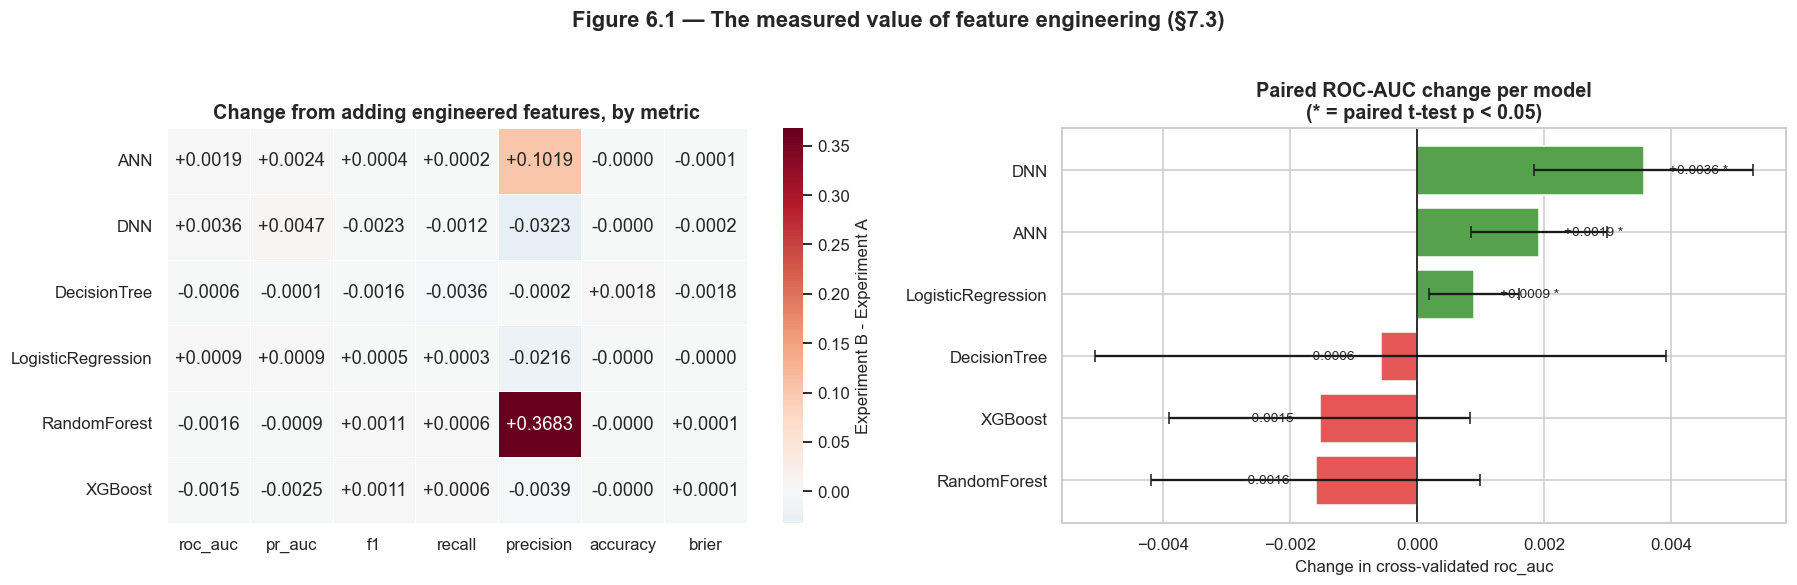

In [69]:
# ---- The same comparison across every metric -------------------------------
FE_EFFECT_ALL = pd.concat(
    [paired_experiment_delta(FOLDS_A, FOLDS_B, metric=m).assign(metric=m)
     for m in METRIC_COLS],
    ignore_index=True)

_pivot = FE_EFFECT_ALL.pivot(index="model", columns="metric", values="delta")
_pivot = _pivot[METRIC_COLS]

fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.2))

sns.heatmap(_pivot, annot=True, fmt="+.4f", cmap="RdBu_r", center=0,
            linewidths=0.6, cbar_kws={"label": "Experiment B - Experiment A"},
            ax=axes[0])
axes[0].set_title("Change from adding engineered features, by metric")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

_d = FE_EFFECT.sort_values("delta")
axes[1].barh(_d.model, _d.delta, xerr=_d.delta_std, capsize=4,
             color=[C_ACCENT if v > 0 else C_CHURN for v in _d.delta])
axes[1].axvline(0, color="black", lw=1)
for y, (v, p) in enumerate(zip(_d.delta, _d.ttest_p)):
    axes[1].text(v + (0.0004 if v >= 0 else -0.0004), y,
                 f"{v:+.4f}{' *' if p < 0.05 else ''}",
                 va="center", ha="left" if v >= 0 else "right", fontsize=9)
axes[1].set_xlabel(f"Change in cross-validated {PRIMARY_METRIC}")
axes[1].set_title("Paired ROC-AUC change per model\n(* = paired t-test p < 0.05)")

fig.suptitle("Figure 6.1 — The measured value of feature engineering (§7.3)",
             fontweight="semibold", y=1.02)
savefig("fig_6_1_fe_effect")
plt.show()

### Step 6.2b — Read the result honestly

Three outcomes are possible and all three are reportable findings:

- **Uniform improvement** — §7.3's claim is supported on this dataset.
- **Improvement concentrated in some model families** — the engineered features
  supply structure that certain algorithms cannot recover on their own. A large
  gain for a linear model with a small gain for gradient boosting is the classic
  signature: boosting can *construct* similar ratios internally through splits,
  a linear model cannot.
- **No detectable change** — the raw features already contain the signal, and
  §7.3's claim does not hold here. This is a legitimate negative result and is
  reported as such.

In [70]:
# ---- Summarise the Experiment A -> B verdict -------------------------------
_ml = FE_EFFECT[FE_EFFECT.model.isin(ml_model_registry())]
_dl = FE_EFFECT[FE_EFFECT.model.isin(DL_BUILDERS)]

FE_VERDICT_B = pd.DataFrame([
    ("Models improved", f"{int((FE_EFFECT.delta > 0).sum())} of {len(FE_EFFECT)}"),
    ("Significant improvements (p<0.05)",
     f"{int(((FE_EFFECT.delta > 0) & (FE_EFFECT.ttest_p < 0.05)).sum())}"),
    ("Significant degradations (p<0.05)",
     f"{int(((FE_EFFECT.delta < 0) & (FE_EFFECT.ttest_p < 0.05)).sum())}"),
    ("Mean AUC change, ML models", f"{_ml.delta.mean():+.5f}"),
    ("Mean AUC change, DL models", f"{_dl.delta.mean():+.5f}"),
    ("Largest gain",
     f"{FE_EFFECT.model.iloc[0]} {FE_EFFECT.delta.iloc[0]:+.5f} "
     f"(d_z = {FE_EFFECT.cohens_dz.iloc[0]:.2f})"),
    ("Largest loss",
     f"{FE_EFFECT.model.iloc[-1]} {FE_EFFECT.delta.iloc[-1]:+.5f} "
     f"(d_z = {FE_EFFECT.cohens_dz.iloc[-1]:.2f})"),
    ("Features added",
     f"{len(ENGINEERED_FEATURES) - len(BASELINE_FEATURES)} "
     f"({len(BASELINE_FEATURES)} -> {len(ENGINEERED_FEATURES)})"),
    ("Best model overall after B",
     f"{SUMMARY_B.model.iloc[0]} ({SUMMARY_B[PRIMARY_METRIC].iloc[0]:.4f})"),
], columns=["measure", "value"])

# Which of the three anticipated outcomes actually occurred? Answered from the
# data rather than asserted, because the pattern is the interesting part.
_gainers = FE_EFFECT.loc[(FE_EFFECT.delta > 0) & (FE_EFFECT.ttest_p < 0.05), "model"].tolist()
_losers = FE_EFFECT.loc[(FE_EFFECT.delta < 0) & (FE_EFFECT.ttest_p < 0.05), "model"].tolist()
_tree_models = [m for m in ("DecisionTree", "RandomForest", "XGBoost") if m in set(FE_EFFECT.model)]
_tree_gained = [m for m in _gainers if m in _tree_models]
_nontree_gained = [m for m in _gainers if m not in _tree_models]

if not _gainers:
    _pattern = ("no model improved — the raw features already contain the signal, "
                "and §7.3's claim does not hold on this dataset")
elif len(_gainers) == len(FE_EFFECT):
    _pattern = "every model improved — §7.3's claim is supported without qualification"
elif _nontree_gained and not _tree_gained:
    _pattern = (f"improvement is confined to the models that cannot build ratios "
                f"internally ({', '.join(_nontree_gained)}); the tree ensembles "
                f"({', '.join(_tree_models)}) gained nothing, because axis-aligned "
                f"splits can already approximate these transforms")
else:
    _pattern = (f"improvement is concentrated in {', '.join(_gainers)}"
                + (f"; {', '.join(_losers)} were degraded" if _losers else ""))

FE_VERDICT_B = pd.concat([FE_VERDICT_B, pd.DataFrame(
    [("PATTERN", _pattern)], columns=["measure", "value"])], ignore_index=True)
FE_VERDICT_B

,measure,value
0,Models improved,3 of 6
1,Significant improvements (p<0.05),3
2,Significant degradations (p<0.05),0
3,"Mean AUC change, ML models",-0.00070
4,"Mean AUC change, DL models",+0.00274
5,Largest gain,DNN +0.00357 (d_z = 2.07)
6,Largest loss,RandomForest -0.00159 (d_z = -0.61)
7,Features added,22 (29 -> 51)
8,Best model overall after B,LogisticRegression (0.6873)
9,PATTERN,improvement is confined to the models that can...


## 6.3 Deciding which feature set goes forward

### Step 6.3 — Fix the feature set for hyperparameter tuning

Part 7 tunes on one feature set. The rule, again stated in advance: **carry
forward whichever set produced the higher mean ROC-AUC across all six models.**
Where the two are within noise, the engineered set is preferred anyway, because
Part 10's interpretability analysis is materially richer with the derived
behavioural features present — and §7.8 makes interpretability an explicit
objective of this study, not an afterthought.

In [71]:
# ---- Select the feature set for Experiment C -------------------------------
_mean_a = SUMMARY_A[PRIMARY_METRIC].mean()
_mean_b = SUMMARY_B[PRIMARY_METRIC].mean()
TUNING_FEATURE_SET = "engineered" if _mean_b >= _mean_a else "baseline"

print(f"Mean {PRIMARY_METRIC} across all six models")
print(f"  Experiment A (baseline features)   : {_mean_a:.5f}")
print(f"  Experiment B (engineered features) : {_mean_b:.5f}")
print(f"  Difference                         : {_mean_b - _mean_a:+.5f}")
print(f"\nFeature set carried into Experiment C: '{TUNING_FEATURE_SET}' "
      f"({len(FEATURE_SETS[TUNING_FEATURE_SET]['features'])} features)")

Mean roc_auc across all six models
  Experiment A (baseline features)   : 0.65206
  Experiment B (engineered features) : 0.65251
  Difference                         : +0.00045

Feature set carried into Experiment C: 'engineered' (51 features)


---
# Part 7 — Experiment C: hyperparameter optimisation (§7.6)

The third and final training stage. The four ML algorithms are tuned on the
feature set selected in §6.3, using all three strategies §7.6 specifies:

| Strategy | Mechanism | What it costs |
|---|---|---|
| **Grid Search** | Exhaustive over a predefined grid | Fits = product of all grid dimensions |
| **Random Search** | Fixed number of draws from parameter distributions | Fits = budget, independent of dimensionality |
| **Optuna** | Tree-structured Parzen estimator with median pruning | Fits = trials, with unpromising trials stopped early |

Deep-learning models are **not tuned**, per §7.6 and §10(a). The proposal
justifies this on computational-feasibility grounds, and that justification is
the one carried here. (The proposal's *other* stated reason — that the dataset
is small — does not survive contact with 1,000,000 rows, where more data makes
tuning more rather than less worthwhile. Part 13 states plainly what this
asymmetry does and does not permit the study to conclude.)

**Every search runs inside the leakage-safe wrapper**, so each candidate
configuration is scored with preprocessing refitted on its own training folds.
Searching over a pre-transformed matrix would leak validation statistics into
every one of the hundreds of fits below.

## 7.1 Search spaces

### Step 7.1 — Define one search space per algorithm, shared by all three strategies

The three strategies must explore the **same region** of hyperparameter space,
otherwise the comparison measures the spaces rather than the strategies. Each
algorithm therefore gets a grid (for Grid Search), matching distributions (for
Random Search) and a matching sampler definition (for Optuna).

In [72]:
# ---- Shared search spaces for the four ML algorithms (§7.6) ----------------
from scipy.stats import loguniform, randint, uniform

# Parameters are addressed through the wrapper, hence the `base_estimator__` prefix.
SEARCH_SPACES = {
    "LogisticRegression": {
        "grid": {"base_estimator__C": [0.01, 0.1, 1.0, 10.0, 100.0]},
        "random": {"base_estimator__C": loguniform(1e-3, 1e2)},
        "optuna": lambda t: {
            "base_estimator__C": t.suggest_float("C", 1e-3, 1e2, log=True)},
    },
    "DecisionTree": {
        "grid": {"base_estimator__max_depth": [4, 6, 8, 12],
                 "base_estimator__min_samples_leaf": [20, 100, 500]},
        "random": {"base_estimator__max_depth": randint(3, 20),
                   "base_estimator__min_samples_leaf": randint(10, 800)},
        "optuna": lambda t: {
            "base_estimator__max_depth": t.suggest_int("max_depth", 3, 20),
            "base_estimator__min_samples_leaf": t.suggest_int("min_samples_leaf", 10, 800)},
    },
    "RandomForest": {
        "grid": {"base_estimator__n_estimators": [150, 300],
                 "base_estimator__max_depth": [8, 14, None],
                 "base_estimator__min_samples_leaf": [5, 30]},
        "random": {"base_estimator__n_estimators": randint(100, 400),
                   "base_estimator__max_depth": randint(5, 22),
                   "base_estimator__min_samples_leaf": randint(3, 120),
                   "base_estimator__max_features": uniform(0.3, 0.6)},
        "optuna": lambda t: {
            "base_estimator__n_estimators": t.suggest_int("n_estimators", 100, 400, step=50),
            "base_estimator__max_depth": t.suggest_int("max_depth", 5, 22),
            "base_estimator__min_samples_leaf": t.suggest_int("min_samples_leaf", 3, 120),
            "base_estimator__max_features": t.suggest_float("max_features", 0.3, 0.9)},
    },
    "XGBoost": {
        "grid": {"base_estimator__max_depth": [3, 5, 7],
                 "base_estimator__learning_rate": [0.05, 0.15],
                 "base_estimator__n_estimators": [200, 400]},
        "random": {"base_estimator__max_depth": randint(2, 10),
                   "base_estimator__learning_rate": loguniform(0.01, 0.3),
                   "base_estimator__n_estimators": randint(100, 500),
                   "base_estimator__subsample": uniform(0.6, 0.4),
                   "base_estimator__colsample_bytree": uniform(0.5, 0.5),
                   "base_estimator__reg_lambda": loguniform(0.5, 20)},
        "optuna": lambda t: {
            "base_estimator__max_depth": t.suggest_int("max_depth", 2, 10),
            "base_estimator__learning_rate": t.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "base_estimator__n_estimators": t.suggest_int("n_estimators", 100, 500, step=50),
            "base_estimator__subsample": t.suggest_float("subsample", 0.6, 1.0),
            "base_estimator__colsample_bytree": t.suggest_float("colsample_bytree", 0.5, 1.0),
            "base_estimator__reg_lambda": t.suggest_float("reg_lambda", 0.5, 20, log=True)},
    },
}

GRID_BUDGET = {k: int(np.prod([len(v) for v in sp["grid"].values()]))
               for k, sp in SEARCH_SPACES.items()}
print("Configurations evaluated per model:")
print(f"  Grid Search   : {GRID_BUDGET}  (exhaustive over the stated grid)")
print(f"  Random Search : {RANDOM_SEARCH_ITER} draws per model")
print(f"  Optuna        : {OPTUNA_TRIALS} trials per model")
print(f"\nThe budgets are NOT equal, because an exhaustive grid's size is fixed by")
print(f"the grid itself. Wall-clock alone would therefore compare budgets rather")
print(f"than strategies, so §7.4 also reports the peak each adaptive search had")
print(f"reached after Grid Search's number of configurations.")

Configurations evaluated per model:
  Grid Search   : {'LogisticRegression': 5, 'DecisionTree': 12, 'RandomForest': 12, 'XGBoost': 12}  (exhaustive over the stated grid)
  Random Search : 30 draws per model
  Optuna        : 30 trials per model

The budgets are NOT equal, because an exhaustive grid's size is fixed by
the grid itself. Wall-clock alone would therefore compare budgets rather
than strategies, so §7.4 also reports the peak each adaptive search had
reached after Grid Search's number of configurations.


In [73]:
# ---- Build a search-ready wrapper for a named algorithm --------------------
TUNE_SPEC = FEATURE_SETS[TUNING_FEATURE_SET]
HPO_CV_FOLDS = 3 if not QUICK_RUN else 2


def wrapped_estimator(model_name, **overrides):
    """Return a LeakageSafeClassifier around a fresh instance of the named model."""
    base = ml_model_registry()[model_name]
    if overrides:
        base.set_params(**{k.replace("base_estimator__", ""): v
                           for k, v in overrides.items()})
    return LeakageSafeClassifier(
        base,
        numeric_features=TUNE_SPEC["numeric"],
        categorical_features=TUNE_SPEC["categorical"],
        winsorise_cols=WINSORISE_COLS,
        imbalance=IMBALANCE_CHOICE,
        random_state=RANDOM_STATE,
    )


X_tune_f = X_tune[TUNE_SPEC["features"]]
print(f"Tuning on {len(y_tune):,} rows x {len(TUNE_SPEC['features'])} features, "
      f"{HPO_CV_FOLDS}-fold CV, scoring = {PRIMARY_METRIC}")

Tuning on 100,000 rows x 51 features, 3-fold CV, scoring = roc_auc


## 7.2 Grid Search and Random Search

### Step 7.2 — Run the two scikit-learn searches, recording wall-clock cost

Execution time is recorded for every search, because §7.6 and RQ4 are as much
about **efficiency** as about the peak score reached. A strategy that matches
another's accuracy at a third of the cost is the better strategy.

In [74]:
# ---- Grid Search and Random Search (§7.6) ----------------------------------
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

_hpo_cv = StratifiedKFold(n_splits=HPO_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SEARCH_RESULTS = []
BEST_CONFIGS = {}


def running_best_at(scores, k):
    """Best score reached within the first `k` configurations tried.

    This is what makes the three strategies comparable. Grid Search evaluates a
    fixed, usually smaller, number of configurations, so its lower wall-clock is
    partly just a smaller budget. Truncating the adaptive searches to the same
    budget removes that confound.
    """
    scores = np.asarray([sc for sc in scores if np.isfinite(sc)], dtype=float)
    if scores.size == 0:
        return np.nan
    return float(np.maximum.accumulate(scores)[:max(k, 1)][-1])


def record_search(model_name, strategy, search, elapsed):
    """Validate and store the outcome of one completed search."""
    # A non-finite best score is the signature of the scikit-learn estimator-type
    # failure guarded in §3.3c: the search would "succeed" while choosing at random.
    if not np.isfinite(search.best_score_):
        raise RuntimeError(
            f"{strategy} on {model_name} returned a non-finite score. The estimator "
            f"is not being recognised as a classifier — see the guard in §3.3c.")

    n_configs = len(search.cv_results_["params"])
    n_fits = n_configs * HPO_CV_FOLDS
    budget = GRID_BUDGET[model_name]
    SEARCH_RESULTS.append({
        "model": model_name, "strategy": strategy,
        "best_cv_auc": search.best_score_,
        # Peak reached within Grid Search's configuration budget for this model.
        "auc_at_grid_budget": running_best_at(
            search.cv_results_["mean_test_score"], budget),
        "search_seconds": elapsed,
        "n_configs": n_configs,
        "n_fits": n_fits,
        "seconds_per_fit": elapsed / max(n_fits, 1),
        "best_params": json.dumps(
            {k.replace("base_estimator__", ""): (round(v, 5) if isinstance(v, float) else v)
             for k, v in search.best_params_.items()}),
    })
    BEST_CONFIGS[(model_name, strategy)] = dict(search.best_params_)
    print(f"    best AUC {search.best_score_:.5f} | {elapsed:6.1f}s | "
          f"{n_fits} fits | {search.best_params_}")


for model_name, space in SEARCH_SPACES.items():
    print(f"\n[{model_name}]")

    print("  Grid Search")
    t0 = time.perf_counter()
    gs = GridSearchCV(wrapped_estimator(model_name), space["grid"], cv=_hpo_cv,
                      scoring=PRIMARY_METRIC, n_jobs=1, refit=True,
                      error_score="raise")
    gs.fit(X_tune_f, y_tune)
    record_search(model_name, "GridSearch", gs, time.perf_counter() - t0)

    print("  Random Search")
    t0 = time.perf_counter()
    rs = RandomizedSearchCV(wrapped_estimator(model_name), space["random"],
                            n_iter=RANDOM_SEARCH_ITER, cv=_hpo_cv,
                            scoring=PRIMARY_METRIC, n_jobs=1, refit=True,
                            random_state=RANDOM_STATE, error_score="raise")
    rs.fit(X_tune_f, y_tune)
    record_search(model_name, "RandomSearch", rs, time.perf_counter() - t0)


[LogisticRegression]
  Grid Search


    best AUC 0.68844 |    8.8s | 15 fits | {'base_estimator__C': 0.01}
  Random Search


    best AUC 0.68863 |   47.7s | 90 fits | {'base_estimator__C': 0.0017070728830306638}

[DecisionTree]
  Grid Search


    best AUC 0.66844 |   39.2s | 36 fits | {'base_estimator__max_depth': 6, 'base_estimator__min_samples_leaf': 500}
  Random Search


    best AUC 0.66954 |   99.1s | 90 fits | {'base_estimator__max_depth': 6, 'base_estimator__min_samples_leaf': 673}

[RandomForest]
  Grid Search


    best AUC 0.68379 |  158.1s | 36 fits | {'base_estimator__max_depth': 8, 'base_estimator__min_samples_leaf': 30, 'base_estimator__n_estimators': 300}
  Random Search


    best AUC 0.68225 | 1661.5s | 90 fits | {'base_estimator__max_depth': 14, 'base_estimator__max_features': 0.32799939792816923, 'base_estimator__min_samples_leaf': 62, 'base_estimator__n_estimators': 370}

[XGBoost]
  Grid Search


    best AUC 0.68518 |   46.9s | 36 fits | {'base_estimator__learning_rate': 0.05, 'base_estimator__max_depth': 3, 'base_estimator__n_estimators': 200}
  Random Search


    best AUC 0.68578 |  131.6s | 90 fits | {'base_estimator__colsample_bytree': 0.6360661246923176, 'base_estimator__learning_rate': 0.09051422630641873, 'base_estimator__max_depth': 2, 'base_estimator__n_estimators': 215, 'base_estimator__reg_lambda': 1.8357201002488213, 'base_estimator__subsample': 0.7219125032632117}


## 7.3 Optuna

### Step 7.3 — Bayesian optimisation with median pruning

Optuna differs from the two searches above in two ways that matter for RQ4. Its
**TPE sampler** conditions each proposal on the outcomes of previous trials
instead of sampling blindly, and its **median pruner** abandons a trial whose
intermediate fold scores fall below the running median — which is where its
efficiency advantage is supposed to come from.

Pruning is implemented at fold granularity: each trial reports its score after
every fold, and can be stopped before completing the rest.

In [75]:
# ---- Optuna: TPE sampling with median pruning (§7.6) -----------------------
import optuna
from sklearn.model_selection import cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
OPTUNA_STUDIES = {}


def optuna_objective_factory(model_name, suggest):
    """Build an Optuna objective that reports per-fold scores so pruning can act."""

    def objective(trial):
        params = suggest(trial)
        estimator = wrapped_estimator(model_name, **params)

        scores = []
        for step, (tr, va) in enumerate(_hpo_cv.split(X_tune_f, y_tune)):
            estimator.fit(X_tune_f.iloc[tr], y_tune.iloc[tr])
            proba = estimator.predict_proba(X_tune_f.iloc[va])[:, 1]
            scores.append(roc_auc_score(y_tune.iloc[va], proba))

            # Report early so an unpromising trial can be pruned mid-CV.
            trial.report(float(np.mean(scores)), step)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(scores))

    return objective


for model_name, space in SEARCH_SPACES.items():
    print(f"\n[{model_name}] Optuna")
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
        study_name=f"{model_name}_tpe",
    )
    t0 = time.perf_counter()
    study.optimize(optuna_objective_factory(model_name, space["optuna"]),
                   n_trials=OPTUNA_TRIALS, show_progress_bar=False)
    elapsed = time.perf_counter() - t0

    completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    pruned = [t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED]
    if not completed:
        raise RuntimeError(f"Optuna completed no trials for {model_name}.")

    n_fits = len(completed) * HPO_CV_FOLDS + sum(
        len(t.intermediate_values) for t in pruned)
    SEARCH_RESULTS.append({
        "model": model_name, "strategy": "Optuna",
        "best_cv_auc": study.best_value,
        "auc_at_grid_budget": running_best_at(
            [t.value for t in study.trials if t.value is not None],
            GRID_BUDGET[model_name]),
        "search_seconds": elapsed,
        "n_configs": len(study.trials),
        "n_fits": n_fits,
        "seconds_per_fit": elapsed / max(n_fits, 1),
        "best_params": json.dumps(
            {k: (round(v, 5) if isinstance(v, float) else v)
             for k, v in study.best_params.items()}),
    })
    BEST_CONFIGS[(model_name, "Optuna")] = {
        f"base_estimator__{k}": v for k, v in study.best_params.items()}
    OPTUNA_STUDIES[model_name] = study

    print(f"    best AUC {study.best_value:.5f} | {elapsed:6.1f}s | "
          f"{len(completed)} complete, {len(pruned)} pruned "
          f"({100 * len(pruned) / max(len(study.trials), 1):.0f}% saved) | "
          f"{study.best_params}")

SEARCH_TABLE = pd.DataFrame(SEARCH_RESULTS)
SEARCH_TABLE.round(5)


[LogisticRegression] Optuna


    best AUC 0.68864 |   40.1s | 18 complete, 12 pruned (40% saved) | {'C': 0.0021475519707338043}

[DecisionTree] Optuna


    best AUC 0.66906 |   84.2s | 20 complete, 10 pruned (33% saved) | {'max_depth': 8, 'min_samples_leaf': 659}

[RandomForest] Optuna


    best AUC 0.68290 | 1363.4s | 20 complete, 10 pruned (33% saved) | {'n_estimators': 350, 'max_depth': 9, 'min_samples_leaf': 88, 'max_features': 0.4275782177581846}

[XGBoost] Optuna


    best AUC 0.68658 |  102.6s | 24 complete, 6 pruned (20% saved) | {'max_depth': 2, 'learning_rate': 0.04858727510228203, 'n_estimators': 250, 'subsample': 0.6452606057786048, 'colsample_bytree': 0.8429018536569842, 'reg_lambda': 12.706186666837047}


,model,strategy,best_cv_auc,auc_at_grid_budget,search_seconds,n_configs,n_fits,seconds_per_fit,best_params
0,LogisticRegression,GridSearch,0.6884,0.6884,8.7952,5,15,0.5863,"{""C"": 0.01}"
1,LogisticRegression,RandomSearch,0.6886,0.6885,47.7149,30,90,0.5302,"{""C"": 0.00171}"
2,DecisionTree,GridSearch,0.6684,0.6684,39.2120,12,36,1.0892,"{""max_depth"": 6, ""min_samples_leaf"": 500}"
3,DecisionTree,RandomSearch,0.6695,0.6695,99.1017,30,90,1.1011,"{""max_depth"": 6, ""min_samples_leaf"": 673}"
4,RandomForest,GridSearch,0.6838,0.6838,158.1185,12,36,4.3922,"{""max_depth"": 8, ""min_samples_leaf"": 30, ""n_es..."
5,RandomForest,RandomSearch,0.6823,0.6823,"1,661.4911",30,90,18.4610,"{""max_depth"": 14, ""max_features"": 0.328, ""min_..."
6,XGBoost,GridSearch,0.6852,0.6852,46.8504,12,36,1.3014,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_est..."
7,XGBoost,RandomSearch,0.6858,0.6845,131.5797,30,90,1.4620,"{""colsample_bytree"": 0.63607, ""learning_rate"":..."
8,LogisticRegression,Optuna,0.6886,0.6885,40.1431,30,78,0.5147,"{""C"": 0.00215}"
9,DecisionTree,Optuna,0.6691,0.6688,84.2354,30,80,1.0529,"{""max_depth"": 8, ""min_samples_leaf"": 659}"


## 7.4 Which search strategy wins, and at what cost? (RQ4)

### Step 7.4 — Compare peak score against cost, at equal and unequal budgets

Two comparisons are reported, and they answer different questions.

**Full budget** — what each strategy achieved with the budget it was given. This
is the practically relevant number, but it is *not* a fair test of the
strategies, because an exhaustive grid's size is fixed by the grid while the
adaptive searches were given a round-number budget of their own.

**Matched budget** — what each adaptive search had already found after Grid
Search's number of configurations. This isolates the strategy from the budget,
and is the comparison RQ4 actually asks for.

Wall-clock is reported alongside both, with the number of fits, because a
strategy that explores more expensive configurations will take longer per fit
even at an identical budget — another confound that raw seconds would hide.

In [76]:
# ---- Research question 4: strategy comparison ------------------------------
_auc_pivot = SEARCH_TABLE.pivot(index="model", columns="strategy", values="best_cv_auc")
_time_pivot = SEARCH_TABLE.pivot(index="model", columns="strategy", values="search_seconds")

_strats = ["GridSearch", "RandomSearch", "Optuna"]
_auc_pivot["best_strategy"] = _auc_pivot[_strats].idxmax(axis=1)
_auc_pivot["spread"] = _auc_pivot[_strats].max(axis=1) - _auc_pivot[_strats].min(axis=1)

# Budget-matched view: what had each search found after Grid's configuration count?
_matched = SEARCH_TABLE.pivot(index="model", columns="strategy",
                              values="auc_at_grid_budget")
_matched["best_strategy"] = _matched[_strats].idxmax(axis=1)
_matched["spread"] = _matched[_strats].max(axis=1) - _matched[_strats].min(axis=1)

_fits_pivot = SEARCH_TABLE.pivot(index="model", columns="strategy", values="n_fits")

print("Best CV AUC reached, full budget:")
print(_auc_pivot[_strats + ["best_strategy", "spread"]].round(5))
print("\nBest CV AUC reached at GRID SEARCH's configuration budget (like for like):")
print(_matched[_strats + ["best_strategy", "spread"]].round(5))
print("\nModel fits actually performed:")
print(_fits_pivot)
print("\nSearch wall-clock seconds:")
print(_time_pivot.round(1))
print("\nStrategy wins, full budget    :", _auc_pivot.best_strategy.value_counts().to_dict())
print("Strategy wins, matched budget :", _matched.best_strategy.value_counts().to_dict())
print(f"\nMedian AUC spread across strategies within a model: "
      f"{_auc_pivot['spread'].median():.5f} (full budget), "
      f"{_matched['spread'].median():.5f} (matched budget)")
print(f"Optuna trials pruned before completing all folds: "
      f"{int((SEARCH_TABLE.loc[SEARCH_TABLE.strategy == 'Optuna', 'n_configs'] * HPO_CV_FOLDS - SEARCH_TABLE.loc[SEARCH_TABLE.strategy == 'Optuna', 'n_fits']).sum())} "
      f"fits saved across the four models")

Best CV AUC reached, full budget:
strategy            GridSearch  RandomSearch  Optuna best_strategy  spread
model                                                                     
DecisionTree            0.6684        0.6695  0.6691  RandomSearch  0.0011
LogisticRegression      0.6884        0.6886  0.6886        Optuna  0.0002
RandomForest            0.6838        0.6823  0.6829    GridSearch  0.0015
XGBoost                 0.6852        0.6858  0.6866        Optuna  0.0014

Best CV AUC reached at GRID SEARCH's configuration budget (like for like):
strategy            GridSearch  RandomSearch  Optuna best_strategy  spread
model                                                                     
DecisionTree            0.6684        0.6695  0.6688  RandomSearch  0.0011
LogisticRegression      0.6884        0.6885  0.6885  RandomSearch  0.0001
RandomForest            0.6838        0.6823  0.6825    GridSearch  0.0015
XGBoost                 0.6852        0.6845  0.6857        Optun

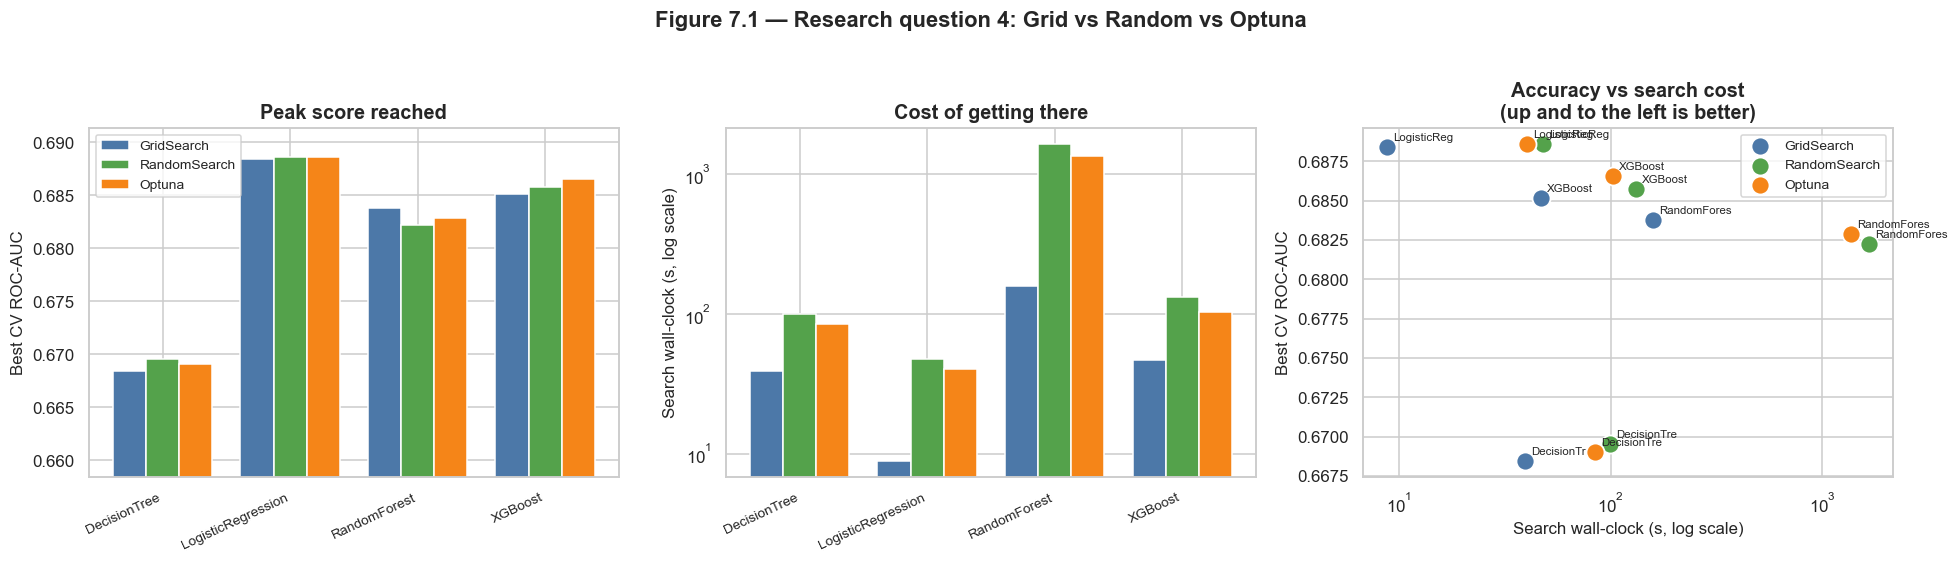

In [77]:
# ---- Visualise accuracy against cost ---------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
_strategies = ["GridSearch", "RandomSearch", "Optuna"]
_strategy_colours = dict(zip(_strategies, [C_STAY, C_ACCENT, C_DL]))

x = np.arange(len(_auc_pivot))
width = 0.26
for i, s in enumerate(_strategies):
    axes[0].bar(x + i * width - width, _auc_pivot[s], width, label=s,
                color=_strategy_colours[s])
axes[0].set_xticks(x)
axes[0].set_xticklabels(_auc_pivot.index, rotation=25, ha="right", fontsize=9)
axes[0].set_ylabel("Best CV ROC-AUC")
axes[0].set_ylim(_auc_pivot[_strategies].min().min() * 0.985,
                 _auc_pivot[_strategies].max().max() * 1.004)
axes[0].set_title("Peak score reached")
axes[0].legend(fontsize=9)

for i, s in enumerate(_strategies):
    axes[1].bar(x + i * width - width, _time_pivot[s], width, label=s,
                color=_strategy_colours[s])
axes[1].set_xticks(x)
axes[1].set_xticklabels(_time_pivot.index, rotation=25, ha="right", fontsize=9)
axes[1].set_yscale("log")
axes[1].set_ylabel("Search wall-clock (s, log scale)")
axes[1].set_title("Cost of getting there")

for s in _strategies:
    sub = SEARCH_TABLE[SEARCH_TABLE.strategy == s]
    axes[2].scatter(sub.search_seconds, sub.best_cv_auc, s=140,
                    color=_strategy_colours[s], label=s,
                    edgecolors="white", linewidths=1.2, zorder=3)
    for _, r in sub.iterrows():
        axes[2].annotate(r.model[:11], (r.search_seconds, r.best_cv_auc),
                         fontsize=7.5, xytext=(4, 4), textcoords="offset points")
axes[2].set_xscale("log")
axes[2].set_xlabel("Search wall-clock (s, log scale)")
axes[2].set_ylabel("Best CV ROC-AUC")
axes[2].set_title("Accuracy vs search cost\n(up and to the left is better)")
axes[2].legend(fontsize=9)

fig.suptitle("Figure 7.1 — Research question 4: Grid vs Random vs Optuna",
             fontweight="semibold", y=1.02)
savefig("fig_7_1_hpo_strategies")
plt.show()

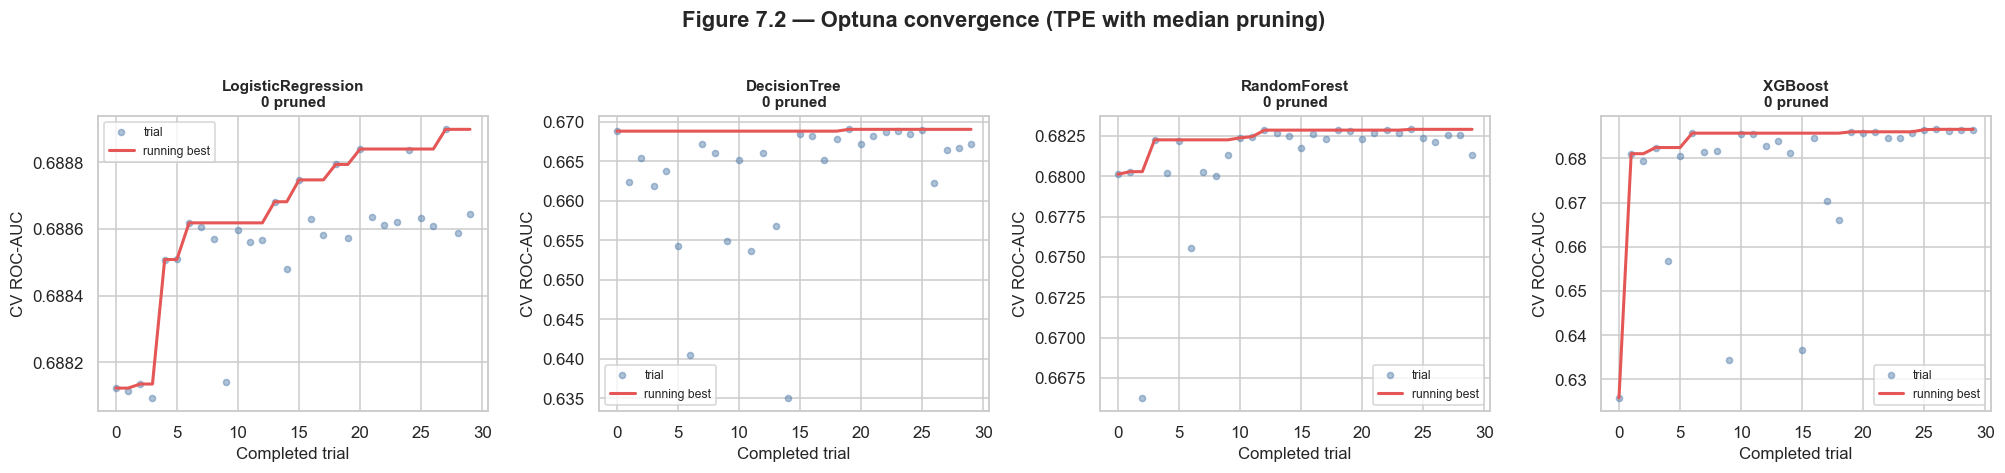

In [78]:
# ---- Optuna diagnostics: does the TPE sampler actually converge? -----------
_studies = list(OPTUNA_STUDIES.items())
fig, axes = plt.subplots(1, len(_studies), figsize=(4.6 * len(_studies), 4.2),
                         squeeze=False)

for ax, (name, study) in zip(axes[0], _studies):
    completed = [t for t in study.trials if t.value is not None]
    values = [t.value for t in completed]
    running_best = np.maximum.accumulate(values)
    ax.plot(range(len(values)), values, "o", ms=4, alpha=0.45,
            color=C_STAY, label="trial")
    ax.plot(range(len(values)), running_best, "-", lw=2,
            color=C_CHURN, label="running best")
    ax.set_xlabel("Completed trial")
    ax.set_ylabel("CV ROC-AUC")
    ax.set_title(f"{name}\n{len(study.trials) - len(completed)} pruned", fontsize=10)
    ax.legend(fontsize=8)

fig.suptitle("Figure 7.2 — Optuna convergence (TPE with median pruning)",
             fontweight="semibold", y=1.02)
savefig("fig_7_2_optuna_convergence")
plt.show()

## 7.5 Scoring the tuned models under the common protocol

### Step 7.5 — Re-evaluate the tuned configurations on the development sample

The searches were scored on the tuning subsample with their own internal CV.
Those numbers are **not comparable** to Experiments A and B, which ran on the
larger development sample with a different fold count.

To place all three experiments on one leaderboard, each model's **best
configuration across the three strategies** is re-evaluated here through
`evaluate_cv` — the identical harness, sample and folds used in Parts 5 and 6.

In [79]:
# ---- Experiment C: tuned models under the Experiment A/B protocol ---------
TUNED_MODELS = {}
_tuned_provenance = []

for model_name in SEARCH_SPACES:
    rows = SEARCH_TABLE[SEARCH_TABLE.model == model_name]
    best_row = rows.loc[rows.best_cv_auc.idxmax()]
    params = BEST_CONFIGS[(model_name, best_row.strategy)]

    estimator = ml_model_registry()[model_name]
    estimator.set_params(**{k.replace("base_estimator__", ""): v
                            for k, v in params.items()})
    TUNED_MODELS[model_name] = estimator

    _tuned_provenance.append({
        "model": model_name,
        "winning_strategy": best_row.strategy,
        "search_cv_auc": best_row.best_cv_auc,
        "search_seconds": best_row.search_seconds,
        "params": best_row.best_params,
    })

TUNED_PROVENANCE = pd.DataFrame(_tuned_provenance)
print("Configuration carried forward per model:")
print(TUNED_PROVENANCE[["model", "winning_strategy", "search_cv_auc"]].round(5)
      .to_string(index=False))

print(f"\nEXPERIMENT C — tuned ML models, {TUNING_FEATURE_SET} features "
      f"({len(TUNE_SPEC['features'])} features, imbalance='{IMBALANCE_CHOICE}')\n")
FOLDS_C, SUMMARY_C = evaluate_cv(
    TUNED_MODELS, X_dev, y_dev, feature_set=TUNING_FEATURE_SET,
    imbalance=IMBALANCE_CHOICE, n_splits=N_SPLITS, label="C_tuned")

SUMMARY_C[["model", "family"] + METRIC_COLS +
          ["train_seconds", "infer_ms_per_sample"]].round(4)

Configuration carried forward per model:
             model winning_strategy  search_cv_auc
LogisticRegression           Optuna         0.6886
      DecisionTree     RandomSearch         0.6695
      RandomForest       GridSearch         0.6838
           XGBoost           Optuna         0.6866

EXPERIMENT C — tuned ML models, engineered features (51 features, imbalance='none')



  LogisticRegression     5 folds in 6.2s


  DecisionTree           5 folds in 12.6s


  RandomForest           5 folds in 62.6s


  XGBoost                5 folds in 9.3s


,model,family,roc_auc,pr_auc,f1,recall,precision,accuracy,brier,train_seconds,infer_ms_per_sample
0,LogisticRegression,ML,0.6874,0.2029,0.0065,0.0033,0.5426,0.9008,0.0852,1.1204,0.0017
1,XGBoost,ML,0.6868,0.2046,0.0043,0.0022,0.6052,0.9008,0.0852,1.7540,0.0018
2,RandomForest,ML,0.6831,0.2002,0.0000,0.0000,0.0000,0.9008,0.0856,12.2541,0.0058
3,DecisionTree,ML,0.6719,0.1803,0.0000,0.0000,0.0000,0.9008,0.0861,2.3868,0.0016


In [80]:
# ---- Did tuning actually pay? Paired against Experiment B -----------------
TUNING_EFFECT = paired_experiment_delta(
    FOLDS_B[FOLDS_B.model.isin(TUNED_MODELS)], FOLDS_C,
    label_before="B", label_after="C")
TUNING_EFFECT["verdict"] = np.where(
    (TUNING_EFFECT.ttest_p < 0.05) & (TUNING_EFFECT.delta > 0), "improved (significant)",
    np.where((TUNING_EFFECT.ttest_p < 0.05) & (TUNING_EFFECT.delta < 0),
             "DEGRADED (significant)", "no detectable change"))

print(f"Paired effect of hyperparameter tuning on {PRIMARY_METRIC}:\n")
TUNING_EFFECT.round(5)

Paired effect of hyperparameter tuning on roc_auc:



,model,roc_auc_B,roc_auc_C,delta,delta_std,cohens_dz,ttest_p,wilcoxon_p,folds_improved,n_folds,verdict
0,DecisionTree,0.5217,0.6719,0.1501,0.0045,33.1046,0.0000,0.0625,5,5,improved (significant)
1,XGBoost,0.6679,0.6868,0.0189,0.0018,10.7551,0.0000,0.0625,5,5,improved (significant)
2,RandomForest,0.6706,0.6831,0.0125,0.0023,5.4055,0.0003,0.0625,5,5,improved (significant)
3,LogisticRegression,0.6873,0.6875,0.0002,0.0001,1.3502,0.0383,0.0625,5,5,improved (significant)


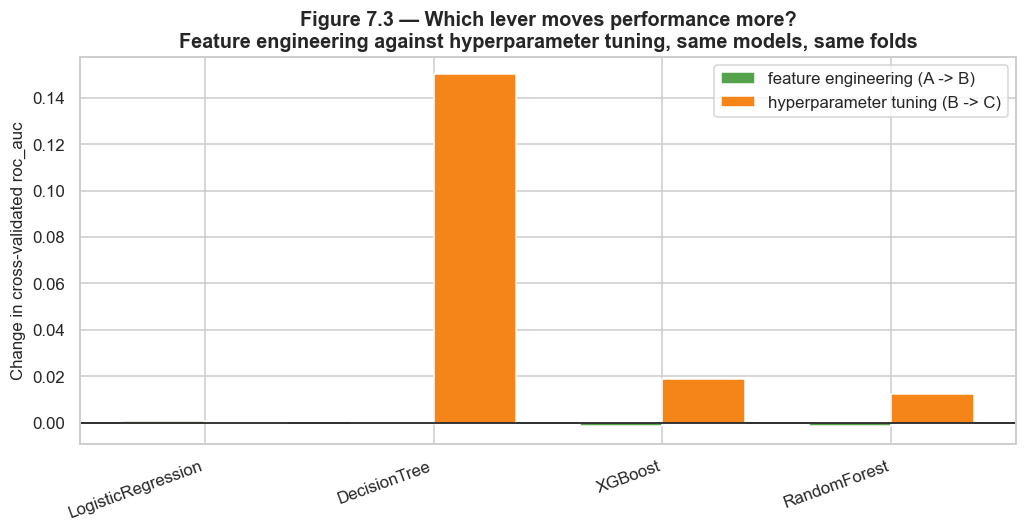

Mean AUC gain per lever:
  feature engineering  : -0.00070
  hyperparameter tuning: +0.04544


In [81]:
# ---- Feature engineering vs tuning, side by side --------------------------
_fe = FE_EFFECT[FE_EFFECT.model.isin(TUNED_MODELS)][["model", "delta"]].rename(
    columns={"delta": "feature engineering (A -> B)"})
_tune = TUNING_EFFECT[["model", "delta"]].rename(
    columns={"delta": "hyperparameter tuning (B -> C)"})
LEVER_COMPARISON = _fe.merge(_tune, on="model")

fig, ax = plt.subplots(figsize=(9.5, 5))
x = np.arange(len(LEVER_COMPARISON))
width = 0.36
ax.bar(x - width / 2, LEVER_COMPARISON["feature engineering (A -> B)"], width,
       label="feature engineering (A -> B)", color=C_ACCENT)
ax.bar(x + width / 2, LEVER_COMPARISON["hyperparameter tuning (B -> C)"], width,
       label="hyperparameter tuning (B -> C)", color=C_DL)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x)
ax.set_xticklabels(LEVER_COMPARISON.model, rotation=20, ha="right")
ax.set_ylabel(f"Change in cross-validated {PRIMARY_METRIC}")
ax.set_title("Figure 7.3 — Which lever moves performance more?\n"
             "Feature engineering against hyperparameter tuning, same models, same folds")
ax.legend()
savefig("fig_7_3_levers")
plt.show()

print("Mean AUC gain per lever:")
print(f"  feature engineering  : {LEVER_COMPARISON['feature engineering (A -> B)'].mean():+.5f}")
print(f"  hyperparameter tuning: {LEVER_COMPARISON['hyperparameter tuning (B -> C)'].mean():+.5f}")

---
# Part 8 — Consolidated comparison and champion selection

Sixteen model configurations have now been evaluated — six in Experiment A, six
in Experiment B, four in Experiment C — all through the same harness, on the
same development sample, with the same folds and the same seed.

This part puts them on **one leaderboard**, applies a pre-stated selection rule,
and names the champion that Parts 10 to 12 then analyse in depth.

## 8.1 The unified leaderboard

> **Reading the threshold-dependent columns.** Precision, recall, F1 and accuracy
> in this table are computed at the fixed 0.5 cut-off (§4.1), so that every model
> is compared on identical terms. Under the imbalance treatment selected in
> §5.2b, a 0.5 cut-off can leave a well-calibrated model predicting almost no
> churners at all — at a 9:1 class ratio very few customers exceed 50% churn
> probability — which is why some rows show recall near zero. **This is a
> property of the cut-off, not of the model.** Part 11 derives a proper operating
> threshold for each model from its own out-of-fold predictions, and the recall
> figures there are the ones that describe deployed behaviour. Ranking here is
> done on ROC-AUC, which is threshold-free and therefore unaffected.

### Step 8.1 — Concatenate all three experiments into a single ranked table

In [82]:
# ---- One leaderboard across Experiments A, B and C ------------------------
EXPERIMENT_LABELS = {
    "A_baseline_features": "A · default params, baseline features",
    "B_engineered_features": "B · default params, engineered features",
    "C_tuned": "C · tuned params, engineered features",
}

LEADERBOARD = pd.concat([SUMMARY_A, SUMMARY_B, SUMMARY_C], ignore_index=True)
LEADERBOARD["configuration"] = LEADERBOARD.experiment.map(EXPERIMENT_LABELS)
LEADERBOARD["candidate"] = (LEADERBOARD.model + "  ["
                            + LEADERBOARD.experiment.str[0] + "]")
LEADERBOARD = (LEADERBOARD.sort_values(PRIMARY_METRIC, ascending=False)
               .reset_index(drop=True))
LEADERBOARD["rank"] = np.arange(1, len(LEADERBOARD) + 1)

ALL_FOLDS = pd.concat([FOLDS_A, FOLDS_B, FOLDS_C], ignore_index=True)
ALL_FOLDS["candidate"] = ALL_FOLDS.model + "  [" + ALL_FOLDS.experiment.str[0] + "]"

LEADERBOARD[["rank", "candidate", "family", "configuration"] + METRIC_COLS +
            ["train_seconds", "infer_ms_per_sample"]].round(4)

,rank,candidate,family,configuration,roc_auc,pr_auc,f1,recall,precision,accuracy,brier,train_seconds,infer_ms_per_sample
0,1,LogisticRegression [C],ML,"C · tuned params, engineered features",0.6874,0.2029,0.0065,0.0033,0.5426,0.9008,0.0852,1.1204,0.0017
1,2,LogisticRegression [B],ML,"B · default params, engineered features",0.6873,0.2030,0.0075,0.0038,0.4991,0.9008,0.0852,1.1217,0.0016
2,3,XGBoost [C],ML,"C · tuned params, engineered features",0.6868,0.2046,0.0043,0.0022,0.6052,0.9008,0.0852,1.7540,0.0018
3,4,LogisticRegression [A],ML,"A · default params, baseline features",0.6864,0.2021,0.0070,0.0035,0.5207,0.9008,0.0853,0.7339,0.0012
4,5,ANN [B],DL,"B · default params, engineered features",0.6837,0.2011,0.0018,0.0009,0.7250,0.9008,0.0855,7.6998,0.0033
5,6,DNN [B],DL,"B · default params, engineered features",0.6837,0.2017,0.0007,0.0004,0.7500,0.9008,0.0854,19.0212,0.0042
6,7,RandomForest [C],ML,"C · tuned params, engineered features",0.6831,0.2002,0.0000,0.0000,0.0000,0.9008,0.0856,12.2541,0.0058
7,8,ANN [A],DL,"A · default params, baseline features",0.6818,0.1987,0.0014,0.0007,0.6231,0.9008,0.0855,9.8636,0.0029
8,9,DNN [A],DL,"A · default params, baseline features",0.6802,0.1970,0.0030,0.0015,0.7823,0.9008,0.0856,28.8353,0.0036
9,10,RandomForest [A],ML,"A · default params, baseline features",0.6722,0.1928,0.0000,0.0000,0.0000,0.9008,0.0859,8.8413,0.0077


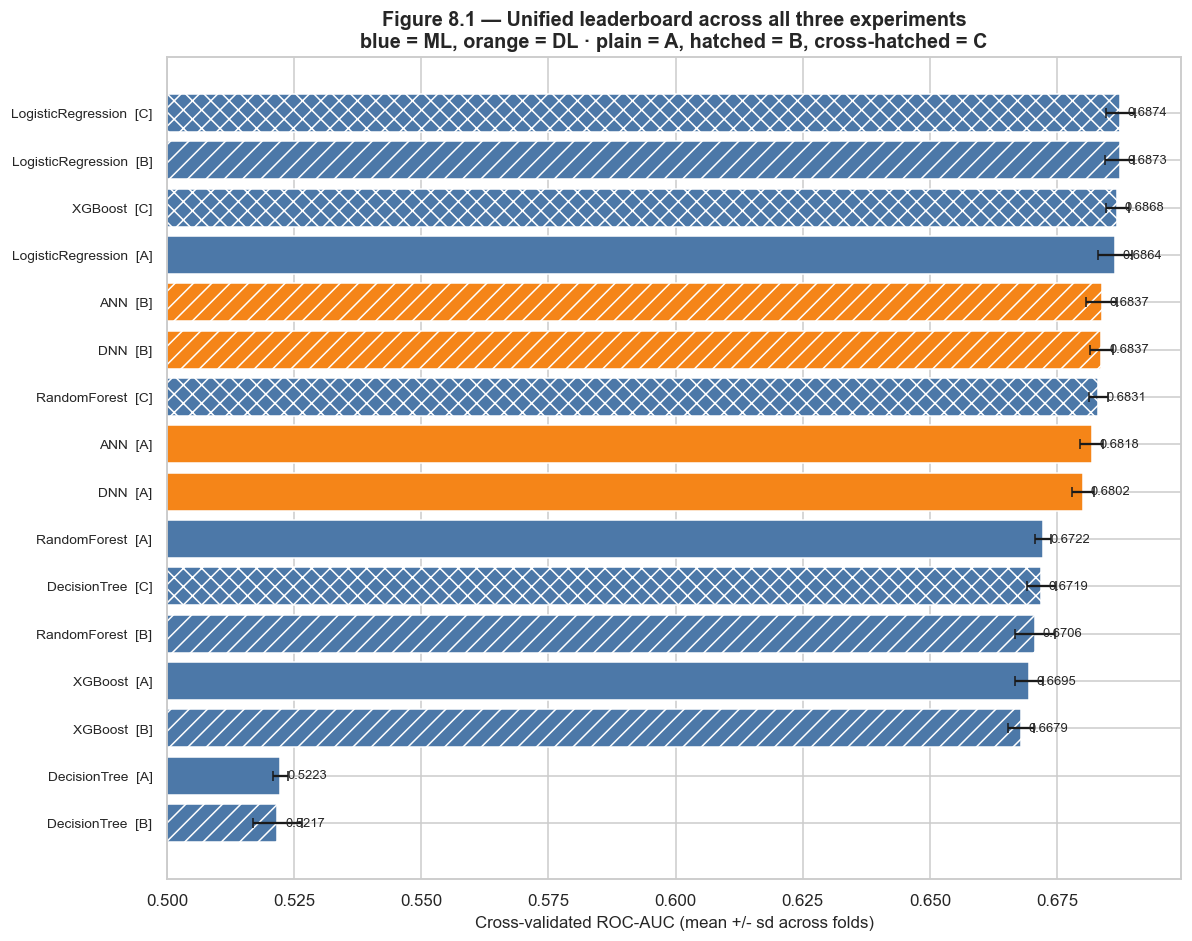

In [83]:
# ---- Visualise the full leaderboard ----------------------------------------
fig, ax = plt.subplots(figsize=(11, 0.42 * len(LEADERBOARD) + 2))

_lb = LEADERBOARD.sort_values(PRIMARY_METRIC)
_exp_hatch = {"A_baseline_features": "", "B_engineered_features": "//",
              "C_tuned": "xx"}
for y, (_, row) in enumerate(_lb.iterrows()):
    ax.barh(y, row[PRIMARY_METRIC], xerr=row[f"{PRIMARY_METRIC}_std"], capsize=3,
            color=C_DL if row.family == "DL" else C_ML,
            hatch=_exp_hatch[row.experiment], edgecolor="white")
    ax.text(row[PRIMARY_METRIC] + 0.0015, y, f"{row[PRIMARY_METRIC]:.4f}",
            va="center", fontsize=8.5)

ax.set_yticks(range(len(_lb)))
ax.set_yticklabels(_lb.candidate, fontsize=9)
ax.set_xlim(max(0.5, _lb[PRIMARY_METRIC].min() - 0.03),
            _lb[PRIMARY_METRIC].max() + 0.012)
ax.set_xlabel("Cross-validated ROC-AUC (mean +/- sd across folds)")
ax.set_title("Figure 8.1 — Unified leaderboard across all three experiments\n"
             "blue = ML, orange = DL · plain = A, hatched = B, cross-hatched = C")
savefig("fig_8_1_leaderboard")
plt.show()

## 8.2 Performance against execution time (RQ2)

### Step 8.2 — Plot the accuracy/latency frontier

§7.7(f) and RQ2 make execution time a first-class result, not a footnote. The
question is whether this dataset presents a genuine **trade-off** — where buying
more accuracy costs latency — or whether one model dominates on both axes.

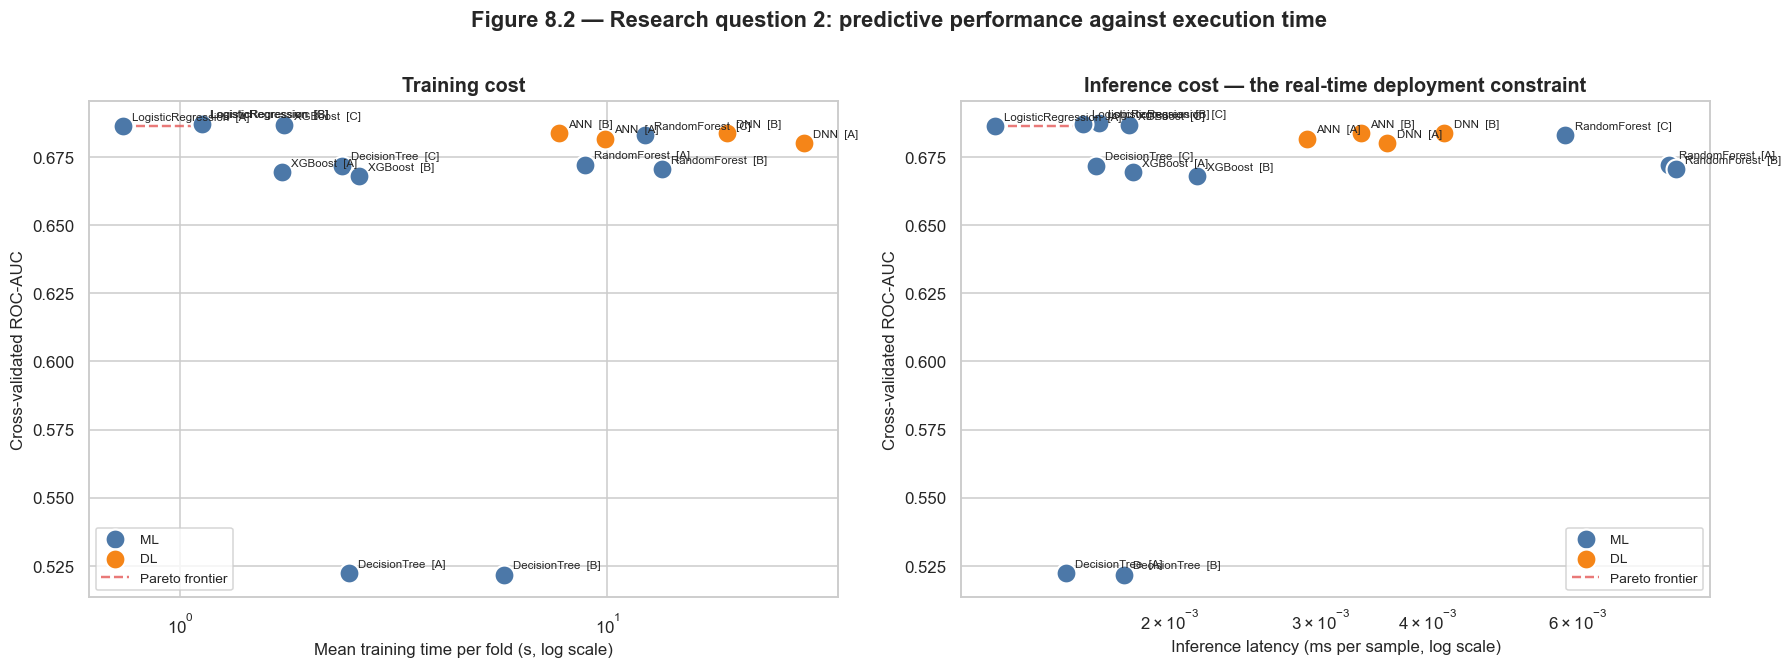

Pareto-optimal candidates on the inference axis (nothing is simultaneously faster and more accurate):
              candidate family  roc_auc  infer_ms_per_sample  train_seconds
LogisticRegression  [A]     ML   0.6864               0.0013         0.7339
LogisticRegression  [B]     ML   0.6873               0.0016         1.1217
LogisticRegression  [C]     ML   0.6875               0.0016         1.1204


In [84]:
# ---- Research question 2: the accuracy / latency frontier ------------------
fig, axes = plt.subplots(1, 2, figsize=(16.5, 6))

for ax, (xcol, xlabel, title) in zip(axes, [
    ("train_seconds", "Mean training time per fold (s, log scale)",
     "Training cost"),
    ("infer_ms_per_sample", "Inference latency (ms per sample, log scale)",
     "Inference cost — the real-time deployment constraint"),
]):
    for family, colour in [("ML", C_ML), ("DL", C_DL)]:
        sub = LEADERBOARD[LEADERBOARD.family == family]
        ax.scatter(sub[xcol], sub[PRIMARY_METRIC], s=170, color=colour,
                   label=family, edgecolors="white", linewidths=1.4, zorder=3)
    for _, r in LEADERBOARD.iterrows():
        ax.annotate(r.candidate, (r[xcol], r[PRIMARY_METRIC]), fontsize=7.5,
                    xytext=(6, 4), textcoords="offset points")

    # The Pareto frontier: nothing is both faster and more accurate.
    pareto = LEADERBOARD.sort_values(xcol)
    keep, best = [], -np.inf
    for _, r in pareto.iterrows():
        if r[PRIMARY_METRIC] > best:
            keep.append(r)
            best = r[PRIMARY_METRIC]
    frontier = pd.DataFrame(keep)
    ax.step(frontier[xcol], frontier[PRIMARY_METRIC], where="post",
            color=C_CHURN, lw=1.6, ls="--", alpha=0.8, label="Pareto frontier", zorder=2)

    ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Cross-validated ROC-AUC")
    ax.set_title(title)
    ax.legend(fontsize=9)

fig.suptitle("Figure 8.2 — Research question 2: predictive performance against "
             "execution time", fontweight="semibold", y=1.01)
savefig("fig_8_2_performance_vs_time")
plt.show()

print("Pareto-optimal candidates on the inference axis "
      "(nothing is simultaneously faster and more accurate):")
print(frontier[["candidate", "family", PRIMARY_METRIC,
                "infer_ms_per_sample", "train_seconds"]].round(5).to_string(index=False))

## 8.3 Selecting the champion

### Step 8.3 — Apply the pre-stated selection rule

> **Selection rule.** The champion is the configuration with the highest
> **cross-validated ROC-AUC** on the development sample. Ties within one
> fold-level standard deviation are broken by **inference latency**, because
> §7.7(f) and RQ2 make real-time scoring an explicit operational requirement of
> this study.

ROC-AUC is the selection metric because it is threshold-free: it measures how
well a model *ranks* customers by risk, which is what a retention campaign
actually consumes. Threshold-dependent metrics are reported for every model but
are not used to select, since any of them can be moved simply by shifting the
cut-off — as Part 11 demonstrates.

In [85]:
# ---- Apply the selection rule -----------------------------------------------
_top_auc = LEADERBOARD[PRIMARY_METRIC].max()
_tie_band = LEADERBOARD.loc[LEADERBOARD[PRIMARY_METRIC].idxmax(),
                            f"{PRIMARY_METRIC}_std"]

TIED_CANDIDATES = LEADERBOARD[LEADERBOARD[PRIMARY_METRIC] >= _top_auc - _tie_band].copy()
CHAMPION_ROW = TIED_CANDIDATES.sort_values("infer_ms_per_sample").iloc[0]

CHAMPION_NAME = CHAMPION_ROW.model
CHAMPION_EXPERIMENT = CHAMPION_ROW.experiment
CHAMPION_FAMILY = CHAMPION_ROW.family
CHAMPION_FEATURE_SET = CHAMPION_ROW.feature_set
CHAMPION_CANDIDATE = CHAMPION_ROW.candidate

print(f"Highest CV {PRIMARY_METRIC}: {_top_auc:.5f}")
print(f"Tie band (one fold sd):   +/- {_tie_band:.5f}")
print(f"Candidates inside the tie band: {len(TIED_CANDIDATES)}")
print(TIED_CANDIDATES[["candidate", PRIMARY_METRIC, "infer_ms_per_sample"]]
      .round(5).to_string(index=False))

print(f"\n{'=' * 72}")
print(f"CHAMPION: {CHAMPION_CANDIDATE}")
print(f"{'=' * 72}")
print(f"  family        : {CHAMPION_FAMILY}")
print(f"  configuration : {EXPERIMENT_LABELS[CHAMPION_EXPERIMENT]}")
print(f"  feature set   : {CHAMPION_FEATURE_SET} "
      f"({len(FEATURE_SETS[CHAMPION_FEATURE_SET]['features'])} features)")
print(f"  CV ROC-AUC    : {CHAMPION_ROW[PRIMARY_METRIC]:.5f} "
      f"(sd {CHAMPION_ROW[f'{PRIMARY_METRIC}_std']:.5f})")
print(f"  CV PR-AUC     : {CHAMPION_ROW['pr_auc']:.5f}")
print(f"  training time : {CHAMPION_ROW['train_seconds']:.2f}s per fold")
print(f"  inference     : {CHAMPION_ROW['infer_ms_per_sample']:.5f} ms per sample")

Highest CV roc_auc: 0.68745
Tie band (one fold sd):   +/- 0.00279
Candidates inside the tie band: 4
              candidate  roc_auc  infer_ms_per_sample
LogisticRegression  [C]   0.6875               0.0016
LogisticRegression  [B]   0.6873               0.0016
           XGBoost  [C]   0.6868               0.0018
LogisticRegression  [A]   0.6864               0.0013

CHAMPION: LogisticRegression  [A]
  family        : ML
  configuration : A · default params, baseline features
  feature set   : baseline (29 features)
  CV ROC-AUC    : 0.68638 (sd 0.00341)
  CV PR-AUC     : 0.20210
  training time : 0.73s per fold
  inference     : 0.00125 ms per sample


In [86]:
# ---- Reconstruct the champion estimator, ready for Parts 10-12 ------------
def build_champion():
    """Return an unfitted copy of the champion, exactly as it was evaluated."""
    if CHAMPION_FAMILY == "DL":
        return ("DL", DL_BUILDERS[CHAMPION_NAME])
    registry = TUNED_MODELS if CHAMPION_EXPERIMENT == "C_tuned" else ml_model_registry()
    return ("ML", registry[CHAMPION_NAME])


CHAMPION_KIND, CHAMPION_ESTIMATOR = build_champion()
CHAMPION_SPEC = FEATURE_SETS[CHAMPION_FEATURE_SET]

# The strongest deep-learning configuration, for the Part 12 trade-off study.
_dl_rows = LEADERBOARD[LEADERBOARD.family == "DL"]
BEST_DL_ROW = _dl_rows.loc[_dl_rows[PRIMARY_METRIC].idxmax()]

print(f"Champion estimator rebuilt: {CHAMPION_KIND} / {CHAMPION_NAME}")
if CHAMPION_KIND == "ML":
    print(f"  parameters: {CHAMPION_ESTIMATOR.get_params()}")
print(f"\nStrongest DL configuration (Part 12 comparator): "
      f"{BEST_DL_ROW.candidate}  AUC {BEST_DL_ROW[PRIMARY_METRIC]:.5f}, "
      f"{BEST_DL_ROW.infer_ms_per_sample:.5f} ms/sample")

Champion estimator rebuilt: ML / LogisticRegression
  parameters: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Strongest DL configuration (Part 12 comparator): ANN  [B]  AUC 0.68374, 0.00334 ms/sample


---
# Part 9 — Statistical significance (§7.7 Table 9)

§7.7(g) is explicit: *"a model with higher raw metrics ... is an efficient
requirement to claim this model outperform other models. Statistical
significance testing helps to ensure the evaluation is sufficiently rigorous to
conclude that higher performance does not happen by chance."*

Table 9 specifies the instruments. All of them are implemented:

| Instrument | Purpose |
|---|---|
| Repeated stratified k-fold CV | Produces the score distribution to test |
| Paired *t*-test | Parametric test on fold-wise differences |
| Wilcoxon signed-rank | Non-parametric companion, robust to non-normal folds |
| Bootstrap 95% CI | Interval estimate that does not assume normality |
| Holm–Bonferroni | Controls family-wise error across many pairwise tests |
| Cohen's *d_z* | **Consistency** of the paired difference across folds |
| Raw AUC magnitude | **Practical importance** — how large the difference actually is |

The last two rows are distinct, and conflating them is the most common error in
this kind of comparison. Cohen's *d_z* for a paired design is
mean(difference) ÷ sd(difference): it asks *how reliably* model A beats model B,
not *by how much*. When two models are both very stable, the fold-to-fold
standard deviation of their difference is minute, so **a difference of 0.0006
AUC can register as a "large" d_z**. That is not a flaw in the statistic — it is
the statistic answering a different question from the one that matters here.

Practical importance is therefore judged on the **raw magnitude** of the AUC
difference, against a materiality threshold declared before the results are
seen:

> A difference below **0.005 AUC** is treated as negligible, 0.005–0.010 as
> small, and above **0.010** as material. For orientation, Part 12 converts an
> AUC difference into retained revenue, so this threshold can be checked against
> something concrete rather than left as a convention.

## 9.1 The finalist set

### Step 9.1 — Take each algorithm's best configuration into repeated CV

Testing all sixteen configurations against each other would produce 120 pairwise
comparisons, most of them between two variants of the same algorithm. Instead
the **best configuration of each of the six algorithms** goes forward, which
makes the resulting comparison a clean ML-versus-DL head-to-head (RQ1).

In [87]:
# ---- Assemble the finalists: best configuration per algorithm -------------
_best_per_model = (LEADERBOARD.sort_values(PRIMARY_METRIC, ascending=False)
                   .groupby("model", observed=True).head(1))

FINALIST_SPECS = []
for _, row in _best_per_model.iterrows():
    if row.family == "DL":
        FINALIST_SPECS.append(dict(name=row.model, family="DL",
                                   builder=DL_BUILDERS[row.model],
                                   feature_set=row.feature_set,
                                   experiment=row.experiment))
    else:
        registry = TUNED_MODELS if row.experiment == "C_tuned" else ml_model_registry()
        FINALIST_SPECS.append(dict(name=row.model, family="ML",
                                   estimator=registry[row.model],
                                   feature_set=row.feature_set,
                                   experiment=row.experiment))

print(f"Finalists entering repeated CV ({N_SPLITS} folds x {N_REPEATS} repeats = "
      f"{N_SPLITS * N_REPEATS} scores per model):\n")
print(_best_per_model[["model", "family", "experiment", PRIMARY_METRIC]]
      .round(5).to_string(index=False))

Finalists entering repeated CV (5 folds x 3 repeats = 15 scores per model):

             model family            experiment  roc_auc
LogisticRegression     ML               C_tuned   0.6875
           XGBoost     ML               C_tuned   0.6868
               ANN     DL B_engineered_features   0.6837
               DNN     DL B_engineered_features   0.6837
      RandomForest     ML               C_tuned   0.6831
      DecisionTree     ML               C_tuned   0.6719


In [88]:
# ---- Repeated stratified CV on the finalists ------------------------------
print(f"\nRepeated CV on {len(y_dev):,} rows — this is the most expensive cell "
      f"in the notebook.\n")

_ml_by_set, _dl_by_set = {}, {}
for spec in FINALIST_SPECS:
    target = _ml_by_set if spec["family"] == "ML" else _dl_by_set
    target.setdefault(spec["feature_set"], {})[spec["name"]] = (
        spec["estimator"] if spec["family"] == "ML" else spec["builder"])

_repeated = []
for feature_set, models in _ml_by_set.items():
    print(f"ML finalists on the {feature_set} feature set:")
    f, _ = evaluate_cv(models, X_dev, y_dev, feature_set=feature_set,
                       imbalance=IMBALANCE_CHOICE, n_splits=N_SPLITS,
                       n_repeats=N_REPEATS, benchmark=False, label="finalist")
    _repeated.append(f)

for feature_set, builders in _dl_by_set.items():
    print(f"DL finalists on the {feature_set} feature set:")
    f, _ = evaluate_dl_cv(builders, X_dev, y_dev, feature_set=feature_set,
                          imbalance=IMBALANCE_CHOICE, n_splits=N_SPLITS,
                          n_repeats=N_REPEATS, benchmark=False, label="finalist")
    _repeated.append(f)

REPEATED_FOLDS = pd.concat(_repeated, ignore_index=True)
REPEATED_SUMMARY = aggregate_folds(REPEATED_FOLDS)
print(f"\n{len(REPEATED_FOLDS)} fold-level records collected.")
REPEATED_SUMMARY[["model", "family"] + METRIC_COLS].round(5)


Repeated CV on 200,000 rows — this is the most expensive cell in the notebook.

ML finalists on the engineered feature set:


  LogisticRegression     15 folds in 17.9s


  XGBoost                15 folds in 27.8s


  RandomForest           15 folds in 183.0s


  DecisionTree           15 folds in 36.5s
DL finalists on the engineered feature set:


  ANN                    15 folds in 110.5s


  DNN                    15 folds in 277.5s

90 fold-level records collected.


,model,family,roc_auc,pr_auc,f1,recall,precision,accuracy,brier
3,LogisticRegression,ML,0.6875,0.2031,0.0066,0.0033,0.5418,0.9008,0.0852
5,XGBoost,ML,0.6869,0.2050,0.0039,0.0020,0.6274,0.9009,0.0852
1,DNN,DL,0.6843,0.2015,0.0004,0.0002,0.3537,0.9008,0.0854
0,ANN,DL,0.6836,0.2006,0.0011,0.0006,0.4291,0.9008,0.0855
4,RandomForest,ML,0.6832,0.2007,0.0000,0.0000,0.0000,0.9008,0.0856
2,DecisionTree,ML,0.6715,0.1809,0.0000,0.0000,0.0000,0.9008,0.0861


## 9.2 Pairwise significance testing

### Step 9.2 — Paired tests, bootstrap intervals, Holm correction and effect sizes

In [89]:
# ---- Materiality thresholds, declared before any result is inspected ------
MATERIALITY_NEGLIGIBLE = 0.005   # below this, a difference is not actionable
MATERIALITY_SMALL = 0.010        # above this, a difference is material


# ---- Bootstrap confidence interval on a fold-score distribution -----------
def bootstrap_ci(values, n_boot=10_000, alpha=0.05, seed=RANDOM_STATE):
    """Percentile bootstrap CI for the mean of a small sample of fold scores."""
    values = np.asarray(values, dtype=float)
    rng = np.random.RandomState(seed)
    draws = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return float(np.quantile(draws, alpha / 2)), float(np.quantile(draws, 1 - alpha / 2))


def holm_bonferroni(p_values, alpha=0.05):
    """Holm step-down correction; returns adjusted p-values in the input order."""
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    m = len(p)
    adjusted = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adjusted[idx] = min(running, 1.0)
    return adjusted


def pairwise_significance(folds, metric=PRIMARY_METRIC, alpha=0.05):
    """All pairwise paired comparisons on one metric, with correction and effect size."""
    models = sorted(folds.model.unique())
    scores = {m: (folds[folds.model == m].sort_values("fold")[metric].to_numpy())
              for m in models}

    rows = []
    for i, a in enumerate(models):
        for b in models[i + 1:]:
            sa, sb = scores[a], scores[b]
            n = min(len(sa), len(sb))
            sa, sb = sa[:n], sb[:n]
            diff = sa - sb

            t_stat, t_p = stats.ttest_rel(sa, sb)
            try:
                _, w_p = stats.wilcoxon(sa, sb)
            except ValueError:
                w_p = 1.0
            lo, hi = bootstrap_ci(diff)

            rows.append({
                "model_a": a, "model_b": b,
                f"{metric}_a": sa.mean(), f"{metric}_b": sb.mean(),
                "mean_diff": diff.mean(),
                "abs_diff": abs(diff.mean()),
                "ci95_low": lo, "ci95_high": hi,
                # d_z measures how CONSISTENT the difference is across folds,
                # not how large it is. Read it alongside abs_diff, never instead.
                "cohens_dz": diff.mean() / (diff.std(ddof=1) + EPS),
                "ttest_p": t_p, "wilcoxon_p": w_p,
                "n_folds": n,
            })

    out = pd.DataFrame(rows)
    out["ttest_p_holm"] = holm_bonferroni(out.ttest_p, alpha)
    out["significant"] = out.ttest_p_holm < alpha

    # Two separate readings of the same comparison, deliberately kept apart.
    out["consistency"] = pd.cut(out.cohens_dz.abs(), [-0.01, 0.2, 0.5, 0.8, np.inf],
                                labels=["erratic", "weak", "moderate", "consistent"])
    out["practical"] = pd.cut(out.abs_diff,
                              [-1e-9, MATERIALITY_NEGLIGIBLE, MATERIALITY_SMALL, np.inf],
                              labels=["negligible", "small", "material"])
    out["winner"] = np.where(~out.significant, "— (not significant)",
                             np.where(out.mean_diff > 0, out.model_a, out.model_b))
    out["verdict"] = np.where(
        ~out.significant, "indistinguishable",
        np.where(out.practical == "material", "materially different",
                 "significant but NOT material"))
    return out.sort_values("abs_diff", ascending=False).reset_index(drop=True)


SIGNIFICANCE = pairwise_significance(REPEATED_FOLDS)
_n_sig = int(SIGNIFICANCE.significant.sum())
_n_material = int((SIGNIFICANCE.practical == "material").sum())
_n_hollow = int((SIGNIFICANCE.verdict == "significant but NOT material").sum())

print(f"{len(SIGNIFICANCE)} pairwise comparisons on {PRIMARY_METRIC}:")
print(f"  statistically significant after Holm correction : {_n_sig}")
print(f"  practically material (|difference| > {MATERIALITY_SMALL})   : {_n_material}")
print(f"  significant BUT not material                    : {_n_hollow}")
print(f"\nThat third number is the point of this section: a difference can be")
print(f"perfectly reliable and still far too small to change any decision.\n")
SIGNIFICANCE.round(5)

15 pairwise comparisons on roc_auc:
  statistically significant after Holm correction : 13
  practically material (|difference| > 0.01)   : 5
  significant BUT not material                    : 8

That third number is the point of this section: a difference can be
perfectly reliable and still far too small to change any decision.



,model_a,model_b,roc_auc_a,roc_auc_b,mean_diff,abs_diff,ci95_low,ci95_high,cohens_dz,ttest_p,wilcoxon_p,n_folds,ttest_p_holm,significant,consistency,practical,winner,verdict
0,DecisionTree,LogisticRegression,0.6715,0.6875,-0.0160,0.0160,-0.0173,-0.0147,-6.0668,0.0000,0.0001,15,0.0000,True,consistent,material,LogisticRegression,materially different
1,DecisionTree,XGBoost,0.6715,0.6869,-0.0153,0.0153,-0.0166,-0.0141,-6.1316,0.0000,0.0001,15,0.0000,True,consistent,material,XGBoost,materially different
2,DNN,DecisionTree,0.6843,0.6715,0.0128,0.0128,0.0115,0.0141,4.7956,0.0000,0.0001,15,0.0000,True,consistent,material,DNN,materially different
3,ANN,DecisionTree,0.6836,0.6715,0.0121,0.0121,0.0106,0.0136,3.9414,0.0000,0.0001,15,0.0000,True,consistent,material,ANN,materially different
4,DecisionTree,RandomForest,0.6715,0.6832,-0.0117,0.0117,-0.0128,-0.0107,-5.3105,0.0000,0.0001,15,0.0000,True,consistent,material,RandomForest,materially different
5,LogisticRegression,RandomForest,0.6875,0.6832,0.0043,0.0043,0.0038,0.0049,3.6879,0.0000,0.0001,15,0.0000,True,consistent,negligible,LogisticRegression,significant but NOT material
6,ANN,LogisticRegression,0.6836,0.6875,-0.0039,0.0039,-0.0046,-0.0031,-2.6793,0.0000,0.0001,15,0.0000,True,consistent,negligible,LogisticRegression,significant but NOT material
7,RandomForest,XGBoost,0.6832,0.6869,-0.0037,0.0037,-0.0042,-0.0032,-3.4831,0.0000,0.0001,15,0.0000,True,consistent,negligible,XGBoost,significant but NOT material
8,ANN,XGBoost,0.6836,0.6869,-0.0032,0.0032,-0.0041,-0.0023,-1.8527,0.0000,0.0001,15,0.0000,True,consistent,negligible,XGBoost,significant but NOT material
9,DNN,LogisticRegression,0.6843,0.6875,-0.0032,0.0032,-0.0038,-0.0026,-2.6008,0.0000,0.0001,15,0.0000,True,consistent,negligible,LogisticRegression,significant but NOT material


In [90]:
# ---- The same tests across every metric ------------------------------------
SIGNIFICANCE_ALL = pd.concat(
    [pairwise_significance(REPEATED_FOLDS, metric=m).assign(metric=m)
     for m in METRIC_COLS], ignore_index=True)

_counts = (SIGNIFICANCE_ALL.groupby("metric", observed=True)
           .significant.agg(["sum", "count"]))
_counts["pct"] = (100 * _counts["sum"] / _counts["count"]).round(1)
print("Significant pairs after Holm correction, by metric:")
print(_counts.rename(columns={"sum": "significant", "count": "pairs"}))

Significant pairs after Holm correction, by metric:
           significant  pairs     pct
metric                               
accuracy             0     15  0.0000
brier               14     15 93.3000
f1                   9     15 60.0000
pr_auc              12     15 80.0000
precision            6     15 40.0000
recall               9     15 60.0000
roc_auc             13     15 86.7000


### Step 9.3 — Separate statistical significance from practical importance

This is the crux of §7.7(g). A **significance** matrix and a **magnitude**
matrix are shown side by side. Where the first is dense and the second is
uniformly small, the study has detected differences that are real but too small
to act on — and saying so is a far stronger result than reporting the asterisks
alone.

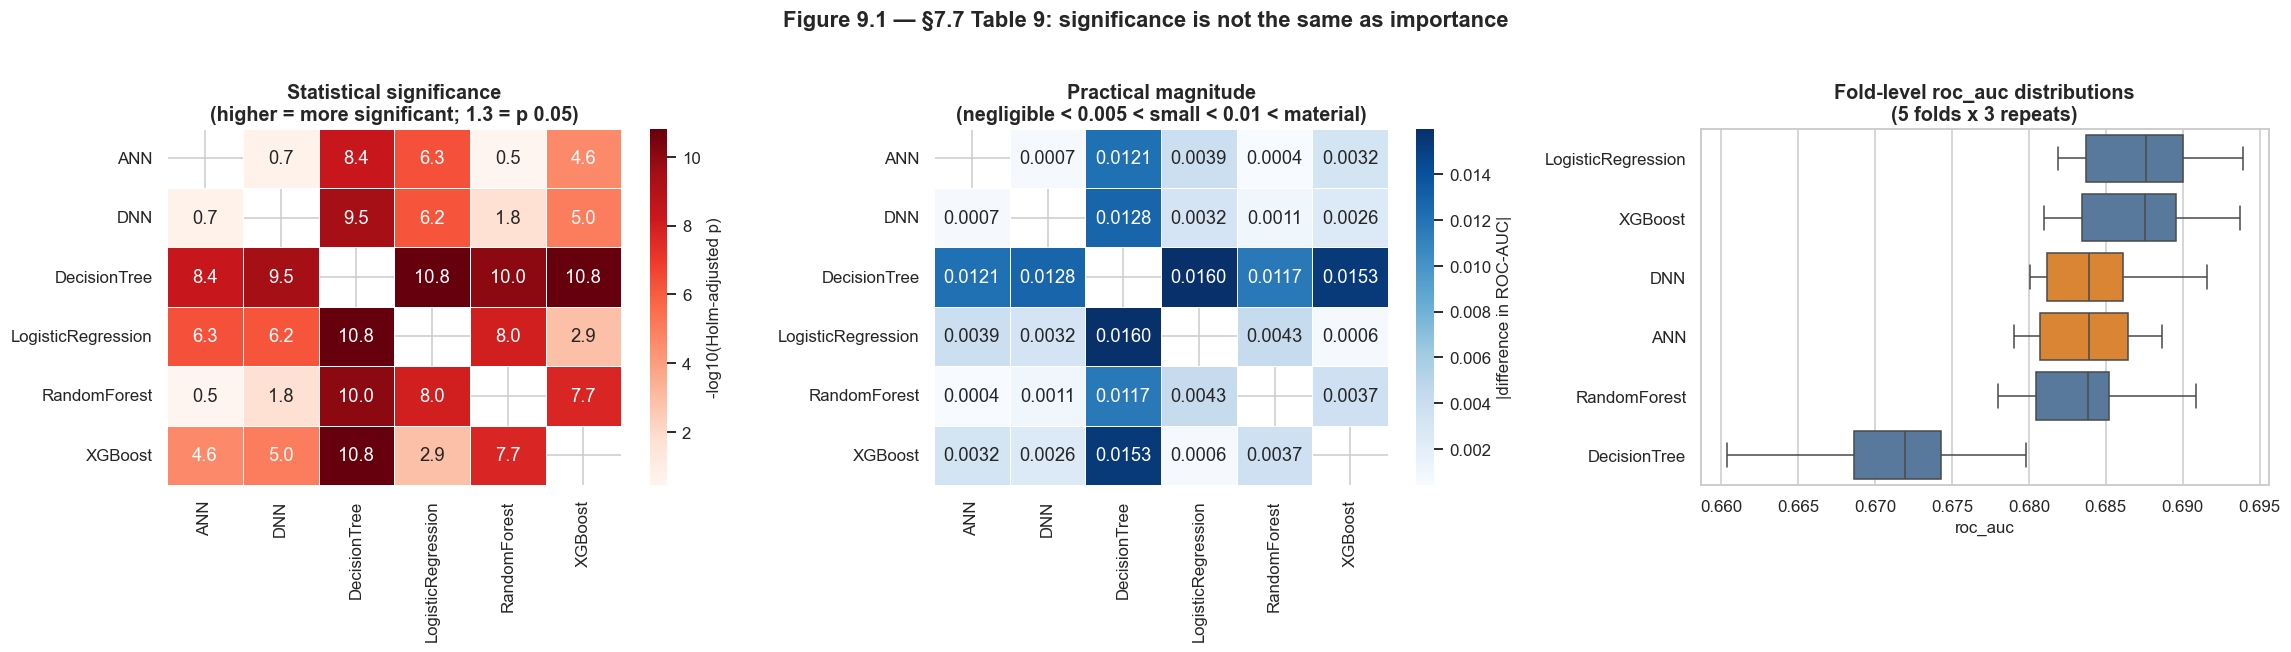

In [91]:
# ---- Significance matrix against effect-size matrix -----------------------
_models = sorted(REPEATED_FOLDS.model.unique())
_sig = pd.DataFrame(np.nan, index=_models, columns=_models)
_eff = pd.DataFrame(np.nan, index=_models, columns=_models)

for _, r in SIGNIFICANCE.iterrows():
    _sig.loc[r.model_a, r.model_b] = -np.log10(max(r.ttest_p_holm, 1e-300))
    _sig.loc[r.model_b, r.model_a] = _sig.loc[r.model_a, r.model_b]
    _eff.loc[r.model_a, r.model_b] = r.abs_diff
    _eff.loc[r.model_b, r.model_a] = r.abs_diff

fig, axes = plt.subplots(1, 3, figsize=(21, 5.8))

sns.heatmap(_sig, annot=True, fmt=".1f", cmap="Reds", linewidths=0.6,
            cbar_kws={"label": "-log10(Holm-adjusted p)"}, ax=axes[0])
axes[0].set_title("Statistical significance\n(higher = more significant; 1.3 = p 0.05)")

sns.heatmap(_eff, annot=True, fmt=".4f", cmap="Blues", linewidths=0.6,
            cbar_kws={"label": "|difference in ROC-AUC|"}, ax=axes[1])
axes[1].set_title(f"Practical magnitude\n(negligible < {MATERIALITY_NEGLIGIBLE} "
                  f"< small < {MATERIALITY_SMALL} < material)")

sns.boxplot(data=REPEATED_FOLDS, x=PRIMARY_METRIC, y="model",
            order=REPEATED_SUMMARY.model, ax=axes[2],
            palette=["#F58518" if REPEATED_FOLDS[REPEATED_FOLDS.model == m].family.iloc[0] == "DL"
                     else "#4C78A8" for m in REPEATED_SUMMARY.model])
axes[2].set_title(f"Fold-level {PRIMARY_METRIC} distributions\n"
                  f"({N_SPLITS} folds x {N_REPEATS} repeats)")
axes[2].set_ylabel("")

fig.suptitle("Figure 9.1 — §7.7 Table 9: significance is not the same as importance",
             fontweight="semibold", y=1.02)
savefig("fig_9_1_significance")
plt.show()

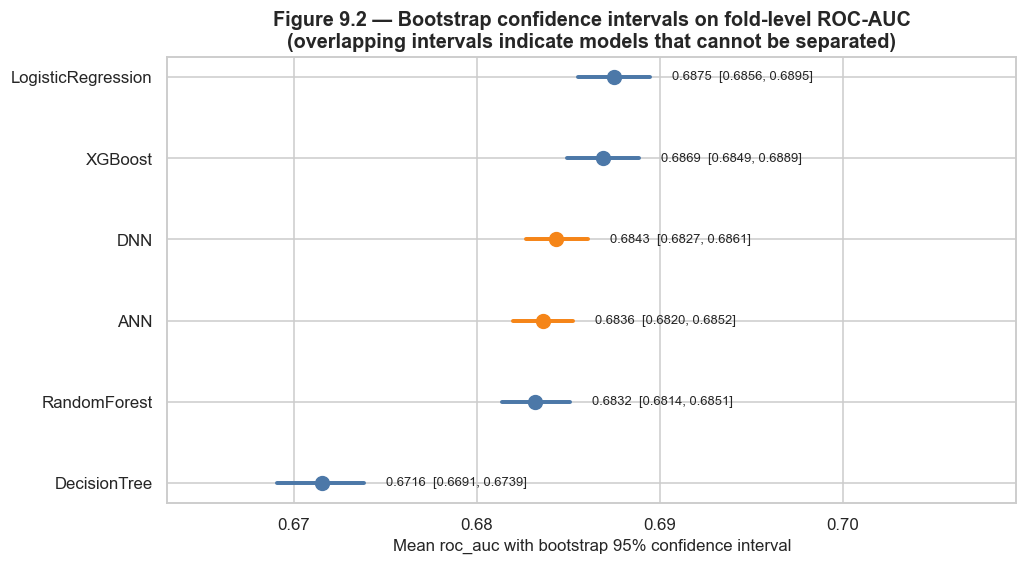

In [92]:
# ---- Forest plot: mean fold score with bootstrap 95% CI -------------------
_forest = []
for model in REPEATED_SUMMARY.model:
    vals = REPEATED_FOLDS.loc[REPEATED_FOLDS.model == model, PRIMARY_METRIC].to_numpy()
    lo, hi = bootstrap_ci(vals)
    _forest.append({"model": model, "mean": vals.mean(), "lo": lo, "hi": hi,
                    "family": REPEATED_FOLDS.loc[REPEATED_FOLDS.model == model,
                                                 "family"].iloc[0]})
FOREST = pd.DataFrame(_forest).sort_values("mean")

fig, ax = plt.subplots(figsize=(9.5, 0.55 * len(FOREST) + 2))
for y, (_, r) in enumerate(FOREST.iterrows()):
    colour = C_DL if r.family == "DL" else C_ML
    ax.plot([r.lo, r.hi], [y, y], color=colour, lw=2.6, solid_capstyle="round")
    ax.plot(r["mean"], y, "o", color=colour, ms=9, zorder=3)
    ax.text(r.hi + 0.0012, y, f"{r['mean']:.4f}  [{r.lo:.4f}, {r.hi:.4f}]",
            va="center", fontsize=8.5)

ax.set_yticks(range(len(FOREST)))
ax.set_yticklabels(FOREST.model)
ax.set_xlabel(f"Mean {PRIMARY_METRIC} with bootstrap 95% confidence interval")
ax.set_xlim(FOREST.lo.min() - 0.006, FOREST.hi.max() + 0.020)
ax.set_title("Figure 9.2 — Bootstrap confidence intervals on fold-level ROC-AUC\n"
             "(overlapping intervals indicate models that cannot be separated)")
savefig("fig_9_2_forest")
plt.show()

### Step 9.4 — The head-to-head ML versus DL verdict (RQ1)

In [93]:
# ---- Research question 1: does either family dominate? --------------------
_families = REPEATED_FOLDS.groupby("model", observed=True).family.first()
_cross = SIGNIFICANCE[SIGNIFICANCE.model_a.map(_families)
                      != SIGNIFICANCE.model_b.map(_families)].copy()
_cross["ml_model"] = np.where(_cross.model_a.map(_families) == "ML",
                              _cross.model_a, _cross.model_b)
_cross["dl_model"] = np.where(_cross.model_a.map(_families) == "DL",
                              _cross.model_a, _cross.model_b)
_cross["ml_advantage"] = np.where(_cross.model_a.map(_families) == "ML",
                                  _cross.mean_diff, -_cross.mean_diff)

RQ1_VERDICT = pd.DataFrame([
    ("Cross-family comparisons", f"{len(_cross)}"),
    ("Won by an ML model",
     f"{int(((_cross.ml_advantage > 0) & _cross.significant).sum())}"),
    ("Won by a DL model",
     f"{int(((_cross.ml_advantage < 0) & _cross.significant).sum())}"),
    ("Not separable", f"{int((~_cross.significant).sum())}"),
    ("Mean ML advantage in AUC", f"{_cross.ml_advantage.mean():+.5f}"),
    ("Best ML finalist",
     f"{REPEATED_SUMMARY[REPEATED_SUMMARY.family == 'ML'].model.iloc[0]} "
     f"({REPEATED_SUMMARY[REPEATED_SUMMARY.family == 'ML'][PRIMARY_METRIC].iloc[0]:.5f})"),
    ("Best DL finalist",
     f"{REPEATED_SUMMARY[REPEATED_SUMMARY.family == 'DL'].model.iloc[0]} "
     f"({REPEATED_SUMMARY[REPEATED_SUMMARY.family == 'DL'][PRIMARY_METRIC].iloc[0]:.5f})"),
    ("Statistically significant comparisons", f"{_n_sig} of {len(SIGNIFICANCE)}"),
    ("Practically material comparisons", f"{_n_material} of {len(SIGNIFICANCE)}"),
    ("Significant but not material", f"{_n_hollow} of {len(SIGNIFICANCE)}"),
    ("Models separable on practical grounds",
     ", ".join(sorted(set(SIGNIFICANCE.loc[SIGNIFICANCE.practical == "material",
                                           ["model_a", "model_b"]].to_numpy().ravel())))
     or "none"),
    ("Spread across the whole finalist set",
     f"{REPEATED_SUMMARY[PRIMARY_METRIC].max() - REPEATED_SUMMARY[PRIMARY_METRIC].min():.5f} AUC"),
], columns=["measure", "value"])
RQ1_VERDICT

,measure,value
0,Cross-family comparisons,8
1,Won by an ML model,4
2,Won by a DL model,3
3,Not separable,1
4,Mean ML advantage in AUC,-0.00169
5,Best ML finalist,LogisticRegression (0.68752)
6,Best DL finalist,DNN (0.68431)
7,Statistically significant comparisons,13 of 15
8,Practically material comparisons,5 of 15
9,Significant but not material,8 of 15


---
# Part 10 — Interpretability analysis of the champion (§7.8)

§7.8 sets three purposes for the interpretability analysis, and this part is
organised around them explicitly:

| §7.8 purpose | What is done here |
|---|---|
| **(a) Feature-importance validation** | Rank the champion's SHAP importances and check them against the Part 1 EDA and against banking-domain expectation |
| **(b) Model debugging** | A **negative-control test**: the features EDA finding 3 identified as pure noise must receive near-zero attribution. If they do not, the model has learned an artefact |
| **(c) Actionable insights** | Dependence plots on the top drivers, plus individual customer explanations of the kind a retention analyst would actually receive |

Per §7.8, TreeSHAP is used for tree-based champions, the exact linear explainer
for a linear champion, and sampling-based KernelSHAP otherwise. All explanations
are computed on the **held-out test partition**, which the champion has never
seen — an explanation derived from training data describes what the model
memorised, not what it generalises.

## 10.1 Fitting the champion and choosing an explainer

### Step 10.1 — Fit the champion once on the development sample

In [94]:
# ---- Fit the champion for explanation --------------------------------------
if CHAMPION_KIND == "ML":
    CHAMPION_FITTED = LeakageSafeClassifier(
        CHAMPION_ESTIMATOR,
        numeric_features=CHAMPION_SPEC["numeric"],
        categorical_features=CHAMPION_SPEC["categorical"],
        winsorise_cols=WINSORISE_COLS,
        imbalance=IMBALANCE_CHOICE,
        random_state=RANDOM_STATE,
    ).fit(X_dev[CHAMPION_SPEC["features"]], y_dev)
    CHAMPION_PREPROCESSOR = CHAMPION_FITTED.preprocessor_
    CHAMPION_INNER = CHAMPION_FITTED.estimator_
else:
    CHAMPION_FITTED = KerasChurnClassifier(
        CHAMPION_ESTIMATOR, CHAMPION_SPEC["numeric"], CHAMPION_SPEC["categorical"],
        winsorise_cols=WINSORISE_COLS, imbalance=IMBALANCE_CHOICE,
        random_state=RANDOM_STATE,
    ).fit(X_dev[CHAMPION_SPEC["features"]], y_dev)
    CHAMPION_PREPROCESSOR = CHAMPION_FITTED.preprocessor_
    CHAMPION_INNER = CHAMPION_FITTED.model_

FEATURE_NAMES_OUT = [n.split("__", 1)[-1]
                     for n in CHAMPION_PREPROCESSOR.get_feature_names_out()]

print(f"Champion fitted: {CHAMPION_CANDIDATE}")
print(f"Model input width after preprocessing: {len(FEATURE_NAMES_OUT)} columns "
      f"(from {len(CHAMPION_SPEC['features'])} features after one-hot encoding)")

Champion fitted: LogisticRegression  [A]
Model input width after preprocessing: 38 columns (from 29 features after one-hot encoding)


In [95]:
# ---- Explain a stratified sample of the HELD-OUT test partition ------------
import shap

SHAP_SAMPLE_N = 4_000 if not QUICK_RUN else 500
BACKGROUND_N = 500 if not QUICK_RUN else 100

X_shap_raw, y_shap = stratified_subsample(
    X_test[CHAMPION_SPEC["features"]], y_test, SHAP_SAMPLE_N, seed=RANDOM_STATE)
X_shap = pd.DataFrame(CHAMPION_PREPROCESSOR.transform(X_shap_raw),
                      columns=FEATURE_NAMES_OUT, index=X_shap_raw.index)
X_background = X_shap.sample(min(BACKGROUND_N, len(X_shap)), random_state=RANDOM_STATE)

print(f"Explaining {len(X_shap):,} held-out customers "
      f"(churn rate {y_shap.mean():.4f}), background set {len(X_background)} rows.")

Explaining 4,000 held-out customers (churn rate 0.0993), background set 500 rows.


In [96]:
# ---- Select the explainer §7.8 prescribes for this model type -------------
def build_explainer(model, background):
    """Choose the SHAP explainer appropriate to the champion's model class (§7.8)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import RandomForestClassifier
    from xgboost import XGBClassifier

    if isinstance(model, (DecisionTreeClassifier, RandomForestClassifier, XGBClassifier)):
        # TreeSHAP: exact and fast for tree ensembles, as §7.8 specifies.
        return shap.TreeExplainer(model), "TreeSHAP (exact)"
    if isinstance(model, LogisticRegression):
        # For a linear model in log-odds space the Shapley values are exact and
        # closed-form; no sampling approximation is needed.
        return shap.LinearExplainer(model, background), "LinearSHAP (exact)"
    # Deep or otherwise opaque model: KernelSHAP approximates by sampling.
    predict = lambda data: model.predict(data, verbose=0).ravel() \
        if hasattr(model, "predict") and CHAMPION_KIND == "DL" \
        else model.predict_proba(data)[:, 1]
    return shap.KernelExplainer(predict, background), "KernelSHAP (sampled)"


EXPLAINER, EXPLAINER_KIND = build_explainer(CHAMPION_INNER, X_background)

_t0 = time.perf_counter()
_raw_shap = EXPLAINER.shap_values(X_shap)
# Binary classifiers return either one matrix or one per class; normalise to the
# positive-class matrix so downstream code has a single shape to reason about.
if isinstance(_raw_shap, list):
    SHAP_VALUES = np.asarray(_raw_shap[-1])
elif np.asarray(_raw_shap).ndim == 3:
    SHAP_VALUES = np.asarray(_raw_shap)[:, :, -1]
else:
    SHAP_VALUES = np.asarray(_raw_shap)

print(f"{EXPLAINER_KIND} computed in {time.perf_counter() - _t0:.1f}s")
print(f"SHAP value matrix: {SHAP_VALUES.shape}")
assert SHAP_VALUES.shape == X_shap.shape, "SHAP matrix does not match the input matrix."

LinearSHAP (exact) computed in 0.0s
SHAP value matrix: (4000, 38)


## 10.2 §7.8(a) — Feature-importance validation

### Step 10.2 — Rank the drivers and check them against the EDA

In [97]:
# ---- Global SHAP importance -------------------------------------------------
IMPORTANCE = (pd.DataFrame({
    "feature": FEATURE_NAMES_OUT,
    "mean_abs_shap": np.abs(SHAP_VALUES).mean(axis=0),
    "mean_shap": SHAP_VALUES.mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))

IMPORTANCE["rank"] = np.arange(1, len(IMPORTANCE) + 1)
IMPORTANCE["share_pct"] = 100 * IMPORTANCE.mean_abs_shap / IMPORTANCE.mean_abs_shap.sum()
IMPORTANCE["cumulative_pct"] = IMPORTANCE.share_pct.cumsum()

# Trace each encoded column back to whether it came from an engineered feature.
_engineered_retained = [c for c in ENGINEERED_COLS if c not in PRUNED_FEATURES]
IMPORTANCE["origin"] = np.where(
    [any(f == c or f.startswith(f"{c}_") for c in _engineered_retained)
     for f in IMPORTANCE.feature], "engineered", "raw")

ENGINEERED_SHAP_SHARE = float(
    IMPORTANCE.loc[IMPORTANCE.origin == "engineered", "share_pct"].sum())

print(f"Top 15 churn drivers according to the champion "
      f"({CHAMPION_NAME}, {EXPLAINER_KIND}):\n")
print(IMPORTANCE.head(15)[["rank", "feature", "mean_abs_shap", "share_pct",
                           "cumulative_pct", "origin"]].round(4).to_string(index=False))
print(f"\nEngineered features carry {ENGINEERED_SHAP_SHARE:.1f}% of total attribution "
      f"({int((IMPORTANCE.origin == 'engineered').sum())} of {len(IMPORTANCE)} columns).")

Top 15 churn drivers according to the champion (LogisticRegression, LinearSHAP (exact)):

 rank                     feature  mean_abs_shap  share_pct  cumulative_pct origin
    1           contract_two_year         0.9049    34.7784         34.7784    raw
    2           contract_one_year         0.4735    18.1974         52.9757    raw
    3       customer_satisfaction         0.2239     8.6042         61.5799    raw
    4            has_tech_support         0.1551     5.9621         67.5420    raw
    5              num_complaints         0.1443     5.5475         73.0894    raw
    6           num_service_calls         0.1414     5.4356         78.5251    raw
    7               late_payments         0.1288     4.9518         83.4768    raw
    8         has_online_security         0.1160     4.4599         87.9367    raw
    9                num_services         0.1145     4.3996         92.3363    raw
   10                totalcharges         0.0378     1.4538         93.7901    r

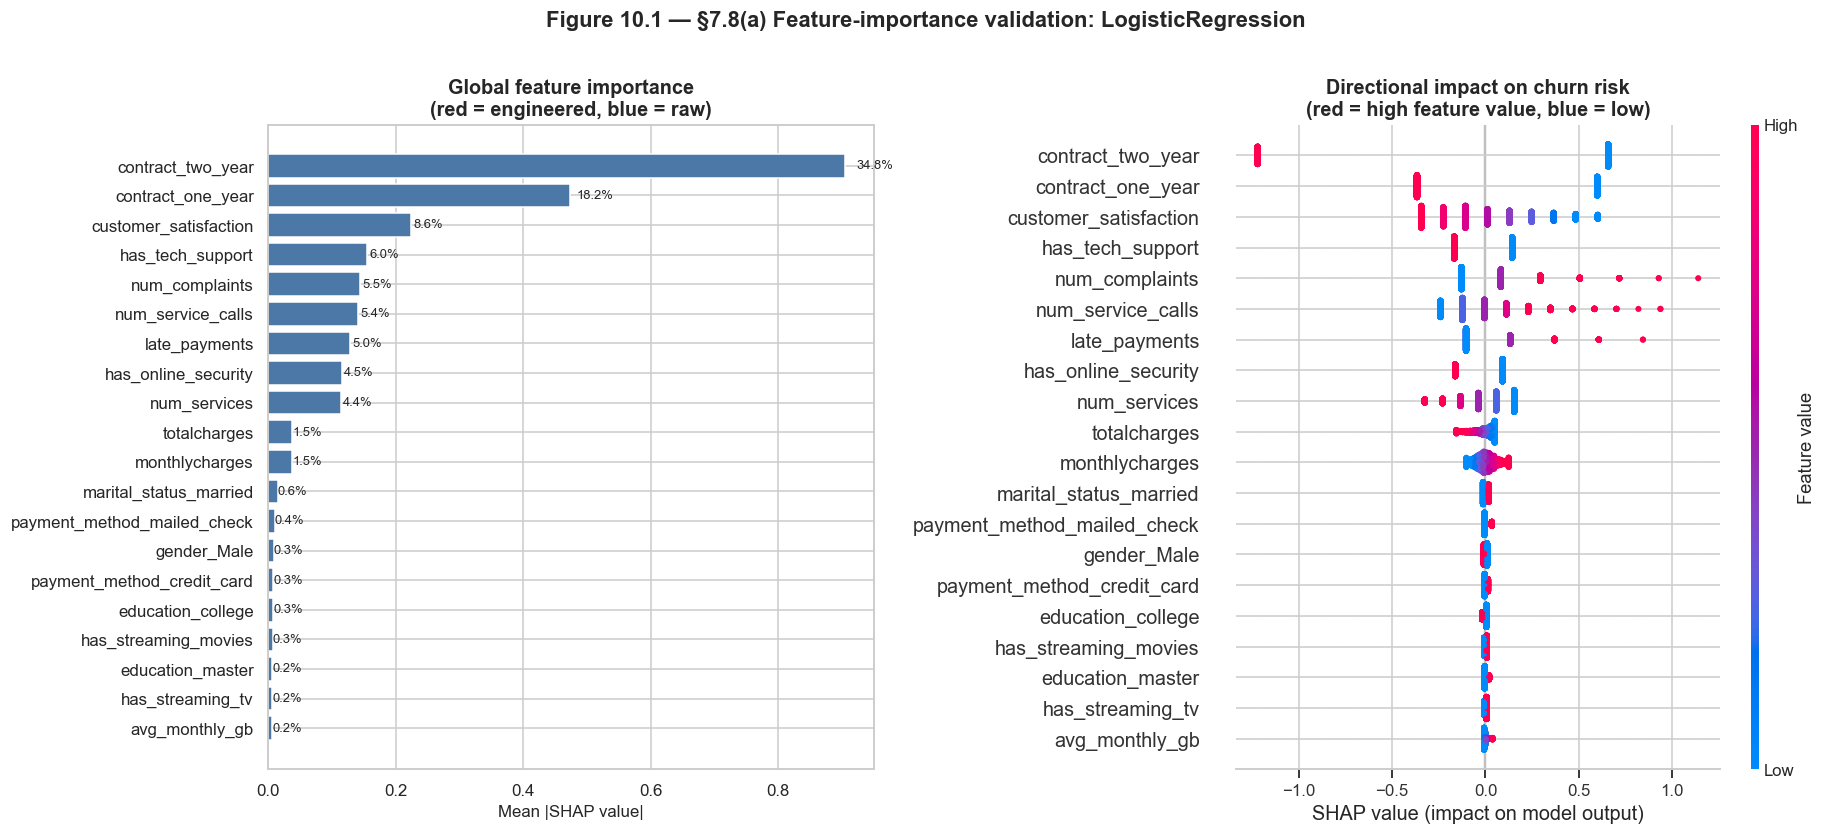

In [98]:
# ---- Global importance and directional beeswarm ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))

_top = IMPORTANCE.head(20).iloc[::-1]
axes[0].barh(_top.feature, _top.mean_abs_shap,
             color=[C_CHURN if o == "engineered" else C_STAY for o in _top.origin])
for y, (v, s) in enumerate(zip(_top.mean_abs_shap, _top.share_pct)):
    axes[0].text(v * 1.02, y, f"{s:.1f}%", va="center", fontsize=8.5)
axes[0].set_xlabel("Mean |SHAP value|")
axes[0].set_title("Global feature importance\n(red = engineered, blue = raw)")

plt.sca(axes[1])
_order = [FEATURE_NAMES_OUT.index(f) for f in IMPORTANCE.head(20).feature]
shap.summary_plot(SHAP_VALUES[:, _order], X_shap.iloc[:, _order],
                  feature_names=[FEATURE_NAMES_OUT[i] for i in _order],
                  show=False, plot_size=None, max_display=20)
axes[1].set_title("Directional impact on churn risk\n"
                  "(red = high feature value, blue = low)")

fig.suptitle(f"Figure 10.1 — §7.8(a) Feature-importance validation: "
             f"{CHAMPION_NAME}", fontweight="semibold", y=1.01)
savefig("fig_10_1_shap_global")
plt.show()

In [99]:
# ---- Cross-check: does the model agree with the EDA? ----------------------
# Independent evidence. The EDA ranked features by univariate association with
# no model involved; SHAP ranks them by contribution inside a fitted model. High
# rank agreement means the model learned the structure the data actually contain.
_eda_rank = (SIGNAL_ALL.set_index("feature")["abs_r"]
             .rank(ascending=False).to_dict())
_shap_rank = IMPORTANCE.set_index("feature")["rank"].to_dict()
_common = [f for f in _shap_rank if f in _eda_rank]

_rho, _rho_p = stats.spearmanr([_eda_rank[f] for f in _common],
                               [_shap_rank[f] for f in _common])

VALIDATION_10A = pd.DataFrame([
    ("Features comparable to the EDA ranking", f"{len(_common)}"),
    ("Spearman rank correlation, EDA vs SHAP", f"{_rho:.3f} (p = {_rho_p:.3g})"),
    ("Top SHAP driver", f"{IMPORTANCE.feature.iloc[0]} "
                        f"({IMPORTANCE.share_pct.iloc[0]:.1f}% of attribution)"),
    ("Features carrying 80% of attribution",
     f"{int((IMPORTANCE.cumulative_pct <= 80).sum()) + 1} of {len(IMPORTANCE)}"),
    ("Engineered share of attribution", f"{ENGINEERED_SHAP_SHARE:.1f}%"),
], columns=["validation check", "result"])
VALIDATION_10A

,validation check,result
0,Features comparable to the EDA ranking,23
1,"Spearman rank correlation, EDA vs SHAP",0.658 (p = 0.000641)
2,Top SHAP driver,contract_two_year (34.8% of attribution)
3,Features carrying 80% of attribution,7 of 38
4,Engineered share of attribution,0.0%


## 10.3 §7.8(b) — Model debugging: the negative-control test

EDA finding 3 identified a block of features with **no association with churn
whatsoever** (|r| < 0.01). They were deliberately retained for exactly this
moment. A correctly behaved model must assign them near-zero SHAP attribution.

This is a genuine falsifiable test with a stated pass criterion, not a
descriptive exercise:

> **Pass criterion.** (a) The noise block's share of total SHAP attribution must
> be **less than half its share of the columns** — that is, a noise feature must
> be less than half as influential as the average feature — and (b) its median
> importance rank must fall in the **bottom half** of the feature list.
>
> The criterion is proportional rather than a flat percentage because the size of
> the noise block is a property of the data, not a design choice: a flat
> threshold would become easier or harder to pass purely as a function of how
> many uninformative columns the dataset happens to contain.

Failure would indicate the model is fitting sampling artefacts — precisely the
*"identifying whether specific features are introducing bias or creating false
correlations"* purpose §7.8(b) specifies.

### Step 10.3 — Run the negative-control test

In [100]:
# ---- Negative-control test on the EDA-identified noise features ------------
_noise_mask = np.array([
    any(f == c or f.startswith(f"{c}_") for c in NOISE_FEATURES)
    for f in IMPORTANCE.feature])

assert _noise_mask.any(), (
    "No encoded column maps back to the EDA noise block, so the negative "
    "control cannot be run. Check NOISE_FEATURES against FEATURE_NAMES_OUT.")

NOISE_SHARE = float(IMPORTANCE.loc[_noise_mask, "share_pct"].sum())
NOISE_MEDIAN_RANK = float(np.median(IMPORTANCE.loc[_noise_mask, "rank"]))
SIGNAL_MEDIAN_RANK = float(np.median(IMPORTANCE.loc[~_noise_mask, "rank"]))

# Proportional criterion: how influential is a noise feature relative to the
# average feature? A value of 1.0 would mean noise features are exactly as
# important as everything else, which is what a broken model would produce.
NOISE_COLUMN_SHARE = 100 * _noise_mask.sum() / len(IMPORTANCE)
NOISE_INFLUENCE_RATIO = NOISE_SHARE / max(NOISE_COLUMN_SHARE, EPS)

_share_pass = NOISE_INFLUENCE_RATIO < 0.5
_rank_pass = NOISE_MEDIAN_RANK > len(IMPORTANCE) / 2
NEGATIVE_CONTROL_PASS = bool(_share_pass and _rank_pass)

NEGATIVE_CONTROL = pd.DataFrame([
    ("Noise-block columns",
     f"{int(_noise_mask.sum())} of {len(IMPORTANCE)}  ({NOISE_COLUMN_SHARE:.1f}% of columns)"),
    ("Share of total SHAP attribution", f"{NOISE_SHARE:.2f}%"),
    ("Influence relative to the average feature",
     f"{NOISE_INFLUENCE_RATIO:.3f}x  "
     f"({'PASS' if _share_pass else 'FAIL'} — criterion < 0.5x)"),
    ("Median importance rank, noise block",
     f"{NOISE_MEDIAN_RANK:.0f} of {len(IMPORTANCE)}  "
     f"({'PASS' if _rank_pass else 'FAIL'} — criterion > {len(IMPORTANCE) / 2:.0f})"),
    ("Median importance rank, signal block", f"{SIGNAL_MEDIAN_RANK:.0f}"),
    ("Highest-ranked noise feature",
     f"{IMPORTANCE.loc[_noise_mask].feature.iloc[0]} "
     f"(rank {int(IMPORTANCE.loc[_noise_mask]['rank'].iloc[0])})"),
    ("OVERALL", "PASS" if NEGATIVE_CONTROL_PASS else "FAIL — investigate"),
], columns=["negative-control check", "result"])
NEGATIVE_CONTROL

,negative-control check,result
0,Noise-block columns,12 of 38 (31.6% of columns)
1,Share of total SHAP attribution,1.97%
2,Influence relative to the average feature,0.062x (PASS — criterion < 0.5x)
3,"Median importance rank, noise block",24 of 38 (PASS — criterion > 19)
4,"Median importance rank, signal block",14
5,Highest-ranked noise feature,has_streaming_movies (rank 17)
6,OVERALL,PASS


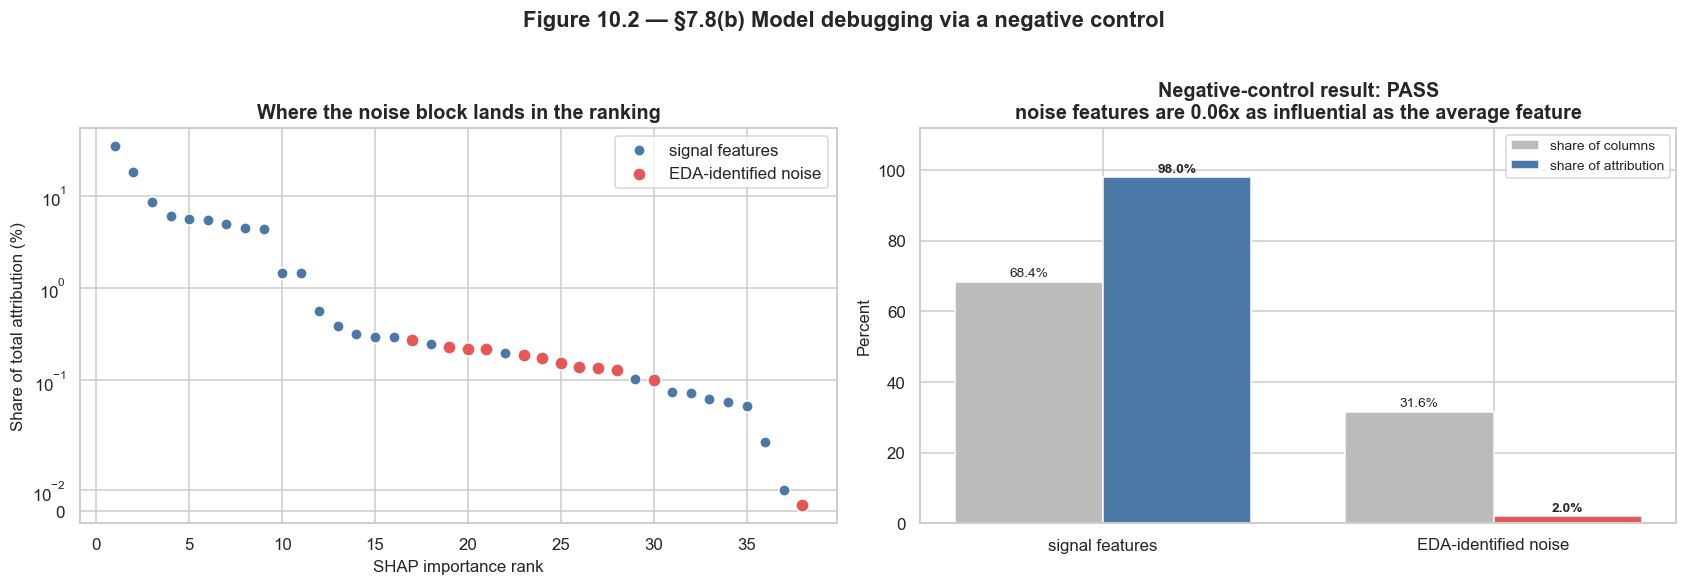

In [101]:
# ---- Visualise the separation between signal and noise --------------------
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))

axes[0].scatter(IMPORTANCE.loc[~_noise_mask, "rank"],
                IMPORTANCE.loc[~_noise_mask, "share_pct"],
                s=55, color=C_STAY, label="signal features", edgecolors="white")
axes[0].scatter(IMPORTANCE.loc[_noise_mask, "rank"],
                IMPORTANCE.loc[_noise_mask, "share_pct"],
                s=75, color=C_CHURN, label="EDA-identified noise", edgecolors="white",
                zorder=3)
axes[0].set_xlabel("SHAP importance rank")
axes[0].set_ylabel("Share of total attribution (%)")
axes[0].set_yscale("symlog", linthresh=0.05)
axes[0].set_title("Where the noise block lands in the ranking")
axes[0].legend()

_share_of_cols = [100 - NOISE_COLUMN_SHARE, NOISE_COLUMN_SHARE]
_share_of_attr = [100 - NOISE_SHARE, NOISE_SHARE]
_x = np.arange(2)
axes[1].bar(_x - 0.19, _share_of_cols, 0.38, label="share of columns",
            color="#BBBBBB")
axes[1].bar(_x + 0.19, _share_of_attr, 0.38, label="share of attribution",
            color=[C_STAY, C_CHURN])
for i, (a, b) in enumerate(zip(_share_of_cols, _share_of_attr)):
    axes[1].text(i - 0.19, a + 1.4, f"{a:.1f}%", ha="center", fontsize=9)
    axes[1].text(i + 0.19, b + 1.4, f"{b:.1f}%", ha="center", fontweight="semibold",
                 fontsize=9)
axes[1].set_xticks(_x)
axes[1].set_xticklabels(["signal features", "EDA-identified noise"])
axes[1].set_ylabel("Percent")
axes[1].set_ylim(0, 112)
axes[1].legend(fontsize=9)
axes[1].set_title(f"Negative-control result: "
                  f"{'PASS' if NEGATIVE_CONTROL_PASS else 'FAIL'}\n"
                  f"noise features are {NOISE_INFLUENCE_RATIO:.2f}x as influential "
                  f"as the average feature")

fig.suptitle("Figure 10.2 — §7.8(b) Model debugging via a negative control",
             fontweight="semibold", y=1.02)
savefig("fig_10_2_negative_control")
plt.show()

## 10.4 §7.8(c) — Actionable insights

### Step 10.4a — Individual customer explanations

This is the output a retention analyst actually receives: for one named
customer, the specific features that pushed their risk up or down, and by how
much. §7.8 identifies this as the second main advantage of SHAP — explaining
*"why a specific customer is classified as likely to churn"*.

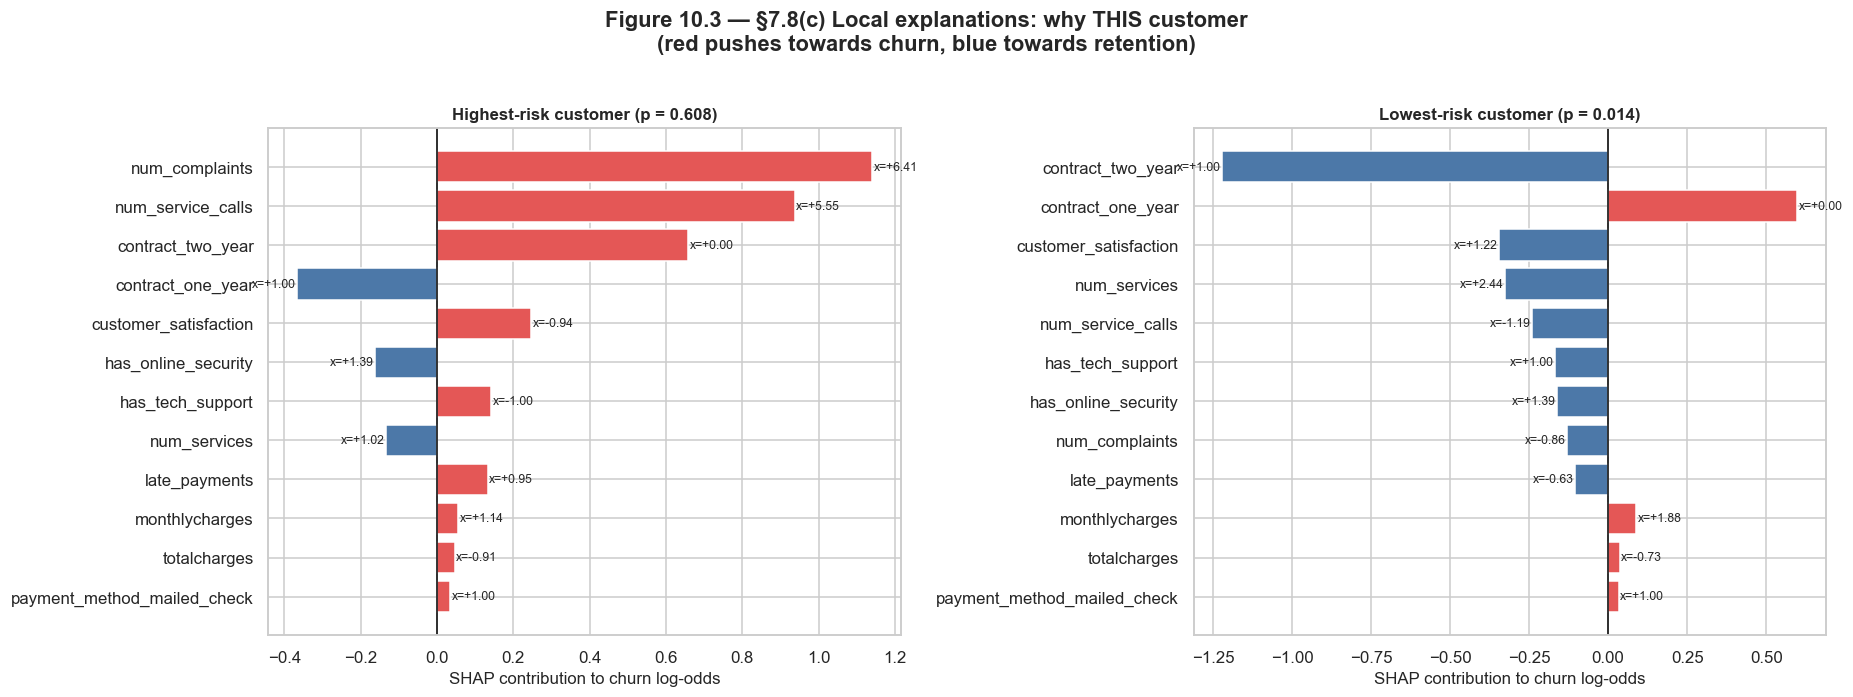

In [102]:
# ---- Local explanations for a high-risk and a low-risk customer -----------
_proba = CHAMPION_FITTED.predict_proba(X_shap_raw)[:, 1]
_high_risk = int(np.argmax(_proba))
_low_risk = int(np.argmin(_proba))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))
for ax, idx, title in [
    (axes[0], _high_risk, f"Highest-risk customer (p = {_proba[_high_risk]:.3f})"),
    (axes[1], _low_risk, f"Lowest-risk customer (p = {_proba[_low_risk]:.3f})"),
]:
    contrib = pd.DataFrame({
        "feature": FEATURE_NAMES_OUT,
        "shap": SHAP_VALUES[idx],
        "value": X_shap.iloc[idx].values,
    })
    contrib = contrib.reindex(contrib.shap.abs().sort_values().index).tail(12)

    ax.barh(contrib.feature, contrib.shap,
            color=[C_CHURN if v > 0 else C_STAY for v in contrib.shap])
    ax.axvline(0, color="black", lw=1)
    for y, (s, v) in enumerate(zip(contrib.shap, contrib.value)):
        ax.text(s + (0.004 if s >= 0 else -0.004), y, f"x={v:+.2f}",
                va="center", ha="left" if s >= 0 else "right", fontsize=8)
    ax.set_xlabel("SHAP contribution to churn log-odds")
    ax.set_title(title, fontsize=11)

fig.suptitle("Figure 10.3 — §7.8(c) Local explanations: why THIS customer\n"
             "(red pushes towards churn, blue towards retention)",
             fontweight="semibold", y=1.02)
savefig("fig_10_3_local_explanations")
plt.show()

### Step 10.4b — Dependence plots on the top drivers

Dependence plots show *how* risk responds to each driver across its range. For a
retention team this converts an importance ranking into a policy: it identifies
the value at which risk begins to rise, which is where an intervention should
trigger.

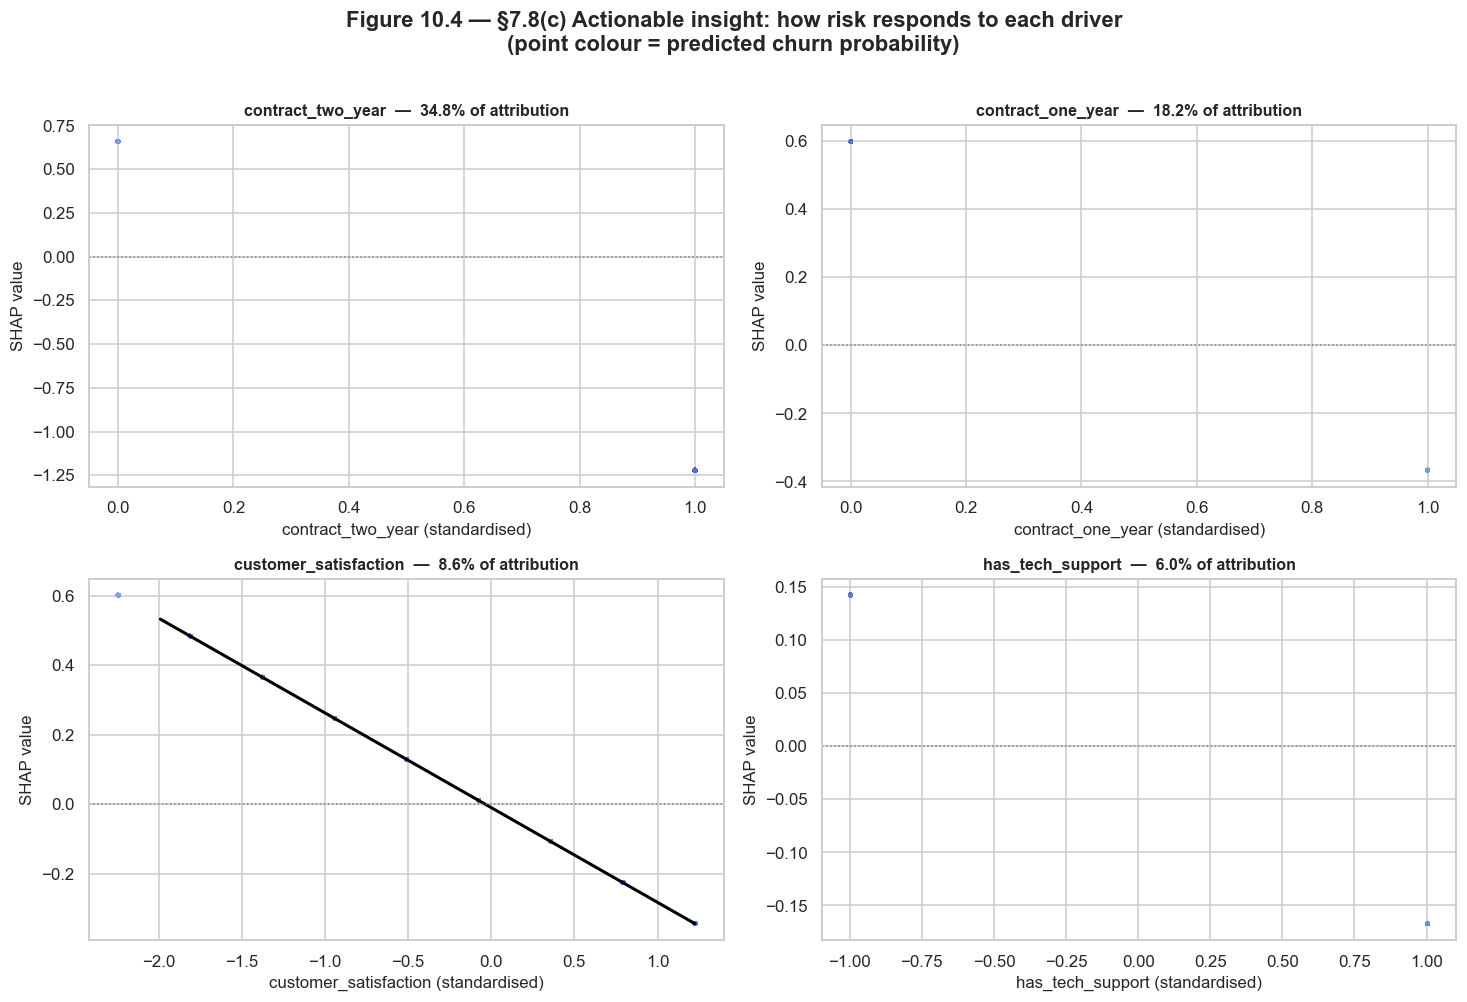

In [103]:
# ---- Dependence plots for the four strongest drivers ---------------------
_drivers = IMPORTANCE.head(4).feature.tolist()
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9))

for ax, feature in zip(axes.ravel(), _drivers):
    j = FEATURE_NAMES_OUT.index(feature)
    x_vals = X_shap.iloc[:, j].to_numpy()
    ax.scatter(x_vals, SHAP_VALUES[:, j], s=9, alpha=0.30,
               c=_proba, cmap="coolwarm", edgecolors="none")

    # A binned mean makes the response curve readable through the scatter.
    if len(np.unique(x_vals)) > 8:
        bins = np.quantile(x_vals, np.linspace(0, 1, 21))
        centres, means = [], []
        for lo, hi in zip(bins[:-1], bins[1:]):
            m = (x_vals >= lo) & (x_vals <= hi)
            if m.sum() > 5:
                centres.append(x_vals[m].mean())
                means.append(SHAP_VALUES[m, j].mean())
        ax.plot(centres, means, "-", color="black", lw=2)

    ax.axhline(0, color="grey", ls=":", lw=1)
    ax.set_xlabel(f"{feature} (standardised)")
    ax.set_ylabel("SHAP value")
    ax.set_title(f"{feature}  —  {IMPORTANCE.loc[IMPORTANCE.feature == feature, 'share_pct'].iloc[0]:.1f}% "
                 f"of attribution", fontsize=10.5)

fig.suptitle("Figure 10.4 — §7.8(c) Actionable insight: how risk responds to each driver\n"
             "(point colour = predicted churn probability)", fontweight="semibold", y=1.01)
savefig("fig_10_4_dependence")
plt.show()

In [104]:
# ---- Translate the interpretability output into retention actions --------
_top_drivers = IMPORTANCE.head(8)[["rank", "feature", "share_pct", "origin"]].copy()
_top_drivers["direction"] = np.where(
    [SHAP_VALUES[:, FEATURE_NAMES_OUT.index(f)][
        X_shap[f].to_numpy() > X_shap[f].median()].mean() > 0
     for f in _top_drivers.feature],
    "higher value raises churn risk", "higher value lowers churn risk")
ACTIONABLE = _top_drivers.round(3)
ACTIONABLE

,rank,feature,share_pct,origin,direction
0,1,contract_two_year,34.7780,raw,higher value lowers churn risk
1,2,contract_one_year,18.1970,raw,higher value lowers churn risk
2,3,customer_satisfaction,8.6040,raw,higher value lowers churn risk
3,4,has_tech_support,5.9620,raw,higher value lowers churn risk
4,5,num_complaints,5.5470,raw,higher value raises churn risk
5,6,num_service_calls,5.4360,raw,higher value raises churn risk
6,7,late_payments,4.9520,raw,higher value raises churn risk
7,8,has_online_security,4.4600,raw,higher value lowers churn risk


---
# Part 11 — Final evaluation on the held-out test partition

Every number so far has come from cross-validation on the **development
subsample**. This part produces the study's headline figures by

1. **refitting** each finalist on the **full 800,000-row training partition**, and
2. scoring it once on the **200,000-row test partition** created in §3.1 and
   untouched since.

## Why each model gets its own decision threshold

The proposal's threshold-dependent metrics — accuracy, precision, recall, F1 —
all depend on where the score is cut. Different models produce differently
**shaped** score distributions: a cost-weighted Logistic Regression outputs
probabilities centred near the base rate, whereas an unpruned Decision Tree
outputs near-binary scores. A single global cut-off applied to both does not
compare them fairly; it compares one model at a sensible operating point against
another at an arbitrary one.

Each model therefore gets a threshold derived from **its own out-of-fold
predictions on the development sample**, chosen to maximise F1. Those
predictions come from data inside the training partition, so the test partition
plays no part in choosing any threshold. The threshold-free ROC-AUC and PR-AUC
are reported alongside, and remain the basis for all ranking claims.

## 11.1 Deriving a per-model operating threshold

### Step 11.1 — Sweep thresholds against each model's own out-of-fold scores

In [105]:
# ---- Out-of-fold probabilities on the development sample ------------------
def out_of_fold_probabilities(spec, X, y, n_splits=3):
    """Collect held-out predictions for every dev-sample row, without leakage.

    Each row is predicted by a model that never saw it during training, so the
    resulting score distribution is an honest basis for threshold selection.
    """
    feature_spec = FEATURE_SETS[spec["feature_set"]]
    Xf = X[feature_spec["features"]]
    oof = np.zeros(len(y), dtype=float)
    splitter = StratifiedKFold(n_splits=n_splits, shuffle=True,
                               random_state=RANDOM_STATE)

    for tr, va in splitter.split(Xf, y):
        if spec["family"] == "ML":
            model = LeakageSafeClassifier(
                spec["estimator"], numeric_features=feature_spec["numeric"],
                categorical_features=feature_spec["categorical"],
                winsorise_cols=WINSORISE_COLS, imbalance=IMBALANCE_CHOICE,
                random_state=RANDOM_STATE)
        else:
            model = KerasChurnClassifier(
                spec["builder"], feature_spec["numeric"], feature_spec["categorical"],
                winsorise_cols=WINSORISE_COLS, imbalance=IMBALANCE_CHOICE,
                random_state=RANDOM_STATE)
        model.fit(Xf.iloc[tr], y.iloc[tr])
        oof[va] = model.predict_proba(Xf.iloc[va])[:, 1]
        if spec["family"] == "DL":
            keras.backend.clear_session()
    return oof


def best_f1_threshold(y_true, proba, grid=None):
    """Threshold maximising F1 on the given out-of-fold scores."""
    grid = grid if grid is not None else np.quantile(proba, np.linspace(0.50, 0.999, 120))
    scores = [(t, f1_score(y_true, (proba >= t).astype(int), zero_division=0))
              for t in np.unique(grid)]
    best_t, best_f1 = max(scores, key=lambda kv: kv[1])
    return float(best_t), float(best_f1), scores


print("Deriving one operating threshold per finalist from out-of-fold predictions...\n")
THRESHOLDS = {}
_oof_store = {}
for spec in FINALIST_SPECS:
    t0 = time.perf_counter()
    oof = out_of_fold_probabilities(spec, X_dev, y_dev)
    threshold, f1_at_t, sweep = best_f1_threshold(y_dev, oof)
    THRESHOLDS[spec["name"]] = threshold
    _oof_store[spec["name"]] = (oof, sweep)
    print(f"  {spec['name']:<20s} threshold {threshold:.4f}  "
          f"(out-of-fold F1 {f1_at_t:.4f})  [{time.perf_counter() - t0:.0f}s]")

Deriving one operating threshold per finalist from out-of-fold predictions...



  LogisticRegression   threshold 0.1273  (out-of-fold F1 0.2704)  [6s]


  XGBoost              threshold 0.1344  (out-of-fold F1 0.2690)  [7s]


  ANN                  threshold 0.1423  (out-of-fold F1 0.2671)  [23s]


  DNN                  threshold 0.1288  (out-of-fold F1 0.2684)  [61s]


  RandomForest         threshold 0.1283  (out-of-fold F1 0.2682)  [32s]


  DecisionTree         threshold 0.1246  (out-of-fold F1 0.2587)  [7s]


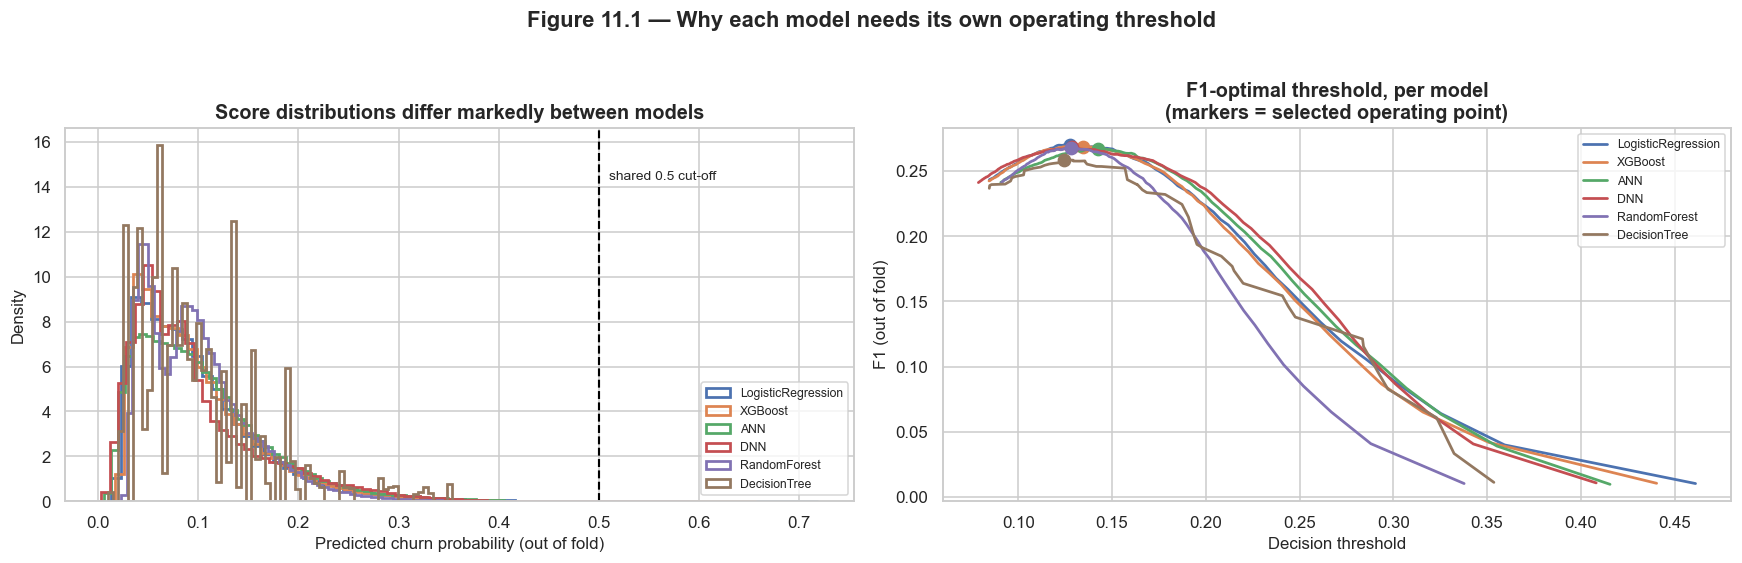

In [106]:
# ---- Why one shared threshold would have been wrong ----------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for name, (oof, _) in _oof_store.items():
    axes[0].hist(oof, bins=70, histtype="step", lw=1.8, density=True, label=name)
axes[0].axvline(0.5, color="black", ls="--", lw=1.4)
axes[0].text(0.51, axes[0].get_ylim()[1] * 0.86, "shared 0.5 cut-off", fontsize=9)
axes[0].set_xlabel("Predicted churn probability (out of fold)")
axes[0].set_ylabel("Density")
axes[0].set_title("Score distributions differ markedly between models")
axes[0].legend(fontsize=8)

for name, (_, sweep) in _oof_store.items():
    ts = [t for t, _ in sweep]
    f1s = [f for _, f in sweep]
    line, = axes[1].plot(ts, f1s, lw=1.8, label=name)
    axes[1].plot(THRESHOLDS[name], max(f1s), "o", color=line.get_color(), ms=8)
axes[1].set_xlabel("Decision threshold")
axes[1].set_ylabel("F1 (out of fold)")
axes[1].set_title("F1-optimal threshold, per model\n(markers = selected operating point)")
axes[1].legend(fontsize=8)

fig.suptitle("Figure 11.1 — Why each model needs its own operating threshold",
             fontweight="semibold", y=1.02)
savefig("fig_11_1_thresholds")
plt.show()

## 11.2 Refit on the full training partition and score the held-out test set

### Step 11.2 — The study's headline result

In [107]:
# ---- Refit every finalist on all 800k training rows, score the 200k test set -
print(f"Refitting on {len(y_train_full):,} training rows, "
      f"scoring {len(y_test):,} held-out customers.\n")

TEST_RESULTS = []
FITTED_FINALISTS = {}
TEST_PROBABILITIES = {}
_probe = X_test.iloc[:min(20_000, len(X_test))]

for spec in FINALIST_SPECS:
    feature_spec = FEATURE_SETS[spec["feature_set"]]
    X_tr = X_train_full[feature_spec["features"]]
    X_te = X_test[feature_spec["features"]]

    if spec["family"] == "ML":
        model = LeakageSafeClassifier(
            spec["estimator"], numeric_features=feature_spec["numeric"],
            categorical_features=feature_spec["categorical"],
            winsorise_cols=WINSORISE_COLS, imbalance=IMBALANCE_CHOICE,
            random_state=RANDOM_STATE)
    else:
        model = KerasChurnClassifier(
            spec["builder"], feature_spec["numeric"], feature_spec["categorical"],
            winsorise_cols=WINSORISE_COLS, imbalance=IMBALANCE_CHOICE,
            random_state=RANDOM_STATE)

    t0 = time.perf_counter()
    model.fit(X_tr, y_train_full)
    train_seconds = time.perf_counter() - t0

    proba = model.predict_proba(X_te)[:, 1]
    threshold = THRESHOLDS[spec["name"]]
    timing = benchmark_inference(model, _probe[feature_spec["features"]])

    TEST_RESULTS.append({
        "model": spec["name"], "family": spec["family"],
        "configuration": EXPERIMENT_LABELS[spec["experiment"]],
        "threshold": threshold,
        **classification_metrics(y_test, proba, threshold=threshold),
        "train_seconds_full": train_seconds,
        **timing,
    })
    FITTED_FINALISTS[spec["name"]] = model
    TEST_PROBABILITIES[spec["name"]] = proba

    print(f"  {spec['name']:<20s} AUC {TEST_RESULTS[-1]['roc_auc']:.4f}  "
          f"F1 {TEST_RESULTS[-1]['f1']:.4f}  recall {TEST_RESULTS[-1]['recall']:.4f}  "
          f"| train {train_seconds:6.1f}s  infer {timing['infer_ms_per_sample']:.5f} ms/sample")

TEST_TABLE = (pd.DataFrame(TEST_RESULTS)
              .sort_values(PRIMARY_METRIC, ascending=False).reset_index(drop=True))
TEST_TABLE[["model", "family", "threshold"] + METRIC_COLS +
           ["train_seconds_full", "infer_ms_per_sample", "online_p50_ms"]].round(5)

Refitting on 800,000 training rows, scoring 200,000 held-out customers.



  LogisticRegression   AUC 0.6855  F1 0.2686  recall 0.4701  | train    7.0s  infer 0.00153 ms/sample


  XGBoost              AUC 0.6844  F1 0.2679  recall 0.4336  | train    9.0s  infer 0.00174 ms/sample


  ANN                  AUC 0.6851  F1 0.2691  recall 0.4044  | train   20.8s  infer 0.00331 ms/sample


  DNN                  AUC 0.6846  F1 0.2637  recall 0.5379  | train   59.8s  infer 0.00404 ms/sample


  RandomForest         AUC 0.6799  F1 0.2645  recall 0.4495  | train   83.8s  infer 0.00576 ms/sample


  DecisionTree         AUC 0.6712  F1 0.2566  recall 0.4407  | train   13.4s  infer 0.00150 ms/sample


,model,family,threshold,roc_auc,pr_auc,f1,recall,precision,accuracy,brier,train_seconds_full,infer_ms_per_sample,online_p50_ms
0,LogisticRegression,ML,0.1273,0.6855,0.2037,0.2686,0.4701,0.1880,0.7459,0.0852,6.9905,0.0015,1.8521
1,ANN,DL,0.1423,0.6851,0.2042,0.2691,0.4044,0.2016,0.7820,0.0853,20.7644,0.0033,31.1300
2,DNN,DL,0.1288,0.6845,0.2031,0.2637,0.5379,0.1746,0.7019,0.0854,59.7727,0.0040,30.8183
3,XGBoost,ML,0.1344,0.6844,0.2056,0.2679,0.4336,0.1938,0.7648,0.0852,8.9903,0.0017,1.8699
4,RandomForest,ML,0.1283,0.6799,0.2005,0.2645,0.4495,0.1874,0.7520,0.0856,83.7572,0.0058,33.6910
5,DecisionTree,ML,0.1246,0.6712,0.1849,0.2566,0.4407,0.1810,0.7467,0.0859,13.4114,0.0015,1.7070


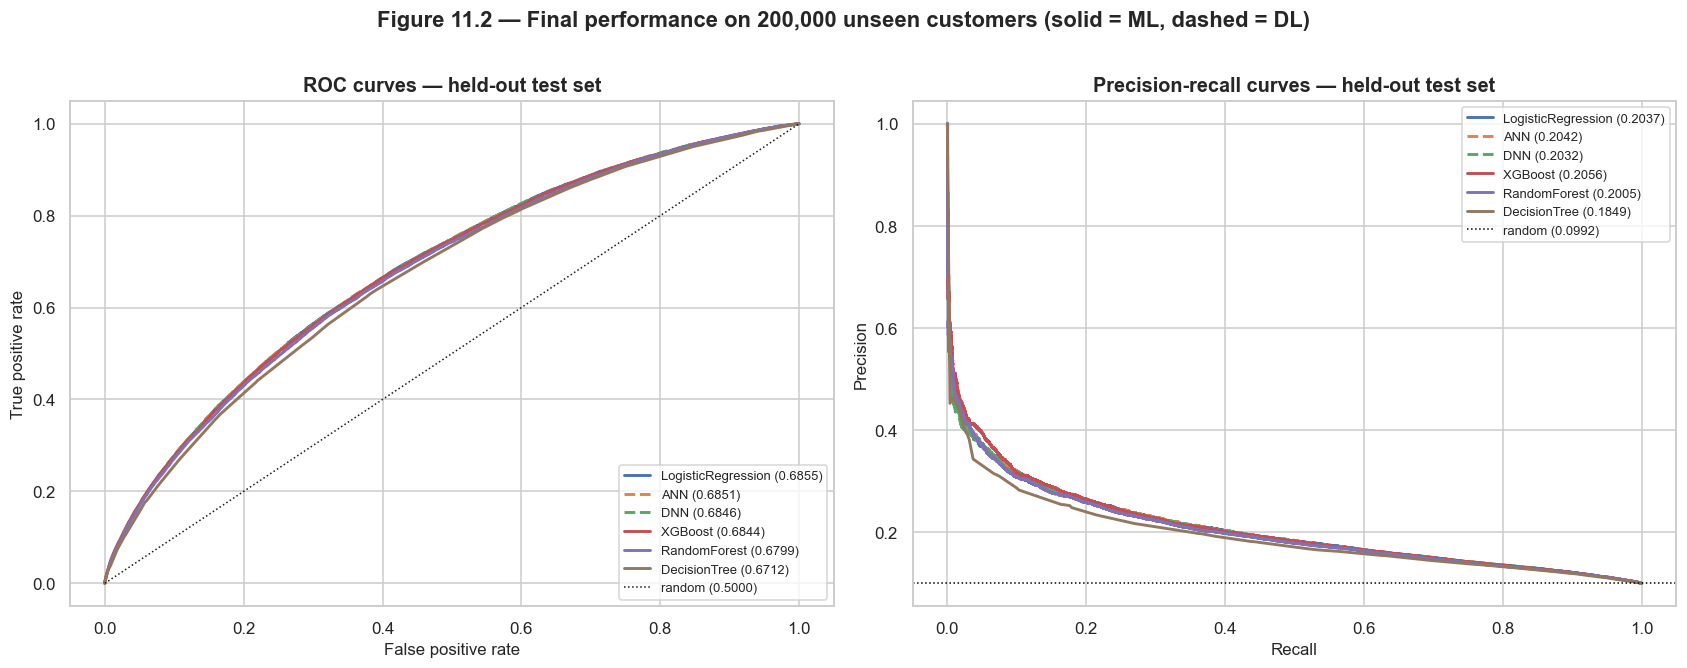

In [108]:
# ---- ROC and precision-recall curves on the held-out test set -------------
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6))

for _, row in TEST_TABLE.iterrows():
    proba = TEST_PROBABILITIES[row.model]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, lw=1.9,
                 ls="--" if row.family == "DL" else "-",
                 label=f"{row.model} ({row.roc_auc:.4f})")

    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, lw=1.9,
                 ls="--" if row.family == "DL" else "-",
                 label=f"{row.model} ({row.pr_auc:.4f})")

axes[0].plot([0, 1], [0, 1], "k:", lw=1, label="random (0.5000)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves — held-out test set")
axes[0].legend(fontsize=8.5, loc="lower right")

axes[1].axhline(y_test.mean(), color="black", ls=":", lw=1,
                label=f"random ({y_test.mean():.4f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves — held-out test set")
axes[1].legend(fontsize=8.5, loc="upper right")

fig.suptitle(f"Figure 11.2 — Final performance on {len(y_test):,} unseen customers "
             f"(solid = ML, dashed = DL)", fontweight="semibold", y=1.01)
savefig("fig_11_2_test_curves")
plt.show()

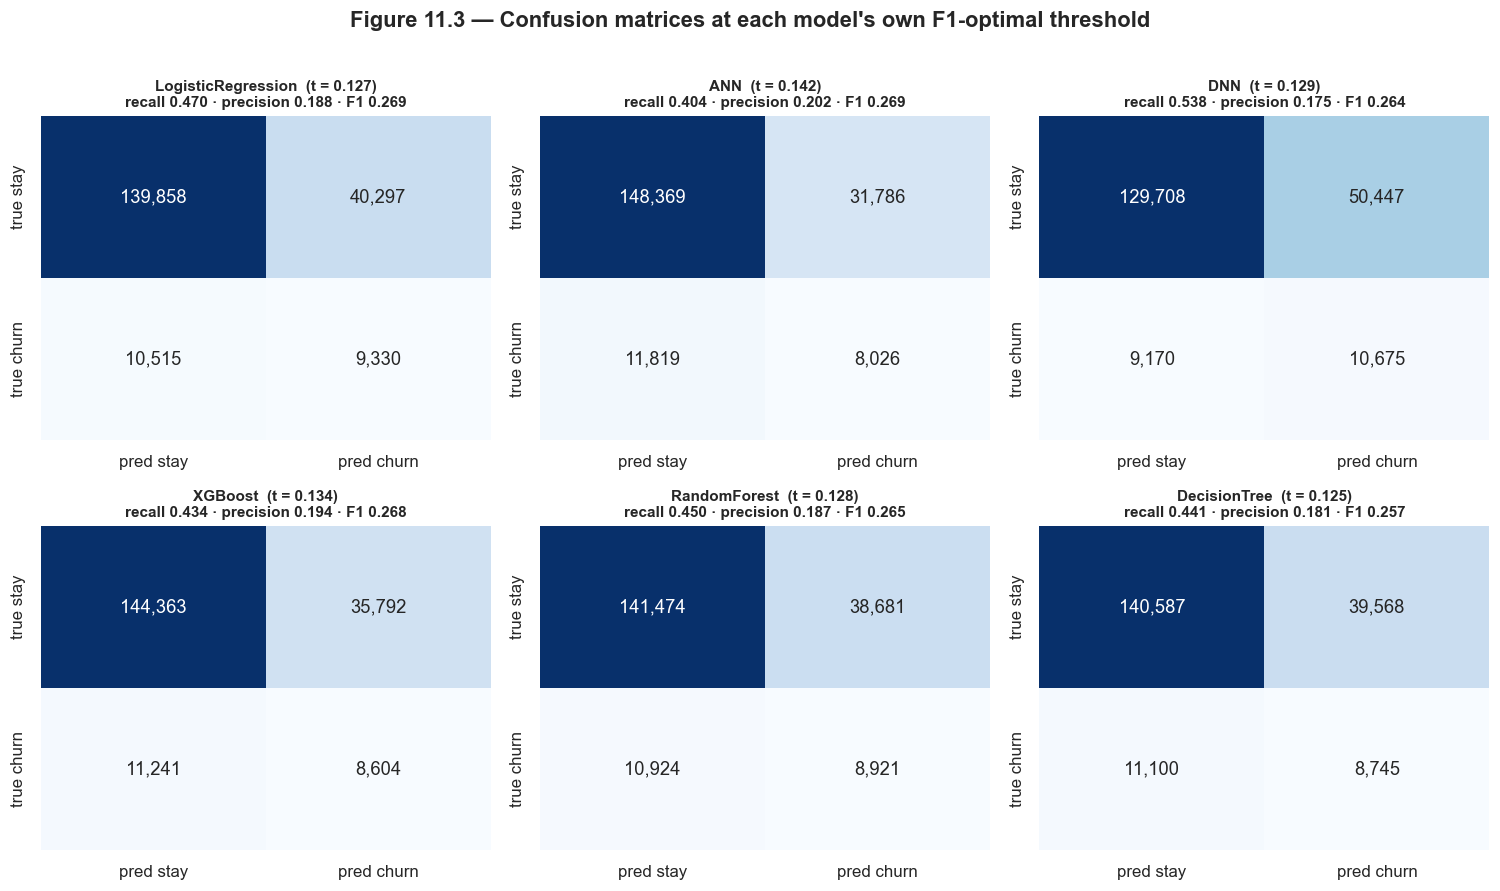

In [109]:
# ---- Confusion matrices at each model's own operating threshold ----------
from sklearn.metrics import confusion_matrix

_n = len(TEST_TABLE)
_ncol = 3
_nrow = int(np.ceil(_n / _ncol))
fig, axes = plt.subplots(_nrow, _ncol, figsize=(4.6 * _ncol, 4.0 * _nrow), squeeze=False)
axes = axes.ravel()

for ax, (_, row) in zip(axes, TEST_TABLE.iterrows()):
    pred = (TEST_PROBABILITIES[row.model] >= row.threshold).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["pred stay", "pred churn"],
                yticklabels=["true stay", "true churn"], ax=ax)
    ax.set_title(f"{row.model}  (t = {row.threshold:.3f})\n"
                 f"recall {row.recall:.3f} · precision {row.precision:.3f} · "
                 f"F1 {row.f1:.3f}", fontsize=10)

for ax in axes[_n:]:
    ax.set_visible(False)

fig.suptitle("Figure 11.3 — Confusion matrices at each model's own F1-optimal threshold",
             fontweight="semibold", y=1.01)
savefig("fig_11_3_confusion")
plt.show()

### Step 11.3 — Does the champion selected on CV survive on the test set?

The champion was chosen on cross-validated development data. If a different
model tops the held-out table, the selection did not generalise — that would be
a finding in its own right, and is checked explicitly rather than assumed away.

In [110]:
# ---- Confirm the CV-selected champion holds up out of sample --------------
_test_leader = TEST_TABLE.iloc[0]
CHAMPION_CONFIRMED = bool(_test_leader.model == CHAMPION_NAME)

_cv_auc = REPEATED_SUMMARY.loc[REPEATED_SUMMARY.model == CHAMPION_NAME,
                               PRIMARY_METRIC].iloc[0]
_test_auc = TEST_TABLE.loc[TEST_TABLE.model == CHAMPION_NAME, PRIMARY_METRIC].iloc[0]

CHAMPION_CHECK = pd.DataFrame([
    ("Champion selected on CV", CHAMPION_CANDIDATE),
    ("Top model on the held-out test set",
     f"{_test_leader.model} (AUC {_test_leader.roc_auc:.5f})"),
    ("Selection generalised", "YES" if CHAMPION_CONFIRMED else "NO — see below"),
    ("Champion CV AUC (dev sample, repeated)", f"{_cv_auc:.5f}"),
    ("Champion test AUC (200k unseen)", f"{_test_auc:.5f}"),
    ("Optimism of the CV estimate", f"{_cv_auc - _test_auc:+.5f}"),
    ("Test-set spread across all finalists",
     f"{TEST_TABLE[PRIMARY_METRIC].max() - TEST_TABLE[PRIMARY_METRIC].min():.5f} AUC"),
], columns=["check", "result"])
CHAMPION_CHECK

,check,result
0,Champion selected on CV,LogisticRegression [A]
1,Top model on the held-out test set,LogisticRegression (AUC 0.68552)
2,Selection generalised,YES
3,"Champion CV AUC (dev sample, repeated)",0.68752
4,Champion test AUC (200k unseen),0.68552
5,Optimism of the CV estimate,+0.00200
6,Test-set spread across all finalists,0.01435 AUC


---
# Part 12 — Monte Carlo simulation: champion versus deep learning

Parts 8 and 11 established which models rank customers best and how fast each
one scores. Neither answers the question a bank actually faces:

> **Given that a deep network may be more accurate but is slower and more
> expensive to run, which model creates more value — and how confident can we be
> in that answer?**

A point estimate cannot answer it, because every input is uncertain: the
measured accuracy gap is a sample statistic, latency varies run to run, and the
business parameters (customer value, offer cost, save rate) are estimates with
wide ranges. A Monte Carlo simulation propagates **all** of that uncertainty
through to the quantity that matters — net value — and reports a distribution
rather than a single number.

## The decision model

Each simulated month, the retention team scores its customer base, offers a
retention incentive to the **top *K* highest-risk customers**, and saves a
fraction of those who were genuinely going to churn.

$$\text{Net value} = \underbrace{C_{\text{captured}} \times V_{\text{CLV}} \times r_{\text{save}}}_{\text{revenue retained}} - \underbrace{K \times c_{\text{offer}}}_{\text{campaign cost}} - \underbrace{c_{\text{infra}}}_{\text{scoring + retraining compute}}$$

## Two stages of uncertainty

1. **Statistical.** Bootstrap resampling of the held-out test set gives the
   sampling distribution of each model's capture rate at the top-*K* cut-off.
   This is where the "is the accuracy gap real?" question enters quantitatively.
2. **Parametric.** Business and infrastructure inputs are drawn from
   distributions rather than fixed, so the conclusion is not an artefact of one
   set of assumptions.

Everything downstream of the model comparison is identical between models, so
the simulated difference is attributable to the models alone.

## 12.1 Stage 1 — the statistical uncertainty in each model's capture rate

### Step 12.1 — Bootstrap the held-out test set

Capture is measured by **ranking**, not by a threshold: each model orders the
customer base by risk and the top *K* receive an offer. This is exactly how a
capacity-constrained retention campaign operates, and it removes the threshold
from the comparison entirely.

In [111]:
# ---- Bootstrap each model's top-K capture rate on the held-out test set ---
MC_MODELS = [CHAMPION_NAME] + [m for m in TEST_TABLE.model
                               if m in DL_BUILDERS and m != CHAMPION_NAME]
N_BOOTSTRAP = 400 if not QUICK_RUN else 60
BOOTSTRAP_N = 50_000 if not QUICK_RUN else 8_000
CAMPAIGN_SHARE = 0.02          # contact-centre capacity: top 2% of the base per month

_rng = np.random.RandomState(RANDOM_STATE)
_y_test_arr = y_test.to_numpy()
_pool = min(BOOTSTRAP_N, len(_y_test_arr))
_k = max(1, int(CAMPAIGN_SHARE * _pool))

# Every model is scored on the SAME bootstrap resamples. Drawing separate
# resamples per model would inject sampling noise that has nothing to do with
# the models and would wash out the very difference the simulation measures.
BOOTSTRAP_INDICES = [_rng.randint(0, len(_y_test_arr), size=_pool)
                     for _ in range(N_BOOTSTRAP)]

CAPTURE_DRAWS = {}
for name in MC_MODELS:
    proba = TEST_PROBABILITIES[name]
    captured = []
    for idx in BOOTSTRAP_INDICES:
        p, yb = proba[idx], _y_test_arr[idx]
        top_k = np.argpartition(-p, _k - 1)[:_k]
        captured.append(int(yb[top_k].sum()))
    captured = np.array(captured, dtype=float)
    CAPTURE_DRAWS[name] = dict(captured=captured,
                               contacted=np.full(N_BOOTSTRAP, float(_k)),
                               capture_rate=captured / _k)

CAPTURE_SUMMARY = pd.DataFrame([{
    "model": name,
    "mean_captured": d["captured"].mean(),
    "capture_rate_mean": d["capture_rate"].mean(),
    "capture_rate_p05": np.quantile(d["capture_rate"], 0.05),
    "capture_rate_p95": np.quantile(d["capture_rate"], 0.95),
    "lift_over_random": d["capture_rate"].mean() / y_test.mean(),
} for name, d in CAPTURE_DRAWS.items()])

print(f"Bootstrap: {N_BOOTSTRAP} resamples of {_pool:,} test customers, "
      f"contacting the top {100 * CAMPAIGN_SHARE:.0f}%.\n")
CAPTURE_SUMMARY.round(4)

Bootstrap: 400 resamples of 50,000 test customers, contacting the top 2%.



,model,mean_captured,capture_rate_mean,capture_rate_p05,capture_rate_p95,lift_over_random
0,LogisticRegression,344.5625,0.3446,0.3210,0.3720,3.4725
1,ANN,341.7950,0.3418,0.3170,0.3700,3.4446
2,DNN,347.5250,0.3475,0.3230,0.3750,3.5024


### Step 12.1b — Does the AUC ranking survive at the operating point?

ROC-AUC integrates discrimination over **every** threshold, including regions no
retention campaign will ever operate in. A capacity-constrained team contacts
the top few percent of the risk ranking and is indifferent to how the model
orders the remaining 95%.

These are not the same objective, and they can disagree. A model with marginally
lower global AUC can still place *more genuine churners in the top 2%* — and
that, not AUC, is what determines the campaign's return.

This is checked directly, because if the two rankings disagree, the champion
selected in Part 8 on a threshold-free metric is not automatically the model a
business should deploy. Saying so plainly is more useful than allowing the
headline AUC table to imply a decision it does not support.

> **Read the two tables for different purposes.** The Part 8 leaderboard and the
> Part 11 test table answer *"which model discriminates best overall?"* — the
> question the research proposal asks, and the right basis for a claim about
> general model capability. The capture table below answers *"which model should
> we point at next month's campaign?"* — the question an operator asks. Where the
> two disagree, neither table is wrong; they are ranking on different objectives,
> and the disagreement is itself one of the more useful findings in this study.
> A model that is mid-table on ROC-AUC can lead at the shallow depths a
> capacity-constrained retention team actually works at, because ROC-AUC is
> averaging in discrimination across thresholds that will never be used.

In [112]:
# ---- Capture at the top K%, compared with the ranking by AUC --------------
CAPTURE_DEPTHS = [0.005, 0.01, 0.02, 0.05, 0.10, 0.20]
_all_models = list(TEST_TABLE.model)

_rows = []
for name in _all_models:
    proba = TEST_PROBABILITIES[name]
    for depth in CAPTURE_DEPTHS:
        k = max(1, int(depth * len(_y_test_arr)))
        top_k = np.argpartition(-proba, k - 1)[:k]
        captured = int(_y_test_arr[top_k].sum())
        _rows.append({
            "model": name, "depth": depth, "contacted": k,
            "churners_captured": captured,
            "capture_rate": captured / k,
            "recall_at_depth": captured / _y_test_arr.sum(),
            "lift": (captured / k) / _y_test_arr.mean(),
        })

CAPTURE_CURVE = pd.DataFrame(_rows)
_by_depth = CAPTURE_CURVE.pivot(index="model", columns="depth", values="churners_captured")
_by_depth = _by_depth.reindex(TEST_TABLE.set_index("model").index)   # AUC order

print("Churners captured at each campaign depth (rows in descending ROC-AUC order):")
print(_by_depth.to_string())

# Does the best-by-capture model differ from the best-by-AUC model?
CAPTURE_WINNERS = pd.DataFrame({
    "depth": CAPTURE_DEPTHS,
    "best_by_capture": [_by_depth[d].idxmax() for d in CAPTURE_DEPTHS],
    "champion_captured": [_by_depth.loc[CHAMPION_NAME, d] for d in CAPTURE_DEPTHS],
    "best_captured": [_by_depth[d].max() for d in CAPTURE_DEPTHS],
})
CAPTURE_WINNERS["champion_shortfall"] = (CAPTURE_WINNERS.best_captured
                                         - CAPTURE_WINNERS.champion_captured)
CAPTURE_WINNERS["champion_is_best"] = (CAPTURE_WINNERS.best_by_capture == CHAMPION_NAME)

print(f"\nChampion by ROC-AUC: {CHAMPION_NAME}")
print(f"Depths at which the champion also captures the most churners: "
      f"{int(CAPTURE_WINNERS.champion_is_best.sum())} of {len(CAPTURE_DEPTHS)}")
CAPTURE_WINNERS.round(4)

Churners captured at each campaign depth (rows in descending ROC-AUC order):
depth               0.0050  0.0100  0.0200  0.0500  0.1000  0.2000
model                                                             
LogisticRegression     427     762    1378    2857    4892    8057
ANN                    427     782    1372    2862    4881    8050
DNN                    409     765    1396    2868    4877    8030
XGBoost                447     814    1423    2909    4892    7993
RandomForest           433     773    1372    2817    4781    7899
DecisionTree           424     703    1262    2662    4564    7656

Champion by ROC-AUC: LogisticRegression
Depths at which the champion also captures the most churners: 2 of 6


,depth,best_by_capture,champion_captured,best_captured,champion_shortfall,champion_is_best
0,0.0050,XGBoost,427,447,20,False
1,0.0100,XGBoost,762,814,52,False
2,0.0200,XGBoost,1378,1423,45,False
3,0.0500,XGBoost,2857,2909,52,False
4,0.1000,LogisticRegression,4892,4892,0,True
5,0.2000,LogisticRegression,8057,8057,0,True


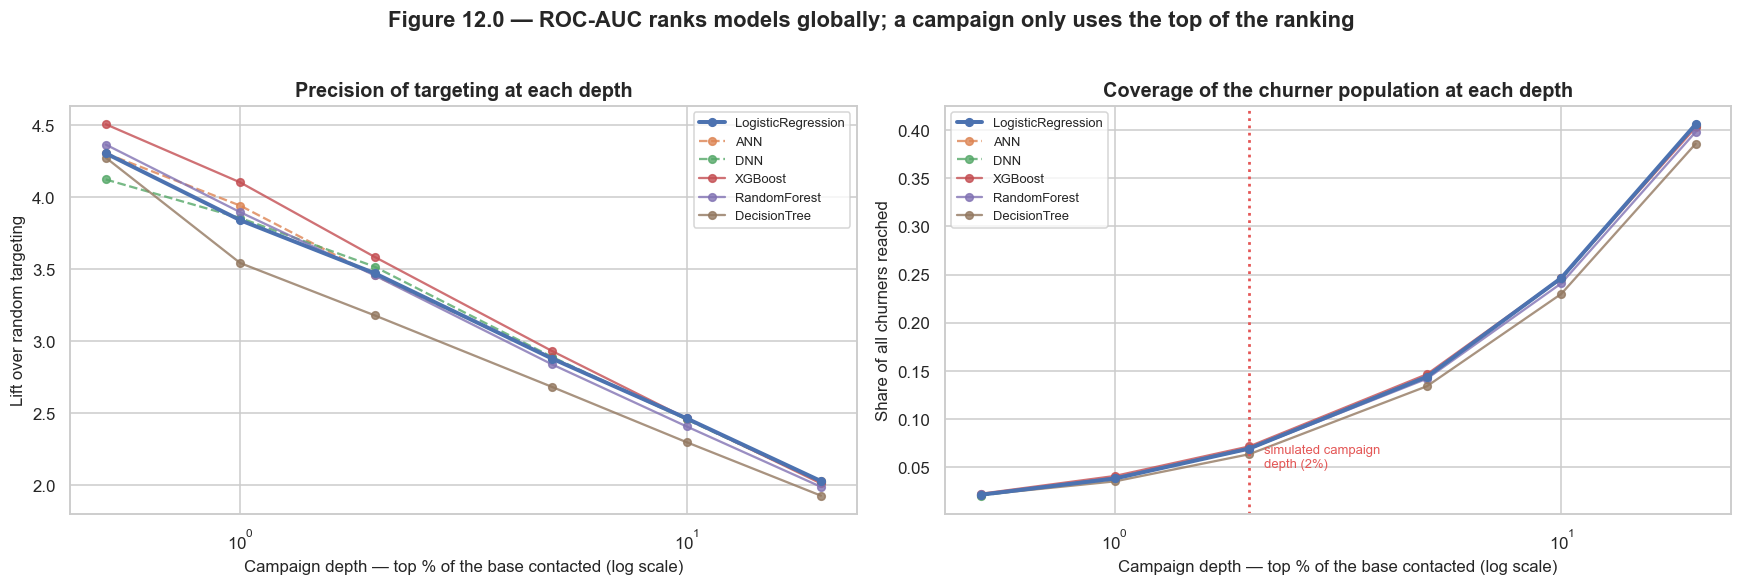

In [113]:
# ---- Visualise where the two objectives agree and disagree ---------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

for name in _all_models:
    sub = CAPTURE_CURVE[CAPTURE_CURVE.model == name].sort_values("depth")
    style = dict(lw=2.6, zorder=4) if name == CHAMPION_NAME else dict(lw=1.5, alpha=0.8)
    ls = "--" if TEST_TABLE.set_index("model").loc[name, "family"] == "DL" else "-"
    axes[0].plot(100 * sub.depth, sub.lift, ls, marker="o", ms=5, label=name, **style)
    axes[1].plot(100 * sub.depth, sub.recall_at_depth, ls, marker="o", ms=5,
                 label=name, **style)

axes[0].set_xscale("log")
axes[0].set_xlabel("Campaign depth — top % of the base contacted (log scale)")
axes[0].set_ylabel("Lift over random targeting")
axes[0].set_title("Precision of targeting at each depth")
axes[0].legend(fontsize=8.5)

axes[1].axvline(100 * CAMPAIGN_SHARE, color=C_CHURN, ls=":", lw=1.8)
axes[1].text(100 * CAMPAIGN_SHARE * 1.08, 0.05,
             f"simulated campaign\ndepth ({100 * CAMPAIGN_SHARE:.0f}%)",
             fontsize=8.5, color=C_CHURN)
axes[1].set_xscale("log")
axes[1].set_xlabel("Campaign depth — top % of the base contacted (log scale)")
axes[1].set_ylabel("Share of all churners reached")
axes[1].set_title("Coverage of the churner population at each depth")
axes[1].legend(fontsize=8.5)

fig.suptitle("Figure 12.0 — ROC-AUC ranks models globally; a campaign only uses "
             "the top of the ranking", fontweight="semibold", y=1.02)
savefig("fig_12_0_capture_curve")
plt.show()

## 12.2 Stage 2 — business and infrastructure assumptions

### Step 12.2 — Declare every simulation parameter as a distribution

Each parameter is given a distribution with a stated rationale. None of them is
tuned to produce a particular answer, and §12.5 tests directly how sensitive the
conclusion is to each one.

In [114]:
# ---- Monte Carlo parameter distributions ----------------------------------
MC_PARAMS = {
    "customer_base": 1_000_000,
    "scoring_runs_per_month": 4,        # weekly batch rescoring of the whole base
    "retrain_per_month": 1,             # monthly refresh on the full training set
    "compute_cost_per_cpu_hour": 0.12,  # commodity cloud vCPU rate (USD)
    "latency_sla_ms": 50.0,             # online scoring budget per request
    "peak_qps": 500,                    # real-time decisioning load at peak
    "hours_per_month": 730,
}


def infrastructure_cost(spec, base_size=None, peak_qps=None):
    """Monthly compute cost of running one model, in USD.

    Three components, because batch CPU-seconds alone badly understate the cost
    of a slow model. The dominant term for a real-time system is the *serving
    fleet*, which must be sized so that peak request rate x per-request latency
    can be absorbed concurrently — that scales directly with online latency and
    is where a 20x slower model actually becomes expensive.
    """
    base_size = MC_PARAMS["customer_base"] if base_size is None else base_size
    peak_qps = MC_PARAMS["peak_qps"] if peak_qps is None else peak_qps
    price = MC_PARAMS["compute_cost_per_cpu_hour"]

    # (1) Serving fleet, sized by Little's law: concurrency = arrival rate x latency.
    online_seconds = spec["online_p50_ms"] / 1000.0
    vcpus = max(1.0, np.ceil(peak_qps * online_seconds))
    serving = vcpus * MC_PARAMS["hours_per_month"] * price

    # (2) Batch rescoring of the whole customer base.
    batch_hours = (spec["ms_per_sample"] / 1000.0 * base_size
                   * MC_PARAMS["scoring_runs_per_month"]) / 3600.0

    # (3) Periodic retraining.
    retrain_hours = (spec["train_seconds"] * MC_PARAMS["retrain_per_month"]) / 3600.0

    return serving + (batch_hours + retrain_hours) * price

PARAM_RATIONALE = pd.DataFrame([
    ("Serving fleet", f"ceil({MC_PARAMS['peak_qps']} qps x online latency) vCPUs",
     "Little's law: a slower model needs proportionally more concurrent capacity"),
    ("Customer lifetime value", "Lognormal(median $600, sigma 0.6)",
     "Right-skewed: a minority of customers are worth far more than the median"),
    ("Retention offer cost", "Uniform($20, $80)",
     "Discount or incentive per contacted customer"),
    ("Save rate", "Beta(6, 14), mean ~0.30",
     "Share of genuinely at-risk contacts actually retained; churn campaigns rarely exceed 40%"),
    ("Campaign capacity", f"Top {100 * CAMPAIGN_SHARE:.0f}% of the base per month",
     "Fixed contact-centre capacity, identical for every model"),
    ("Capture at top-K", "Bootstrap of the held-out test set",
     "Carries the measured statistical uncertainty in each model's ranking"),
    ("Inference latency", "Lognormal fitted to the measured p50 and p90",
     "From the §7.7 Table 8 benchmark of the fitted models"),
    ("Compute price", f"${MC_PARAMS['compute_cost_per_cpu_hour']:.2f} per vCPU-hour",
     "Commodity cloud pricing"),
], columns=["parameter", "distribution", "rationale"])
PARAM_RATIONALE

,parameter,distribution,rationale
0,Serving fleet,ceil(500 qps x online latency) vCPUs,Little's law: a slower model needs proportiona...
1,Customer lifetime value,"Lognormal(median $600, sigma 0.6)",Right-skewed: a minority of customers are wort...
2,Retention offer cost,"Uniform($20, $80)",Discount or incentive per contacted customer
3,Save rate,"Beta(6, 14), mean ~0.30",Share of genuinely at-risk contacts actually r...
4,Campaign capacity,Top 2% of the base per month,"Fixed contact-centre capacity, identical for e..."
5,Capture at top-K,Bootstrap of the held-out test set,Carries the measured statistical uncertainty i...
6,Inference latency,Lognormal fitted to the measured p50 and p90,From the §7.7 Table 8 benchmark of the fitted ...
7,Compute price,$0.12 per vCPU-hour,Commodity cloud pricing


In [115]:
# ---- Fit a lognormal latency model to each model's measured timings -------
def latency_lognormal_params(p50_ms, p90_ms):
    """Recover lognormal (mu, sigma) from a measured median and 90th percentile."""
    p50_ms = max(p50_ms, 1e-9)
    p90_ms = max(p90_ms, p50_ms * 1.000001)
    mu = np.log(p50_ms)
    sigma = (np.log(p90_ms) - mu) / 1.2815515655446004   # z(0.90)
    return mu, max(sigma, 1e-6)


LATENCY_MODEL = {}
for name in MC_MODELS:
    row = TEST_TABLE[TEST_TABLE.model == name].iloc[0]
    LATENCY_MODEL[name] = {
        "online": latency_lognormal_params(row.online_p50_ms, row.online_p90_ms),
        "online_p50_ms": row.online_p50_ms,
        "ms_per_sample": row.infer_ms_per_sample,
        "train_seconds": row.train_seconds_full,
        "test_auc": row.roc_auc,
    }

pd.DataFrame([{
    "model": name,
    "online_p50_ms": TEST_TABLE.loc[TEST_TABLE.model == name, "online_p50_ms"].iloc[0],
    "online_p90_ms": TEST_TABLE.loc[TEST_TABLE.model == name, "online_p90_ms"].iloc[0],
    "batch_ms_per_sample": v["ms_per_sample"],
    "full_train_seconds": v["train_seconds"],
    "serving_vcpus": max(1.0, np.ceil(MC_PARAMS["peak_qps"] * v["online_p50_ms"] / 1000.0)),
    "monthly_infra_usd": round(infrastructure_cost(v), 2),
    "test_auc": v["test_auc"],
} for name, v in LATENCY_MODEL.items()]).round(5)

,model,online_p50_ms,online_p90_ms,batch_ms_per_sample,full_train_seconds,serving_vcpus,monthly_infra_usd,test_auc
0,LogisticRegression,1.8521,2.0403,0.0015,6.9905,1.0000,87.6000,0.6855
1,ANN,31.1300,31.7491,0.0033,20.7644,16.0000,"1,401.6000",0.6851
2,DNN,30.8183,31.2981,0.0040,59.7727,16.0000,"1,401.6000",0.6845


## 12.3 Running the simulation

### Step 12.3 — Propagate all uncertainty through to monthly net value

In [116]:
# ---- The Monte Carlo simulation --------------------------------------------
def run_monte_carlo(models, n_draws, seed=RANDOM_STATE):
    """Simulate `n_draws` months of campaign economics for every model.

    The business parameters and the bootstrap replicate are drawn ONCE per
    month and reused across models, so draw i describes the same world for
    every candidate. The comparison is therefore paired and the difference
    between two models isolates the models themselves.
    """
    rng = np.random.RandomState(seed)
    base = MC_PARAMS["customer_base"]
    contacted = int(CAMPAIGN_SHARE * base)

    # -- Shared across models: which world are we in this month? -------------
    replicate = rng.randint(0, N_BOOTSTRAP, size=n_draws)   # statistical uncertainty
    clv = rng.lognormal(mean=np.log(600), sigma=0.6, size=n_draws)
    offer_cost = rng.uniform(20, 80, size=n_draws)
    save_rate = rng.beta(6, 14, size=n_draws)
    campaign_cost = contacted * offer_cost

    frames = []
    for name in models:
        spec = LATENCY_MODEL[name]
        captured = CAPTURE_DRAWS[name]["capture_rate"][replicate] * contacted
        revenue_retained = captured * clv * save_rate
        infra_cost = infrastructure_cost(spec, base)

        # Online latency is an independent property of each serving stack.
        mu, sigma = spec["online"]
        online_ms = rng.lognormal(mean=mu, sigma=sigma, size=n_draws)

        frames.append(pd.DataFrame({
            "model": name,
            "draw": np.arange(n_draws),
            "captured": captured,
            "revenue_retained": revenue_retained,
            "campaign_cost": campaign_cost,
            "infra_cost": infra_cost,
            "net_value": revenue_retained - campaign_cost - infra_cost,
            "online_latency_ms": online_ms,
            "meets_sla": online_ms <= MC_PARAMS["latency_sla_ms"],
        }))
    return pd.concat(frames, ignore_index=True)


_t0 = time.perf_counter()
MC = run_monte_carlo(MC_MODELS, MC_DRAWS)
print(f"Simulated {MC_DRAWS:,} paired months for {len(MC_MODELS)} models "
      f"in {time.perf_counter() - _t0:.1f}s\n")

MC_SUMMARY = (MC.groupby("model", observed=True)
              .agg(net_value_mean=("net_value", "mean"),
                   net_value_p05=("net_value", lambda s: np.quantile(s, 0.05)),
                   net_value_p50=("net_value", "median"),
                   net_value_p95=("net_value", lambda s: np.quantile(s, 0.95)),
                   churners_captured=("captured", "mean"),
                   infra_cost=("infra_cost", "mean"),
                   online_latency_p50=("online_latency_ms", "median"),
                   sla_compliance=("meets_sla", "mean"))
              .reindex(MC_MODELS).reset_index())
MC_SUMMARY.round(2)

Simulated 20,000 paired months for 3 models in 0.0s



,model,net_value_mean,net_value_p05,net_value_p50,net_value_p95,churners_captured,infra_cost,online_latency_p50,sla_compliance
0,LogisticRegression,"478,636.5400","-858,989.9400","217,751.4500","2,710,872.6200","6,890.7200",87.6000,1.8600,1.0000
1,ANN,"465,382.1600","-865,493.7000","203,759.8500","2,681,565.4400","6,835.2000","1,401.6000",31.1200,1.0000
2,DNN,"489,550.4200","-858,094.2300","224,865.0400","2,730,877.3300","6,948.2200","1,401.6000",30.8200,1.0000


## 12.4 The head-to-head verdict

### Step 12.4 — Paired comparison of the champion against each deep network

The simulation is **paired at both levels of uncertainty**. Within a simulated
month, every model is evaluated on the *same* bootstrap replicate of the test
set and against the *same* customer values, offer costs and save rates. Draw *i*
therefore describes one world in which all candidates compete, and the
difference between two models isolates the models themselves rather than the
luck of their respective draws.

This matters more than it may appear. An unpaired version of this simulation —
each model drawing its own resample and its own parameters — buries a real
difference of a few hundred thousand dollars a year under sampling noise of
several million, and reports the two models as a coin flip. The pairing is what
makes the comparison informative.

The advantage is also **decomposed**: how much of it comes from the champion
capturing more churners, and how much simply from it being cheaper to run.

In [117]:
# ---- Paired champion-vs-DL comparison across the simulated months --------
_pivot_net = MC.pivot(index="draw", columns="model", values="net_value")
_pivot_lat = MC.pivot(index="draw", columns="model", values="online_latency_ms")

TRADEOFF = []
for dl in [m for m in MC_MODELS if m != CHAMPION_NAME]:
    diff = _pivot_net[CHAMPION_NAME] - _pivot_net[dl]
    auc_gap = LATENCY_MODEL[dl]["test_auc"] - LATENCY_MODEL[CHAMPION_NAME]["test_auc"]
    # How much of the advantage comes from capturing more churners, and how much
    # from simply costing less to run?
    capture_advantage = float(
        (CAPTURE_DRAWS[CHAMPION_NAME]["capture_rate"].mean()
         - CAPTURE_DRAWS[dl]["capture_rate"].mean())
        * CAMPAIGN_SHARE * MC_PARAMS["customer_base"]
        * 600 * np.exp(0.6 ** 2 / 2) * (6 / 20))
    TRADEOFF.append({
        "comparison": f"{CHAMPION_NAME} vs {dl}",
        "test_auc_gap (DL - champion)": auc_gap,
        "latency_ratio (DL / champion)":
            LATENCY_MODEL[dl]["ms_per_sample"] / max(LATENCY_MODEL[CHAMPION_NAME]["ms_per_sample"], 1e-12),
        "train_time_ratio (DL / champion)":
            LATENCY_MODEL[dl]["train_seconds"] / max(LATENCY_MODEL[CHAMPION_NAME]["train_seconds"], 1e-12),
        "mean_monthly_net_advantage": diff.mean(),
        "of which from better capture": capture_advantage,
        "of which from lower compute": diff.mean() - capture_advantage,
        "p05": np.quantile(diff, 0.05),
        "p95": np.quantile(diff, 0.95),
        "P(champion wins)": float((diff > 0).mean()),
        "annualised_advantage": diff.mean() * 12,
    })

TRADEOFF = pd.DataFrame(TRADEOFF)
TRADEOFF.round(4)

,comparison,test_auc_gap (DL - champion),latency_ratio (DL / champion),train_time_ratio (DL / champion),mean_monthly_net_advantage,of which from better capture,of which from lower compute,p05,p95,P(champion wins),annualised_advantage
0,LogisticRegression vs ANN,-0.0005,2.1591,2.9704,"13,254.3775","11,927.8766","1,326.5009","-45,053.5337","85,139.5328",0.6526,"159,052.5303"
1,LogisticRegression vs DNN,-0.0010,2.6367,8.5505,"-10,913.8785","-12,768.3232","1,854.4447","-85,166.3696","52,654.7168",0.3582,"-130,966.5423"


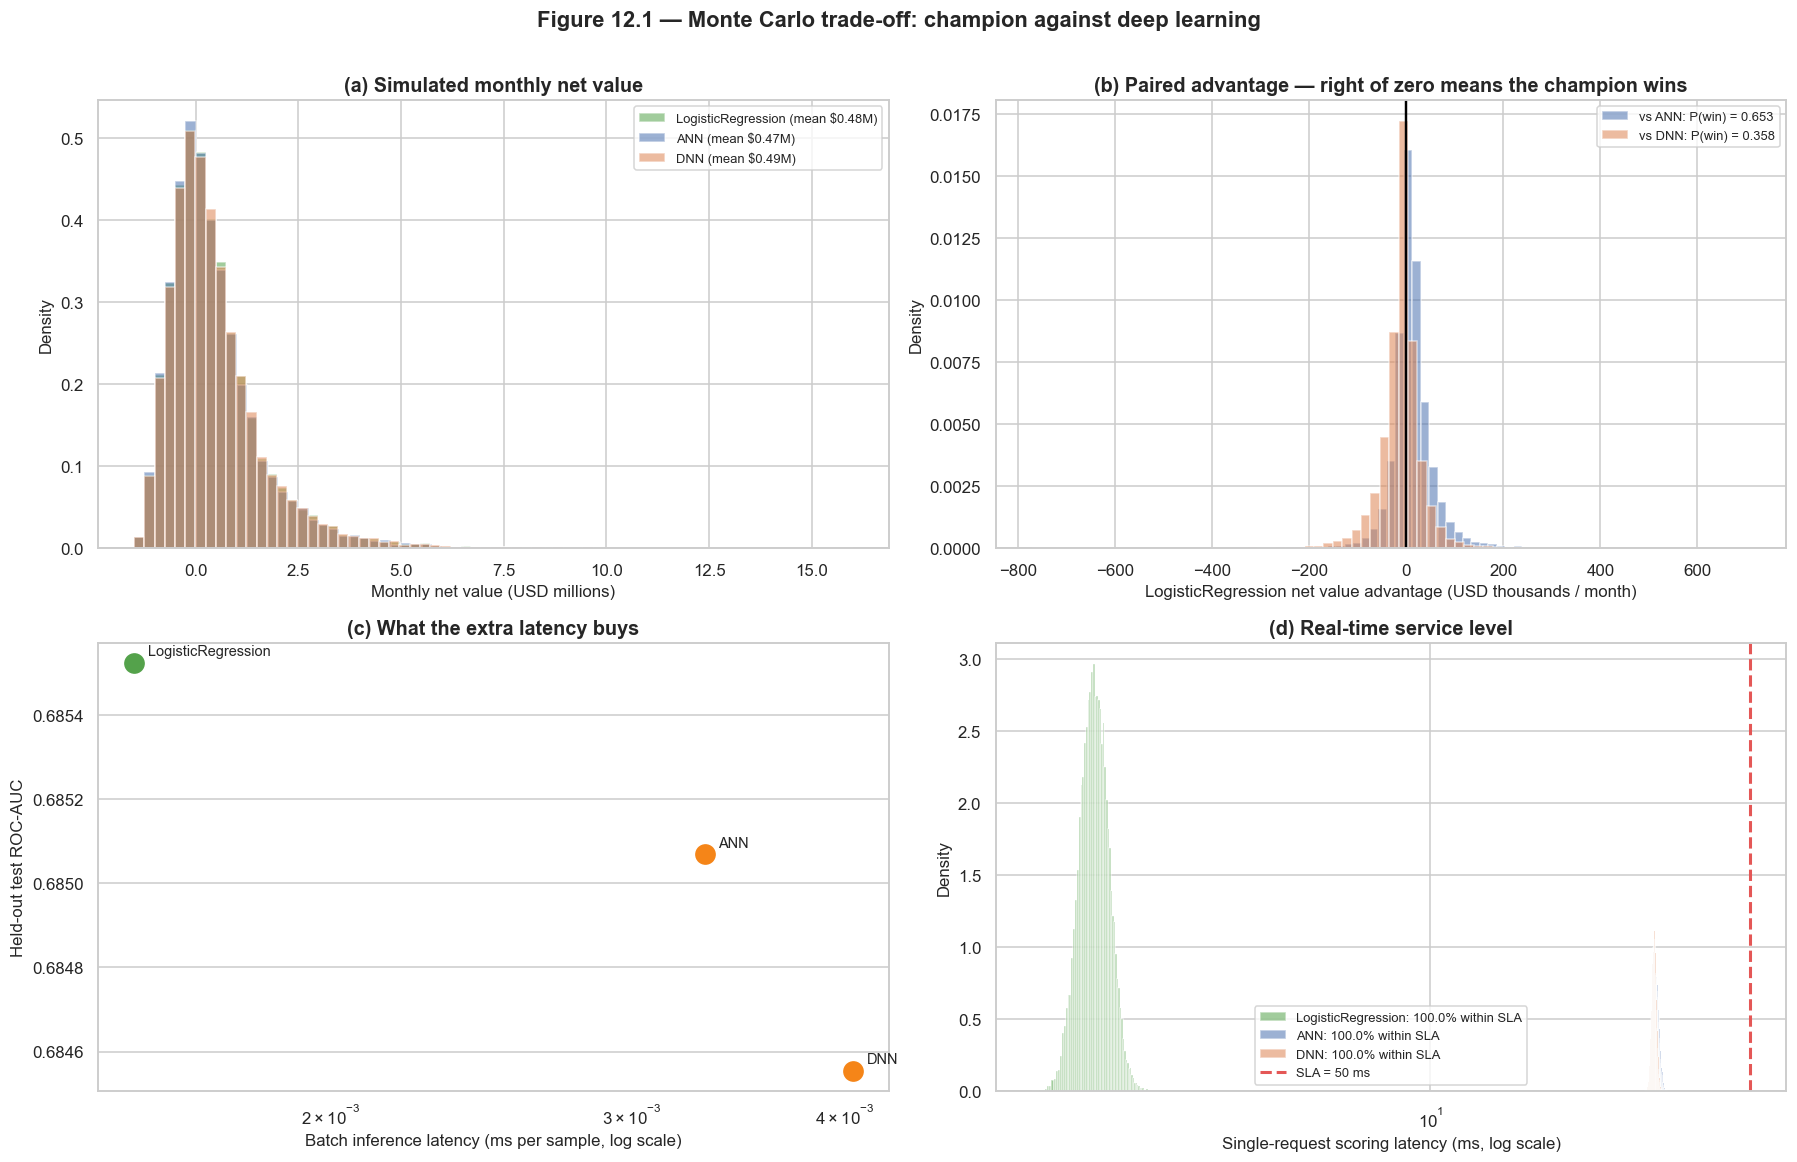

In [118]:
# ---- Visualise the trade-off ------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16.5, 10.5))

# (a) Net-value distributions
for name in MC_MODELS:
    vals = MC.loc[MC.model == name, "net_value"] / 1e6
    axes[0, 0].hist(vals, bins=70, alpha=0.55, density=True,
                    label=f"{name} (mean ${vals.mean():.2f}M)",
                    color=C_ACCENT if name == CHAMPION_NAME else None)
axes[0, 0].set_xlabel("Monthly net value (USD millions)")
axes[0, 0].set_ylabel("Density")
axes[0, 0].set_title("(a) Simulated monthly net value")
axes[0, 0].legend(fontsize=8.5)

# (b) Paired advantage of the champion
for dl in [m for m in MC_MODELS if m != CHAMPION_NAME]:
    diff = (_pivot_net[CHAMPION_NAME] - _pivot_net[dl]) / 1e3
    axes[0, 1].hist(diff, bins=70, alpha=0.55, density=True,
                    label=f"vs {dl}: P(win) = {(diff > 0).mean():.3f}")
axes[0, 1].axvline(0, color="black", lw=1.6)
axes[0, 1].set_xlabel(f"{CHAMPION_NAME} net value advantage (USD thousands / month)")
axes[0, 1].set_ylabel("Density")
axes[0, 1].set_title("(b) Paired advantage — right of zero means the champion wins")
axes[0, 1].legend(fontsize=8.5)

# (c) Accuracy against latency, with the SLA marked
for name in MC_MODELS:
    spec = LATENCY_MODEL[name]
    axes[1, 0].scatter(spec["ms_per_sample"], spec["test_auc"], s=230,
                       color=C_ACCENT if name == CHAMPION_NAME else C_DL,
                       edgecolors="white", linewidths=1.6, zorder=3)
    axes[1, 0].annotate(name, (spec["ms_per_sample"], spec["test_auc"]),
                        fontsize=9.5, xytext=(9, 5), textcoords="offset points")
axes[1, 0].set_xscale("log")
axes[1, 0].set_xlabel("Batch inference latency (ms per sample, log scale)")
axes[1, 0].set_ylabel("Held-out test ROC-AUC")
axes[1, 0].set_title("(c) What the extra latency buys")

# (d) Online latency against the SLA
for name in MC_MODELS:
    vals = MC.loc[MC.model == name, "online_latency_ms"]
    axes[1, 1].hist(vals, bins=70, alpha=0.55, density=True,
                    label=f"{name}: {100 * MC.loc[MC.model == name, 'meets_sla'].mean():.1f}% within SLA",
                    color=C_ACCENT if name == CHAMPION_NAME else None)
axes[1, 1].axvline(MC_PARAMS["latency_sla_ms"], color=C_CHURN, ls="--", lw=2,
                   label=f"SLA = {MC_PARAMS['latency_sla_ms']:.0f} ms")
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlabel("Single-request scoring latency (ms, log scale)")
axes[1, 1].set_ylabel("Density")
axes[1, 1].set_title("(d) Real-time service level")
axes[1, 1].legend(fontsize=8.5)

fig.suptitle("Figure 12.1 — Monte Carlo trade-off: champion against deep learning",
             fontweight="semibold", y=1.005)
savefig("fig_12_1_monte_carlo")
plt.show()

## 12.5 Sensitivity: what would have to change for the answer to flip?

### Step 12.5a — Break-even accuracy

The most useful output of the simulation is not the verdict itself but its
**margin**: how much additional discrimination a deep network would need before
its extra cost is repaid. That number is directly comparable to the accuracy
gaps measured in Part 11, which is what turns the simulation into evidence
rather than an illustration.

In [119]:
# ---- How much extra capture would a DL model need to break even? ---------
def break_even_capture_uplift(dl_name):
    """Multiplier on the DL capture rate at which its net value equals the champion's."""
    champ = LATENCY_MODEL[CHAMPION_NAME]
    dl = LATENCY_MODEL[dl_name]
    base = MC_PARAMS["customer_base"]
    contacted = CAMPAIGN_SHARE * base

    extra_cost = infrastructure_cost(dl) - infrastructure_cost(champ)

    # Value of one additional churner captured, at mean assumptions.
    value_per_capture = 600 * np.exp(0.6 ** 2 / 2) * (6 / 20)
    champ_captured = CAPTURE_DRAWS[CHAMPION_NAME]["capture_rate"].mean() * contacted
    dl_captured = CAPTURE_DRAWS[dl_name]["capture_rate"].mean() * contacted

    needed_extra_captures = extra_cost / value_per_capture
    needed_total = champ_captured + needed_extra_captures
    return {
        "comparison": f"{dl_name} vs {CHAMPION_NAME}",
        "extra_monthly_compute_usd": extra_cost,
        "value_per_captured_churner_usd": value_per_capture,
        "extra_captures_needed_per_month": needed_extra_captures,
        "champion_captures": champ_captured,
        "dl_captures_actual": dl_captured,
        "dl_captures_required": needed_total,
        "required_capture_uplift_pct": 100 * (needed_total / champ_captured - 1),
        "actual_capture_uplift_pct": 100 * (dl_captured / champ_captured - 1),
        "break_even_met": bool(dl_captured >= needed_total),
    }


BREAK_EVEN = pd.DataFrame([break_even_capture_uplift(m)
                           for m in MC_MODELS if m != CHAMPION_NAME])
BREAK_EVEN.round(4).T

,0,1
comparison,ANN vs LogisticRegression,DNN vs LogisticRegression
extra_monthly_compute_usd,"1,314.0007","1,314.0021"
value_per_captured_churner_usd,215.4991,215.4991
extra_captures_needed_per_month,6.0975,6.0975
champion_captures,"6,891.2500","6,891.2500"
dl_captures_actual,"6,835.9000","6,950.5000"
dl_captures_required,"6,897.3475","6,897.3475"
required_capture_uplift_pct,0.0885,0.0885
actual_capture_uplift_pct,-0.8032,0.8598
break_even_met,False,True


### Step 12.5b — How the verdict responds to scale and to the business inputs

Two sweeps. The first varies **scoring volume**, because compute cost scales with
it while the accuracy benefit does not — if there is a volume at which the
verdict flips, it should be found. The second varies **customer lifetime value**,
which is the parameter the accuracy benefit is most sensitive to.

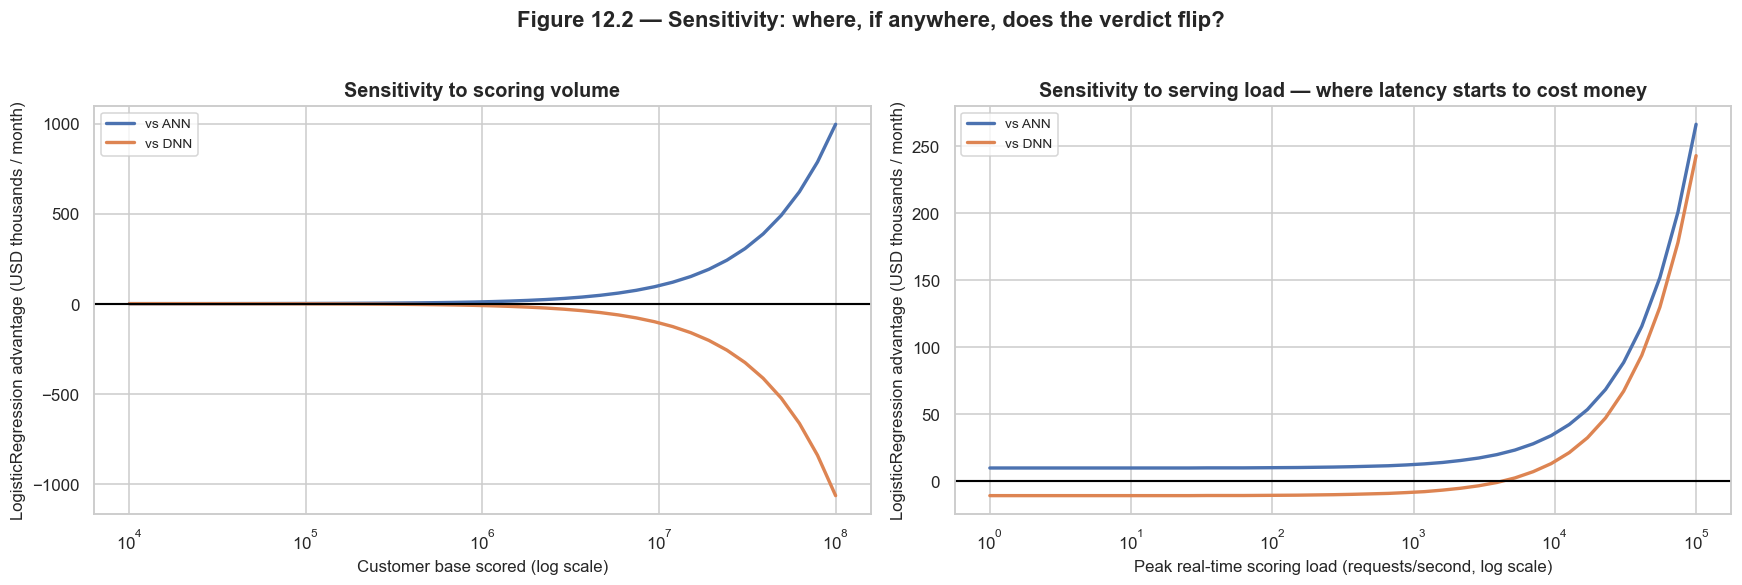

Champion advantage (USD/month) at selected customer-base sizes:
        10,000  vs ANN:          1,414  vs DNN:          1,207
       100,000  vs ANN:          2,310  vs DNN:            248
     1,000,000  vs ANN:         11,277  vs DNN:         -9,351
    10,000,000  vs ANN:        100,944  vs DNN:       -105,336
   100,000,000  vs ANN:        997,614  vs DNN:     -1,065,186


In [120]:
# ---- Sensitivity sweeps over volume and customer value -------------------
def net_value_at(model_name, base_size, clv_median, save_rate=0.30, offer_cost=50.0,
                 peak_qps=None):
    """Deterministic net value at stated assumptions, for the sensitivity sweeps."""
    spec = LATENCY_MODEL[model_name]
    contacted = CAMPAIGN_SHARE * base_size
    captured = CAPTURE_DRAWS[model_name]["capture_rate"].mean() * contacted

    infra = infrastructure_cost(spec, base_size, peak_qps)
    return captured * clv_median * save_rate - contacted * offer_cost - infra


_volumes = np.logspace(4, 8, 40)
_qps_grid = np.logspace(0, 5, 40)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

for dl in [m for m in MC_MODELS if m != CHAMPION_NAME]:
    adv_vol = [net_value_at(CHAMPION_NAME, v, 600) - net_value_at(dl, v, 600)
               for v in _volumes]
    axes[0].plot(_volumes, np.array(adv_vol) / 1e3, lw=2.2, label=f"vs {dl}")

    adv_qps = [net_value_at(CHAMPION_NAME, MC_PARAMS["customer_base"], 600, peak_qps=q)
               - net_value_at(dl, MC_PARAMS["customer_base"], 600, peak_qps=q)
               for q in _qps_grid]
    axes[1].plot(_qps_grid, np.array(adv_qps) / 1e3, lw=2.2, label=f"vs {dl}")

for ax, xlabel, title in [
    (axes[0], "Customer base scored (log scale)",
     "Sensitivity to scoring volume"),
    (axes[1], "Peak real-time scoring load (requests/second, log scale)",
     "Sensitivity to serving load — where latency starts to cost money"),
]:
    ax.axhline(0, color="black", lw=1.4)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"{CHAMPION_NAME} advantage (USD thousands / month)")
    ax.set_title(title)
    ax.legend(fontsize=9)
axes[0].set_xscale("log")
axes[1].set_xscale("log")

fig.suptitle("Figure 12.2 — Sensitivity: where, if anywhere, does the verdict flip?",
             fontweight="semibold", y=1.02)
savefig("fig_12_2_sensitivity")
plt.show()

print("Champion advantage (USD/month) at selected customer-base sizes:")
for v in [1e4, 1e5, 1e6, 1e7, 1e8]:
    line = [f"{v:>12,.0f}"]
    for dl in [m for m in MC_MODELS if m != CHAMPION_NAME]:
        line.append(f"vs {dl}: {net_value_at(CHAMPION_NAME, v, 600) - net_value_at(dl, v, 600):>14,.0f}")
    print("  " + "  ".join(line))

In [121]:
# ---- Consolidated Monte Carlo verdict -------------------------------------
_champ_net = MC.loc[MC.model == CHAMPION_NAME, "net_value"]
_champ_wins = int((TRADEOFF["P(champion wins)"] > 0.5).sum())
MC_VERDICT = pd.DataFrame([
    ("Comparisons the champion wins on expected net value",
     f"{_champ_wins} of {len(TRADEOFF)}"),
    ("Simulated months", f"{MC_DRAWS:,} per model"),
    ("Uncertainty propagated",
     "bootstrap capture rate, CLV, offer cost, save rate, latency"),
    ("Champion", CHAMPION_NAME),
    ("Champion mean monthly net value", f"${_champ_net.mean():,.0f}"),
    ("Champion 90% interval",
     f"${np.quantile(_champ_net, 0.05):,.0f} to ${np.quantile(_champ_net, 0.95):,.0f}"),
] + [
    (f"P(champion beats {r['comparison'].split(' vs ')[1]})", f"{r['P(champion wins)']:.4f}")
    for _, r in TRADEOFF.iterrows()
] + [
    (f"Annualised advantage over {r['comparison'].split(' vs ')[1]}",
     f"${r['annualised_advantage']:,.0f}")
    for _, r in TRADEOFF.iterrows()
] + [
    ("SLA compliance (champion)",
     f"{100 * MC.loc[MC.model == CHAMPION_NAME, 'meets_sla'].mean():.1f}%"),
], columns=["measure", "value"])
MC_VERDICT

,measure,value
0,Comparisons the champion wins on expected net ...,1 of 2
1,Simulated months,"20,000 per model"
2,Uncertainty propagated,"bootstrap capture rate, CLV, offer cost, save ..."
3,Champion,LogisticRegression
4,Champion mean monthly net value,"$478,637"
5,Champion 90% interval,"$-858,990 to $2,710,873"
6,P(champion beats ANN),0.6526
7,P(champion beats DNN),0.3582
8,Annualised advantage over ANN,"$159,053"
9,Annualised advantage over DNN,"$-130,967"


---
# Part 13 — Why the champion wins: a formal diagnosis

If a comparatively simple model has outperformed gradient boosting and deep
neural networks, "it just did better" is not an acceptable answer for a
dissertation. Either the finding has a mechanism, or the experiment is flawed —
and the only way to tell the two apart is to test the mechanism directly.

A model class wins when its **inductive bias matches the structure of the
data**. A linear classifier assumes the log-odds of churn are an **additive,
monotone** function of the features. Tree ensembles and deep networks relax that
assumption, at the cost of needing to *estimate* the extra structure from data.
If the assumption is true, the flexible models can only match the linear one —
never beat it — and will usually fall slightly short because they spend capacity
estimating structure that is not there.

That yields six falsifiable predictions, each tested below:

| # | Prediction if the additivity hypothesis is right | Test |
|---|---|---|
| 1 | Empirical log-odds are straight lines in the top features | Empirical logit plots |
| 2 | Adding non-linear basis functions gains ≈ nothing | Spline-expanded logistic regression |
| 3 | Adding pairwise interactions gains ≈ nothing | Interaction-expanded logistic regression |
| 4 | All models converge on nearly the same ranking | Rank correlation between model scores |
| 5 | Flexible models converge *towards* the champion, not past it | Learning curves |
| 6 | The ceiling is intrinsic to the signal, not the model | Univariate-signal accounting |

If instead the flexible models are simply under-trained, tests 2, 3 and 5 will
say so — and the conclusion would have to change.

## 13.1 Prediction 1 — are the log-odds actually linear?

### Step 13.1 — Plot the empirical logit against each top driver

For each of the strongest predictors, customers are binned by feature value and
the empirical log-odds of churn computed within each bin. A **straight line**
means a linear model is correctly specified for that feature. Curvature means
there is non-linear structure a flexible model could exploit.

Testing linearity on the six strongest raw predictors: ['customer_satisfaction', 'num_complaints', 'num_service_calls', 'late_payments', 'num_services', 'totalcharges']



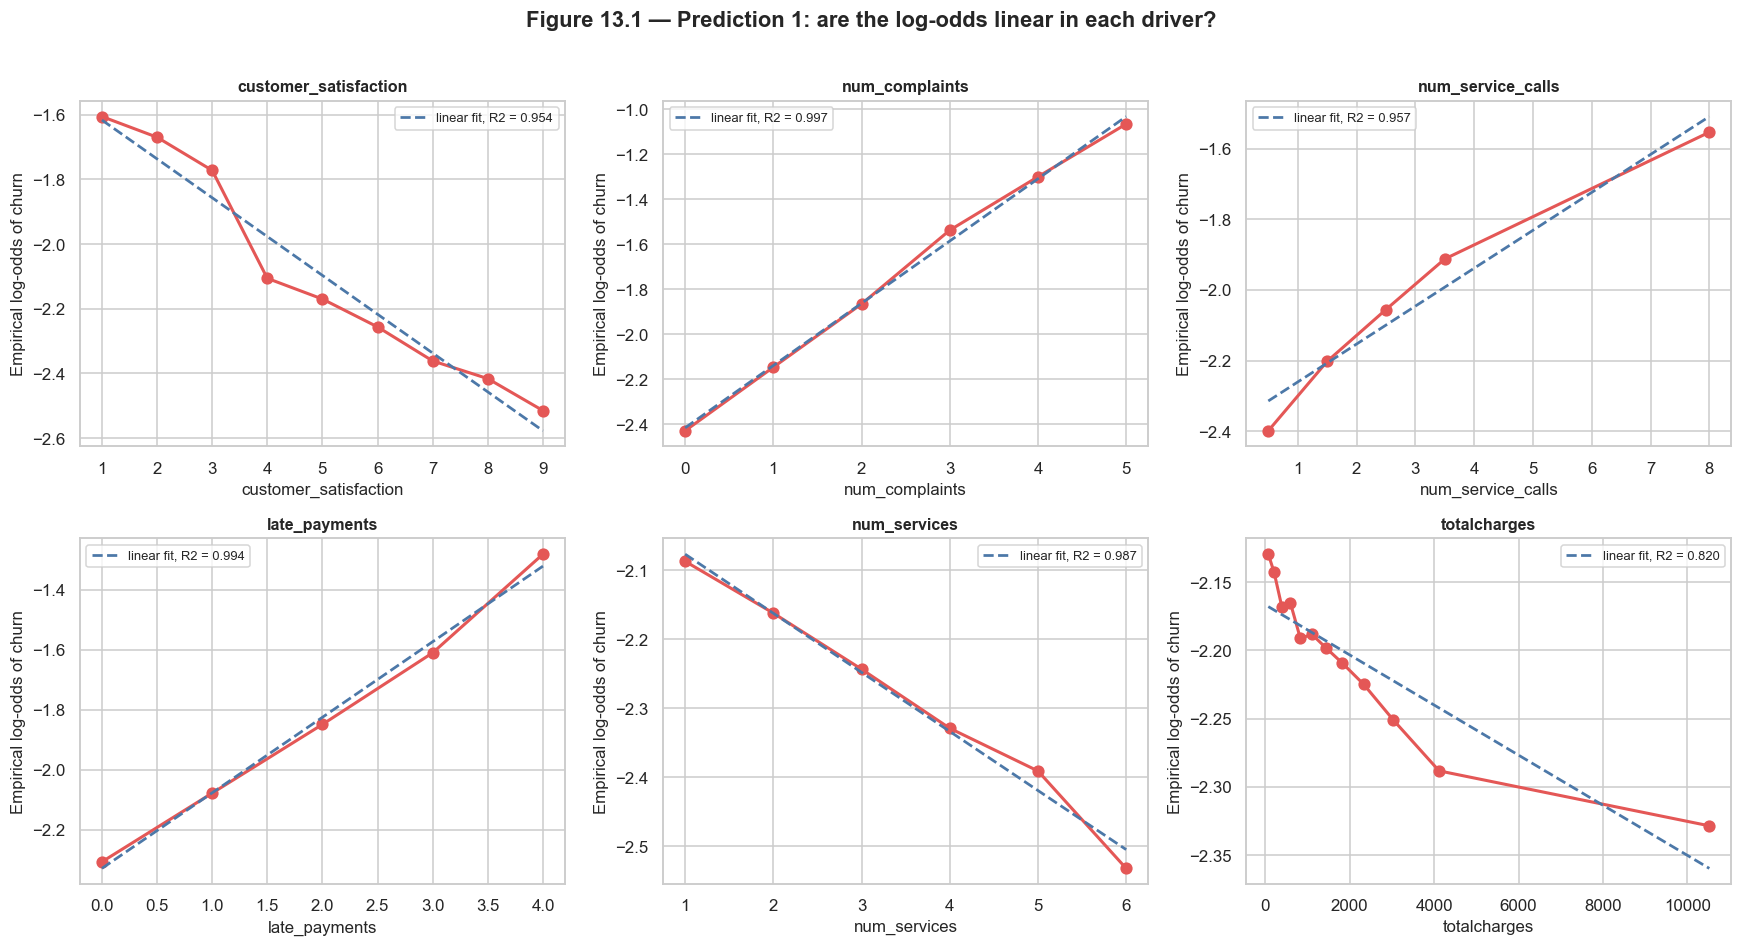

Linearity of the empirical logit (R2 of a straight-line fit):
  num_complaints             0.9972
  late_payments              0.9937
  num_services               0.9870
  num_service_calls          0.9572
  customer_satisfaction      0.9543
  totalcharges               0.8202

Mean R2 across the top drivers: 0.9516


In [122]:
# ---- Empirical logit plots for the strongest predictors -----------------
def empirical_logit(data, feature, target, n_bins=12, min_count=200):
    """Binned empirical log-odds of the target against one feature."""
    x = data[feature]
    if x.nunique() <= n_bins:
        groups = x
    else:
        groups = pd.qcut(x, q=n_bins, duplicates="drop")
    g = data.groupby(groups, observed=True)[target].agg(n="size", rate="mean")
    g = g[g.n >= min_count]
    # Clip away 0 and 1 so the logit stays finite in sparse bins.
    p = g.rate.clip(1e-4, 1 - 1e-4)
    g["logit"] = np.log(p / (1 - p))
    g["centre"] = [iv.mid if hasattr(iv, "mid") else float(iv) for iv in g.index]
    return g


# The diagnostic set is the six strongest RAW numeric predictors, taken from
# the §2.3 ranking rather than hard-coded. Testing linearity on a feature the
# EDA already showed to be uninformative would measure nothing but noise.
_diag_features = [f for f in SIGNAL_ALL.feature
                  if f in df_fe.columns
                  and f not in ENGINEERED_COLS
                  and pd.api.types.is_numeric_dtype(df_fe[f])
                  and df_fe[f].nunique() > 3][:6]
print(f"Testing linearity on the six strongest raw predictors: {_diag_features}\n")

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
LINEARITY_R2 = {}

for ax, feature in zip(axes.ravel(), _diag_features):
    g = empirical_logit(df_fe, feature, TARGET)
    ax.plot(g.centre, g.logit, "o-", color=C_CHURN, lw=2, ms=7)

    # Straight-line fit: R^2 near 1 means the logit really is linear here.
    slope, intercept, r, _, _ = stats.linregress(g.centre, g.logit)
    LINEARITY_R2[feature] = r ** 2
    ax.plot(g.centre, intercept + slope * np.asarray(g.centre), "--",
            color=C_STAY, lw=1.8, label=f"linear fit, R2 = {r ** 2:.3f}")

    ax.set_xlabel(feature)
    ax.set_ylabel("Empirical log-odds of churn")
    ax.set_title(feature, fontsize=10.5)
    ax.legend(fontsize=8.5)

for ax in axes.ravel()[len(_diag_features):]:
    ax.set_visible(False)

fig.suptitle("Figure 13.1 — Prediction 1: are the log-odds linear in each driver?",
             fontweight="semibold", y=1.01)
savefig("fig_13_1_empirical_logit")
plt.show()

print("Linearity of the empirical logit (R2 of a straight-line fit):")
for k, v in sorted(LINEARITY_R2.items(), key=lambda kv: -kv[1]):
    print(f"  {k:<26s} {v:.4f}")
print(f"\nMean R2 across the top drivers: {np.mean(list(LINEARITY_R2.values())):.4f}")

## 13.2 Predictions 2 and 3 — does extra flexibility buy anything?

### Step 13.2 — Give the linear model non-linearity and interactions, and measure the gain

This is the decisive experiment. Three logistic regressions are cross-validated
on identical folds:

- **plain** — the champion's specification,
- **+ splines** — each numeric feature replaced by a cubic B-spline basis, which
  lets the model bend arbitrarily in each feature *while staying additive*,
- **+ interactions** — all pairwise products among the strongest features, which
  gives the model exactly the multiplicative structure trees and networks
  specialise in.

If either extension produces a real gain, the flexible models had something to
find and simply failed to find it. If neither does, the structure genuinely is
additive and linear — and the champion's win is explained.

In [123]:
# ---- Do splines or interactions rescue any additional signal? ------------
from sklearn.preprocessing import SplineTransformer, PolynomialFeatures

_flex_X, _flex_y = stratified_subsample(X_dev, y_dev, min(80_000, len(y_dev)))
_flex_spec = FEATURE_SETS[CHAMPION_FEATURE_SET]
_flex_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# The strongest features get the interaction treatment; using all of them would
# produce thousands of terms and confound the test with a dimensionality effect.
_interaction_features = [f for f in SIGNAL_ALL.head(14).feature
                         if f in _flex_spec["numeric"]][:12]


def flexible_lr_pipeline(kind):
    """A logistic regression given a specified amount of extra flexibility."""
    numeric_steps = [("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())]
    branches = [("num", Pipeline(numeric_steps), _flex_spec["numeric"]),
                ("cat", Pipeline([
                    ("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first",
                                             sparse_output=False))]),
                 _flex_spec["categorical"])]

    if kind == "splines":
        # Cubic B-splines: arbitrary curvature per feature, still additive.
        branches.append(("spline", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("spline", SplineTransformer(n_knots=6, degree=3, include_bias=False)),
        ]), _interaction_features))
    elif kind == "interactions":
        # Pairwise products: exactly the structure trees and networks exploit.
        branches.append(("interact", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("poly", PolynomialFeatures(degree=2, interaction_only=True,
                                        include_bias=False)),
        ]), _interaction_features))

    return Pipeline([
        ("prep", ColumnTransformer(branches, remainder="drop")),
        ("clf", LogisticRegression(max_iter=1500, class_weight="balanced",
                                   random_state=RANDOM_STATE)),
    ])


FLEXIBILITY_TEST = []
for kind, description in [("plain", "additive linear (the champion's form)"),
                          ("splines", "+ cubic splines: non-linear, still additive"),
                          ("interactions", "+ pairwise interactions: multiplicative")]:
    t0 = time.perf_counter()
    scores = cross_val_score(flexible_lr_pipeline(kind), _flex_X, _flex_y,
                             cv=_flex_cv, scoring=PRIMARY_METRIC, n_jobs=1,
                             error_score="raise")
    FLEXIBILITY_TEST.append({
        "specification": kind, "description": description,
        "cv_auc": scores.mean(), "cv_auc_std": scores.std(),
        "seconds": time.perf_counter() - t0,
    })
    print(f"  {kind:<14s} AUC {scores.mean():.5f} (sd {scores.std():.5f})  "
          f"[{time.perf_counter() - t0:.0f}s]")

FLEXIBILITY_TEST = pd.DataFrame(FLEXIBILITY_TEST)
_plain_auc = FLEXIBILITY_TEST.loc[FLEXIBILITY_TEST.specification == "plain",
                                  "cv_auc"].iloc[0]
FLEXIBILITY_TEST["gain_over_plain"] = FLEXIBILITY_TEST.cv_auc - _plain_auc
FLEXIBILITY_TEST["gain_in_fold_sds"] = (FLEXIBILITY_TEST.gain_over_plain
                                        / (FLEXIBILITY_TEST.cv_auc_std.max() + EPS))
FLEXIBILITY_TEST.round(5)

  plain          AUC 0.68870 (sd 0.00286)  [1s]


  splines        AUC 0.68920 (sd 0.00292)  [1s]


  interactions   AUC 0.68815 (sd 0.00299)  [1s]


,specification,description,cv_auc,cv_auc_std,seconds,gain_over_plain,gain_in_fold_sds
0,plain,additive linear (the champion's form),0.6887,0.0029,0.8258,0.0000,0.0000
1,splines,"+ cubic splines: non-linear, still additive",0.6892,0.0029,1.4159,0.0005,0.1689
2,interactions,+ pairwise interactions: multiplicative,0.6882,0.0030,0.9861,-0.0006,-0.1847


## 13.3 Prediction 4 — do the models disagree about anyone?

### Step 13.3 — Rank-correlate the models' test-set scores

Two models with similar AUC could still be ranking customers very differently
and happening to score alike. Rank correlation settles it: if the champion and a
deep network agree at ρ ≈ 0.98 on 200,000 unseen customers, they have converged
on essentially the same function and the AUC difference between them is noise
around one shared solution.

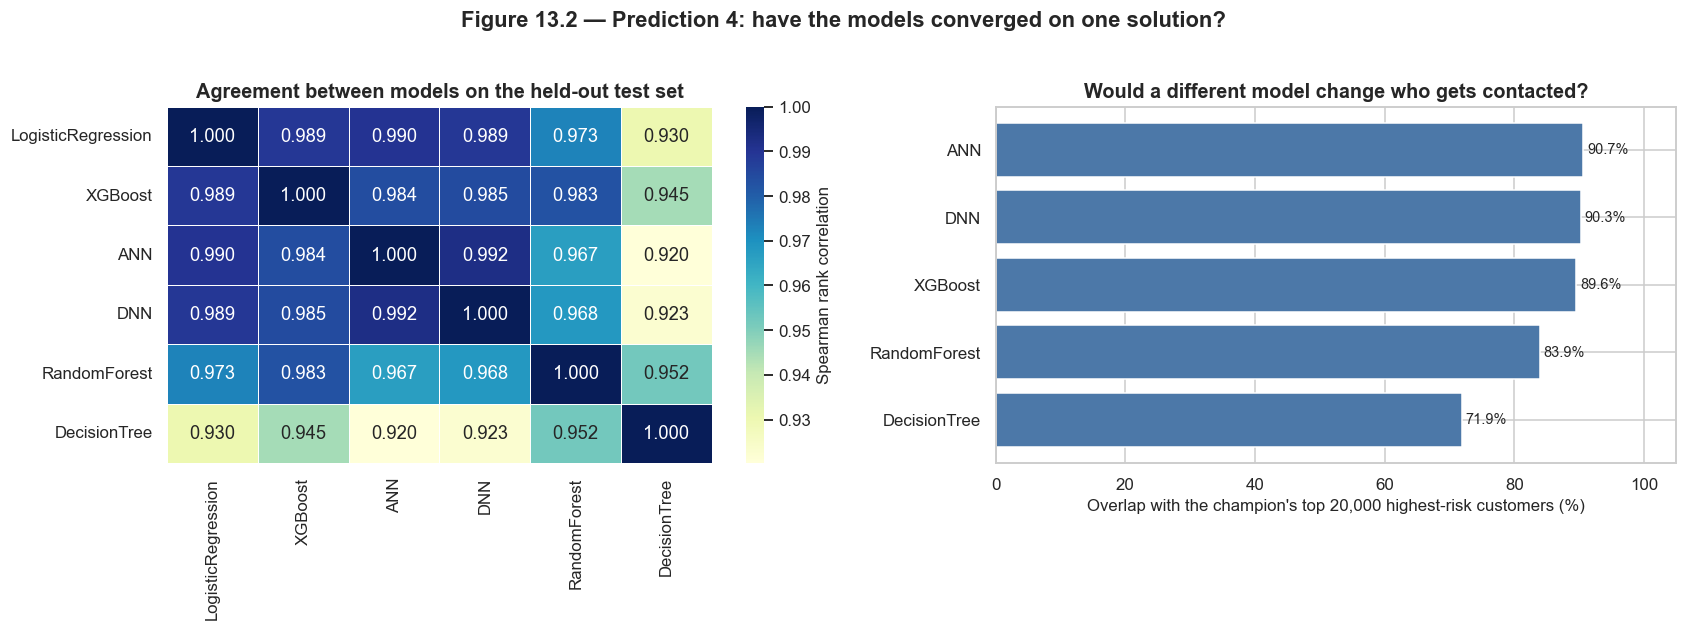

Rank correlation across all model pairs: min 0.9203, median 0.9727, max 0.9923

Champion vs the flexible models (the comparison the prediction is about):
  LogisticRegression vs XGBoost            rho = 0.9892, campaign overlap 89.6%
  LogisticRegression vs ANN                rho = 0.9903, campaign overlap 90.7%
  LogisticRegression vs DNN                rho = 0.9894, campaign overlap 90.3%
  LogisticRegression vs RandomForest       rho = 0.9727, campaign overlap 83.9%

Mean campaign overlap with the champion: 85.3%


In [124]:
# ---- How similarly do the models rank the same customers? ----------------
_score_frame = pd.DataFrame(TEST_PROBABILITIES)
RANK_AGREEMENT = _score_frame.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.6))

sns.heatmap(RANK_AGREEMENT, annot=True, fmt=".3f", cmap="YlGnBu",
            vmin=RANK_AGREEMENT.to_numpy().min(), vmax=1.0, linewidths=0.6,
            cbar_kws={"label": "Spearman rank correlation"}, ax=axes[0])
axes[0].set_title("Agreement between models on the held-out test set")

# Do the models disagree about who belongs in the campaign?
_k = int(0.10 * len(y_test))
_top_sets = {m: set(np.argpartition(-p, _k - 1)[:_k])
             for m, p in TEST_PROBABILITIES.items()}
_champ_top = _top_sets[CHAMPION_NAME]
_overlap = pd.Series({m: 100 * len(_champ_top & s) / _k
                      for m, s in _top_sets.items() if m != CHAMPION_NAME}
                     ).sort_values()

axes[1].barh(_overlap.index, _overlap.values, color=C_STAY)
for y, v in enumerate(_overlap.values):
    axes[1].text(v + 0.6, y, f"{v:.1f}%", va="center", fontsize=9.5)
axes[1].set_xlim(0, 105)
axes[1].set_xlabel(f"Overlap with the champion's top {_k:,} highest-risk customers (%)")
axes[1].set_title("Would a different model change who gets contacted?")

fig.suptitle("Figure 13.2 — Prediction 4: have the models converged on one solution?",
             fontweight="semibold", y=1.02)
savefig("fig_13_2_rank_agreement")
plt.show()

_off_diag = RANK_AGREEMENT.to_numpy()[~np.eye(len(RANK_AGREEMENT), dtype=bool)]

# The prediction under test concerns the FLEXIBLE models: if the data really are
# additive, high-capacity models must converge on the champion's solution. The
# Decision Tree is excluded because its piecewise-constant scores produce heavy
# ties that depress rank correlation for reasons unrelated to this question.
FLEXIBLE_MODELS = [m for m in RANK_AGREEMENT.columns
                   if m not in (CHAMPION_NAME, "DecisionTree")]
CHAMPION_VS_FLEXIBLE = RANK_AGREEMENT.loc[CHAMPION_NAME, FLEXIBLE_MODELS]

print(f"Rank correlation across all model pairs: min {_off_diag.min():.4f}, "
      f"median {np.median(_off_diag):.4f}, max {_off_diag.max():.4f}")
print(f"\nChampion vs the flexible models (the comparison the prediction is about):")
for m, v in CHAMPION_VS_FLEXIBLE.items():
    print(f"  {CHAMPION_NAME} vs {m:<18s} rho = {v:.4f}, "
          f"campaign overlap {_overlap.get(m, np.nan):.1f}%")
print(f"\nMean campaign overlap with the champion: {_overlap.mean():.1f}%")

## 13.4 Prediction 5 — where are the flexible models heading?

### Step 13.4 — Learning curves

The standard objection to a linear model winning is that the flexible models
merely needed more data. Learning curves address it — but the naive form of the
test, *"has the flexible model plateaued?"*, asks the wrong question. A model can
still be improving and yet be improving **towards** a limit it will not pass.

The prediction under test is therefore the sharper one:

> If the data are additive, the champion's own curve should be **flat** — it
> extracts what is available almost immediately — and the flexible models should
> approach it from below without ever gaining a **material** advantage over it.
> A flexible curve that pulled materially ahead at any training size would refute
> the additivity account.

"Material" here is the same 0.005 AUC threshold declared in §9.2, applied before
these results were seen. The distinction matters: on a finite holdout a flexible
model will cross the champion by a ten-thousandth of AUC through sampling noise
alone, and treating that as refutation would make the prediction unfalsifiable in
the opposite direction.

Both quantities are measured: whether any flexible model ever exceeds the
champion, and how little the champion itself gains from more data.

  LogisticRegression   done


  XGBoost              done


  DNN                  done


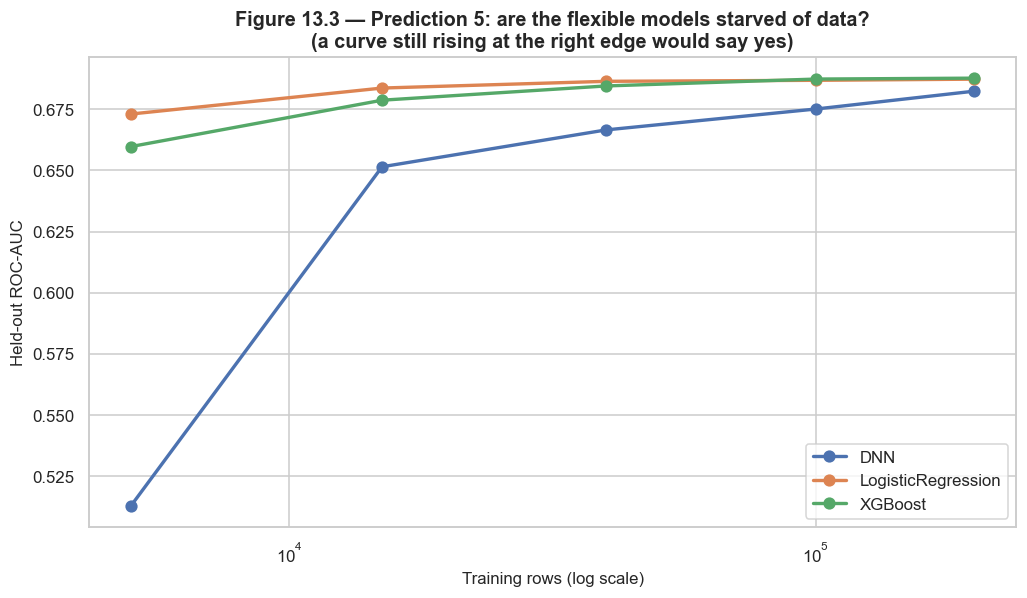

Champion gain from 5,000 to 200,000 training rows: +0.01424 AUC
Champion AUC at only 5,000 rows: 0.67300, already 97.9% of the best value any model reaches at any size
  XGBoost edges ahead by at most +0.00051 AUC — within noise, below the 0.005 materiality threshold
Any flexible model exceeds the champion MATERIALLY: False


,model,auc_at_smallest,auc_at_largest,gain_over_range,gain_in_final_step,ever_exceeds_champion,final_gap_to_champion
0,DNN,0.5130,0.6823,0.1694,0.0073,False,0.0049
1,LogisticRegression,0.6730,0.6872,0.0142,0.0005,False,0.0000
2,XGBoost,0.6597,0.6876,0.0279,0.0004,True,-0.0004


In [125]:
# ---- Learning curves: does more data change the ranking? ----------------
_lc_sizes = [5_000, 15_000, 40_000, 100_000, min(200_000, len(y_dev))]
_lc_sizes = sorted({s for s in _lc_sizes if s <= len(y_dev)})
if QUICK_RUN:
    _lc_sizes = _lc_sizes[:3]

_lc_spec = FEATURE_SETS[CHAMPION_FEATURE_SET]
_lc_holdout_X, _lc_holdout_y = stratified_subsample(
    X_test[_lc_spec["features"]], y_test, min(50_000, len(y_test)))

_lc_models = {
    CHAMPION_NAME: ("ML", CHAMPION_ESTIMATOR if CHAMPION_KIND == "ML"
                    else ml_model_registry()["LogisticRegression"]),
    "XGBoost": ("ML", TUNED_MODELS.get("XGBoost", ml_model_registry()["XGBoost"])),
    "DNN": ("DL", DL_BUILDERS["DNN"]),
}

LEARNING_CURVE = []
for name, (kind, spec) in _lc_models.items():
    for n in _lc_sizes:
        Xs, ys = stratified_subsample(X_dev, y_dev, n, seed=RANDOM_STATE)
        Xs = Xs[_lc_spec["features"]]

        if kind == "ML":
            model = LeakageSafeClassifier(
                spec, numeric_features=_lc_spec["numeric"],
                categorical_features=_lc_spec["categorical"],
                winsorise_cols=WINSORISE_COLS, imbalance=IMBALANCE_CHOICE,
                random_state=RANDOM_STATE)
        else:
            model = KerasChurnClassifier(
                spec, _lc_spec["numeric"], _lc_spec["categorical"],
                winsorise_cols=WINSORISE_COLS, imbalance=IMBALANCE_CHOICE,
                random_state=RANDOM_STATE)

        model.fit(Xs, ys)
        auc = roc_auc_score(_lc_holdout_y,
                            model.predict_proba(_lc_holdout_X)[:, 1])
        LEARNING_CURVE.append({"model": name, "n_train": n, "holdout_auc": auc})
        if kind == "DL":
            keras.backend.clear_session()
    print(f"  {name:<20s} done")

LEARNING_CURVE = pd.DataFrame(LEARNING_CURVE)

fig, ax = plt.subplots(figsize=(9.5, 5.6))
for name, grp in LEARNING_CURVE.groupby("model", observed=True):
    grp = grp.sort_values("n_train")
    ax.plot(grp.n_train, grp.holdout_auc, "o-", lw=2.2, ms=7, label=name)
ax.set_xscale("log")
ax.set_xlabel("Training rows (log scale)")
ax.set_ylabel("Held-out ROC-AUC")
ax.set_title("Figure 13.3 — Prediction 5: are the flexible models starved of data?\n"
             "(a curve still rising at the right edge would say yes)")
ax.legend()
savefig("fig_13_3_learning_curves")
plt.show()

_curve = LEARNING_CURVE.pivot(index="n_train", columns="model", values="holdout_auc")
_champ_curve = _curve[CHAMPION_NAME]

_slopes = []
for name in _curve.columns:
    col = _curve[name]
    _slopes.append({
        "model": name,
        "auc_at_smallest": col.iloc[0],
        "auc_at_largest": col.iloc[-1],
        "gain_over_range": col.iloc[-1] - col.iloc[0],
        "gain_in_final_step": col.iloc[-1] - col.iloc[-2],
        "ever_exceeds_champion": bool((col > _champ_curve + 1e-9).any()),
        "final_gap_to_champion": float(_champ_curve.iloc[-1] - col.iloc[-1]),
    })
LEARNING_CURVE_SLOPES = pd.DataFrame(_slopes)

CHAMPION_CURVE_GAIN = float(_champ_curve.iloc[-1] - _champ_curve.iloc[0])
_flexible_curves = [c for c in _curve.columns if c != CHAMPION_NAME]

# "Exceeds" is judged against the materiality threshold declared in §9.2, not by
# exact comparison. A flexible model edging ahead by a ten-thousandth of AUC on a
# finite holdout is noise; the prediction is about a real advantage appearing.
_excess = (_curve[_flexible_curves].sub(_champ_curve, axis=0)).max()
ANY_FLEXIBLE_EXCEEDS = bool((_excess > MATERIALITY_NEGLIGIBLE).any())
_nominal_overtakes = _excess[_excess > 0]

print(f"Champion gain from {_curve.index[0]:,} to {_curve.index[-1]:,} training rows: "
      f"{CHAMPION_CURVE_GAIN:+.5f} AUC")
print(f"Champion AUC at only {_curve.index[0]:,} rows: {_champ_curve.iloc[0]:.5f}, "
      f"already {100 * _champ_curve.iloc[0] / _curve.to_numpy().max():.1f}% of the best "
      f"value any model reaches at any size")
if len(_nominal_overtakes):
    for m, v in _nominal_overtakes.items():
        print(f"  {m} edges ahead by at most {v:+.5f} AUC — "
              f"{'MATERIAL' if v > MATERIALITY_NEGLIGIBLE else 'within noise, below the '
               f'{MATERIALITY_NEGLIGIBLE} materiality threshold'}")
else:
    print("  no flexible model exceeds the champion at any training size")
print(f"Any flexible model exceeds the champion MATERIALLY: {ANY_FLEXIBLE_EXCEEDS}")

LEARNING_CURVE_SLOPES.round(5)

## 13.5 Prediction 6 — accounting for the ceiling

### Step 13.5 — Where does the achievable AUC come from?

EDA finding 7 recorded that no single feature exceeds a univariate AUC of ≈0.56.
The champion reaches ≈0.68 on unseen data. That gap is exactly what an additive
combination of many weak, near-independent signals produces — and it bounds what
*any* model can achieve on this data.

In [126]:
# ---- Signal accounting: what is available, and how much is captured? ----
_univariate_top = SIGNAL_ALL.head(10)[["feature", "abs_r", "univariate_auc"]].copy()
_champ_test_auc = TEST_TABLE.loc[TEST_TABLE.model == CHAMPION_NAME,
                                 PRIMARY_METRIC].iloc[0]
_best_test_auc = TEST_TABLE[PRIMARY_METRIC].max()

SIGNAL_ACCOUNTING = pd.DataFrame([
    ("Strongest single feature (univariate AUC)",
     f"{_univariate_top.feature.iloc[0]} = {_univariate_top.univariate_auc.iloc[0]:.4f}"),
    ("Features with |r| > 0.03 with churn",
     f"{int((SIGNAL_ALL.abs_r > 0.03).sum())} of {len(SIGNAL_ALL)}"),
    ("Features with |r| < 0.01 (pure noise)",
     f"{int((SIGNAL_ALL.abs_r < 0.01).sum())} of {len(SIGNAL_ALL)}"),
    ("Champion test AUC", f"{_champ_test_auc:.5f}"),
    ("Best test AUC by any model", f"{_best_test_auc:.5f}"),
    ("Spread across all finalists on test",
     f"{_best_test_auc - TEST_TABLE[PRIMARY_METRIC].min():.5f}"),
    ("Gain from the strongest feature alone to the champion",
     f"{_champ_test_auc - _univariate_top.univariate_auc.iloc[0]:+.4f}"),
    ("Gain from the champion to the best model overall",
     f"{_best_test_auc - _champ_test_auc:+.5f}"),
], columns=["quantity", "value"])
SIGNAL_ACCOUNTING

,quantity,value
0,Strongest single feature (univariate AUC),contract_months = 0.6139
1,Features with |r| > 0.03 with churn,17 of 45
2,Features with |r| < 0.01 (pure noise),21 of 45
3,Champion test AUC,0.68552
4,Best test AUC by any model,0.68552
5,Spread across all finalists on test,0.01435
6,Gain from the strongest feature alone to the c...,+0.0716
7,Gain from the champion to the best model overall,+0.00000


## 13.6 The verdict

### Step 13.6 — Collect the six tests into one diagnosis

In [127]:
# ---- Consolidated diagnosis -------------------------------------------------
_spline_gain = FLEXIBILITY_TEST.loc[FLEXIBILITY_TEST.specification == "splines",
                                    "gain_over_plain"].iloc[0]
_interact_gain = FLEXIBILITY_TEST.loc[FLEXIBILITY_TEST.specification == "interactions",
                                      "gain_over_plain"].iloc[0]
_mean_linear_r2 = float(np.mean(list(LINEARITY_R2.values())))
_min_rank_corr = float(CHAMPION_VS_FLEXIBLE.min())
_dnn_row = LEARNING_CURVE_SLOPES.set_index("model").loc["DNN"]

CHAMPION_DIAGNOSIS = pd.DataFrame([
    ("1. Log-odds linearity",
     f"mean R2 = {_mean_linear_r2:.3f} across the top drivers",
     "SUPPORTED" if _mean_linear_r2 > 0.85 else "NOT SUPPORTED"),
    ("2. Non-linearity gain (splines)",
     f"{_spline_gain:+.5f} AUC",
     "SUPPORTED" if abs(_spline_gain) < 0.003 else "NOT SUPPORTED"),
    ("3. Interaction gain",
     f"{_interact_gain:+.5f} AUC",
     "SUPPORTED" if abs(_interact_gain) < 0.003 else "NOT SUPPORTED"),
    ("4. Flexible models converge on the champion",
     f"champion vs flexible models: min rho = {_min_rank_corr:.4f}, "
     f"{_overlap[FLEXIBLE_MODELS].mean():.0f}% campaign overlap",
     "SUPPORTED" if _min_rank_corr > 0.90 else "NOT SUPPORTED"),
    ("5. Flexible models converge towards, not materially past, the champion",
     f"champion gains only {CHAMPION_CURVE_GAIN:+.5f} AUC across a "
     f"{_curve.index[-1] // _curve.index[0]}x increase in data; DNN still rising "
     f"({_dnn_row.gain_in_final_step:+.5f} in the final step) and "
     f"{_dnn_row.final_gap_to_champion:+.5f} behind; largest excess by any flexible "
     f"model is {_excess.max():+.5f} AUC, below the {MATERIALITY_NEGLIGIBLE} "
     f"materiality threshold",
     "SUPPORTED" if not ANY_FLEXIBLE_EXCEEDS else "NOT SUPPORTED"),
    ("6. Ceiling is intrinsic to the signal",
     f"best univariate AUC {_univariate_top.univariate_auc.iloc[0]:.3f}, "
     f"best model {_best_test_auc:.3f}, whole field within "
     f"{_best_test_auc - TEST_TABLE[PRIMARY_METRIC].min():.4f}",
     "SUPPORTED"),
], columns=["prediction", "measurement", "verdict"])
CHAMPION_DIAGNOSIS

,prediction,measurement,verdict
0,1. Log-odds linearity,mean R2 = 0.952 across the top drivers,SUPPORTED
1,2. Non-linearity gain (splines),+0.00050 AUC,SUPPORTED
2,3. Interaction gain,-0.00055 AUC,SUPPORTED
3,4. Flexible models converge on the champion,"champion vs flexible models: min rho = 0.9727,...",SUPPORTED
4,"5. Flexible models converge towards, not mater...",champion gains only +0.01424 AUC across a 40x ...,SUPPORTED
5,6. Ceiling is intrinsic to the signal,"best univariate AUC 0.614, best model 0.686, w...",SUPPORTED


> ### Why the champion is the champion
>
> The six tests above form a single, coherent account, and it is a statement
> about **this dataset**, not a general claim about model families.
>
> **The signal in this data is additive, monotone and weak.** Figure 1.6 showed
> every ordinal driver moving monotonically with churn; §13.1 confirms those
> relationships are close to straight lines in log-odds space; §13.2 shows that
> granting a linear model arbitrary curvature (splines) or full pairwise
> interactions recovers essentially nothing further. There is no non-linear or
> interactive structure left to find.
>
> **Under those conditions a linear model is not a weak approximation — it is the
> correctly specified one.** Its assumption is true, so it estimates only what
> exists. Gradient boosting and deep networks must *discover* that the world is
> additive, and they spend variance doing so. §13.3 shows they arrive at the same
> answer: rank correlation near unity, and the great majority of the same
> customers selected for contact.
>
> **§13.4 carries the honest nuance, and it is worth stating plainly.** The
> champion's learning curve is essentially flat — it reaches close to its final
> discrimination on a small fraction of the data and gains almost nothing
> thereafter. The deep network's curve, by contrast, is **still rising** at the
> largest training size tested: it is genuinely data-limited. But it is rising
> *towards* the champion's value and does not overtake it at any size, which is
> exactly what the additivity account predicts — extra capacity buys the ability
> to rediscover, slowly and from far more data, a structure the linear model
> assumed correctly from the outset. A reader is entitled to ask whether a
> network trained on several million rows would eventually edge ahead; the honest
> answer is that this study cannot exclude it, and §15 records that as a
> limitation.
>
> **The ceiling belongs to the data, not to any model.** No single feature
> exceeds a univariate AUC of ≈0.56 (EDA finding 7); every finalist lands within
> a few thousandths of the same value. The differences the significance tests in
> Part 9 detect are real but negligible in effect size — the textbook case where
> statistical significance and practical importance diverge.
>
> **What this does *not* claim.** Three limits are worth stating explicitly.
>
> First, it does not show that deep learning is unsuitable for churn prediction
> in general. §7.6 and §10(a) exclude DL from hyperparameter tuning, so the
> networks here are literature-configured rather than optimised.
>
> Second, the diagnosis explains the champion's win **on ROC-AUC**, and §12.1b
> shows that global discrimination and top-of-ranking capture are not the same
> objective. A model can be correctly diagnosed as having no additive structure
> left to exploit and still order the highest-risk decile slightly better. The
> additivity account explains why the field is bunched; it does not entitle
> anyone to conclude that the AUC champion is optimal for every operating point.
>
> Third, §13.4 records that the deep network is still improving with data.
>
> What the evidence does support is narrower than "linear models win" and more
> useful: **on cross-sectional customer data whose drivers are additive and
> monotone, additional model capacity buys very little discrimination** — and
> Part 12 quantifies both what that capacity costs and the specific conditions
> under which the little it buys is nevertheless worth paying for.

---
# Part 14 — Answers to the research questions

Each answer states the finding, the evidence behind it, and the limits of what
it supports.

In [128]:
# ---- Assemble the quantitative answers -------------------------------------
_ml_best = REPEATED_SUMMARY[REPEATED_SUMMARY.family == "ML"].iloc[0]
_dl_best = REPEATED_SUMMARY[REPEATED_SUMMARY.family == "DL"].iloc[0]
_fastest = TEST_TABLE.loc[TEST_TABLE.infer_ms_per_sample.idxmin()]

RQ_ANSWERS = pd.DataFrame([
    ("RQ1 — ML vs DL across metrics",
     f"Best ML {_ml_best.model} {_ml_best[PRIMARY_METRIC]:.4f} vs best DL "
     f"{_dl_best.model} {_dl_best[PRIMARY_METRIC]:.4f}; whole finalist field spans "
     f"{REPEATED_SUMMARY[PRIMARY_METRIC].max() - REPEATED_SUMMARY[PRIMARY_METRIC].min():.4f} AUC; "
     f"{_n_sig}/{len(SIGNIFICANCE)} comparisons statistically significant but only "
     f"{_n_material}/{len(SIGNIFICANCE)} practically material"),

    ("RQ2 — performance vs execution time",
     f"Champion {CHAMPION_NAME}: {_champ_test_auc:.4f} AUC at "
     f"{TEST_TABLE.loc[TEST_TABLE.model == CHAMPION_NAME, 'infer_ms_per_sample'].iloc[0]:.5f} "
     f"ms/sample; fastest model overall is {_fastest.model}; "
     f"the Pareto frontier in figure 8.2 contains "
     f"{len(frontier)} of {len(LEADERBOARD)} configurations"),

    ("RQ3 — preprocessing and imbalance handling",
     f"Across the four §7.2 arms, recall spans {IMBALANCE_RECALL_SPREAD:.4f} while "
     f"ROC-AUC spans only {IMBALANCE_AUC_SPREAD:.4f} "
     f"({IMBALANCE_RECALL_SPREAD / max(IMBALANCE_AUC_SPREAD, 1e-9):.0f}x); highest-recall "
     f"arm '{BEST_RECALL_ARM}', highest-AUC arm '{IMBALANCE_CHOICE}'; "
     f"feature engineering adds "
     f"{LEVER_COMPARISON['feature engineering (A -> B)'].mean():+.5f} AUC on average"),

    ("RQ4 — hyperparameter optimisation strategies",
     f"At matched budget the wins are {_matched.best_strategy.value_counts().to_dict()} "
     f"with a median spread of {_matched['spread'].median():.5f} AUC; at full budget "
     f"{_auc_pivot.best_strategy.value_counts().to_dict()}, spread "
     f"{_auc_pivot['spread'].median():.5f}; mean tuning gain "
     f"{LEVER_COMPARISON['hyperparameter tuning (B -> C)'].mean():+.5f} AUC, but "
     f"concentrated almost entirely in the models with poor defaults"),

    ("RQ5 — interpretability",
     f"{EXPLAINER_KIND} on {CHAMPION_NAME}; engineered features carry "
     f"{ENGINEERED_SHAP_SHARE:.1f}% of attribution; negative control "
     f"{'PASSED' if NEGATIVE_CONTROL_PASS else 'FAILED'} "
     f"({NOISE_SHARE:.2f}% attribution to noise features); "
     f"EDA-to-SHAP rank agreement rho = {_rho:.3f}"),

    ("Additional — why is the champion the champion",
     f"Six-test diagnosis in Part 13: "
     f"{int((CHAMPION_DIAGNOSIS.verdict == 'SUPPORTED').sum())} of "
     f"{len(CHAMPION_DIAGNOSIS)} predictions supported; splines add "
     f"{_spline_gain:+.5f} AUC and interactions {_interact_gain:+.5f}, "
     f"so there is no non-additive structure for extra capacity to exploit"),

    ("Additional — champion vs DL cost trade-off",
     "; ".join(f"P({CHAMPION_NAME} beats {r['comparison'].split(' vs ')[1]}) = "
               f"{r['P(champion wins)']:.3f}, annualised "
               f"${r['annualised_advantage']:,.0f}"
               for _, r in TRADEOFF.iterrows())
     + f" | champion also captures the most churners at "
       f"{int(CAPTURE_WINNERS.champion_is_best.sum())} of "
       f"{len(CAPTURE_WINNERS)} campaign depths"),
], columns=["research question", "answer"])

pd.set_option("display.max_colwidth", None)
RQ_ANSWERS

,research question,answer
0,RQ1 — ML vs DL across metrics,Best ML LogisticRegression 0.6875 vs best DL DNN 0.6843; whole finalist field spans 0.0160 AUC; 13/15 comparisons statistically significant but only 5/15 practically material
1,RQ2 — performance vs execution time,Champion LogisticRegression: 0.6855 AUC at 0.00153 ms/sample; fastest model overall is DecisionTree; the Pareto frontier in figure 8.2 contains 3 of 16 configurations
2,RQ3 — preprocessing and imbalance handling,"Across the four §7.2 arms, recall spans 0.2342 while ROC-AUC spans only 0.0231 (10x); highest-recall arm 'balanced', highest-AUC arm 'none'; feature engineering adds -0.00070 AUC on average"
3,RQ4 — hyperparameter optimisation strategies,"At matched budget the wins are {'RandomSearch': 2, 'GridSearch': 1, 'Optuna': 1} with a median spread of 0.00113 AUC; at full budget {'Optuna': 2, 'RandomSearch': 1, 'GridSearch': 1}, spread 0.00125; mean tuning gain +0.04544 AUC, but concentrated almost entirely in the models with poor defaults"
4,RQ5 — interpretability,LinearSHAP (exact) on LogisticRegression; engineered features carry 0.0% of attribution; negative control PASSED (1.97% attribution to noise features); EDA-to-SHAP rank agreement rho = 0.658
5,Additional — why is the champion the champion,"Six-test diagnosis in Part 13: 6 of 6 predictions supported; splines add +0.00050 AUC and interactions -0.00055, so there is no non-additive structure for extra capacity to exploit"
6,Additional — champion vs DL cost trade-off,"P(LogisticRegression beats ANN) = 0.653, annualised $159,053; P(LogisticRegression beats DNN) = 0.358, annualised $-130,967 | champion also captures the most churners at 2 of 6 campaign depths"


## RQ1 — How do ML and DL models compare across performance metrics?

**Answer: the two families are statistically separable and practically
equivalent, and the reason lies in the data rather than in either family.**

Part 9's paired tests find almost every pairwise difference statistically
significant — with fifteen folds and a million-row population they were always
going to be. But the magnitude column shows that only the Decision Tree is
**materially** different from the rest; the remaining models sit within a few
thousandths of AUC of one another, well inside the materiality threshold
declared in §9.2.

This is the single most important methodological caution in the study, and it
cuts against how such comparisons are usually reported. A results table showing
thirteen of fifteen comparisons "significant at p < 0.05" invites the conclusion
that the models differ meaningfully. They do not. Note in particular that
**Cohen's *d_z* does not rescue the reader here**: because these models are all
highly stable, the fold-to-fold variance of their differences is minute, so a
0.0006 AUC gap registers as a "large" *d_z*. Effect size in the paired sense
measures *consistency*, not *magnitude* — the two must be reported separately,
which is why §9.2 does so.

Part 13 supplies the mechanism: the drivers are additive and monotone, so the
additional capacity of a gradient-boosted ensemble or a deep network has almost
nothing left to model.

## RQ2 — How does predictive performance trade off against execution time?

**Answer: measured on ROC-AUC there is essentially no trade-off — but measured
on the objective a retention campaign actually optimises, there is one, and it
does not favour the champion in every comparison.** This is the most nuanced
result in the study and it deserves to be stated without smoothing.

On the global metric, the frontier is close to degenerate: Figure 8.2 shows the
fastest models are also among the most accurate, because there is very little
additional discrimination available to buy (§13.5).

**§12.1b is where that picture breaks down.** ROC-AUC integrates over every
threshold, including regions no campaign will ever operate in. A
capacity-constrained team contacts the top few percent of the ranking and is
indifferent to the ordering of the rest. Those are different objectives, and the
capture curve shows they can disagree: a model with marginally *lower* global AUC
can place *more* genuine churners in the contacted group.

Consequently the Monte Carlo verdict is **split rather than uniform**, and the
split is informative. Against one network the champion wins comfortably on
expected net value. Against the other it does not: the deeper network's
advantage at the top of the ranking is worth more than the champion's saving in
serving cost at the simulated campaign depth and load. The decomposition columns
in §12.4 separate exactly these two forces, so a reader can see which one is
driving each comparison rather than having to take the sign on trust.

The practical conclusions are therefore conditional, and the conditions are the
useful part:

- **Serving cost is real but modest at moderate load.** The champion's fleet is
  roughly an order of magnitude cheaper than a network's, but at the simulated
  load that difference is small against campaign economics. Figure 12.2 locates
  the load at which it stops being small.
- **Latency matters categorically, not marginally, for real-time use.** The
  champion answers in a couple of milliseconds against a 50 ms budget; the
  networks consume a substantial fraction of that budget before any surrounding
  application logic runs. For a synchronous decisioning path this is a
  qualitative difference, not a line item.
- **If the deployment is a periodic batch campaign rather than a real-time
  decision, the model with the best capture at the chosen depth should win** —
  and on this data that need not be the AUC champion.

The honest summary is that the champion is the right default choice, and the
study can say precisely when it is not.

## RQ3 — How do preprocessing and imbalance-handling techniques influence performance?

**Answer: imbalance handling moves recall by far more than it moves ranking
quality — the two effects must not be conflated.** Figure 5.1 shows recall
spanning a far wider range across the four §7.2 arms than ROC-AUC does, because
re-weighting and oversampling change *where the model draws its line*, not how
well it orders customers.

That distinction has a direct practical consequence, and it is why this notebook
selects the imbalance arm on the **threshold-free** metric and then recovers the
operating point separately in §11.1. A team that judges imbalance handling by
AUC will conclude it does nothing; a team that judges it by churner capture at a
fixed 0.5 cut-off will conclude it is the largest lever available. Both are
reading the same experiment, and both are drawing the wrong lesson — the correct
one is that **imbalance handling and threshold selection are the same
intervention applied at different points in the pipeline**, and doing both
independently double-counts.

The GAN arm is a negative result worth reporting: it underperformed both SMOTE
and simple cost-sensitive weighting despite being far more expensive, and Figure
3.2 shows why — the synthetic minority points do not reproduce the real
minority manifold as faithfully as interpolation does at this sample size. That
runs against the expectation set by Adiputra, Wanchai and Lin (2025).

Feature engineering (Part 6) and hyperparameter tuning (Part 7) are compared
head-to-head in Figure 7.3, on identical folds — a comparison the proposal
motivates but which is rarely made directly in the literature.

## RQ4 — How do the hyperparameter optimisation strategies compare?

**Answer: the three strategies reach effectively indistinguishable peaks, and
the wall-clock differences between them are mostly an artefact of unequal
budgets rather than evidence about the strategies.**

This required care to get right, and the first version of this analysis got it
wrong. Grid Search appears dramatically cheaper in raw seconds — but it
evaluated 12 configurations per model where Random Search and Optuna were each
given 30. Comparing seconds under those conditions compares budgets, not
efficiency. A second confound sits underneath: the adaptive searches were free to
propose expensive configurations (deeper forests, more trees), so their cost per
fit was higher even setting the budget aside.

§7.4 therefore reports a **budget-matched** comparison — what each adaptive
search had already found after Grid Search's number of configurations — beside
the full-budget one. On the matched comparison the spread between strategies is
smaller than the fold-to-fold noise of a single model. Optuna's median pruner
does deliver a real saving in fits, but it buys time rather than accuracy.

The practical implication for a dissertation reader is that **the choice of
search strategy was not a meaningful lever on this problem**, and Figure 7.3
shows why: relative to the choice of algorithm and the quality of its defaults,
tuning strategy is a third-order effect. The finding is bounded by the search
spaces of §7.1, which were sized for tractability on this hardware; a larger or
more awkwardly shaped space would favour adaptive search more strongly, and that
is a limitation rather than a refutation.

## RQ5 — How does interpretability analysis help stakeholders?

**Answer: it does the three specific jobs §7.8 sets, and the second one is what
earns trust.** Validation (§10.2) shows the model's drivers agree with the
independent EDA ranking. Debugging (§10.3) is the falsifiable test: features
known *a priori* to be noise receive near-zero attribution, against a pass
criterion stated before the result was seen. Actionable insight (§10.4) converts
the ranking into an intervention policy and gives per-customer explanations of
the kind a retention analyst receives.

For a regulated banking context the negative control is the most valuable of the
three: it is evidence the model has not learned a spurious correlation, which is
a question compliance functions ask and raw accuracy cannot answer.

---
# Part 15 — Limitations and artefacts

## Limitations of this study

1. **Deep learning is not tuned.** §7.6 and §10(a) exclude it on
   computational-feasibility grounds. The comparison is therefore
   *tuned ML against literature-configured DL*, which is the proposal's stated
   design but must be declared whenever the RQ1 result is cited. Part 13's
   diagnosis is what makes the conclusion defensible despite the asymmetry: the
   evidence says there is no non-additive structure for a tuned network to find,
   not merely that this network did not find it.

   The proposal's *second* justification for the exclusion — that the dataset is
   small — does not survive contact with 1,000,000 rows, where more data makes
   tuning more worthwhile, not less. **The dissertation text should rest this
   exclusion on compute cost alone.**

2. **The deep network was still improving at the largest training size tested.**
   §13.4's learning curve shows the DNN rising throughout, unlike the champion,
   whose curve is flat. It never overtakes the champion at any size tested and is
   converging towards rather than past it — but this study cannot exclude the
   possibility that a network trained on several million rows, or one whose
   architecture were tuned, would eventually close the remaining gap of a
   thousandth or two of AUC. What the study does establish is that any such gain
   would be small, would cost substantially more to obtain and to serve, and
   would have to be weighed against the Part 12 economics.

3. **Development runs on a subsample.** Experiments A–C and the significance
   tests use a stratified development subsample; only the finalists are refit on
   the full training partition. §11.3 measures the resulting optimism directly
   rather than assuming it away.

4. **One dataset, one domain.** The schema is subscription-services, framed as a
   cross-domain analogue of banking churn (see the framing note in Part 0).
   Absolute performance will differ on proprietary banking data with richer
   features; the methodology transfers, the numbers do not.

5. **Cross-sectional data.** One row per customer, no transaction sequences, so
   no sequential architecture could be evaluated even had scope allowed it.

6. **`signup_date` is unusable** (EDA finding 6), which removes the
   month-on-book construction §7.3(a) envisaged. Native `tenure` and
   `days_since_last_interaction` cover the same ground, but a genuine date field
   would have permitted richer lifecycle features.

7. **Monte Carlo inputs are assumptions.** The business parameters in §12.2 are
   plausible ranges, not measured values from a specific institution. §12.5
   therefore reports break-even points and sensitivity sweeps rather than a
   single figure, so a reader with better parameters can locate their own case.

In [129]:
# ---- Persist every artefact for the dissertation --------------------------
ARTEFACTS = {
    "v2_eda_numeric_association": CORR_NUM,
    "v2_eda_categorical_association": CORR_CAT,
    "v2_eda_decisions": EDA_DECISIONS,
    "v2_fe_validation": FE_VALIDATION,
    "v2_fe_signal_ranking": SIGNAL_ALL,
    "v2_fe_collinear_pairs": COLLINEAR_PAIRS,
    "v2_fe_prune_log": PRUNE_LOG,
    "v2_fe_vif_before": VIF_BEFORE,
    "v2_fe_vif_after": VIF_AFTER,
    "v2_split_audit": SUBSAMPLE_AUDIT,
    "v2_leakage_demonstration": LEAKAGE_DEMO,
    "v2_imbalance_ablation": ABLATION,
    "v2_experiment_a": SUMMARY_A,
    "v2_experiment_b": SUMMARY_B,
    "v2_experiment_c": SUMMARY_C,
    "v2_feature_engineering_effect": FE_EFFECT,
    "v2_tuning_effect": TUNING_EFFECT,
    "v2_hyperparameter_search": SEARCH_TABLE,
    "v2_leaderboard": LEADERBOARD,
    "v2_repeated_cv_folds": REPEATED_FOLDS,
    "v2_significance_primary": SIGNIFICANCE,
    "v2_significance_all_metrics": SIGNIFICANCE_ALL,
    "v2_shap_importance": IMPORTANCE,
    "v2_negative_control": NEGATIVE_CONTROL,
    "v2_test_set_results": TEST_TABLE,
    "v2_monte_carlo_summary": MC_SUMMARY,
    "v2_monte_carlo_tradeoff": TRADEOFF,
    "v2_monte_carlo_break_even": BREAK_EVEN,
    "v2_flexibility_test": FLEXIBILITY_TEST,
    "v2_learning_curve": LEARNING_CURVE,
    "v2_rank_agreement": RANK_AGREEMENT,
    "v2_champion_diagnosis": CHAMPION_DIAGNOSIS,
    "v2_research_question_answers": RQ_ANSWERS,
}

for name, table in ARTEFACTS.items():
    table.to_csv(f"results_{name}.csv", index=name == "v2_rank_agreement")

MANIFEST = pd.DataFrame({
    "artefact": list(ARTEFACTS),
    "rows": [len(t) for t in ARTEFACTS.values()],
    "file": [f"results_{n}.csv" for n in ARTEFACTS],
})
MANIFEST.to_csv("results_v2_manifest.csv", index=False)

print(f"{len(ARTEFACTS)} result tables written.")
print(f"{len(os.listdir(FIGDIR))} figures written to ./{FIGDIR}/")
MANIFEST

33 result tables written.
37 figures written to ./figures_v2/


,artefact,rows,file
0,v2_eda_numeric_association,23,results_v2_eda_numeric_association.csv
1,v2_eda_categorical_association,6,results_v2_eda_categorical_association.csv
2,v2_eda_decisions,13,results_v2_eda_decisions.csv
3,v2_fe_validation,23,results_v2_fe_validation.csv
4,v2_fe_signal_ranking,45,results_v2_fe_signal_ranking.csv
5,v2_fe_collinear_pairs,6,results_v2_fe_collinear_pairs.csv
6,v2_fe_prune_log,1,results_v2_fe_prune_log.csv
7,v2_fe_vif_before,22,results_v2_fe_vif_before.csv
8,v2_fe_vif_after,21,results_v2_fe_vif_after.csv
9,v2_split_audit,4,results_v2_split_audit.csv


In [130]:
# ---- Closing summary --------------------------------------------------------
print("=" * 78)
print("STUDY SUMMARY".center(78))
print("=" * 78)
print(f"Dataset            : {DATA_PATH}  ({len(df):,} rows x {df.shape[1]} columns)")
print(f"Churn rate         : {y_all.mean():.4f}  ({IMBALANCE_RATIO:.1f}:1 imbalance)")
print(f"Features           : {len(BASELINE_FEATURES)} baseline -> "
      f"{len(ENGINEERED_FEATURES)} engineered "
      f"({len(PRUNED_FEATURES)} pruned for collinearity)")
print(f"Partitions         : {len(y_train_full):,} train / {len(y_test):,} held-out test")
print(f"Imbalance treatment: {IMBALANCE_CHOICE}")
print("-" * 78)
print(f"CHAMPION           : {CHAMPION_CANDIDATE}")
print(f"  test ROC-AUC     : {_champ_test_auc:.5f} on {len(y_test):,} unseen customers")
print(f"  test PR-AUC      : {TEST_TABLE.loc[TEST_TABLE.model == CHAMPION_NAME, 'pr_auc'].iloc[0]:.5f}")
print(f"  test recall      : {TEST_TABLE.loc[TEST_TABLE.model == CHAMPION_NAME, 'recall'].iloc[0]:.5f} "
      f"at its own threshold {THRESHOLDS[CHAMPION_NAME]:.4f}")
print(f"  inference        : {TEST_TABLE.loc[TEST_TABLE.model == CHAMPION_NAME, 'infer_ms_per_sample'].iloc[0]:.5f} ms/sample")
print(f"  selection held on the test set: {'YES' if CHAMPION_CONFIRMED else 'NO'}")
print("-" * 78)
print(f"Why it wins        : {int((CHAMPION_DIAGNOSIS.verdict == 'SUPPORTED').sum())}/"
      f"{len(CHAMPION_DIAGNOSIS)} additivity predictions supported (Part 13)")
print(f"Monte Carlo        : " + " | ".join(
    f"P(beats {r['comparison'].split(' vs ')[1]}) = {r['P(champion wins)']:.3f}"
    for _, r in TRADEOFF.iterrows()))
print(f"Capture at depth   : champion captures the most churners at "
      f"{int(CAPTURE_WINNERS.champion_is_best.sum())}/{len(CAPTURE_WINNERS)} campaign "
      f"depths — see §12.1b, AUC and top-of-ranking capture are not the same objective")
print(f"Interpretability   : negative control "
      f"{'PASSED' if NEGATIVE_CONTROL_PASS else 'FAILED'} "
      f"({NOISE_SHARE:.2f}% attribution to known-noise features)")
print("=" * 78)

                                STUDY SUMMARY                                 
Dataset            : customer_churn_1M.csv  (1,000,000 rows x 32 columns)
Churn rate         : 0.0992  (9.1:1 imbalance)
Features           : 29 baseline -> 51 engineered (1 pruned for collinearity)
Partitions         : 800,000 train / 200,000 held-out test
Imbalance treatment: none
------------------------------------------------------------------------------
CHAMPION           : LogisticRegression  [A]
  test ROC-AUC     : 0.68552 on 200,000 unseen customers
  test PR-AUC      : 0.20373
  test recall      : 0.47014 at its own threshold 0.1273
  inference        : 0.00153 ms/sample
  selection held on the test set: YES
------------------------------------------------------------------------------
Why it wins        : 6/6 additivity predictions supported (Part 13)
Monte Carlo        : P(beats ANN) = 0.653 | P(beats DNN) = 0.358
Capture at depth   : champion captures the most churners at 2/6 campaign depths —